In [2]:
import os
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

print("TensorFlow version:", tf.__version__)

# ============================================================
# REPRODUCIBILITY
# ============================================================

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except:
    pass

print("Random seed:", SEED)

TensorFlow version: 2.17.0
Random seed: 42


In [3]:
import pandas as pd

df = pd.read_csv("nifty50.csv")

df.columns = ["Date", "Close", "High", "Low", "Open", "Volume"]

print(df.columns)

Index(['Date', 'Close', 'High', 'Low', 'Open', 'Volume'], dtype='object')


In [4]:
# ============================================================
# CONFIGURATION
# ============================================================

DATA_PATH = "nifty50_2007_to_now.csv"

TARGETS = ["High", "Low"]

LOOKBACK = 25

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

EPOCHS = 200
BATCH_SIZE = 32

OUTPUT_DIR = "FAAST_LSTM_Results"

GRAPH_DIR = os.path.join(OUTPUT_DIR, "Graphs")
TABLE_DIR = os.path.join(OUTPUT_DIR, "Tables")
MODEL_DIR = os.path.join(OUTPUT_DIR, "Models")

os.makedirs(GRAPH_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

print("Configuration loaded.")
print("Lookback:", LOOKBACK)
print("Train:", TRAIN_RATIO)
print("Validation:", VAL_RATIO)
print("Test:", TEST_RATIO)

Configuration loaded.
Lookback: 25
Train: 0.7
Validation: 0.15
Test: 0.15


In [5]:
# ============================================================
# LOAD DATA
# ============================================================

df = pd.read_csv(DATA_PATH)

print("Original shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

# ------------------------------------------------------------
# Find date column
# ------------------------------------------------------------
df = df.rename(columns={df.columns[0]: "Date"})

possible_date_columns = [
    "Date",
    "date",
    "DATE",
    "Timestamp",
    "timestamp"
]

date_column = None

for col in possible_date_columns:
    if col in df.columns:
        date_column = col
        break

if date_column is None:
    raise ValueError(
        "No date column found. Available columns:\n"
        + str(df.columns.tolist())
    )

print("\nDate column:", date_column)

# ------------------------------------------------------------
# Convert date
# ------------------------------------------------------------

df[date_column] = pd.to_datetime(
    df[date_column],
    errors="coerce"
)

df = df.dropna(subset=[date_column])

# ------------------------------------------------------------
# Sort chronologically
# ------------------------------------------------------------

df = df.sort_values(date_column)

# Remove duplicate dates
df = df.drop_duplicates(
    subset=[date_column],
    keep="first"
)

df = df.reset_index(drop=True)

# ------------------------------------------------------------
# Check targets
# ------------------------------------------------------------

for target in TARGETS:

    if target not in df.columns:
        raise ValueError(
            f"Target '{target}' not found."
        )

    df[target] = pd.to_numeric(
        df[target],
        errors="coerce"
    )

df = df.dropna(subset=TARGETS)

print("\nCleaned shape:", df.shape)

print(
    "\nDate range:",
    df[date_column].min(),
    "to",
    df[date_column].max()
)

print("\nTarget summary:")
print(df[TARGETS].describe())

Original shape: (4462, 6)

Columns:
['Date', 'Close', 'High', 'Low', 'Open', 'Volume']

Date column: Date

Cleaned shape: (4462, 6)

Date range: 2007-09-17 00:00:00 to 2025-11-25 00:00:00

Target summary:
               High           Low
count   4462.000000   4462.000000
mean   10893.081151  10763.262131
std     6270.687838   6228.340926
min     2585.300049   2252.750000
25%     5717.062378   5634.775024
50%     8729.424805   8631.450195
75%    15339.187743  15189.174805
max    26277.349610  26151.400390


In [6]:
# ============================================================
# MARKET REGIMES
# ============================================================

def assign_regime(year):

    if year <= 2011:
        return "DF1"

    elif year <= 2019:
        return "DF2"

    elif year <= 2022:
        return "DF3"

    else:
        return "DF4"


df["Regime"] = df[date_column].dt.year.apply(assign_regime)

print("\nRegime distribution:")
print(df["Regime"].value_counts().sort_index())

print("\nRegime date ranges:")

for regime in ["DF1", "DF2", "DF3", "DF4"]:

    temp = df[df["Regime"] == regime]

    if len(temp) > 0:

        print(
            regime,
            ":",
            temp[date_column].min().date(),
            "→",
            temp[date_column].max().date(),
            "| n =",
            len(temp)
        )


Regime distribution:
Regime
DF1    1050
DF2    1951
DF3     746
DF4     715
Name: count, dtype: int64

Regime date ranges:
DF1 : 2007-09-17 → 2011-12-30 | n = 1050
DF2 : 2012-01-03 → 2019-12-31 | n = 1951
DF3 : 2020-01-01 → 2022-12-30 | n = 746
DF4 : 2023-01-02 → 2025-11-25 | n = 715


In [7]:
# ============================================================
# CHRONOLOGICAL SPLIT
# ============================================================

def chronological_split(data):

    n = len(data)

    train_end = int(n * TRAIN_RATIO)

    val_end = int(
        n * (TRAIN_RATIO + VAL_RATIO)
    )

    train = data.iloc[:train_end].copy()

    val = data.iloc[
        train_end:val_end
    ].copy()

    test = data.iloc[
        val_end:
    ].copy()

    return train, val, test


train_df, val_df, test_df = chronological_split(df)

print("TRAIN")
print(
    len(train_df),
    train_df[date_column].min(),
    "→",
    train_df[date_column].max()
)

print("\nVALIDATION")
print(
    len(val_df),
    val_df[date_column].min(),
    "→",
    val_df[date_column].max()
)

print("\nTEST")
print(
    len(test_df),
    test_df[date_column].min(),
    "→",
    test_df[date_column].max()
)

TRAIN
3123 2007-09-17 00:00:00 → 2020-06-30 00:00:00

VALIDATION
669 2020-07-01 00:00:00 → 2023-03-06 00:00:00

TEST
670 2023-03-08 00:00:00 → 2025-11-25 00:00:00


In [8]:
# ============================================================
# SEQUENCE CREATION
# ============================================================

FEATURE_COLUMNS = [
    "Open",
    "High",
    "Low",
    "Close"
]

for col in FEATURE_COLUMNS:

    if col not in df.columns:
        raise ValueError(
            f"Required feature '{col}' not found."
        )

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

df = df.dropna(
    subset=FEATURE_COLUMNS
).reset_index(drop=True)

# Recreate split after final cleaning
train_df, val_df, test_df = chronological_split(df)


def create_sequences(X, y, lookback):

    X_seq = []
    y_seq = []

    for i in range(lookback, len(X)):

        X_seq.append(
            X[i-lookback:i]
        )

        y_seq.append(
            y[i]
        )

    return np.array(X_seq), np.array(y_seq)


print("Sequence function ready.")

Sequence function ready.


In [9]:
# ============================================================
# LSTM MODEL
# ============================================================

def build_lstm(
    input_shape,
    output_dim=1
):

    model = Sequential([

        LSTM(
            64,
            return_sequences=True,
            input_shape=input_shape
        ),

        Dropout(0.20),

        LSTM(
            32,
            return_sequences=False
        ),

        Dropout(0.20),

        Dense(16, activation="relu"),

        Dense(output_dim)
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="mse"
    )

    return model

In [11]:
# ============================================================
# METRICS
# ============================================================

def calculate_metrics(
    y_true,
    y_pred
):

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    # Avoid division by zero
    denominator = np.where(
        np.abs(y_true) < 1e-8,
        np.nan,
        np.abs(y_true)
    )

    mape = np.nanmean(
        np.abs(
            (y_true - y_pred)
            / denominator
        )
    ) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "MAPE": mape
    }

In [12]:
# ============================================================
# LSTM — HIGH
# ============================================================

def run_lstm_target(
    target
):

    print("\n" + "=" * 70)
    print(f"LSTM MODEL — TARGET: {target}")
    print("=" * 70)

    # --------------------------------------------------------
    # Extract target
    # --------------------------------------------------------

    train_target = train_df[target].values.reshape(-1, 1)
    val_target = val_df[target].values.reshape(-1, 1)
    test_target = test_df[target].values.reshape(-1, 1)

    # --------------------------------------------------------
    # Input features
    # --------------------------------------------------------

    train_X = train_df[FEATURE_COLUMNS].values
    val_X = val_df[FEATURE_COLUMNS].values
    test_X = test_df[FEATURE_COLUMNS].values

    # --------------------------------------------------------
    # Scale X — FIT TRAIN ONLY
    # --------------------------------------------------------

    scaler_X = MinMaxScaler()

    train_X_scaled = scaler_X.fit_transform(
        train_X
    )

    val_X_scaled = scaler_X.transform(
        val_X
    )

    test_X_scaled = scaler_X.transform(
        test_X
    )

    # --------------------------------------------------------
    # Scale y — FIT TRAIN ONLY
    # --------------------------------------------------------

    scaler_y = MinMaxScaler()

    train_y_scaled = scaler_y.fit_transform(
        train_target
    )

    val_y_scaled = scaler_y.transform(
        val_target
    )

    test_y_scaled = scaler_y.transform(
        test_target
    )

    # --------------------------------------------------------
    # Create sequences
    # --------------------------------------------------------

    X_train, y_train = create_sequences(
        train_X_scaled,
        train_y_scaled,
        LOOKBACK
    )

    X_val, y_val = create_sequences(
        val_X_scaled,
        val_y_scaled,
        LOOKBACK
    )

    X_test, y_test = create_sequences(
        test_X_scaled,
        test_y_scaled,
        LOOKBACK
    )

    print("\nSequence shapes:")
    print("X_train:", X_train.shape)
    print("y_train:", y_train.shape)

    print("X_val:", X_val.shape)
    print("y_val:", y_val.shape)

    print("X_test:", X_test.shape)
    print("y_test:", y_test.shape)

    # --------------------------------------------------------
    # Build model
    # --------------------------------------------------------

    model = build_lstm(
        input_shape=(
            X_train.shape[1],
            X_train.shape[2]
        )
    )

    print("\nModel architecture:")
    model.summary()

    # --------------------------------------------------------
    # Callbacks
    # --------------------------------------------------------

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=20,
        restore_best_weights=True,
        verbose=1
    )

    reduce_lr = ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=8,
        min_lr=1e-6,
        verbose=1
    )

    # --------------------------------------------------------
    # Train
    # --------------------------------------------------------

    history = model.fit(

        X_train,
        y_train,

        validation_data=(
            X_val,
            y_val
        ),

        epochs=EPOCHS,

        batch_size=BATCH_SIZE,

        callbacks=[
            early_stopping,
            reduce_lr
        ],

        shuffle=False,

        verbose=1
    )

    # --------------------------------------------------------
    # FINAL TEST PREDICTION
    # --------------------------------------------------------

    y_pred_scaled = model.predict(
        X_test,
        verbose=0
    )

    # Inverse transform
    y_pred = scaler_y.inverse_transform(
        y_pred_scaled
    ).flatten()

    y_true = scaler_y.inverse_transform(
        y_test
    ).flatten()

    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    metrics = calculate_metrics(
        y_true,
        y_pred
    )

    print("\nTEST RESULTS")
    print("-" * 40)

    for key, value in metrics.items():

        print(
            f"{key}: {value:.6f}"
        )

    # --------------------------------------------------------
    # Test dates
    # --------------------------------------------------------

    test_dates = test_df[
        date_column
    ].iloc[LOOKBACK:].values

    prediction_df = pd.DataFrame({

        "Date": test_dates,

        "Actual": y_true,

        "Predicted": y_pred

    })

    # --------------------------------------------------------
    # Save model
    # --------------------------------------------------------

    model_path = os.path.join(
        MODEL_DIR,
        f"LSTM_{target}.keras"
    )

    model.save(model_path)

    print(
        "\nModel saved:",
        model_path
    )

    return (
        model,
        history,
        metrics,
        prediction_df
    )

In [13]:
# ============================================================
# RUN LSTM
# ============================================================

lstm_results = {}

for target in TARGETS:

    result = run_lstm_target(
        target
    )

    lstm_results[target] = result


LSTM MODEL — TARGET: High

Sequence shapes:
X_train: (3098, 25, 4)
y_train: (3098, 1)
X_val: (644, 25, 4)
y_val: (644, 1)
X_test: (645, 25, 4)
y_test: (645, 1)

Model architecture:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 25, 64)         │        17,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,625 (119.63 KB)

 Trainable params: 30,625 (119.63 KB)

 Non-trainable params: 0 (0.00 B)

... (3 outputs left out)

 Total params: 30,625 (119.63 KB)

 Trainable params: 30,625 (119.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
97/97 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - loss: 0.0085 - val_loss: 0.2540 - learning_rate: 0.0010
Epoch 2/200
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0047 - val_loss: 0.2804 - learning_rate: 0.0010
Epoch 3/200
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0094 - val_loss: 0.1807 - learning_rate: 0.0010
Epoch 4/200
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0124 - val_loss: 0.1785 - learning_rate: 0.0010
Epoch 5/200
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0143 - val_loss: 0.2164 - learning_rate: 0.0010
Epoch 6/200
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0153 - val_loss: 0.2560 - learning_rate: 0.0010
Epoch 7/200
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0131 - val_loss: 0.2412 - learning_rate: 0.0010
Epoch 8/200
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0100 - val_loss: 0.2066 - learning_rate: 0.0010
Epoch 9/200
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0091 - val_loss: 0.1958 - learning_rate: 0.0010
Epoch 10/2

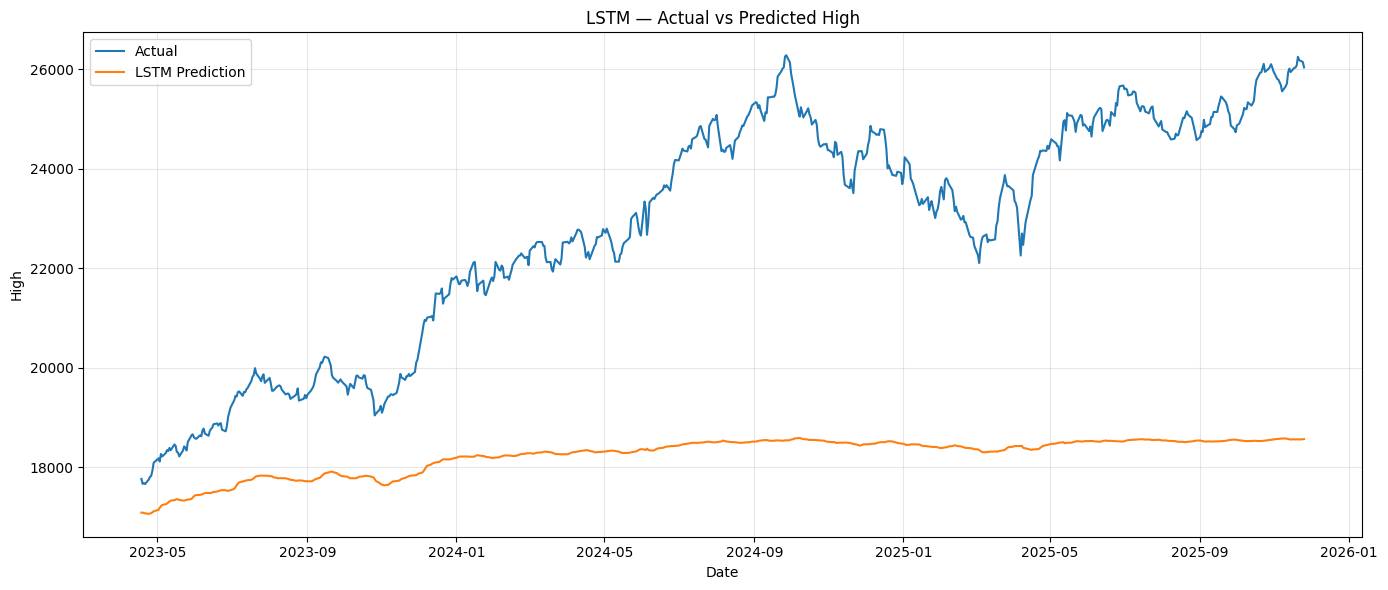

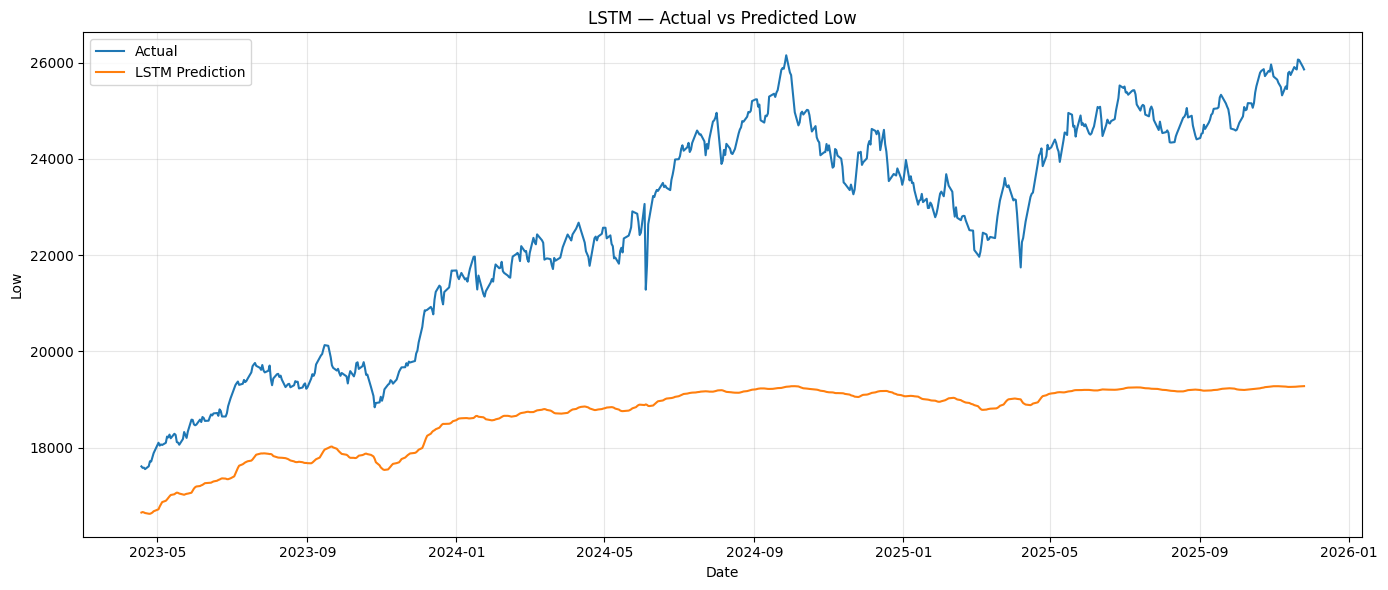

In [14]:
# ============================================================
# ACTUAL VS PREDICTED
# ============================================================

for target in TARGETS:

    _, _, metrics, prediction_df = (
        lstm_results[target]
    )

    plt.figure(figsize=(14, 6))

    plt.plot(
        prediction_df["Date"],
        prediction_df["Actual"],
        label="Actual"
    )

    plt.plot(
        prediction_df["Date"],
        prediction_df["Predicted"],
        label="LSTM Prediction"
    )

    plt.xlabel("Date")
    plt.ylabel(target)

    plt.title(
        f"LSTM — Actual vs Predicted {target}"
    )

    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()

    path = os.path.join(
        GRAPH_DIR,
        f"LSTM_{target}_Actual_vs_Predicted.png"
    )

    plt.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

TensorFlow: 2.17.0
Seed: 42
Original shape: (4462, 6)


RUNNING DF1
2007 - 2010
Regime observations: 808
Train: 564
Validation: 121
Test: 122
X_train: (539, 25, 4)
X_val: (121, 25, 4)
X_test: (122, 25, 4)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                   │ (None, 25, 64)         │        17,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,642 (119.70 KB)

 Trainable params: 30,642 (119.70 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 54ms/step - loss: 0.1166 - val_loss: 0.0488 - learning_rate: 0.0010
Epoch 2/200
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0507 - val_loss: 0.0056 - learning_rate: 0.0010
Epoch 3/200
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0222 - val_loss: 0.0107 - learning_rate: 0.0010
Epoch 4/200
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0219 - val_loss: 0.0029 - learning_rate: 0.0010
Epoch 5/200
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 0.0147 - val_loss: 0.0038 - learning_rate: 0.0010
Epoch 6/200
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0164 - val_loss: 0.0026 - learning_rate: 0.0010
Epoch 7/200
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0138 - val_loss: 0.0024 - learning_rate: 0.0010
Epoch 8/200
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0130 - val_loss: 0.0026 - learning_rate: 0.0010
Epoch 9/200
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0134 - val_loss: 0.0034 - learning_rate: 0.0010
Epoch 10/2

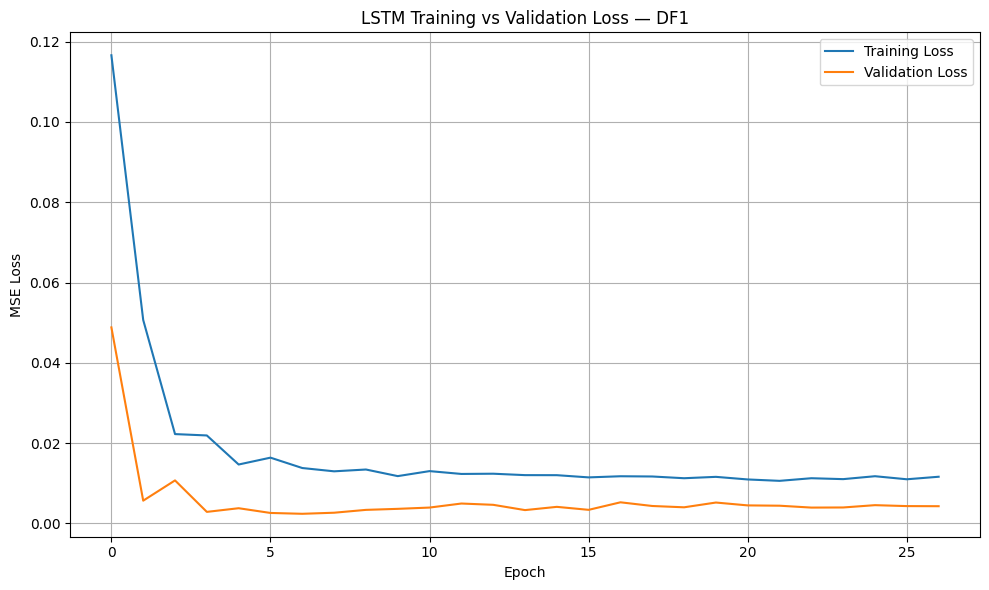

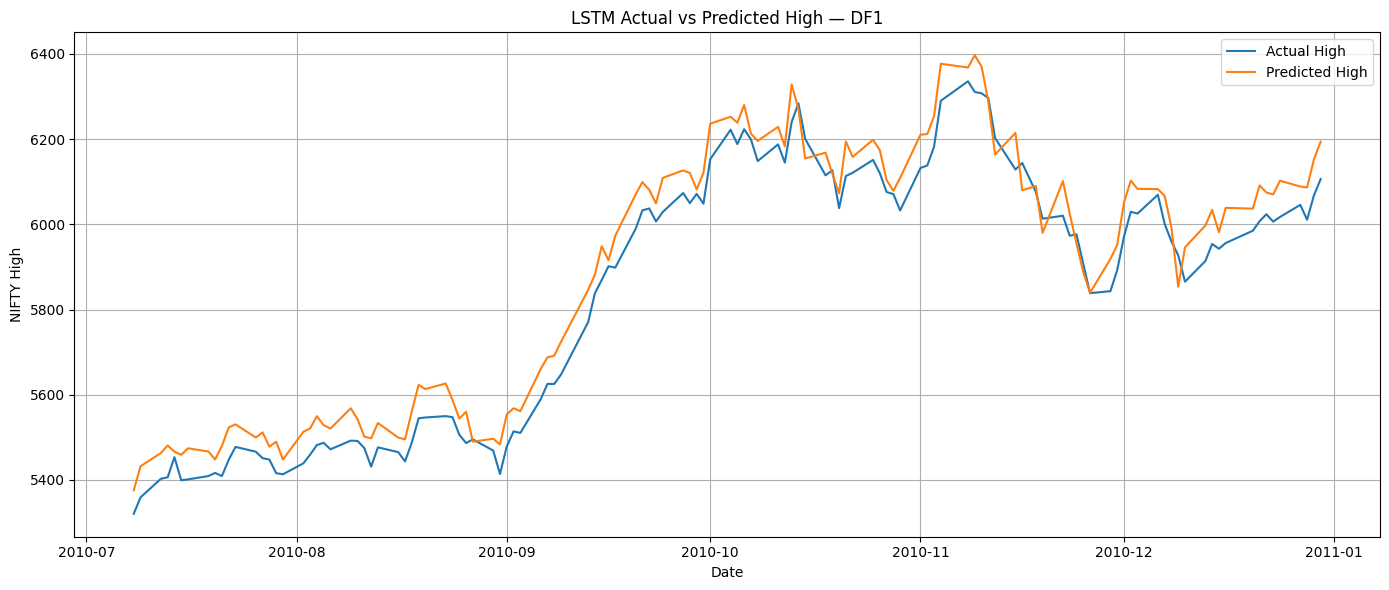

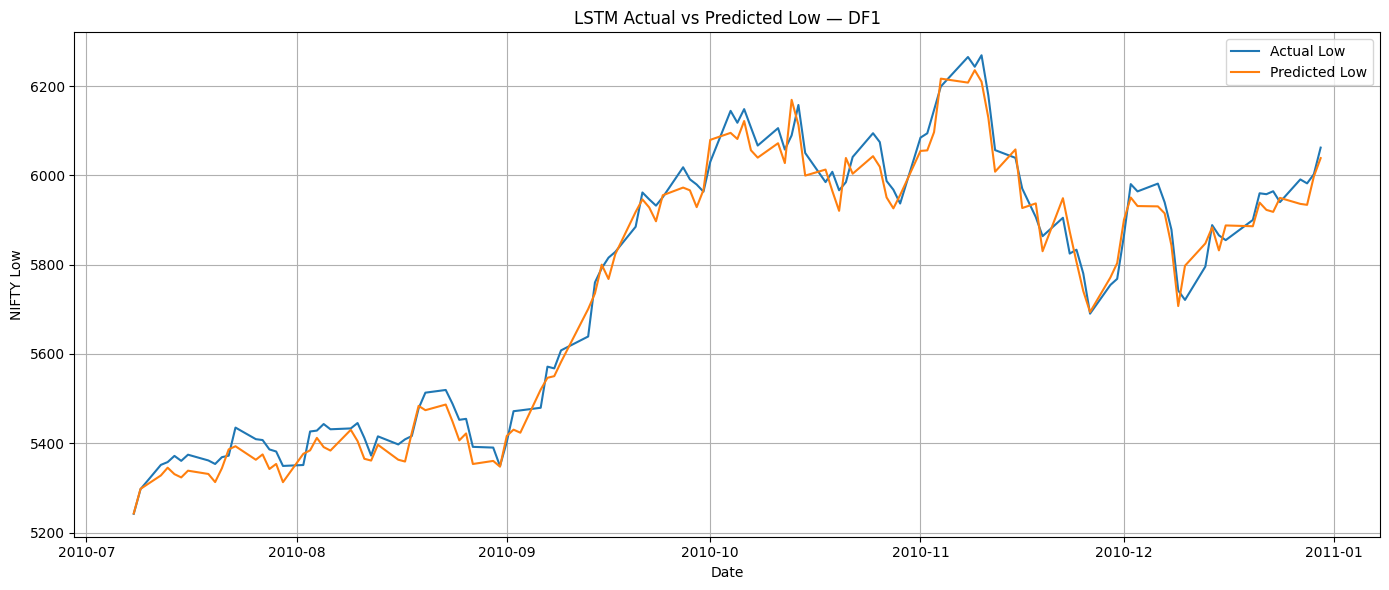

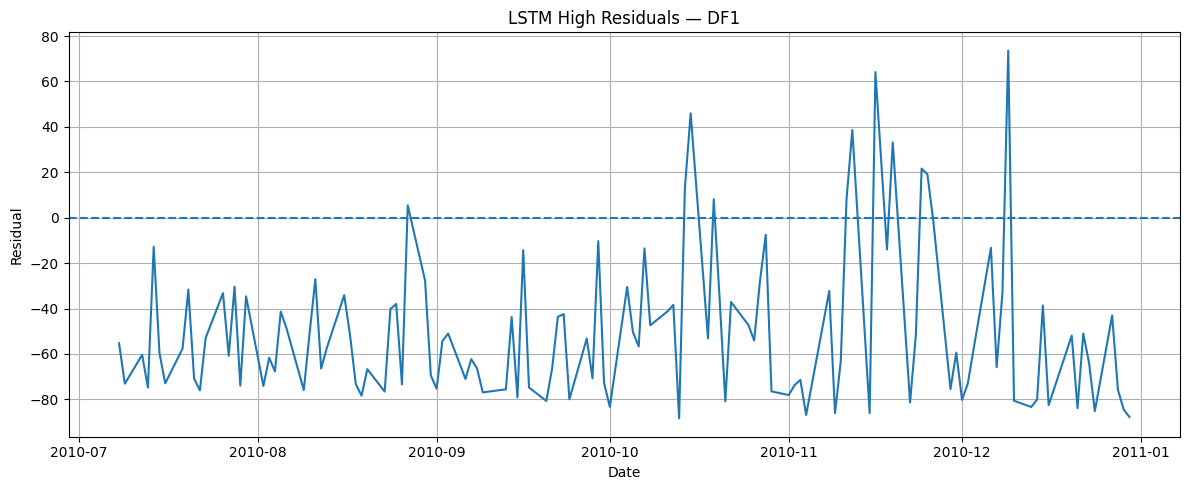

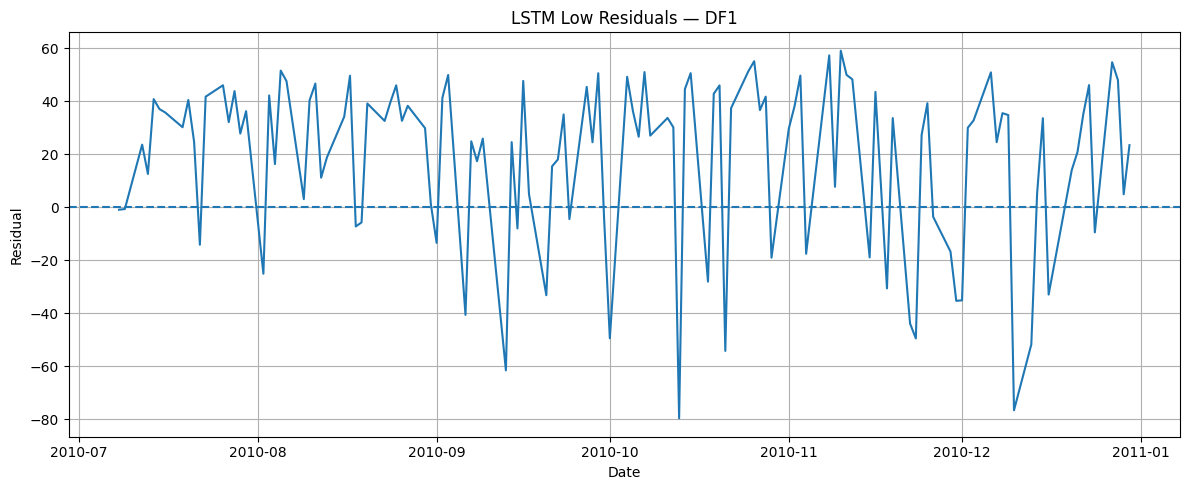

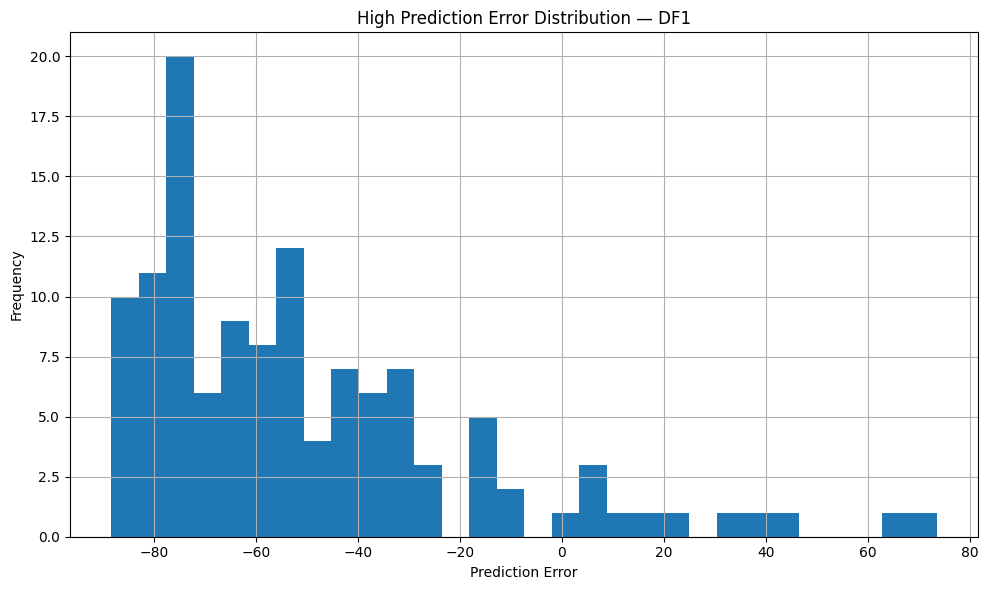

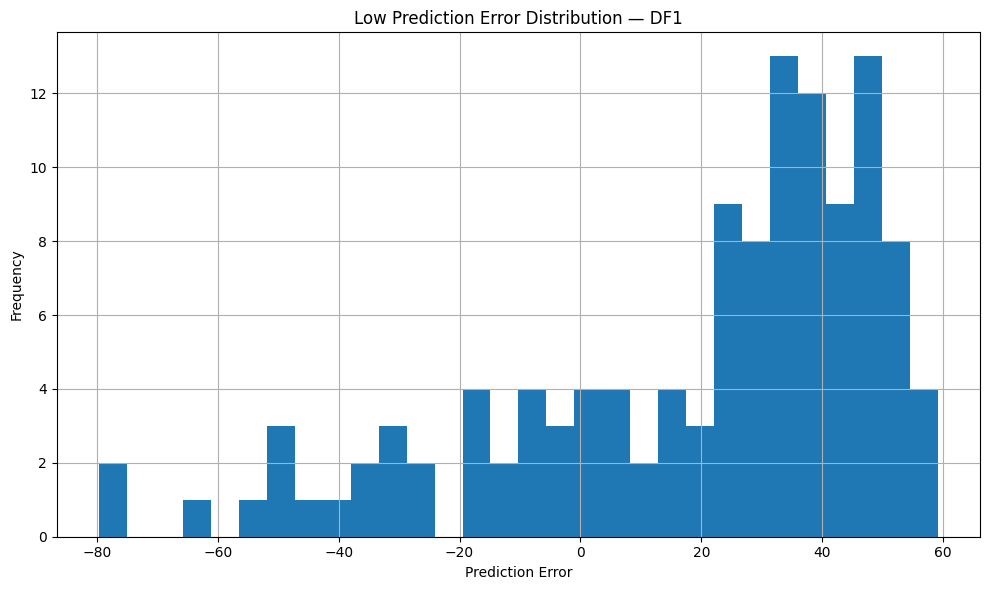


DF1 completed.


RUNNING DF2
2011 - 2019
Regime observations: 2193
Train: 1534
Validation: 329
Test: 329
X_train: (1509, 25, 4)
X_val: (329, 25, 4)
X_test: (329, 25, 4)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_6 (LSTM)                   │ (None, 25, 64)         │        17,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_7 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,642 (119.70 KB)

 Trainable params: 30,642 (119.70 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
48/48 ━━━━━━━━━━━━━━━━━━━━ 6s 31ms/step - loss: 0.1230 - val_loss: 0.0035 - learning_rate: 0.0010
Epoch 2/200
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0248 - val_loss: 0.0023 - learning_rate: 0.0010
Epoch 3/200
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0154 - val_loss: 0.0021 - learning_rate: 0.0010
Epoch 4/200
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0130 - val_loss: 0.0019 - learning_rate: 0.0010
Epoch 5/200
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0109 - val_loss: 0.0019 - learning_rate: 0.0010
Epoch 6/200
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0105 - val_loss: 0.0019 - learning_rate: 0.0010
Epoch 7/200
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0100 - val_loss: 0.0020 - learning_rate: 0.0010
Epoch 8/200
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0095 - val_loss: 0.0021 - learning_rate: 0.0010
Epoch 9/200
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0088 - val_loss: 0.0021 - learning_rate: 0.0010
Epoch 10/2

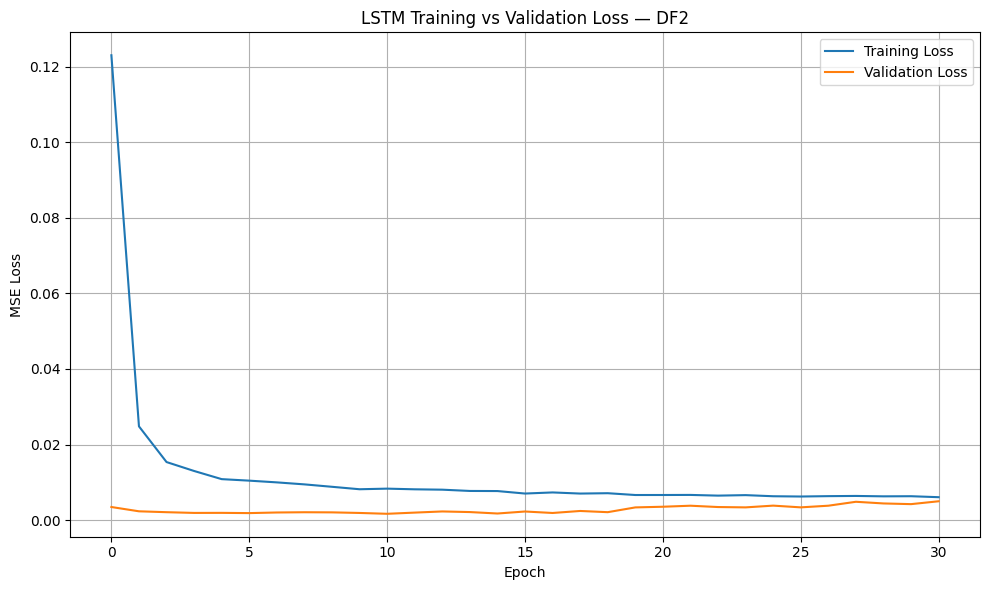

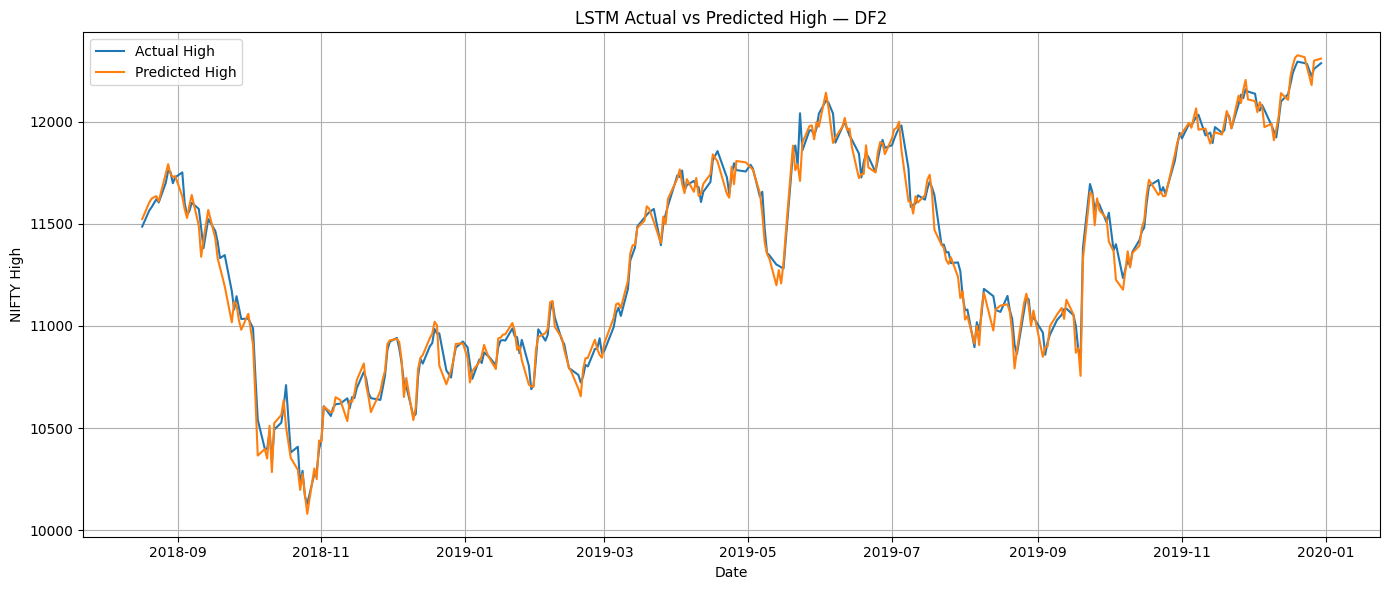

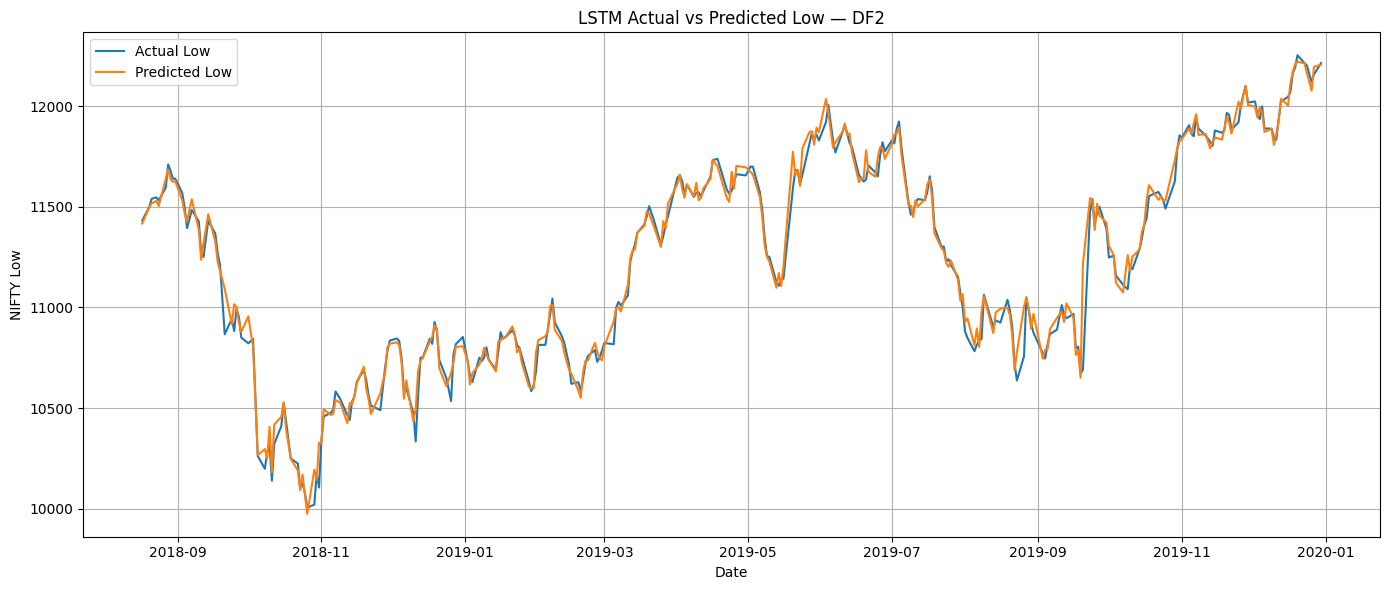

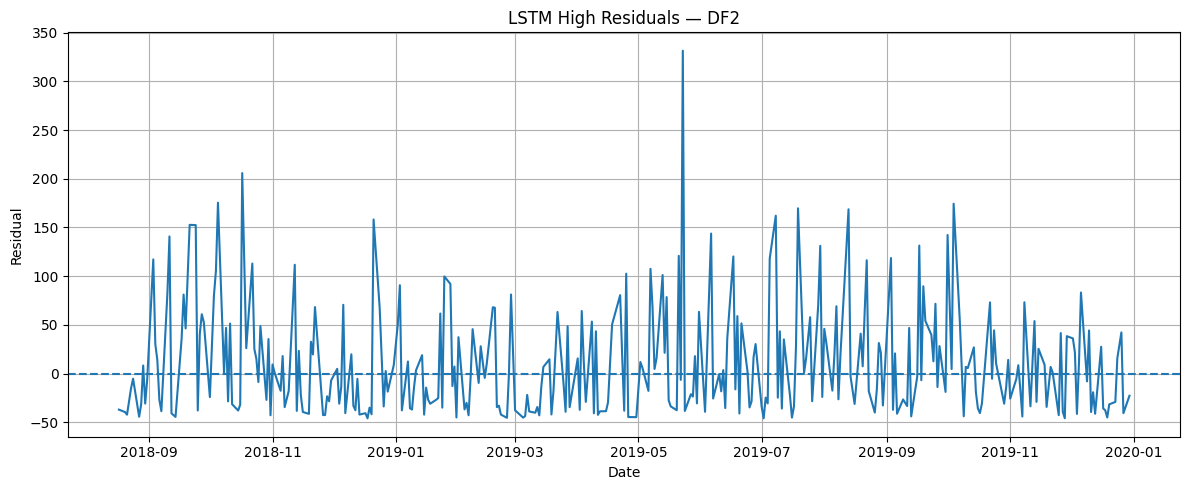

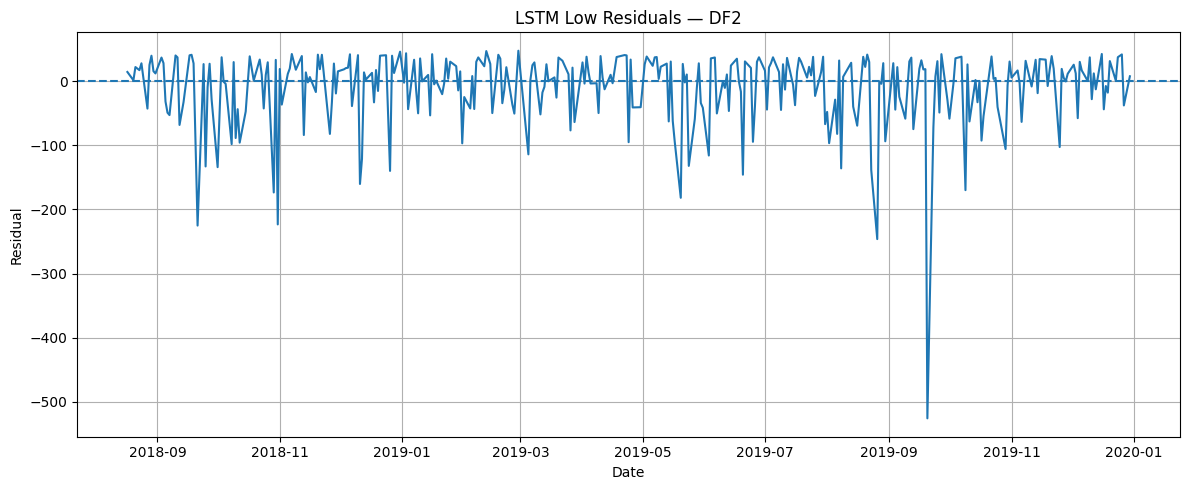

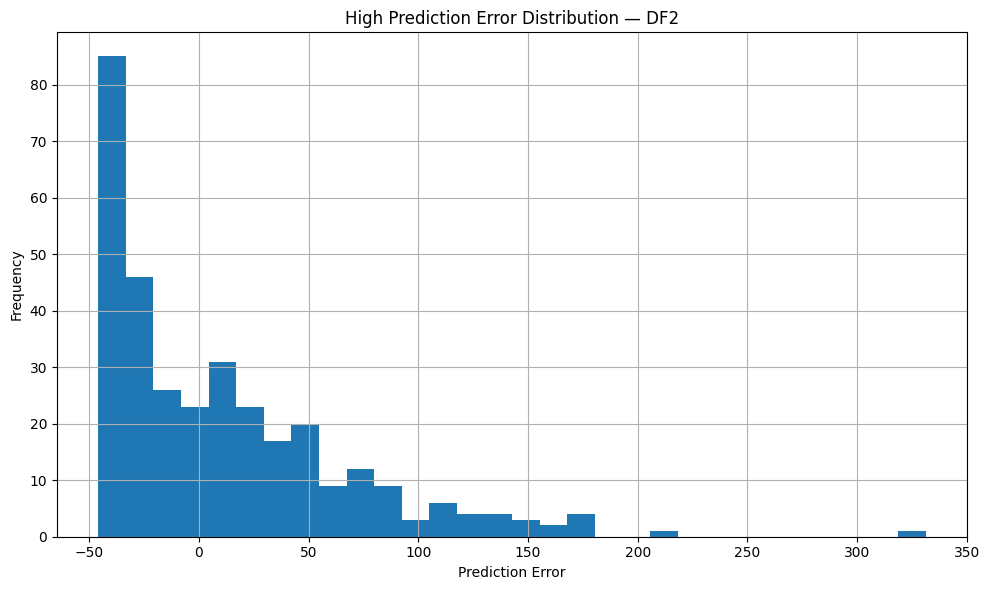

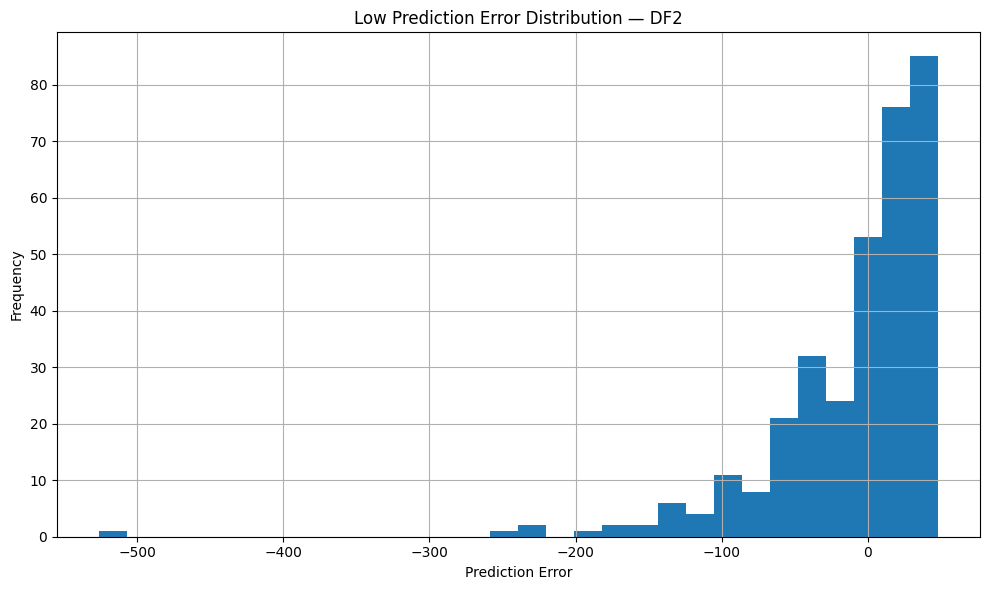


DF2 completed.


RUNNING DF3
2020 - 2021
Regime observations: 498
Train: 347
Validation: 75
Test: 75
X_train: (322, 25, 4)
X_val: (75, 25, 4)
X_test: (75, 25, 4)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_8 (LSTM)                   │ (None, 25, 64)         │        17,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_9 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,642 (119.70 KB)

 Trainable params: 30,642 (119.70 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 76ms/step - loss: 0.2115 - val_loss: 0.0368 - learning_rate: 0.0010
Epoch 2/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0766 - val_loss: 0.0150 - learning_rate: 0.0010
Epoch 3/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0493 - val_loss: 0.0027 - learning_rate: 0.0010
Epoch 4/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0402 - val_loss: 0.0020 - learning_rate: 0.0010
Epoch 5/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0287 - val_loss: 0.0017 - learning_rate: 0.0010
Epoch 6/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0233 - val_loss: 0.0024 - learning_rate: 0.0010
Epoch 7/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0210 - val_loss: 9.5439e-04 - learning_rate: 0.0010
Epoch 8/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0186 - val_loss: 7.9502e-04 - learning_rate: 0.0010
Epoch 9/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0172 - val_loss: 8.8190e-04 - learning_rate: 0.001

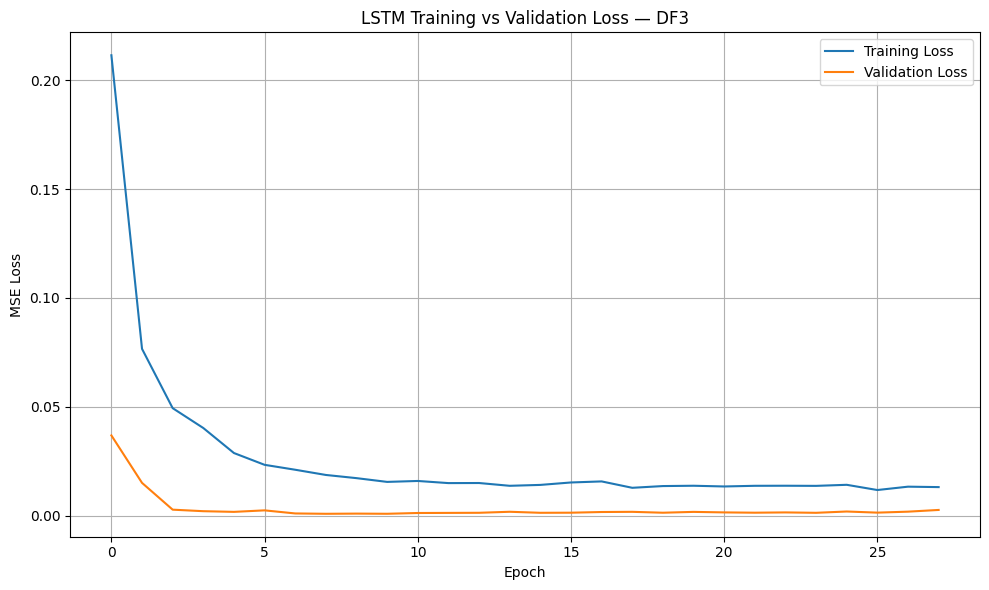

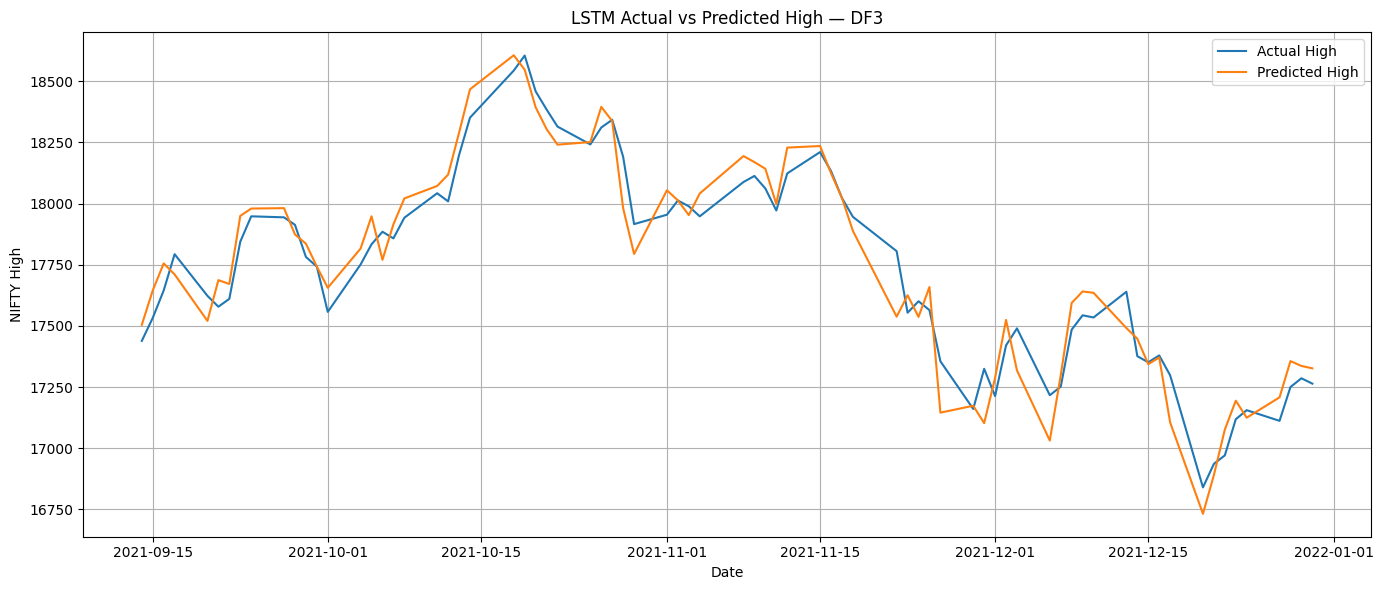

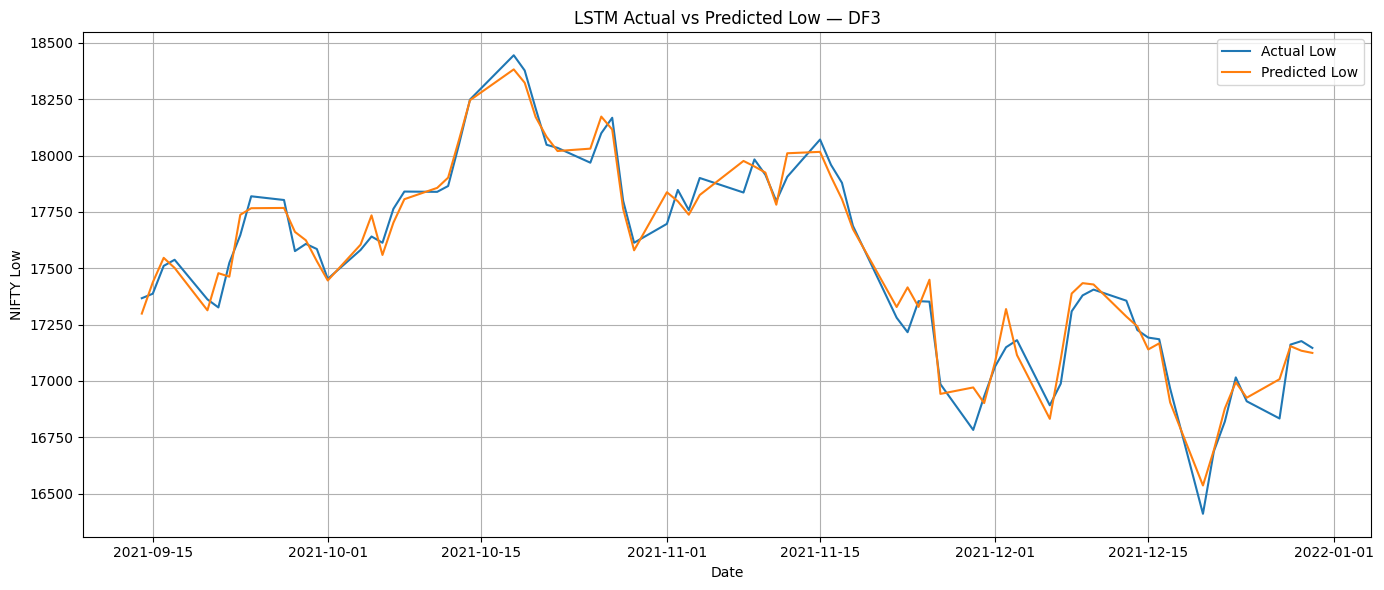

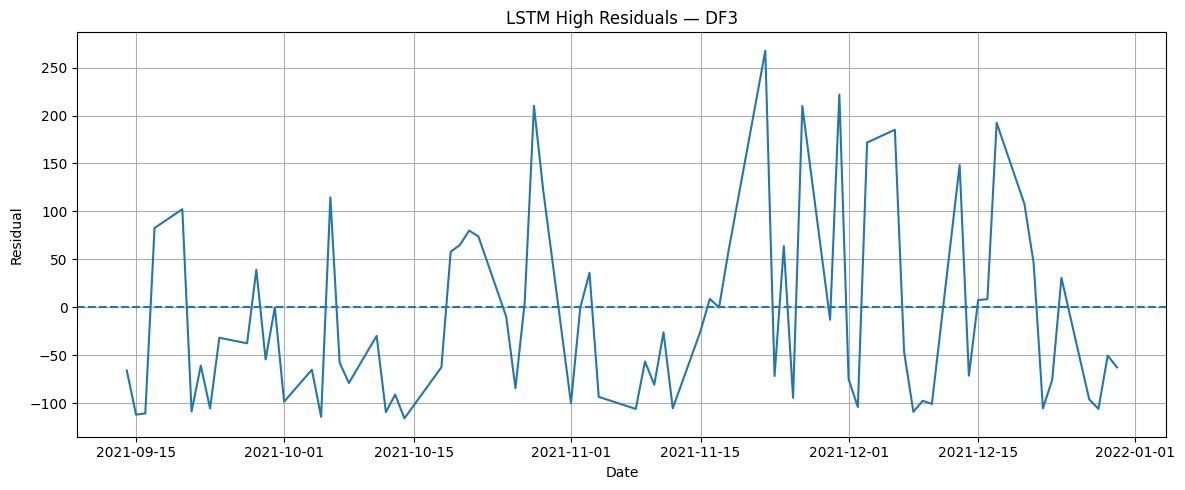

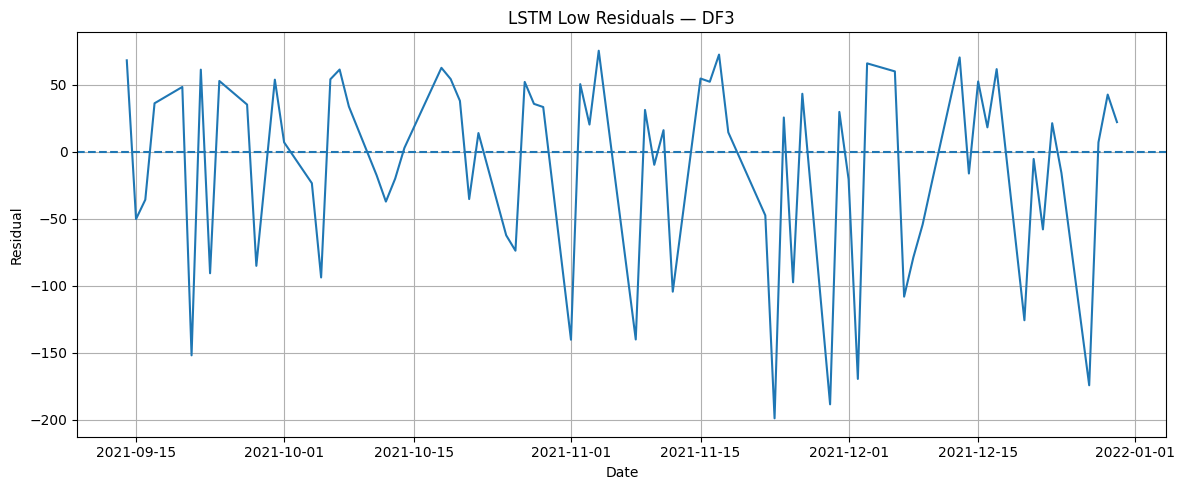

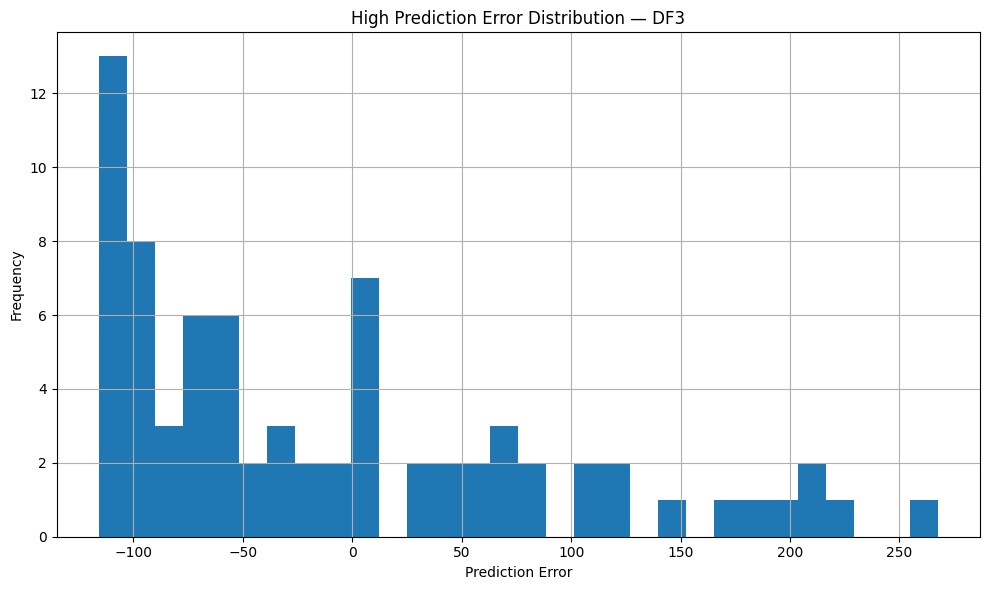

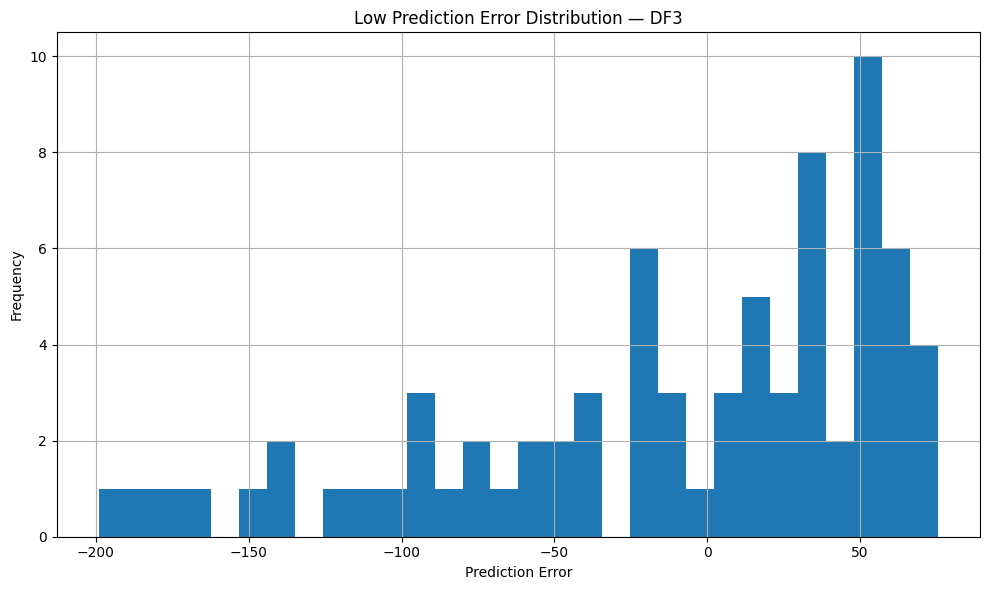


DF3 completed.


RUNNING DF4
2022 - 2025
Regime observations: 963
Train: 673
Validation: 144
Test: 145
X_train: (648, 25, 4)
X_val: (144, 25, 4)
X_test: (145, 25, 4)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_10 (LSTM)                  │ (None, 25, 64)         │        17,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_11 (LSTM)                  │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,642 (119.70 KB)

 Trainable params: 30,642 (119.70 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
21/21 ━━━━━━━━━━━━━━━━━━━━ 5s 51ms/step - loss: 0.1453 - val_loss: 0.0130 - learning_rate: 0.0010
Epoch 2/200
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0536 - val_loss: 0.0108 - learning_rate: 0.0010
Epoch 3/200
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0252 - val_loss: 0.0105 - learning_rate: 0.0010
Epoch 4/200
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0222 - val_loss: 0.0098 - learning_rate: 0.0010
Epoch 5/200
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0191 - val_loss: 0.0097 - learning_rate: 0.0010
Epoch 6/200
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0190 - val_loss: 0.0095 - learning_rate: 0.0010
Epoch 7/200
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0163 - val_loss: 0.0094 - learning_rate: 0.0010
Epoch 8/200
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0163 - val_loss: 0.0095 - learning_rate: 0.0010
Epoch 9/200
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0155 - val_loss: 0.0094 - learning_rate: 0.0010
Epoch 10/2

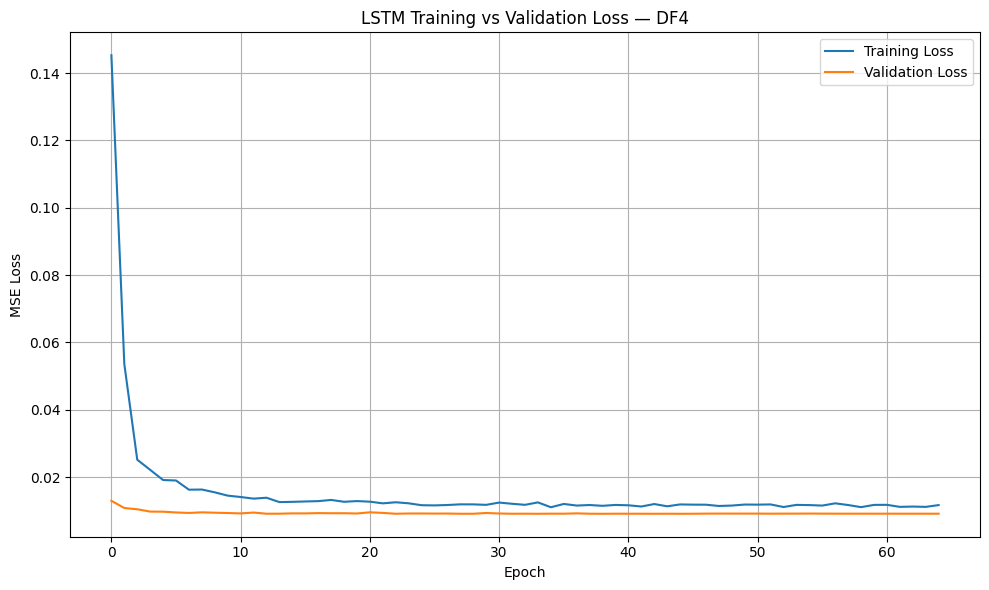

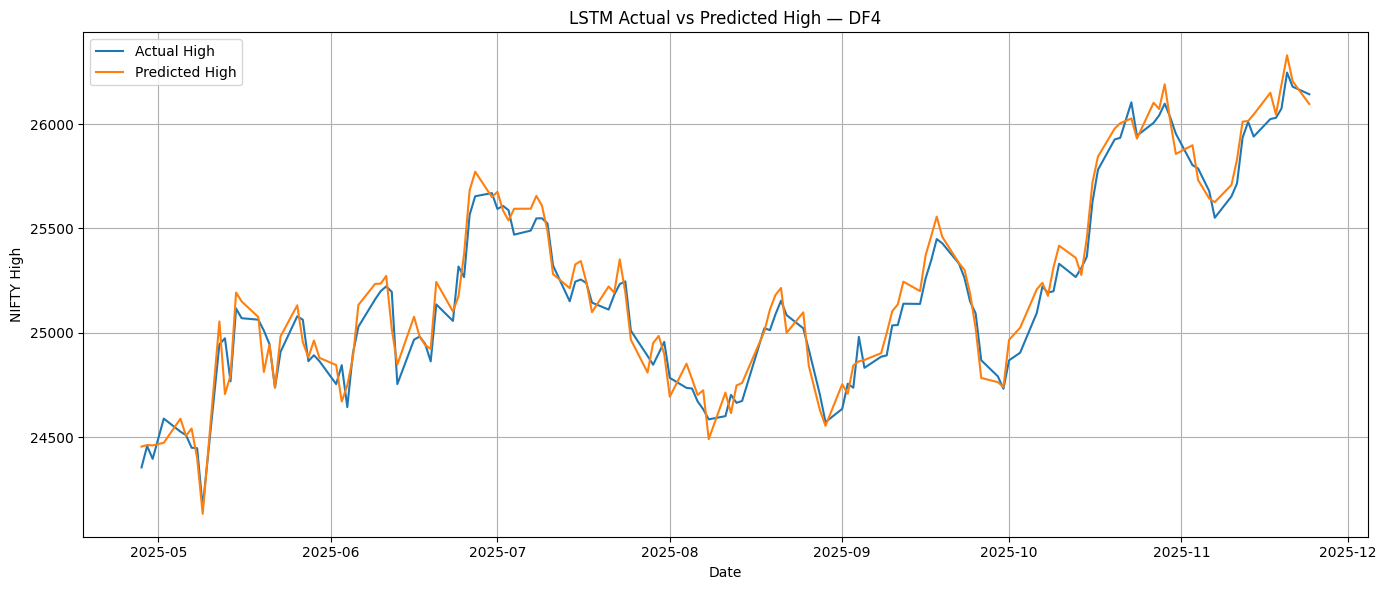

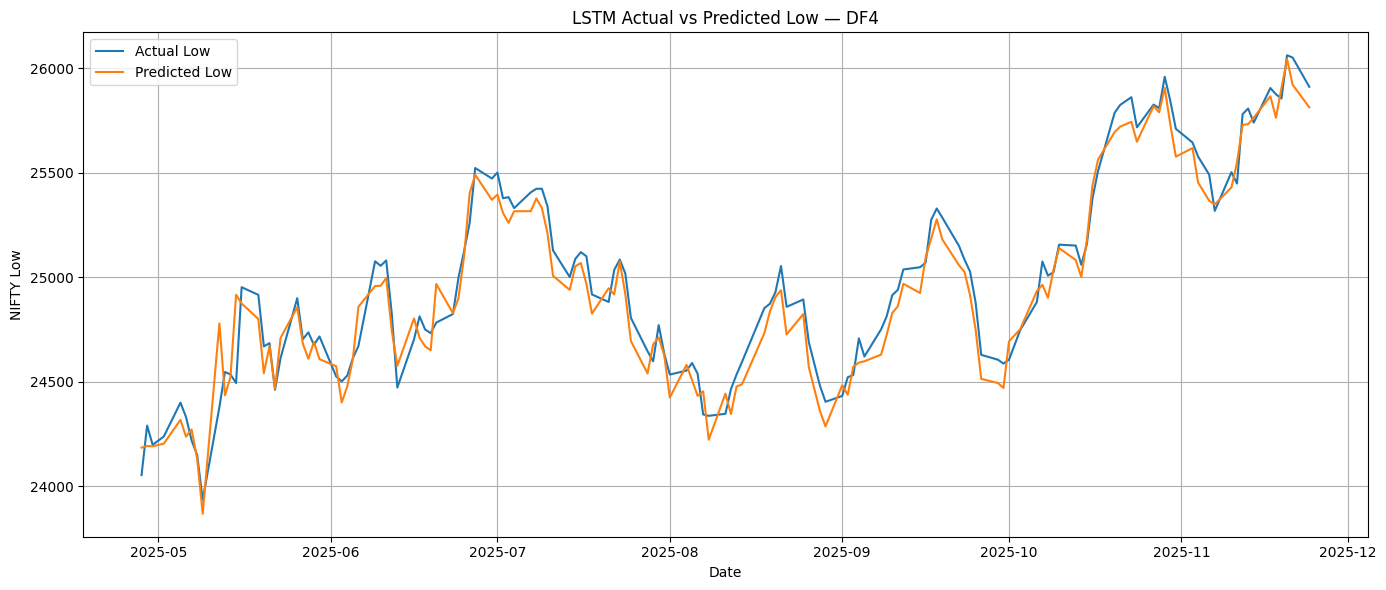

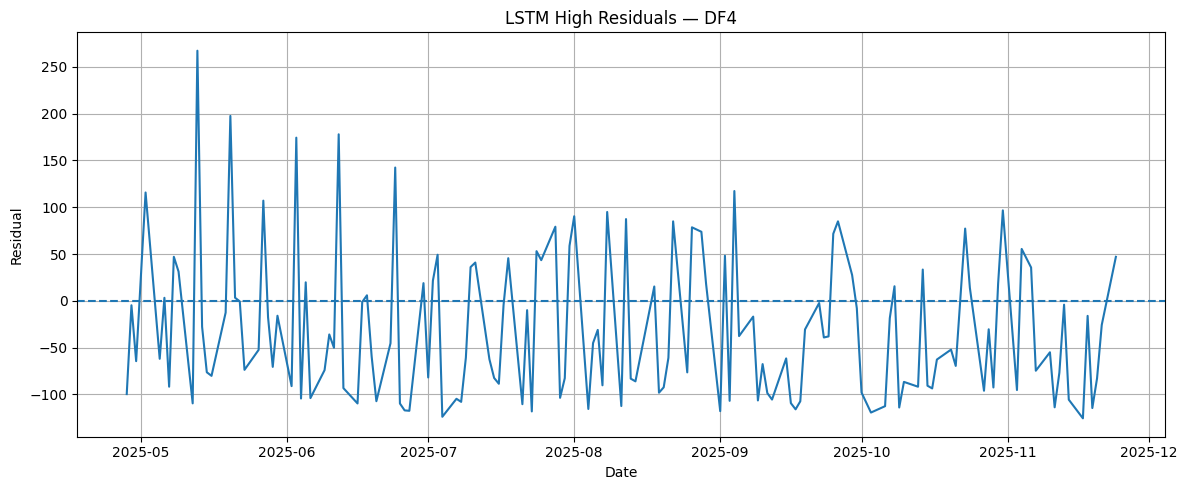

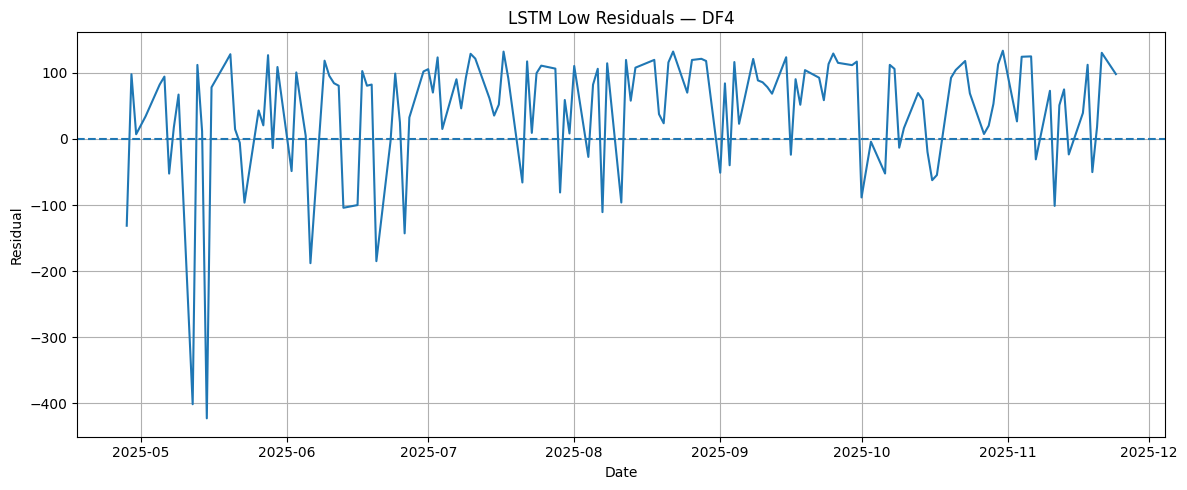

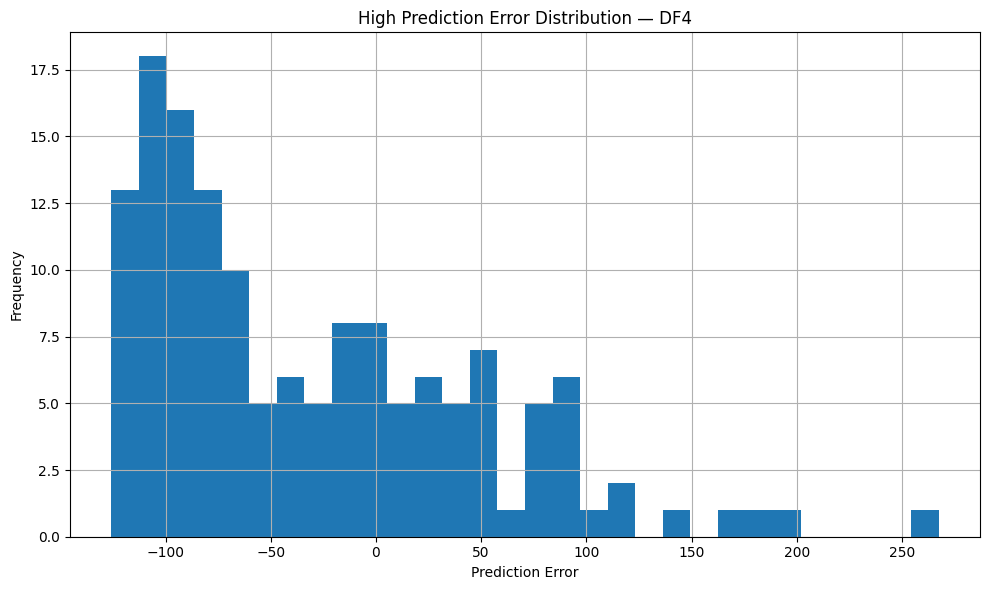

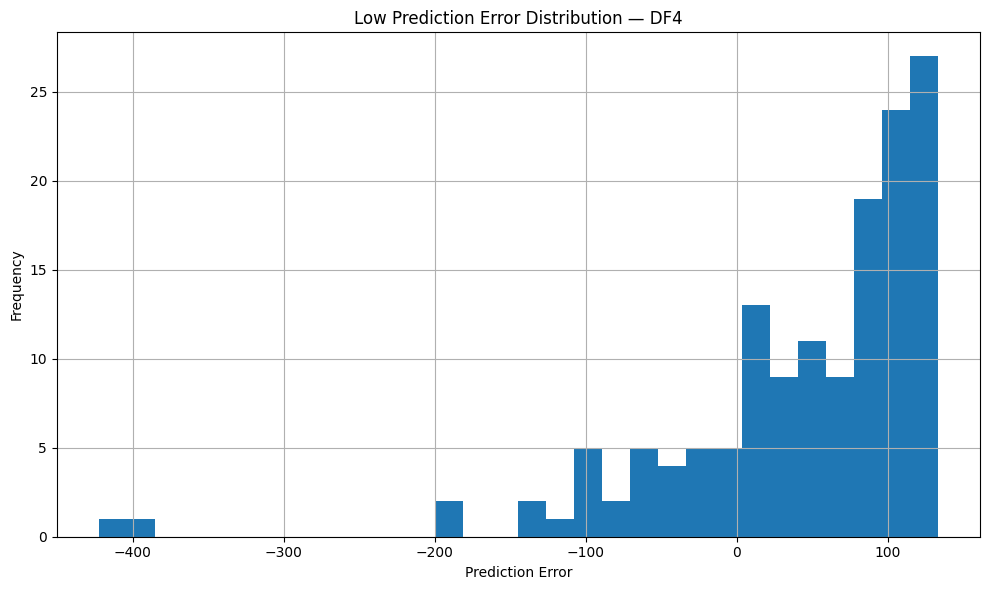


DF4 completed.


FINAL REGIME-WISE LSTM RESULTS
Regime  High_MAE  High_RMSE  High_R2  High_MAPE   Low_MAE   Low_RMSE   Low_R2  Low_MAPE  Train_Observations  Validation_Observations  Test_Observations
   DF1 55.525309  60.052075 0.961112   0.954551 33.071884  36.871895 0.983974  0.572329                 539                      121                122
   DF2 41.677300  56.437759 0.988070   0.368341 38.597091  59.423281 0.987318  0.348549                1509                      329                329
   DF3 82.575421  98.678252 0.942086   0.467111 57.140119  72.148515 0.972137  0.327701                 322                       75                 75
   DF4 71.993544  83.914374 0.966115   0.286100 83.122084 100.344956 0.955613  0.333433                 648                      144                145

Results saved to:
LSTM_Regime_Results


In [21]:
# ============================================================
# NIFTY 50 — REGIME-WISE LSTM
# DF1: 2007-2010
# DF2: 2011-2019
# DF3: 2020-2021
# DF4: 2022-Latest
#
# Each regime is trained and evaluated independently.
# Target:
#   Next-Day High / Current-Day Close
#   Next-Day Low  / Current-Day Close
#
# Split:
#   70% Train
#   15% Validation
#   15% Test
#
# Lookback:
#   25 trading days
# ============================================================

import os
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau


# ============================================================
# 1. SETTINGS
# ============================================================

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except:
    pass


DATA_PATH = "nifty50_2007_to_now.csv"

LOOKBACK = 25

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

EPOCHS = 200
BATCH_SIZE = 32

OUTPUT_DIR = "LSTM_Regime_Results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("Seed:", SEED)


# ============================================================
# 2. LOAD DATA
# ============================================================


print("Original shape:", df.shape)

# ------------------------------------------------------------
# Find date column
# ------------------------------------------------------------

possible_date_columns = [
    "Date",
    "date",
    "DATE",
    "Datetime",
    "datetime"
]

date_column = None

for col in possible_date_columns:
    if col in df.columns:
        date_column = col
        break

if date_column is None:
    raise ValueError(
        "Could not find Date column. "
        "Available columns are:\n"
        + str(df.columns.tolist())
    )

df[date_column] = pd.to_datetime(df[date_column], errors="coerce")

df = df.dropna(subset=[date_column])

df = df.sort_values(date_column).reset_index(drop=True)


# ============================================================
# 3. CHECK REQUIRED COLUMNS
# ============================================================

required_columns = [
    "Open",
    "High",
    "Low",
    "Close"
]

missing = [
    col for col in required_columns
    if col not in df.columns
]

if missing:
    raise ValueError(
        f"Missing required columns: {missing}"
    )


# ============================================================
# 4. CLEAN NUMERIC DATA
# ============================================================

for col in required_columns:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

df = df.dropna(
    subset=required_columns
).reset_index(drop=True)


# ============================================================
# 5. DEFINE REGIMES
# ============================================================

df["Year"] = df[date_column].dt.year

regimes = {

    "DF1": {
        "start": 2007,
        "end": 2010
    },

    "DF2": {
        "start": 2011,
        "end": 2019
    },

    "DF3": {
        "start": 2020,
        "end": 2021
    },

    "DF4": {
        "start": 2022,
        "end": df["Year"].max()
    }
}


# ============================================================
# 6. MODEL FUNCTION
# ============================================================

def build_lstm():

    model = Sequential([

        LSTM(
            64,
            return_sequences=True,
            input_shape=(LOOKBACK, 4)
        ),

        Dropout(0.20),

        LSTM(
            32,
            return_sequences=False
        ),

        Dropout(0.20),

        Dense(
            16,
            activation="relu"
        ),

        Dense(
            2
        )
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="mse"
    )

    return model


# ============================================================
# 7. METRICS FUNCTION
# ============================================================

def calculate_metrics(
    actual,
    predicted
):

    mae = mean_absolute_error(
        actual,
        predicted
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )

    r2 = r2_score(
        actual,
        predicted
    )

    # Avoid division by zero
    denominator = np.where(
        np.abs(actual) < 1e-8,
        1e-8,
        np.abs(actual)
    )

    mape = np.mean(
        np.abs(
            (actual - predicted)
            / denominator
        )
    ) * 100

    return mae, rmse, r2, mape


# ============================================================
# 8. STORE ALL RESULTS
# ============================================================

all_results = []


# ============================================================
# 9. RUN EACH REGIME SEPARATELY
# ============================================================

for regime_name, period in regimes.items():

    print("\n")
    print("=" * 70)
    print(f"RUNNING {regime_name}")
    print(
        f"{period['start']} - {period['end']}"
    )
    print("=" * 70)


    # --------------------------------------------------------
    # Extract regime
    # --------------------------------------------------------

    regime_df = df[
        (df["Year"] >= period["start"]) &
        (df["Year"] <= period["end"])
    ].copy()

    regime_df = regime_df.reset_index(drop=True)

    print(
        "Regime observations:",
        len(regime_df)
    )


    # --------------------------------------------------------
    # Check enough data
    # --------------------------------------------------------

    if len(regime_df) <= LOOKBACK + 20:

        print(
            f"Skipping {regime_name}: "
            f"insufficient observations."
        )

        continue


    # --------------------------------------------------------
    # FEATURES
    #
    # We use OHLC from the previous 25 days.
    # --------------------------------------------------------

    features = [
        "Open",
        "High",
        "Low",
        "Close"
    ]

    X_raw = regime_df[
        features
    ].values


    # --------------------------------------------------------
    # TARGET
    #
    # Next-day High / current Close
    # Next-day Low  / current Close
    #
    # y[i] corresponds to day i+1.
    # --------------------------------------------------------

    high_target = (
        regime_df["High"].shift(-1)
        / regime_df["Close"]
    )

    low_target = (
        regime_df["Low"].shift(-1)
        / regime_df["Close"]
    )

    y_raw = np.column_stack([
        high_target.values,
        low_target.values
    ])


    # --------------------------------------------------------
    # Remove final row because it has no next-day target
    # --------------------------------------------------------

    valid_mask = ~np.isnan(y_raw).any(axis=1)

    X_raw = X_raw[valid_mask]
    y_raw = y_raw[valid_mask]

    close_current = regime_df[
        "Close"
    ].values[valid_mask]

    dates = regime_df[
        date_column
    ].values[valid_mask]


    # ========================================================
    # 10. CHRONOLOGICAL SPLIT
    # ========================================================

    n = len(X_raw)

    train_end = int(
        n * TRAIN_RATIO
    )

    val_end = int(
        n * (TRAIN_RATIO + VAL_RATIO)
    )

    print(
        "Train:",
        train_end
    )

    print(
        "Validation:",
        val_end - train_end
    )

    print(
        "Test:",
        n - val_end
    )


    # ========================================================
    # 11. SCALE — TRAIN ONLY
    # ========================================================

    scaler_X = MinMaxScaler()

    scaler_y = MinMaxScaler()


    scaler_X.fit(
        X_raw[:train_end]
    )

    scaler_y.fit(
        y_raw[:train_end]
    )


    X_scaled = scaler_X.transform(
        X_raw
    )

    y_scaled = scaler_y.transform(
        y_raw
    )


    # ========================================================
    # 12. CREATE SEQUENCES
    # ========================================================

    X_sequences = []
    y_sequences = []
    sequence_indices = []

    for i in range(
        LOOKBACK,
        len(X_scaled)
    ):

        X_sequences.append(
            X_scaled[
                i - LOOKBACK:i
            ]
        )

        y_sequences.append(
            y_scaled[i]
        )

        sequence_indices.append(i)


    X_sequences = np.array(
        X_sequences
    )

    y_sequences = np.array(
        y_sequences
    )

    sequence_indices = np.array(
        sequence_indices
    )


    # ========================================================
    # 13. SPLIT SEQUENCES
    # ========================================================

    train_mask = (
        sequence_indices < train_end
    )

    val_mask = (
        (sequence_indices >= train_end) &
        (sequence_indices < val_end)
    )

    test_mask = (
        sequence_indices >= val_end
    )


    X_train = X_sequences[
        train_mask
    ]

    y_train = y_sequences[
        train_mask
    ]

    X_val = X_sequences[
        val_mask
    ]

    y_val = y_sequences[
        val_mask
    ]

    X_test = X_sequences[
        test_mask
    ]

    y_test = y_sequences[
        test_mask
    ]


    print(
        "X_train:",
        X_train.shape
    )

    print(
        "X_val:",
        X_val.shape
    )

    print(
        "X_test:",
        X_test.shape
    )


    # ========================================================
    # 14. BUILD MODEL
    # ========================================================

    model = build_lstm()

    model.summary()


    # ========================================================
    # 15. CALLBACKS
    # ========================================================

    early_stopping = EarlyStopping(

        monitor="val_loss",

        patience=20,

        restore_best_weights=True,

        verbose=1
    )


    reduce_lr = ReduceLROnPlateau(

        monitor="val_loss",

        factor=0.5,

        patience=8,

        min_lr=1e-6,

        verbose=1
    )


    # ========================================================
    # 16. TRAIN
    # ========================================================

    history = model.fit(

        X_train,

        y_train,

        validation_data=(
            X_val,
            y_val
        ),

        epochs=EPOCHS,

        batch_size=BATCH_SIZE,

        shuffle=False,

        callbacks=[
            early_stopping,
            reduce_lr
        ],

        verbose=1
    )


    # ========================================================
    # 17. PREDICT TEST
    # ========================================================

    y_pred_scaled = model.predict(
        X_test,
        verbose=0
    )


    # ========================================================
    # 18. INVERSE TRANSFORM
    # ========================================================

    y_pred_ratio = scaler_y.inverse_transform(
        y_pred_scaled
    )

    y_test_ratio = scaler_y.inverse_transform(
        y_test
    )


    # ========================================================
    # 19. GET TEST CLOSE VALUES
    # ========================================================

    test_indices = sequence_indices[
        test_mask
    ]

    test_close = close_current[
        test_indices
    ]

    test_dates = dates[
        test_indices
    ]


    # ========================================================
    # 20. RECONSTRUCT ABSOLUTE HIGH / LOW
    # ========================================================

    predicted_high = (
        y_pred_ratio[:, 0]
        * test_close
    )

    predicted_low = (
        y_pred_ratio[:, 1]
        * test_close
    )


    actual_high = regime_df[
        "High"
    ].values[test_indices]

    actual_low = regime_df[
        "Low"
    ].values[test_indices]


    # ========================================================
    # 21. METRICS
    # ========================================================

    high_mae, high_rmse, high_r2, high_mape = \
        calculate_metrics(
            actual_high,
            predicted_high
        )


    low_mae, low_rmse, low_r2, low_mape = \
        calculate_metrics(
            actual_low,
            predicted_low
        )


    print("\n")
    print("=" * 60)
    print(f"{regime_name} RESULTS")
    print("=" * 60)

    print("\nHIGH")
    print(
        f"MAE  : {high_mae:.4f}"
    )
    print(
        f"RMSE : {high_rmse:.4f}"
    )
    print(
        f"R²   : {high_r2:.4f}"
    )
    print(
        f"MAPE : {high_mape:.4f}%"
    )

    print("\nLOW")
    print(
        f"MAE  : {low_mae:.4f}"
    )
    print(
        f"RMSE : {low_rmse:.4f}"
    )
    print(
        f"R²   : {low_r2:.4f}"
    )
    print(
        f"MAPE : {low_mape:.4f}%"
    )


    # ========================================================
    # 22. SAVE METRICS
    # ========================================================

    all_results.append({

        "Regime": regime_name,

        "High_MAE": high_mae,
        "High_RMSE": high_rmse,
        "High_R2": high_r2,
        "High_MAPE": high_mape,

        "Low_MAE": low_mae,
        "Low_RMSE": low_rmse,
        "Low_R2": low_r2,
        "Low_MAPE": low_mape,

        "Train_Observations": len(X_train),

        "Validation_Observations": len(X_val),

        "Test_Observations": len(X_test)
    })


    # ========================================================
    # 23. SAVE PREDICTIONS
    # ========================================================

    prediction_df = pd.DataFrame({

        "Date": test_dates,

        "Actual_High":
            actual_high,

        "Predicted_High":
            predicted_high,

        "Actual_Low":
            actual_low,

        "Predicted_Low":
            predicted_low,

        "Actual_High_Ratio":
            y_test_ratio[:, 0],

        "Predicted_High_Ratio":
            y_pred_ratio[:, 0],

        "Actual_Low_Ratio":
            y_test_ratio[:, 1],

        "Predicted_Low_Ratio":
            y_pred_ratio[:, 1],

        "Close_t":
            test_close
    })


    prediction_path = os.path.join(
        OUTPUT_DIR,
        f"{regime_name}_Predictions.csv"
    )

    prediction_df.to_csv(
        prediction_path,
        index=False
    )


    # ========================================================
    # 24. TRAINING / VALIDATION LOSS
    # ========================================================

    plt.figure(
        figsize=(10, 6)
    )

    plt.plot(
        history.history["loss"],
        label="Training Loss"
    )

    plt.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("MSE Loss")

    plt.title(
        f"LSTM Training vs Validation Loss — {regime_name}"
    )

    plt.legend()

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_Loss.png"
        ),
        dpi=300
    )

    plt.show()


    # ========================================================
    # 25. ACTUAL VS PREDICTED — HIGH
    # ========================================================

    plt.figure(
        figsize=(14, 6)
    )

    plt.plot(
        test_dates,
        actual_high,
        label="Actual High"
    )

    plt.plot(
        test_dates,
        predicted_high,
        label="Predicted High"
    )

    plt.xlabel("Date")

    plt.ylabel("NIFTY High")

    plt.title(
        f"LSTM Actual vs Predicted High — {regime_name}"
    )

    plt.legend()

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_High_Actual_vs_Predicted.png"
        ),
        dpi=300
    )

    plt.show()


    # ========================================================
    # 26. ACTUAL VS PREDICTED — LOW
    # ========================================================

    plt.figure(
        figsize=(14, 6)
    )

    plt.plot(
        test_dates,
        actual_low,
        label="Actual Low"
    )

    plt.plot(
        test_dates,
        predicted_low,
        label="Predicted Low"
    )

    plt.xlabel("Date")

    plt.ylabel("NIFTY Low")

    plt.title(
        f"LSTM Actual vs Predicted Low — {regime_name}"
    )

    plt.legend()

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_Low_Actual_vs_Predicted.png"
        ),
        dpi=300
    )

    plt.show()


    # ========================================================
    # 27. HIGH RESIDUALS
    # ========================================================

    high_residuals = (
        actual_high -
        predicted_high
    )

    plt.figure(
        figsize=(12, 5)
    )

    plt.plot(
        test_dates,
        high_residuals
    )

    plt.axhline(
        0,
        linestyle="--"
    )

    plt.xlabel("Date")

    plt.ylabel("Residual")

    plt.title(
        f"LSTM High Residuals — {regime_name}"
    )

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_High_Residuals.png"
        ),
        dpi=300
    )

    plt.show()


    # ========================================================
    # 28. LOW RESIDUALS
    # ========================================================

    low_residuals = (
        actual_low -
        predicted_low
    )

    plt.figure(
        figsize=(12, 5)
    )

    plt.plot(
        test_dates,
        low_residuals
    )

    plt.axhline(
        0,
        linestyle="--"
    )

    plt.xlabel("Date")

    plt.ylabel("Residual")

    plt.title(
        f"LSTM Low Residuals — {regime_name}"
    )

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_Low_Residuals.png"
        ),
        dpi=300
    )

    plt.show()


    # ========================================================
    # 29. ERROR DISTRIBUTIONS
    # ========================================================

    plt.figure(
        figsize=(10, 6)
    )

    plt.hist(
        high_residuals,
        bins=30
    )

    plt.xlabel("Prediction Error")

    plt.ylabel("Frequency")

    plt.title(
        f"High Prediction Error Distribution — {regime_name}"
    )

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_High_Error_Distribution.png"
        ),
        dpi=300
    )

    plt.show()


    plt.figure(
        figsize=(10, 6)
    )

    plt.hist(
        low_residuals,
        bins=30
    )

    plt.xlabel("Prediction Error")

    plt.ylabel("Frequency")

    plt.title(
        f"Low Prediction Error Distribution — {regime_name}"
    )

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_Low_Error_Distribution.png"
        ),
        dpi=300
    )

    plt.show()


    # ========================================================
    # 30. SAVE MODEL
    # ========================================================

    model.save(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_LSTM.keras"
        )
    )

    print(
        f"\n{regime_name} completed."
    )


# ============================================================
# 31. FINAL RESULTS TABLE
# ============================================================

results_df = pd.DataFrame(
    all_results
)

print("\n")
print("=" * 80)
print("FINAL REGIME-WISE LSTM RESULTS")
print("=" * 80)

print(
    results_df.to_string(
        index=False
    )
)


# ============================================================
# 32. SAVE FINAL RESULTS
# ============================================================

results_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "LSTM_Regime_Results.csv"
    ),
    index=False
)

results_df.to_excel(
    os.path.join(
        OUTPUT_DIR,
        "LSTM_Regime_Results.xlsx"
    ),
    index=False
)


print("\nResults saved to:")
print(OUTPUT_DIR)

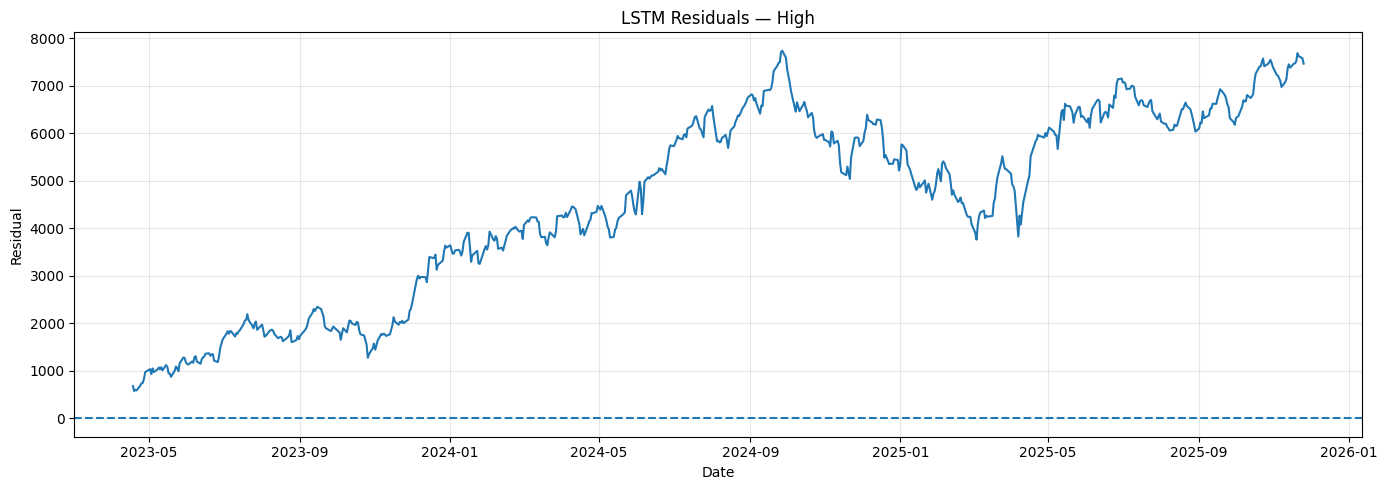

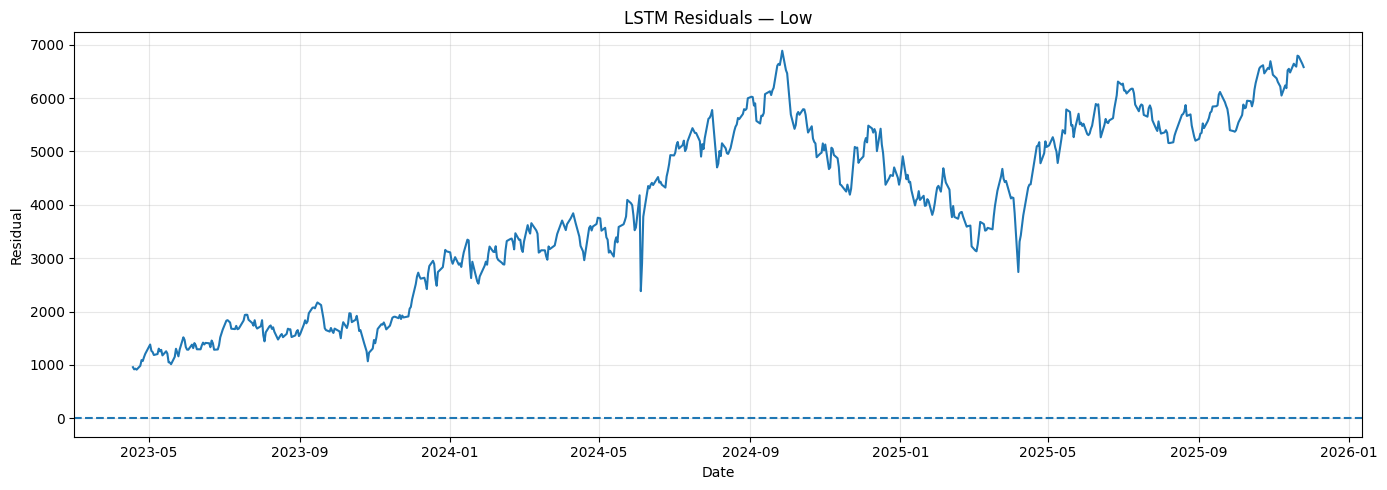

In [15]:
# ============================================================
# RESIDUAL ANALYSIS
# ============================================================

for target in TARGETS:

    _, _, _, prediction_df = (
        lstm_results[target]
    )

    prediction_df["Residual"] = (
        prediction_df["Actual"]
        -
        prediction_df["Predicted"]
    )

    plt.figure(figsize=(14, 5))

    plt.plot(
        prediction_df["Date"],
        prediction_df["Residual"]
    )

    plt.axhline(
        0,
        linestyle="--"
    )

    plt.xlabel("Date")
    plt.ylabel("Residual")

    plt.title(
        f"LSTM Residuals — {target}"
    )

    plt.grid(alpha=0.3)

    plt.tight_layout()

    path = os.path.join(
        GRAPH_DIR,
        f"LSTM_{target}_Residuals.png"
    )

    plt.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

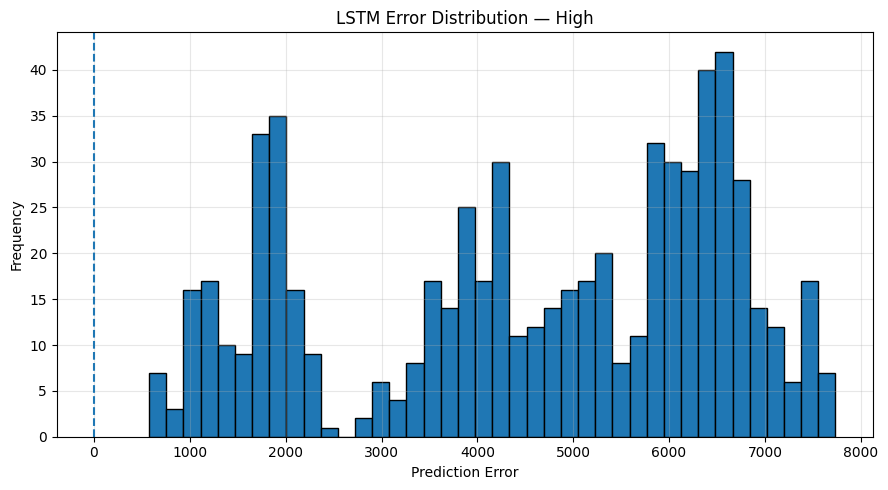

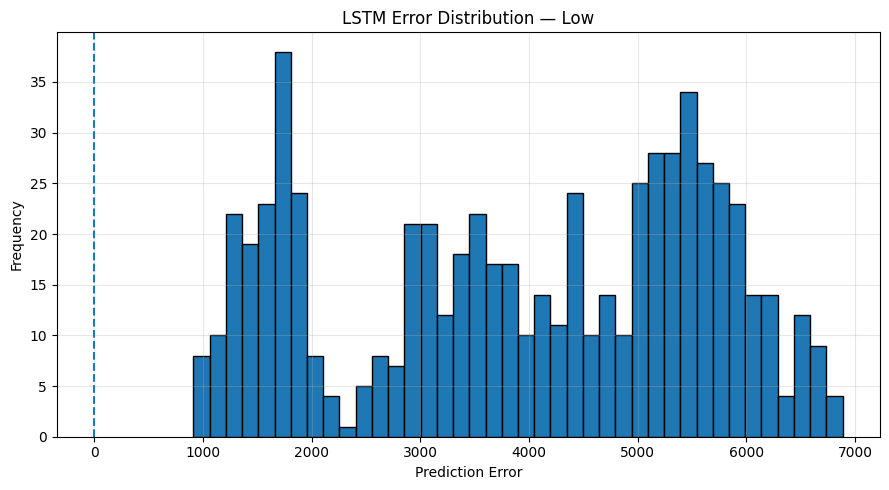

In [16]:
# ============================================================
# ERROR DISTRIBUTION
# ============================================================

for target in TARGETS:

    _, _, _, prediction_df = (
        lstm_results[target]
    )

    errors = (
        prediction_df["Actual"]
        -
        prediction_df["Predicted"]
    )

    plt.figure(figsize=(9, 5))

    plt.hist(
        errors,
        bins=40,
        edgecolor="black"
    )

    plt.axvline(
        0,
        linestyle="--"
    )

    plt.xlabel("Prediction Error")
    plt.ylabel("Frequency")

    plt.title(
        f"LSTM Error Distribution — {target}"
    )

    plt.grid(alpha=0.3)

    plt.tight_layout()

    path = os.path.join(
        GRAPH_DIR,
        f"LSTM_{target}_Error_Distribution.png"
    )

    plt.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

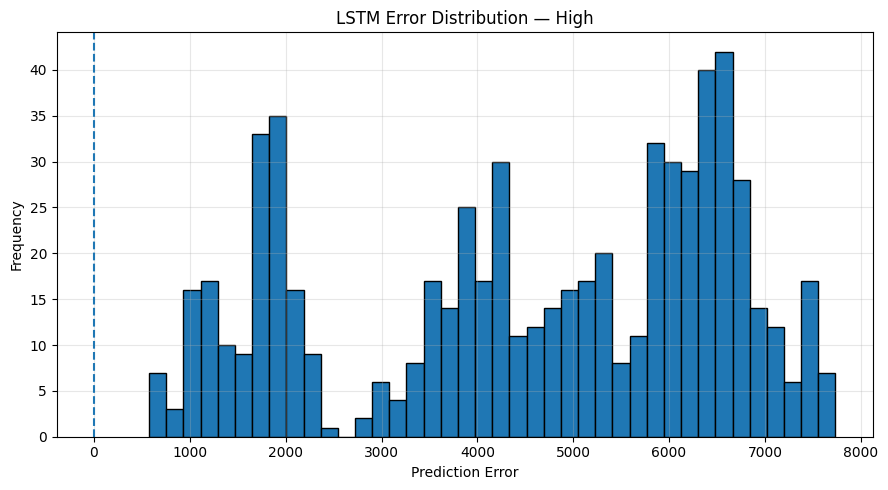

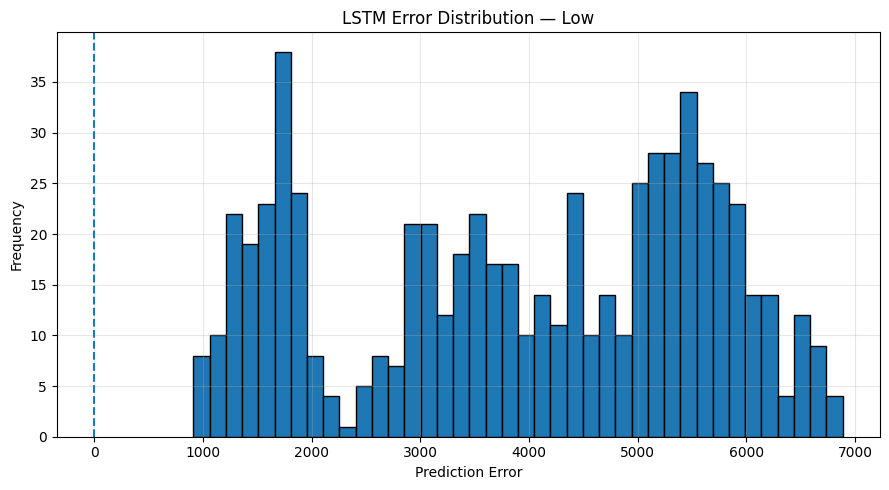

In [17]:
# ============================================================
# ERROR DISTRIBUTION
# ============================================================

for target in TARGETS:

    _, _, _, prediction_df = (
        lstm_results[target]
    )

    errors = (
        prediction_df["Actual"]
        -
        prediction_df["Predicted"]
    )

    plt.figure(figsize=(9, 5))

    plt.hist(
        errors,
        bins=40,
        edgecolor="black"
    )

    plt.axvline(
        0,
        linestyle="--"
    )

    plt.xlabel("Prediction Error")
    plt.ylabel("Frequency")

    plt.title(
        f"LSTM Error Distribution — {target}"
    )

    plt.grid(alpha=0.3)

    plt.tight_layout()

    path = os.path.join(
        GRAPH_DIR,
        f"LSTM_{target}_Error_Distribution.png"
    )

    plt.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

TensorFlow: 2.17.0
Seed: 42
Original shape: (4462, 7)


RUNNING DF1
2007 - 2010
Regime observations: 808
Train: 564
Validation: 121
Test: 122
X_train: (539, 25, 4)
X_val: (121, 25, 4)
X_test: (122, 25, 4)


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional_2 (Bidirectional) │ (None, 25, 128)        │        35,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 25, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_3 (Bidirectional) │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 77,618 (303.20 KB)

 Trainable params: 77,618 (303.20 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
17/17 ━━━━━━━━━━━━━━━━━━━━ 9s 77ms/step - loss: 0.0732 - val_loss: 0.0129 - learning_rate: 0.0010
Epoch 2/200
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0669 - val_loss: 0.0053 - learning_rate: 0.0010
Epoch 3/200
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0236 - val_loss: 0.0153 - learning_rate: 0.0010
Epoch 4/200
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0262 - val_loss: 0.0043 - learning_rate: 0.0010
Epoch 5/200
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0140 - val_loss: 0.0021 - learning_rate: 0.0010
Epoch 6/200
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0154 - val_loss: 0.0038 - learning_rate: 0.0010
Epoch 7/200
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0132 - val_loss: 0.0031 - learning_rate: 0.0010
Epoch 8/200
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0129 - val_loss: 0.0043 - learning_rate: 0.0010
Epoch 9/200
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0110 - val_loss: 0.0027 - learning_rate: 0.0010
Epoch 10/2

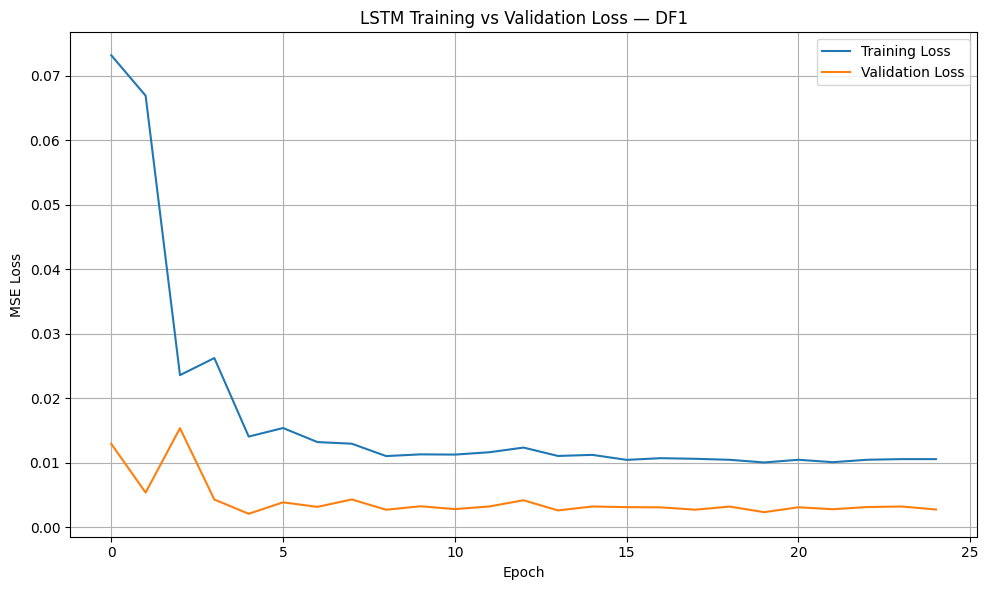

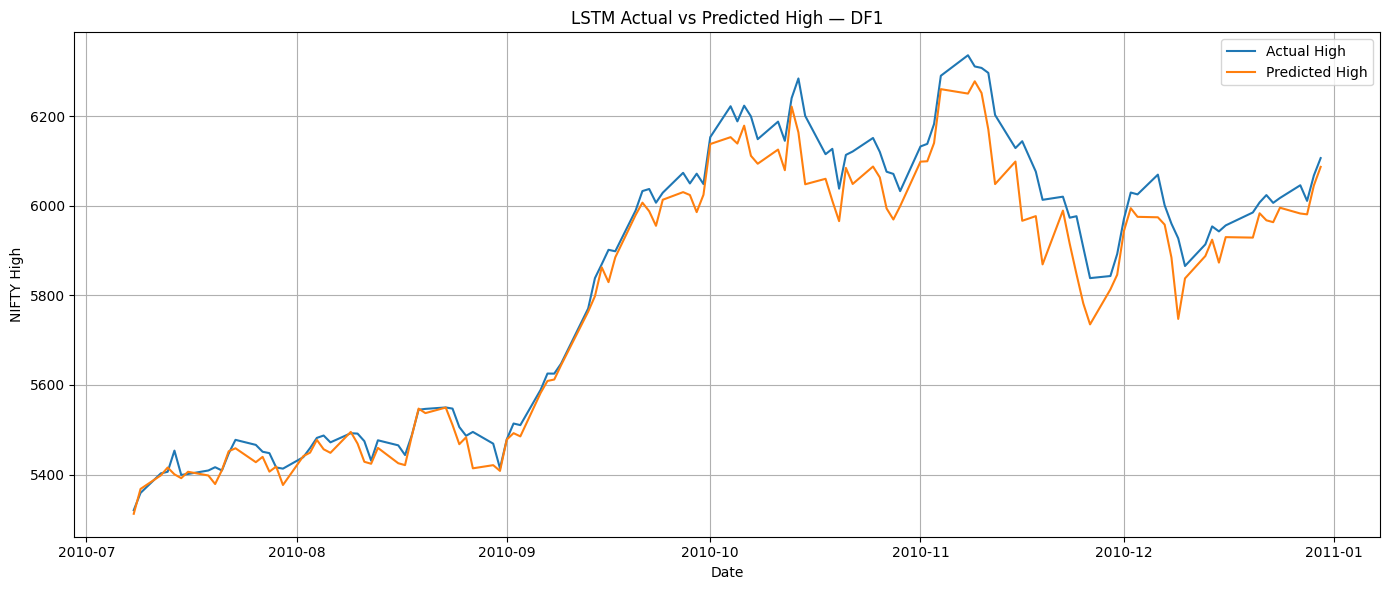

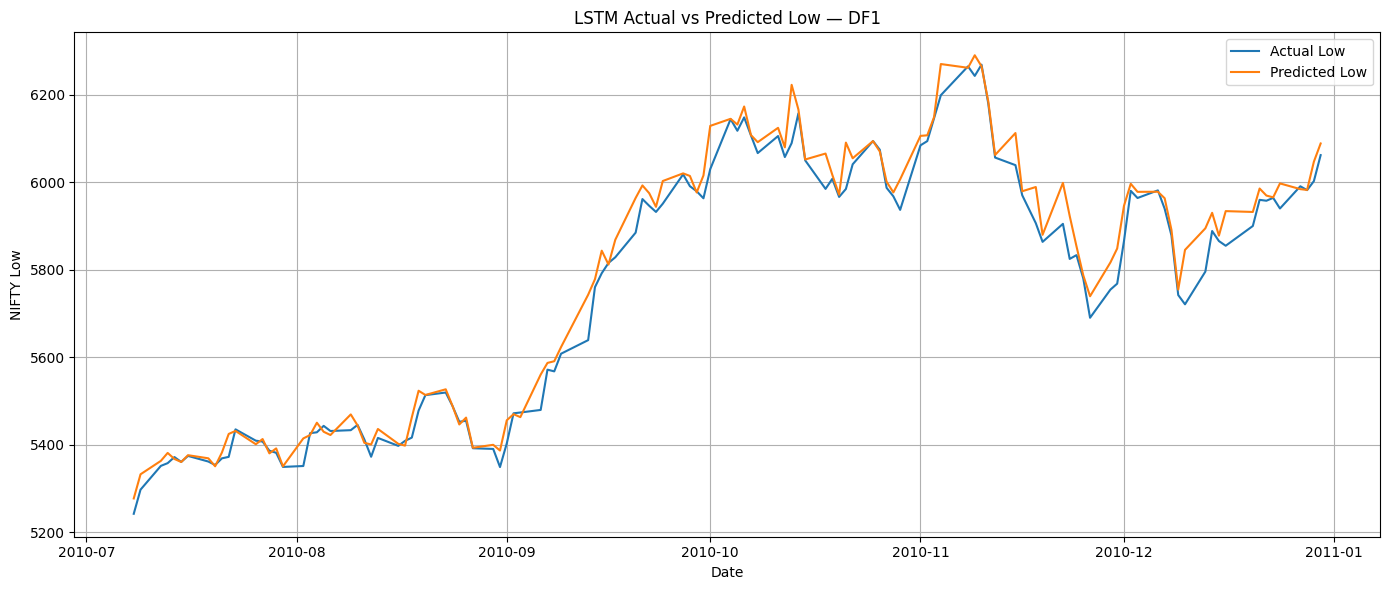

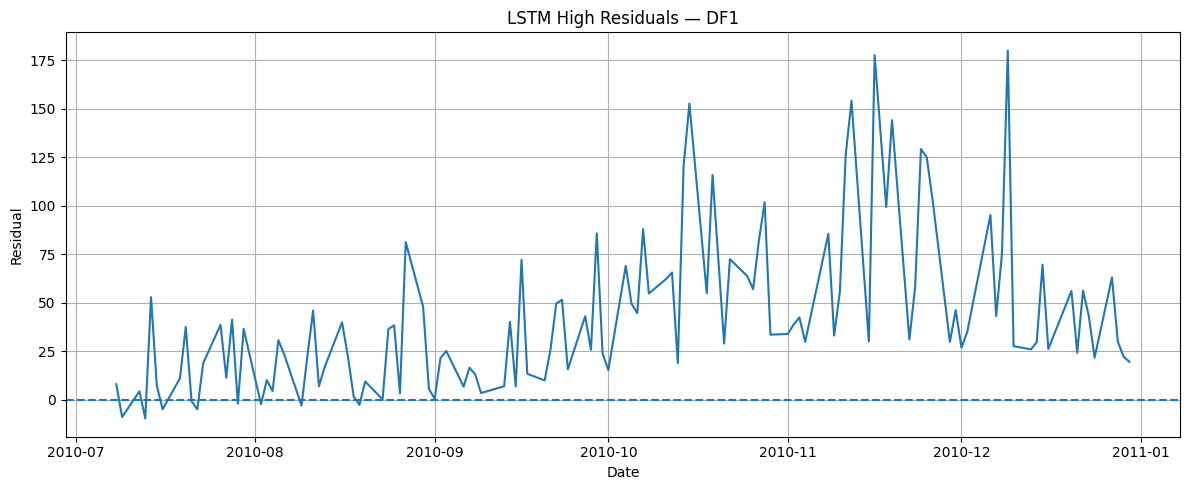

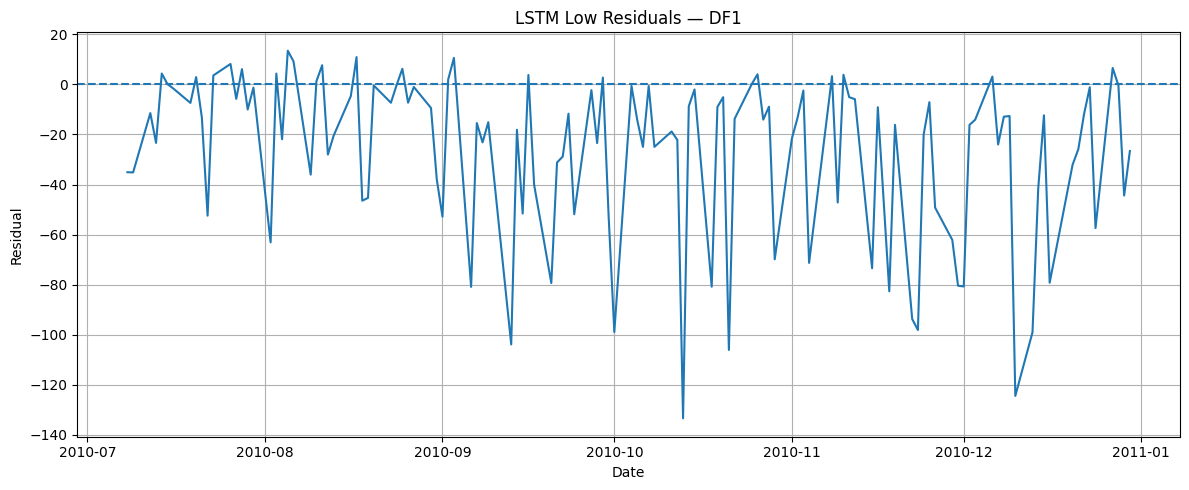

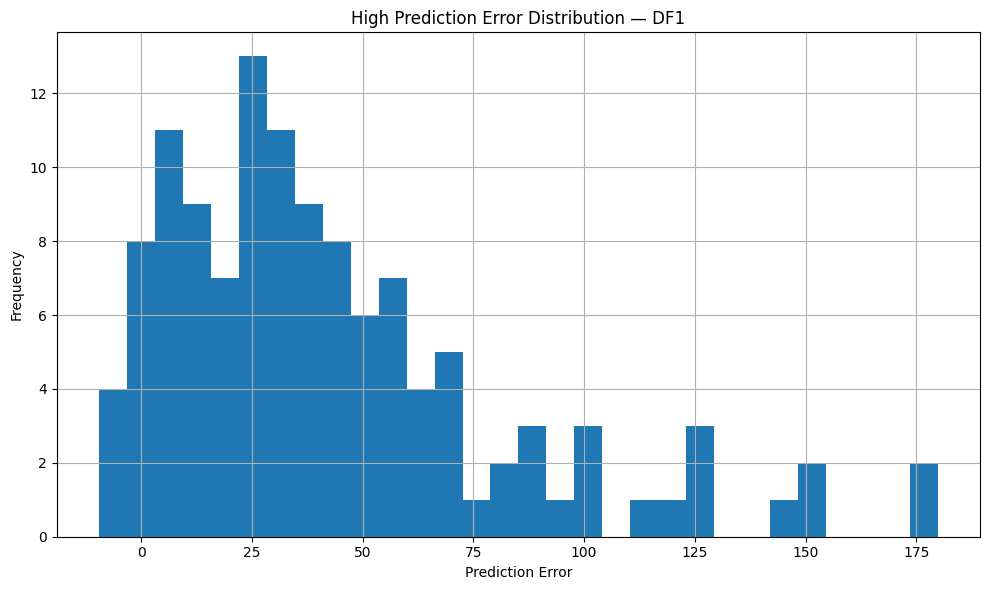

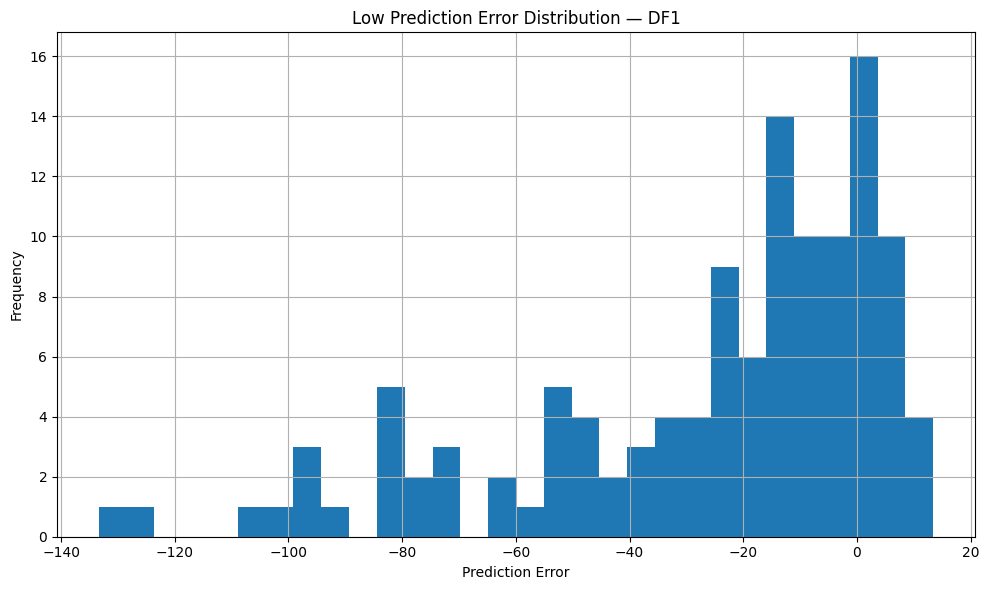


DF1 completed.


RUNNING DF2
2011 - 2019
Regime observations: 2193
Train: 1534
Validation: 329
Test: 329
X_train: (1509, 25, 4)
X_val: (329, 25, 4)
X_test: (329, 25, 4)


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional_4 (Bidirectional) │ (None, 25, 128)        │        35,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 25, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_5 (Bidirectional) │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 77,618 (303.20 KB)

 Trainable params: 77,618 (303.20 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
48/48 ━━━━━━━━━━━━━━━━━━━━ 8s 37ms/step - loss: 0.0940 - val_loss: 0.0196 - learning_rate: 0.0010
Epoch 2/200
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0426 - val_loss: 0.0156 - learning_rate: 0.0010
Epoch 3/200
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0267 - val_loss: 0.0042 - learning_rate: 0.0010
Epoch 4/200
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0210 - val_loss: 0.0059 - learning_rate: 0.0010
Epoch 5/200
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0168 - val_loss: 0.0052 - learning_rate: 0.0010
Epoch 6/200
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0139 - val_loss: 0.0051 - learning_rate: 0.0010
Epoch 7/200
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0120 - val_loss: 0.0038 - learning_rate: 0.0010
Epoch 8/200
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0109 - val_loss: 0.0027 - learning_rate: 0.0010
Epoch 9/200
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0091 - val_loss: 0.0031 - learning_rate: 0.0010
Epoch 10/2

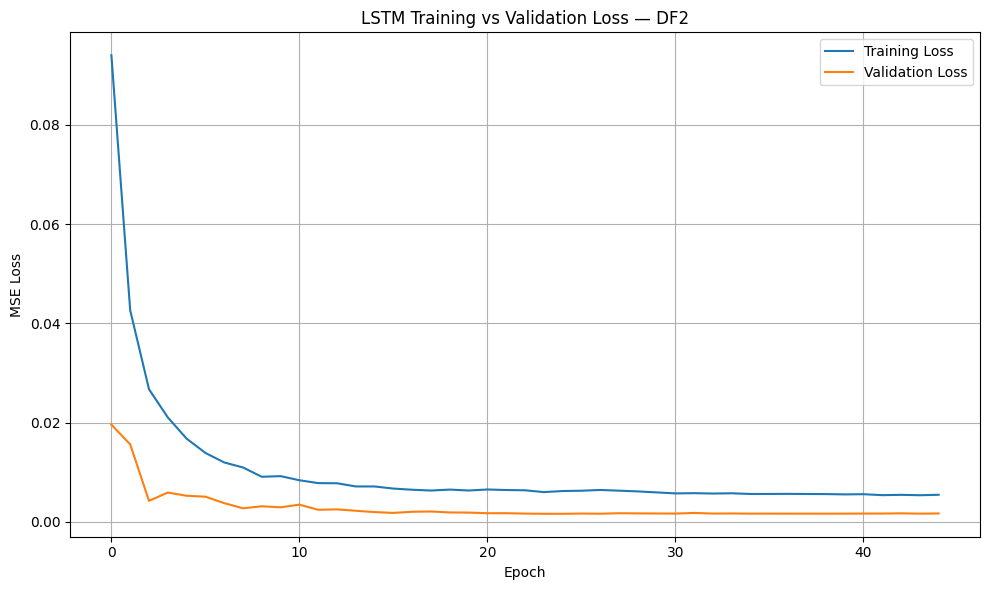

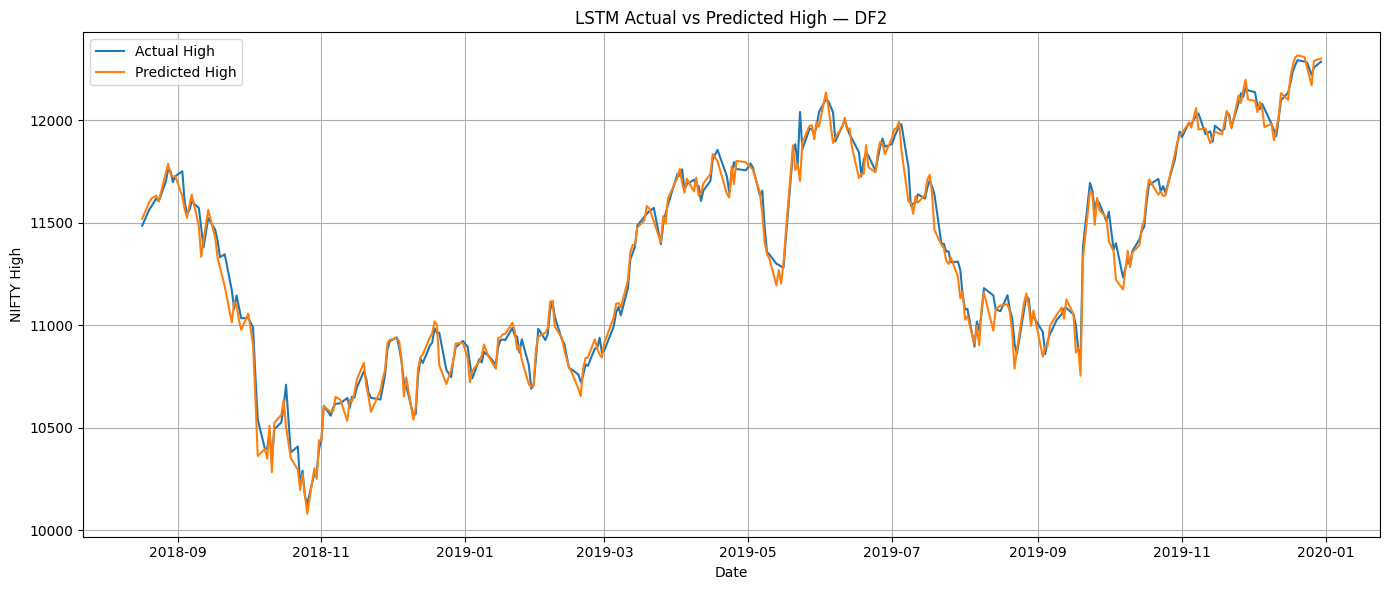

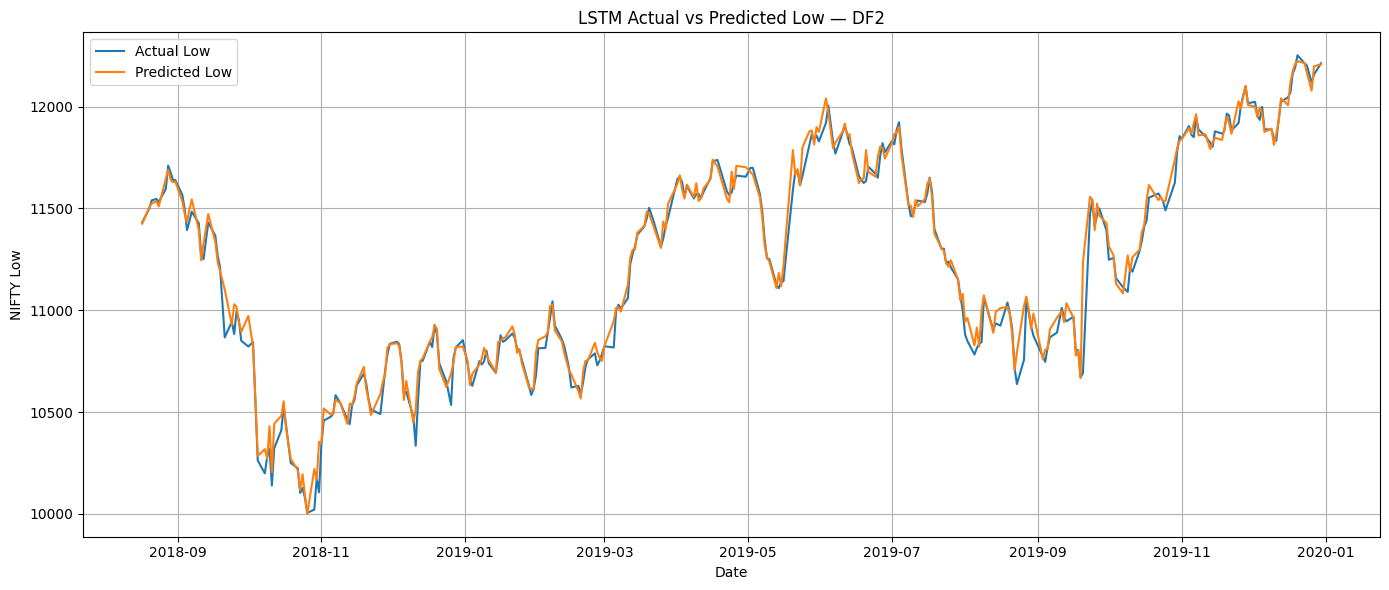

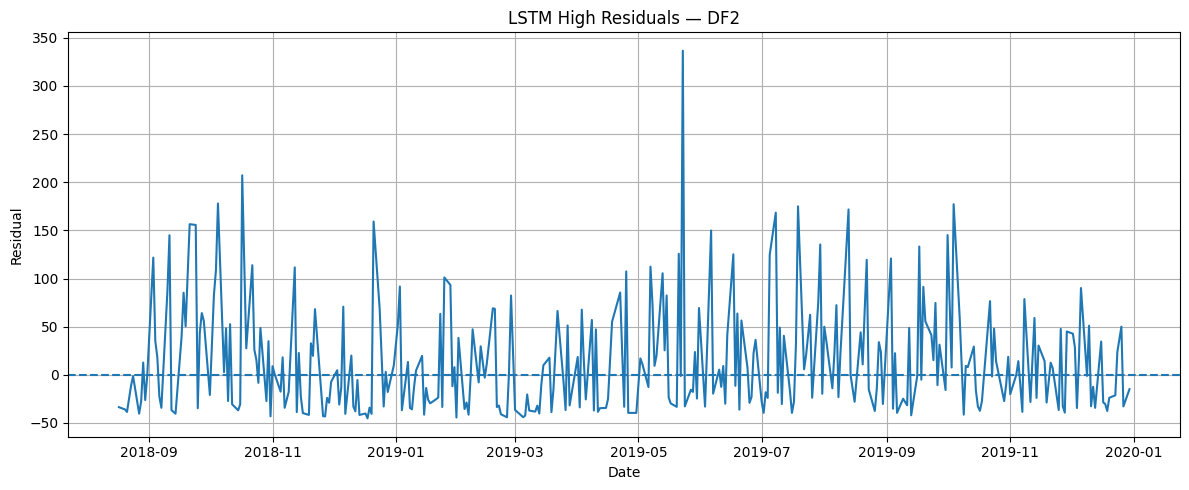

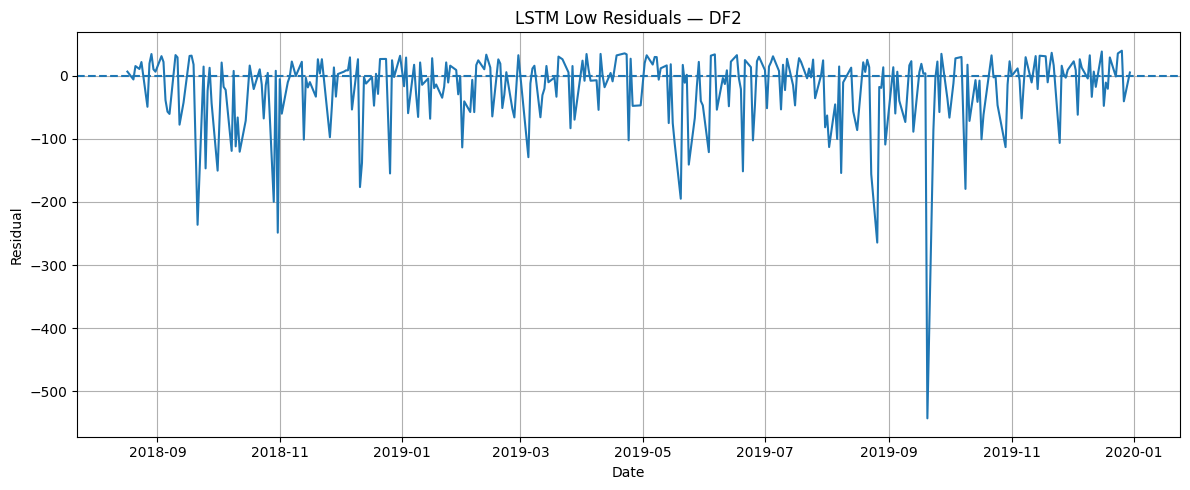

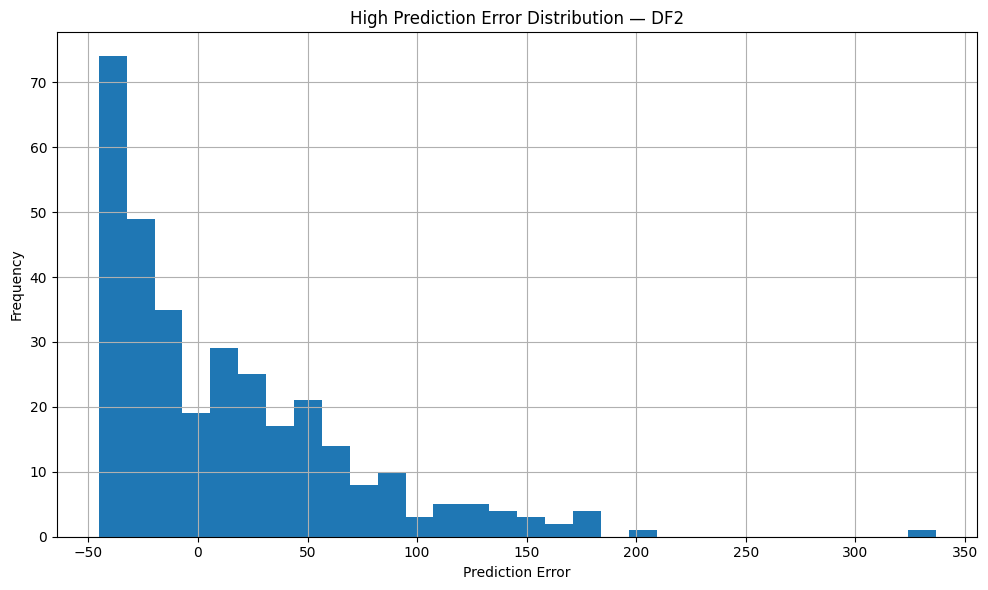

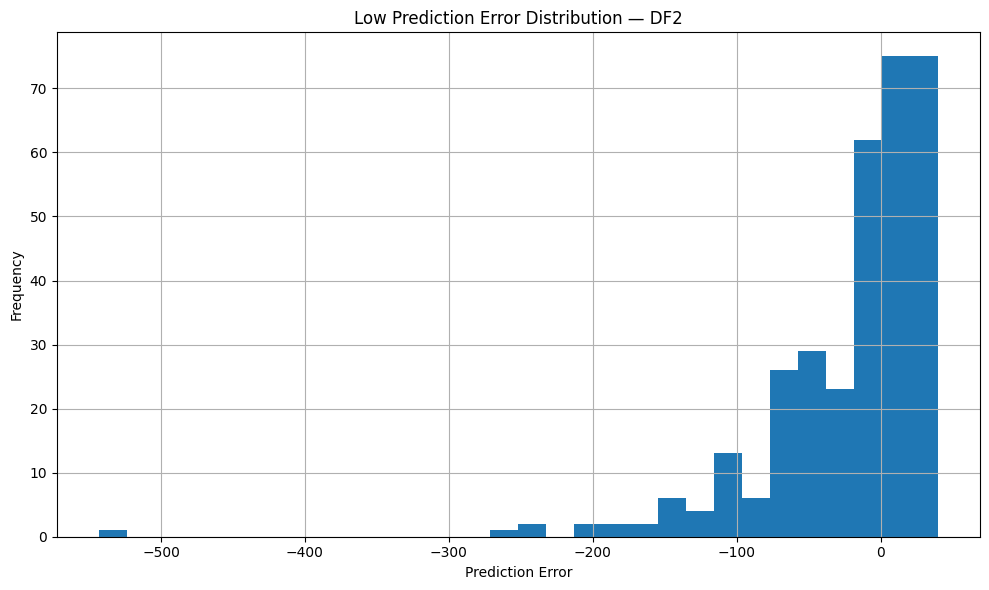


DF2 completed.


RUNNING DF3
2020 - 2021
Regime observations: 498
Train: 347
Validation: 75
Test: 75
X_train: (322, 25, 4)
X_val: (75, 25, 4)
X_test: (75, 25, 4)


Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional_6 (Bidirectional) │ (None, 25, 128)        │        35,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 25, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_7 (Bidirectional) │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_19 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 77,618 (303.20 KB)

 Trainable params: 77,618 (303.20 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 8s 100ms/step - loss: 0.1705 - val_loss: 0.0213 - learning_rate: 0.0010
Epoch 2/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0575 - val_loss: 0.0049 - learning_rate: 0.0010
Epoch 3/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0337 - val_loss: 0.0052 - learning_rate: 0.0010
Epoch 4/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0236 - val_loss: 0.0012 - learning_rate: 0.0010
Epoch 5/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0228 - val_loss: 0.0016 - learning_rate: 0.0010
Epoch 6/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.0213 - val_loss: 0.0012 - learning_rate: 0.0010
Epoch 7/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0195 - val_loss: 0.0020 - learning_rate: 0.0010
Epoch 8/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0174 - val_loss: 0.0017 - learning_rate: 0.0010
Epoch 9/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.0154 - val_loss: 0.0013 - learning_rate: 0.0010
Epoch 10/

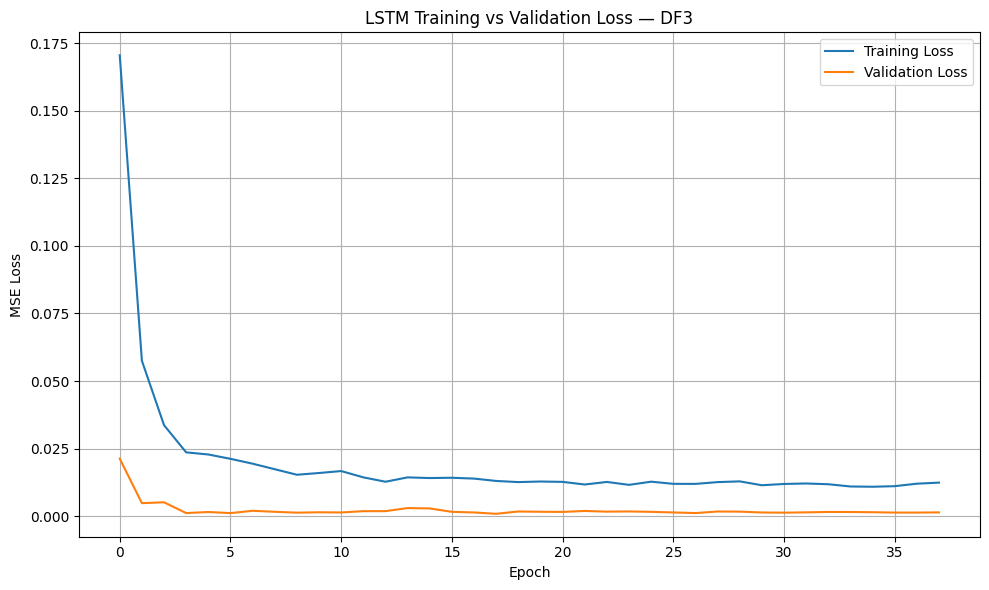

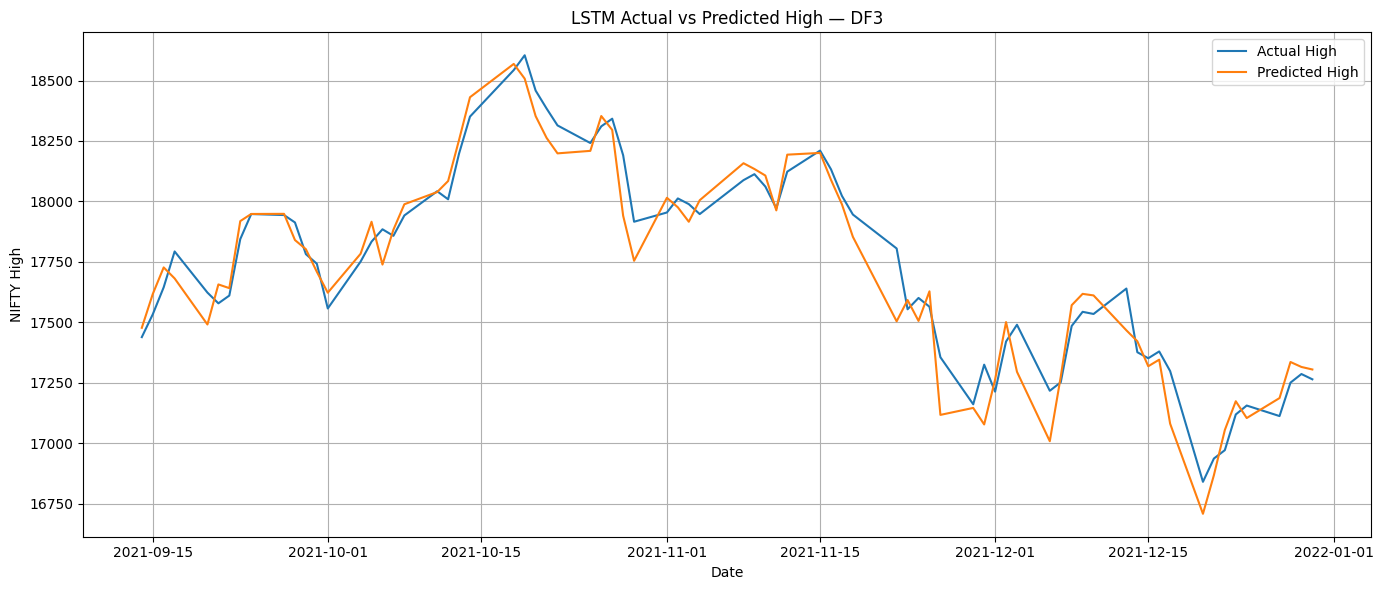

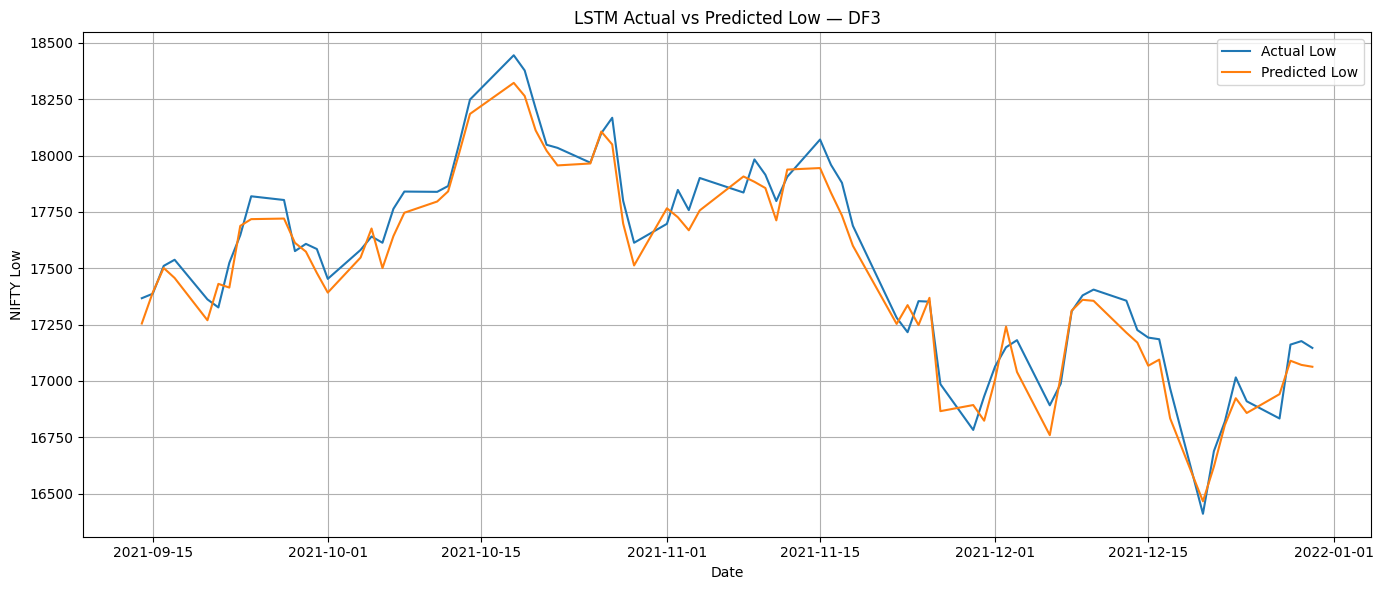

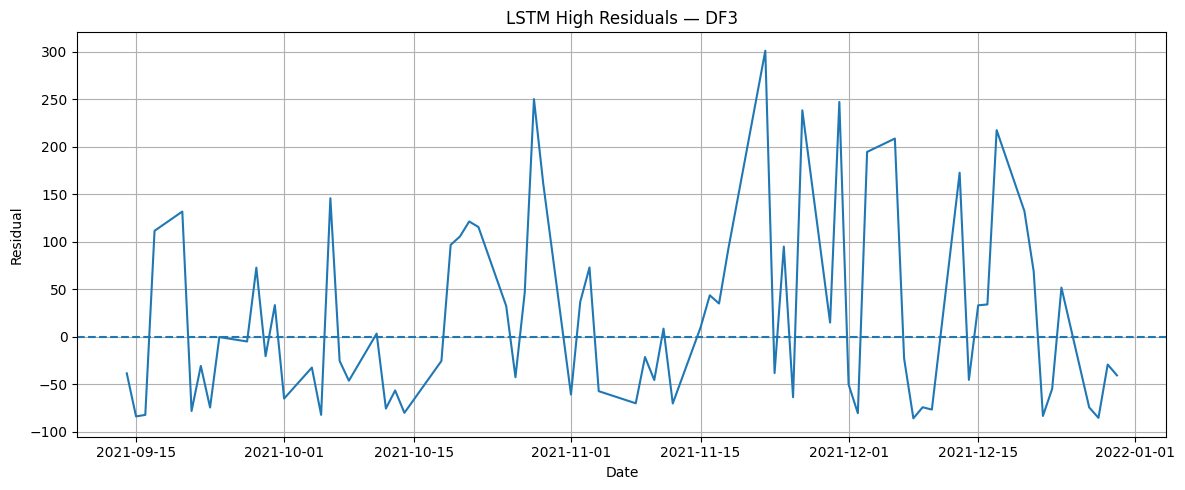

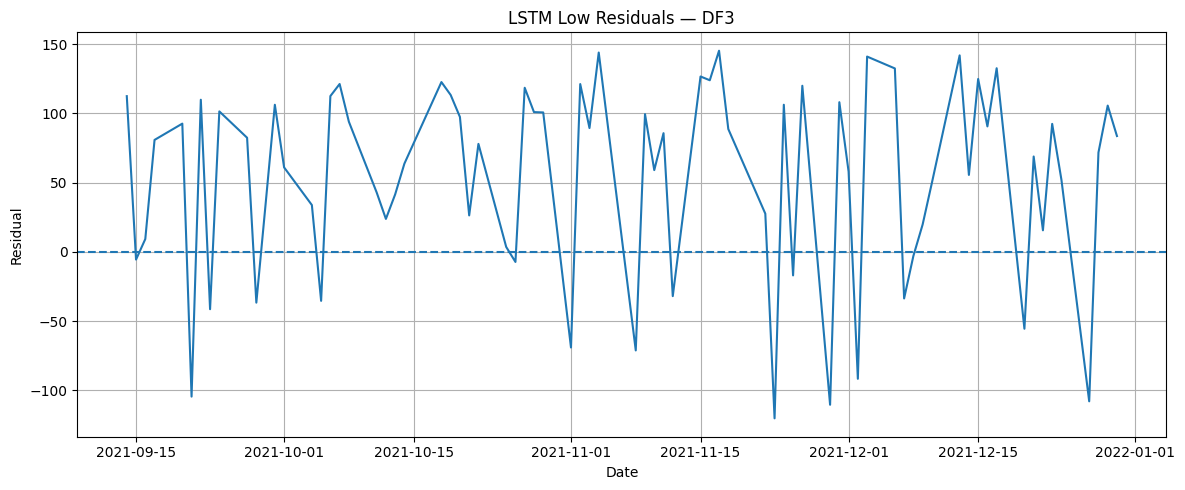

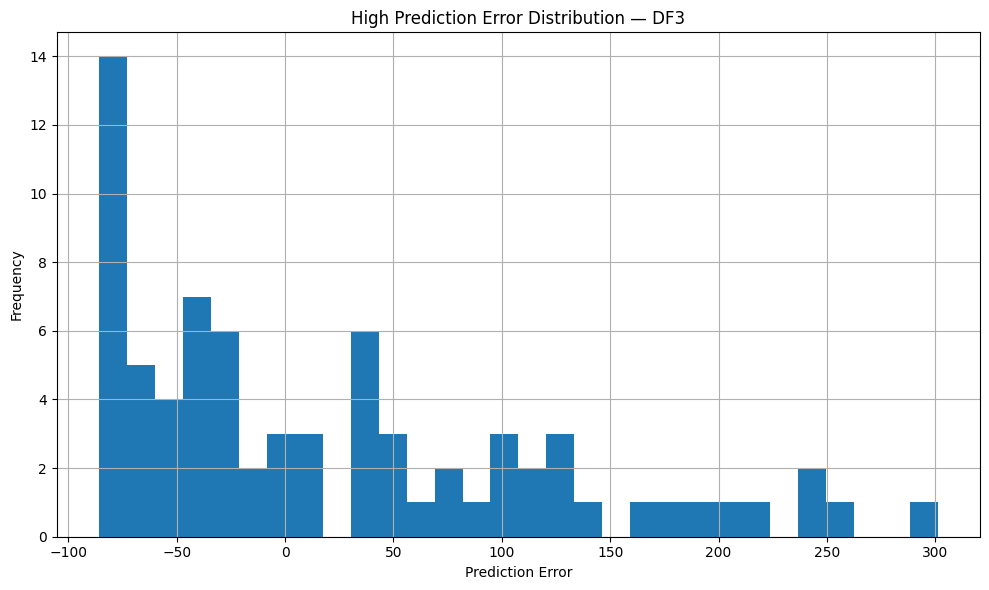

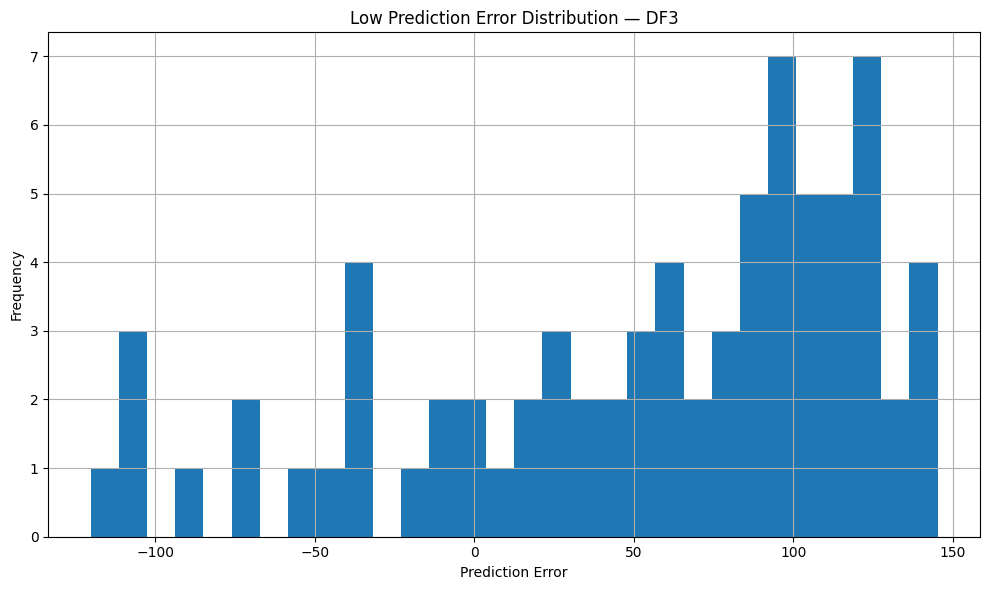


DF3 completed.


RUNNING DF4
2022 - 2025
Regime observations: 963
Train: 673
Validation: 144
Test: 145
X_train: (648, 25, 4)
X_val: (144, 25, 4)
X_test: (145, 25, 4)


Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional_8 (Bidirectional) │ (None, 25, 128)        │        35,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20 (Dropout)            │ (None, 25, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_9 (Bidirectional) │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_21 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 77,618 (303.20 KB)

 Trainable params: 77,618 (303.20 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
21/21 ━━━━━━━━━━━━━━━━━━━━ 7s 70ms/step - loss: 0.1336 - val_loss: 0.0481 - learning_rate: 0.0010
Epoch 2/200
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.1147 - val_loss: 0.0343 - learning_rate: 0.0010
Epoch 3/200
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0430 - val_loss: 0.0116 - learning_rate: 0.0010
Epoch 4/200
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0255 - val_loss: 0.0093 - learning_rate: 0.0010
Epoch 5/200
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0164 - val_loss: 0.0098 - learning_rate: 0.0010
Epoch 6/200
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0165 - val_loss: 0.0095 - learning_rate: 0.0010
Epoch 7/200
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0165 - val_loss: 0.0102 - learning_rate: 0.0010
Epoch 8/200
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0163 - val_loss: 0.0092 - learning_rate: 0.0010
Epoch 9/200
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0136 - val_loss: 0.0092 - learning_rate: 0.0010
Epoch 10/2

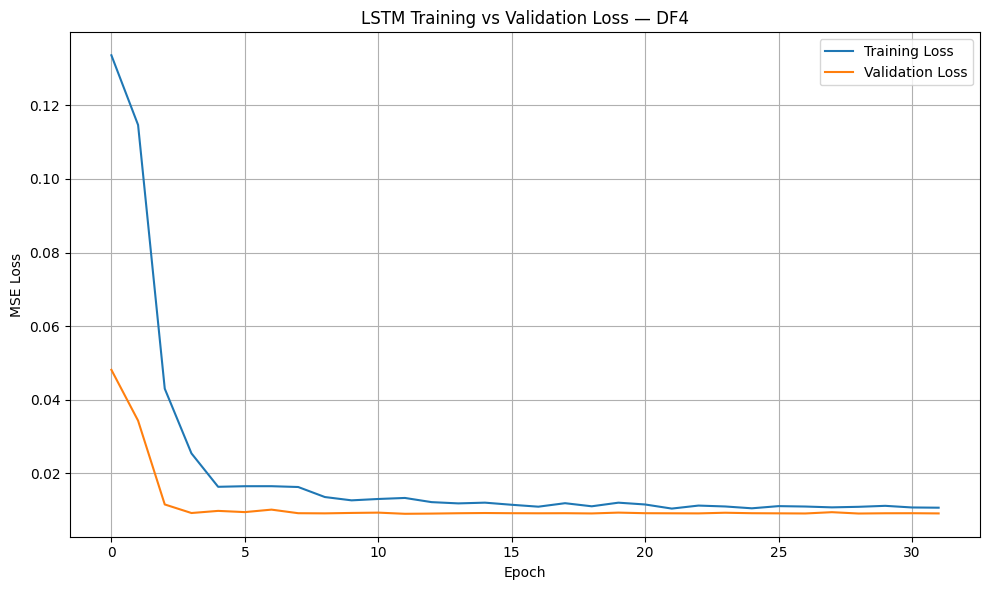

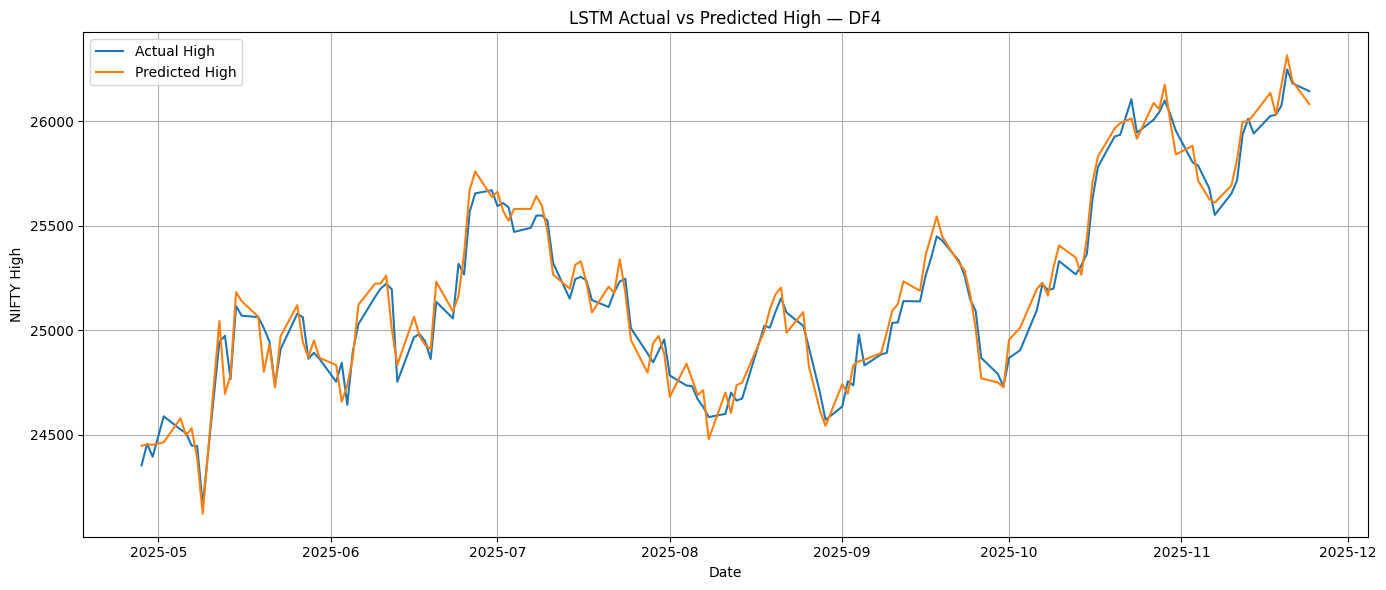

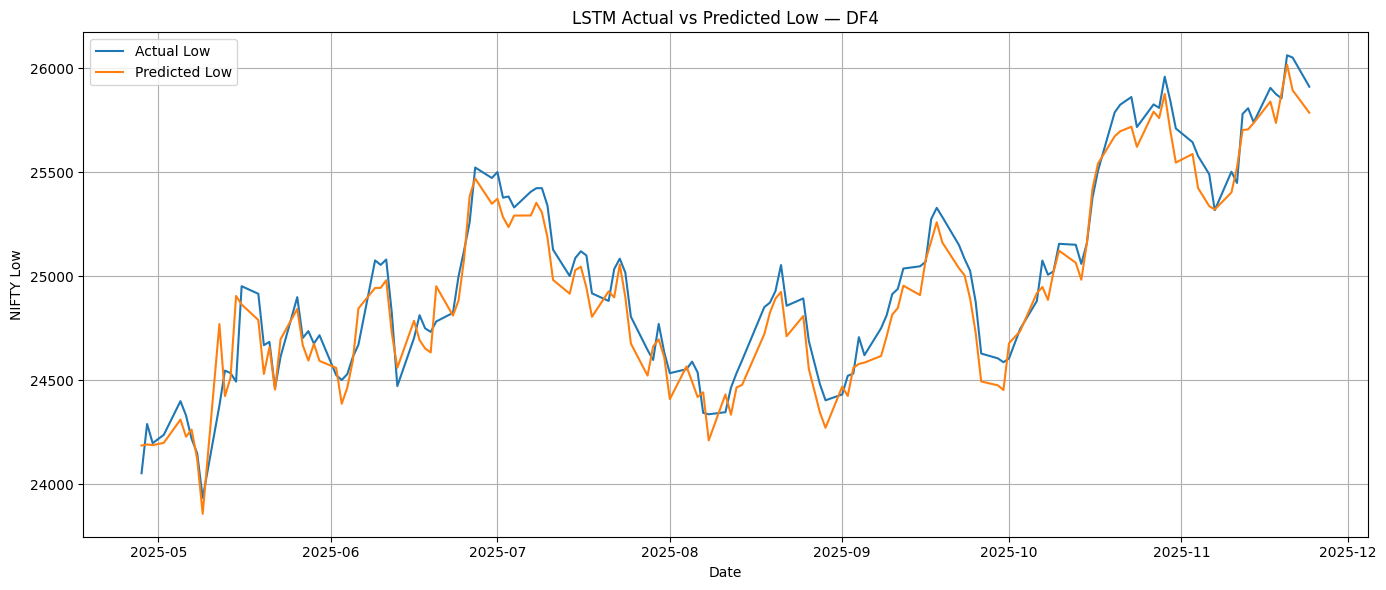

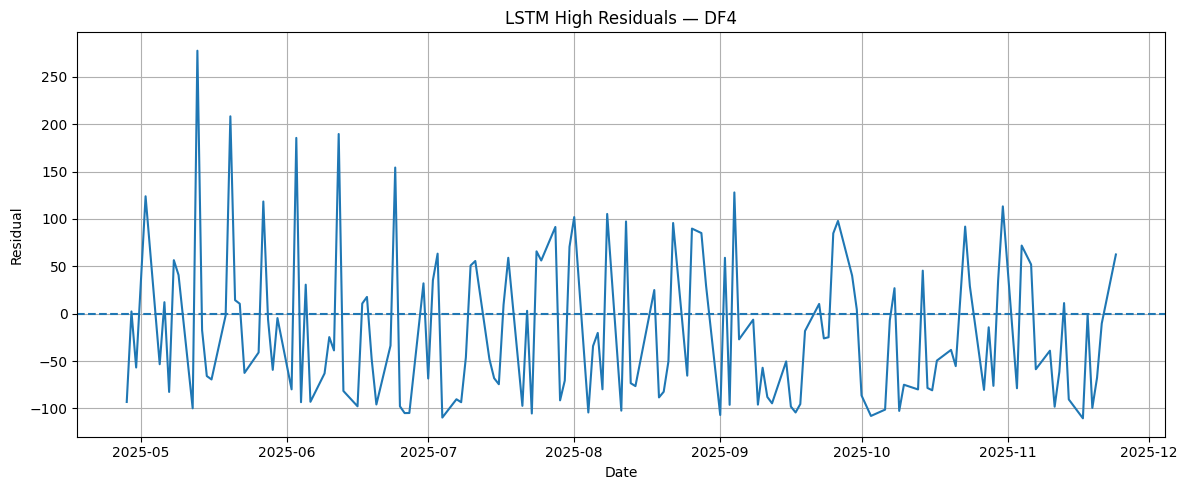

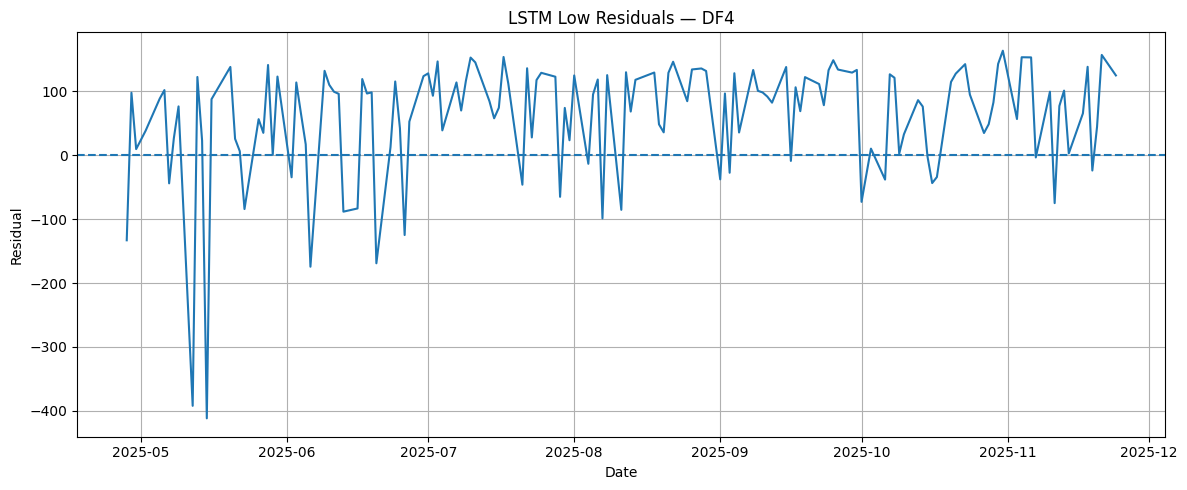

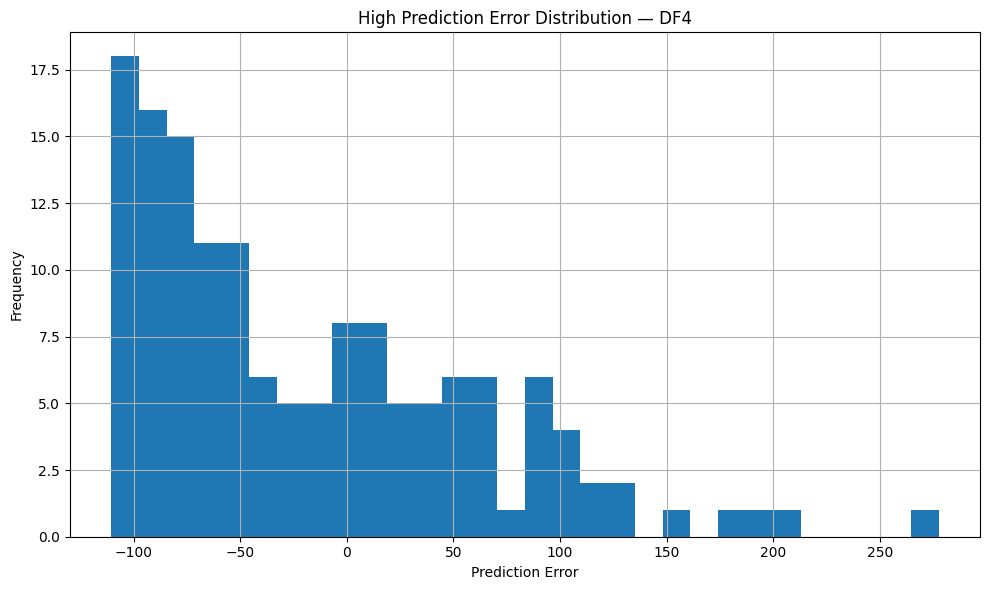

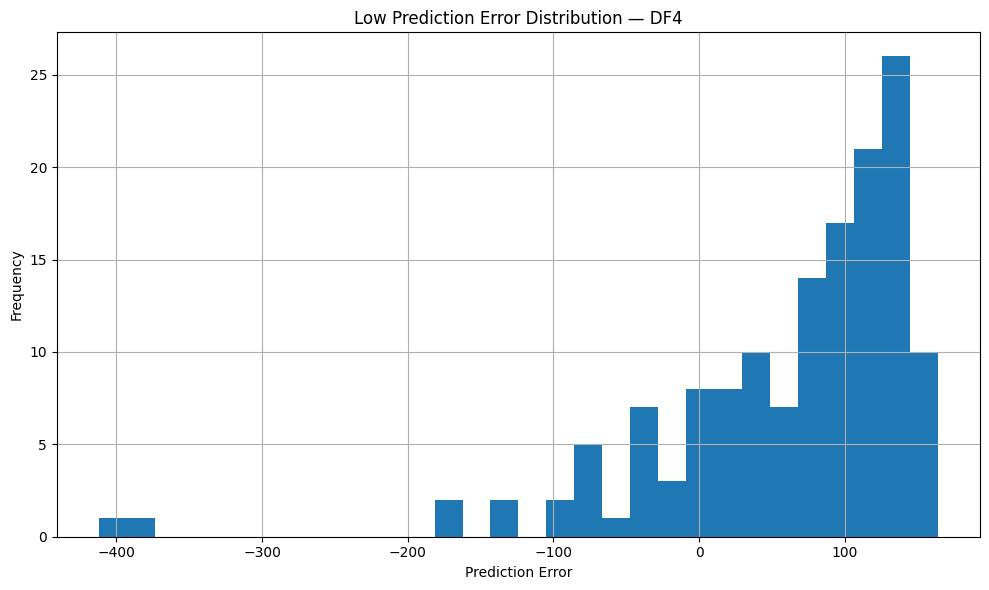


DF4 completed.


FINAL REGIME-WISE LSTM RESULTS
Regime  High_MAE  High_RMSE  High_R2  High_MAPE   Low_MAE   Low_RMSE   Low_R2  Low_MAPE  Train_Observations  Validation_Observations  Test_Observations
   DF1 43.708545  58.655105 0.962900   0.731818 28.356318  41.921145 0.979284  0.489669                 539                      121                122
   DF2 41.685850  57.268647 0.987716   0.368529 38.921457  63.478462 0.985528  0.351948                1509                      329                329
   DF3 78.875653 100.798098 0.939571   0.446005 78.779676  88.306663 0.958259  0.449813                 322                       75                 75
   DF4 68.203251  80.215464 0.969037   0.271137 93.710510 110.050191 0.946612  0.375404                 648                      144                145

Results saved to:
LSTM_Regime_Results


In [26]:
# ============================================================
# NIFTY 50 — REGIME-WISE LSTM
# DF1: 2007-2010
# DF2: 2011-2019
# DF3: 2020-2021
# DF4: 2022-Latest
#
# Each regime is trained and evaluated independently.
# Target:
#   Next-Day High / Current-Day Close
#   Next-Day Low  / Current-Day Close
#
# Split:
#   70% Train
#   15% Validation
#   15% Test
#
# Lookback:
#   25 trading days
# ============================================================

import os
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.layers import LSTM, Bidirectional, Dense, Dropout


# ============================================================
# 1. SETTINGS
# ============================================================

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except:
    pass


DATA_PATH = "nifty50_2007_to_now.csv"

LOOKBACK = 25

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

EPOCHS = 200
BATCH_SIZE = 32

OUTPUT_DIR = "LSTM_Regime_Results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("Seed:", SEED)


# ============================================================
# 2. LOAD DATA
# ============================================================


print("Original shape:", df.shape)

# ------------------------------------------------------------
# Find date column
# ------------------------------------------------------------

possible_date_columns = [
    "Date",
    "date",
    "DATE",
    "Datetime",
    "datetime"
]

date_column = None

for col in possible_date_columns:
    if col in df.columns:
        date_column = col
        break

if date_column is None:
    raise ValueError(
        "Could not find Date column. "
        "Available columns are:\n"
        + str(df.columns.tolist())
    )

df[date_column] = pd.to_datetime(df[date_column], errors="coerce")

df = df.dropna(subset=[date_column])

df = df.sort_values(date_column).reset_index(drop=True)


# ============================================================
# 3. CHECK REQUIRED COLUMNS
# ============================================================

required_columns = [
    "Open",
    "High",
    "Low",
    "Close"
]

missing = [
    col for col in required_columns
    if col not in df.columns
]

if missing:
    raise ValueError(
        f"Missing required columns: {missing}"
    )


# ============================================================
# 4. CLEAN NUMERIC DATA
# ============================================================

for col in required_columns:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

df = df.dropna(
    subset=required_columns
).reset_index(drop=True)


# ============================================================
# 5. DEFINE REGIMES
# ============================================================

df["Year"] = df[date_column].dt.year

regimes = {

    "DF1": {
        "start": 2007,
        "end": 2010
    },

    "DF2": {
        "start": 2011,
        "end": 2019
    },

    "DF3": {
        "start": 2020,
        "end": 2021
    },

    "DF4": {
        "start": 2022,
        "end": df["Year"].max()
    }
}


# ============================================================
# 6. MODEL FUNCTION
# ============================================================

def build_lstm():

    
    model = Sequential([
    Bidirectional(
        LSTM(64, return_sequences=True),
        input_shape=(LOOKBACK, 4)
    ),
    Dropout(0.20),

    Bidirectional(
        LSTM(32)
    ),
    Dropout(0.20),

    Dense(16, activation="relu"),
    Dense(2)
])    

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="mse"
    )

    return model


# ============================================================
# 7. METRICS FUNCTION
# ============================================================

def calculate_metrics(
    actual,
    predicted
):

    mae = mean_absolute_error(
        actual,
        predicted
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )

    r2 = r2_score(
        actual,
        predicted
    )

    # Avoid division by zero
    denominator = np.where(
        np.abs(actual) < 1e-8,
        1e-8,
        np.abs(actual)
    )

    mape = np.mean(
        np.abs(
            (actual - predicted)
            / denominator
        )
    ) * 100

    return mae, rmse, r2, mape


# ============================================================
# 8. STORE ALL RESULTS
# ============================================================

all_results = []


# ============================================================
# 9. RUN EACH REGIME SEPARATELY
# ============================================================

for regime_name, period in regimes.items():

    print("\n")
    print("=" * 70)
    print(f"RUNNING {regime_name}")
    print(
        f"{period['start']} - {period['end']}"
    )
    print("=" * 70)


    # --------------------------------------------------------
    # Extract regime
    # --------------------------------------------------------

    regime_df = df[
        (df["Year"] >= period["start"]) &
        (df["Year"] <= period["end"])
    ].copy()

    regime_df = regime_df.reset_index(drop=True)

    print(
        "Regime observations:",
        len(regime_df)
    )


    # --------------------------------------------------------
    # Check enough data
    # --------------------------------------------------------

    if len(regime_df) <= LOOKBACK + 20:

        print(
            f"Skipping {regime_name}: "
            f"insufficient observations."
        )

        continue


    # --------------------------------------------------------
    # FEATURES
    #
    # We use OHLC from the previous 25 days.
    # --------------------------------------------------------

    features = [
        "Open",
        "High",
        "Low",
        "Close"
    ]

    X_raw = regime_df[
        features
    ].values


    # --------------------------------------------------------
    # TARGET
    #
    # Next-day High / current Close
    # Next-day Low  / current Close
    #
    # y[i] corresponds to day i+1.
    # --------------------------------------------------------

    high_target = (
        regime_df["High"].shift(-1)
        / regime_df["Close"]
    )

    low_target = (
        regime_df["Low"].shift(-1)
        / regime_df["Close"]
    )

    y_raw = np.column_stack([
        high_target.values,
        low_target.values
    ])


    # --------------------------------------------------------
    # Remove final row because it has no next-day target
    # --------------------------------------------------------

    valid_mask = ~np.isnan(y_raw).any(axis=1)

    X_raw = X_raw[valid_mask]
    y_raw = y_raw[valid_mask]

    close_current = regime_df[
        "Close"
    ].values[valid_mask]

    dates = regime_df[
        date_column
    ].values[valid_mask]


    # ========================================================
    # 10. CHRONOLOGICAL SPLIT
    # ========================================================

    n = len(X_raw)

    train_end = int(
        n * TRAIN_RATIO
    )

    val_end = int(
        n * (TRAIN_RATIO + VAL_RATIO)
    )

    print(
        "Train:",
        train_end
    )

    print(
        "Validation:",
        val_end - train_end
    )

    print(
        "Test:",
        n - val_end
    )


    # ========================================================
    # 11. SCALE — TRAIN ONLY
    # ========================================================

    scaler_X = MinMaxScaler()

    scaler_y = MinMaxScaler()


    scaler_X.fit(
        X_raw[:train_end]
    )

    scaler_y.fit(
        y_raw[:train_end]
    )


    X_scaled = scaler_X.transform(
        X_raw
    )

    y_scaled = scaler_y.transform(
        y_raw
    )


    # ========================================================
    # 12. CREATE SEQUENCES
    # ========================================================

    X_sequences = []
    y_sequences = []
    sequence_indices = []

    for i in range(
        LOOKBACK,
        len(X_scaled)
    ):

        X_sequences.append(
            X_scaled[
                i - LOOKBACK:i
            ]
        )

        y_sequences.append(
            y_scaled[i]
        )

        sequence_indices.append(i)


    X_sequences = np.array(
        X_sequences
    )

    y_sequences = np.array(
        y_sequences
    )

    sequence_indices = np.array(
        sequence_indices
    )


    # ========================================================
    # 13. SPLIT SEQUENCES
    # ========================================================

    train_mask = (
        sequence_indices < train_end
    )

    val_mask = (
        (sequence_indices >= train_end) &
        (sequence_indices < val_end)
    )

    test_mask = (
        sequence_indices >= val_end
    )


    X_train = X_sequences[
        train_mask
    ]

    y_train = y_sequences[
        train_mask
    ]

    X_val = X_sequences[
        val_mask
    ]

    y_val = y_sequences[
        val_mask
    ]

    X_test = X_sequences[
        test_mask
    ]

    y_test = y_sequences[
        test_mask
    ]


    print(
        "X_train:",
        X_train.shape
    )

    print(
        "X_val:",
        X_val.shape
    )

    print(
        "X_test:",
        X_test.shape
    )


    # ========================================================
    # 14. BUILD MODEL
    # ========================================================

    model = build_lstm()

    model.summary()


    # ========================================================
    # 15. CALLBACKS
    # ========================================================

    early_stopping = EarlyStopping(

        monitor="val_loss",

        patience=20,

        restore_best_weights=True,

        verbose=1
    )


    reduce_lr = ReduceLROnPlateau(

        monitor="val_loss",

        factor=0.5,

        patience=8,

        min_lr=1e-6,

        verbose=1
    )


    # ========================================================
    # 16. TRAIN
    # ========================================================

    history = model.fit(

        X_train,

        y_train,

        validation_data=(
            X_val,
            y_val
        ),

        epochs=EPOCHS,

        batch_size=BATCH_SIZE,

        shuffle=False,

        callbacks=[
            early_stopping,
            reduce_lr
        ],

        verbose=1
    )


    # ========================================================
    # 17. PREDICT TEST
    # ========================================================

    y_pred_scaled = model.predict(
        X_test,
        verbose=0
    )


    # ========================================================
    # 18. INVERSE TRANSFORM
    # ========================================================

    y_pred_ratio = scaler_y.inverse_transform(
        y_pred_scaled
    )

    y_test_ratio = scaler_y.inverse_transform(
        y_test
    )


    # ========================================================
    # 19. GET TEST CLOSE VALUES
    # ========================================================

    test_indices = sequence_indices[
        test_mask
    ]

    test_close = close_current[
        test_indices
    ]

    test_dates = dates[
        test_indices
    ]


    # ========================================================
    # 20. RECONSTRUCT ABSOLUTE HIGH / LOW
    # ========================================================

    predicted_high = (
        y_pred_ratio[:, 0]
        * test_close
    )

    predicted_low = (
        y_pred_ratio[:, 1]
        * test_close
    )


    actual_high = regime_df[
        "High"
    ].values[test_indices]

    actual_low = regime_df[
        "Low"
    ].values[test_indices]


    # ========================================================
    # 21. METRICS
    # ========================================================

    high_mae, high_rmse, high_r2, high_mape = \
        calculate_metrics(
            actual_high,
            predicted_high
        )


    low_mae, low_rmse, low_r2, low_mape = \
        calculate_metrics(
            actual_low,
            predicted_low
        )


    print("\n")
    print("=" * 60)
    print(f"{regime_name} RESULTS")
    print("=" * 60)

    print("\nHIGH")
    print(
        f"MAE  : {high_mae:.4f}"
    )
    print(
        f"RMSE : {high_rmse:.4f}"
    )
    print(
        f"R²   : {high_r2:.4f}"
    )
    print(
        f"MAPE : {high_mape:.4f}%"
    )

    print("\nLOW")
    print(
        f"MAE  : {low_mae:.4f}"
    )
    print(
        f"RMSE : {low_rmse:.4f}"
    )
    print(
        f"R²   : {low_r2:.4f}"
    )
    print(
        f"MAPE : {low_mape:.4f}%"
    )


    # ========================================================
    # 22. SAVE METRICS
    # ========================================================

    all_results.append({

        "Regime": regime_name,

        "High_MAE": high_mae,
        "High_RMSE": high_rmse,
        "High_R2": high_r2,
        "High_MAPE": high_mape,

        "Low_MAE": low_mae,
        "Low_RMSE": low_rmse,
        "Low_R2": low_r2,
        "Low_MAPE": low_mape,

        "Train_Observations": len(X_train),

        "Validation_Observations": len(X_val),

        "Test_Observations": len(X_test)
    })


    # ========================================================
    # 23. SAVE PREDICTIONS
    # ========================================================

    prediction_df = pd.DataFrame({

        "Date": test_dates,

        "Actual_High":
            actual_high,

        "Predicted_High":
            predicted_high,

        "Actual_Low":
            actual_low,

        "Predicted_Low":
            predicted_low,

        "Actual_High_Ratio":
            y_test_ratio[:, 0],

        "Predicted_High_Ratio":
            y_pred_ratio[:, 0],

        "Actual_Low_Ratio":
            y_test_ratio[:, 1],

        "Predicted_Low_Ratio":
            y_pred_ratio[:, 1],

        "Close_t":
            test_close
    })


    prediction_path = os.path.join(
        OUTPUT_DIR,
        f"{regime_name}_Predictions.csv"
    )

    prediction_df.to_csv(
        prediction_path,
        index=False
    )


    # ========================================================
    # 24. TRAINING / VALIDATION LOSS
    # ========================================================

    plt.figure(
        figsize=(10, 6)
    )

    plt.plot(
        history.history["loss"],
        label="Training Loss"
    )

    plt.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("MSE Loss")

    plt.title(
        f"LSTM Training vs Validation Loss — {regime_name}"
    )

    plt.legend()

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_Loss.png"
        ),
        dpi=300
    )

    plt.show()


    # ========================================================
    # 25. ACTUAL VS PREDICTED — HIGH
    # ========================================================

    plt.figure(
        figsize=(14, 6)
    )

    plt.plot(
        test_dates,
        actual_high,
        label="Actual High"
    )

    plt.plot(
        test_dates,
        predicted_high,
        label="Predicted High"
    )

    plt.xlabel("Date")

    plt.ylabel("NIFTY High")

    plt.title(
        f"LSTM Actual vs Predicted High — {regime_name}"
    )

    plt.legend()

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_High_Actual_vs_Predicted.png"
        ),
        dpi=300
    )

    plt.show()


    # ========================================================
    # 26. ACTUAL VS PREDICTED — LOW
    # ========================================================

    plt.figure(
        figsize=(14, 6)
    )

    plt.plot(
        test_dates,
        actual_low,
        label="Actual Low"
    )

    plt.plot(
        test_dates,
        predicted_low,
        label="Predicted Low"
    )

    plt.xlabel("Date")

    plt.ylabel("NIFTY Low")

    plt.title(
        f"LSTM Actual vs Predicted Low — {regime_name}"
    )

    plt.legend()

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_Low_Actual_vs_Predicted.png"
        ),
        dpi=300
    )

    plt.show()


    # ========================================================
    # 27. HIGH RESIDUALS
    # ========================================================

    high_residuals = (
        actual_high -
        predicted_high
    )

    plt.figure(
        figsize=(12, 5)
    )

    plt.plot(
        test_dates,
        high_residuals
    )

    plt.axhline(
        0,
        linestyle="--"
    )

    plt.xlabel("Date")

    plt.ylabel("Residual")

    plt.title(
        f"LSTM High Residuals — {regime_name}"
    )

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_High_Residuals.png"
        ),
        dpi=300
    )

    plt.show()


    # ========================================================
    # 28. LOW RESIDUALS
    # ========================================================

    low_residuals = (
        actual_low -
        predicted_low
    )

    plt.figure(
        figsize=(12, 5)
    )

    plt.plot(
        test_dates,
        low_residuals
    )

    plt.axhline(
        0,
        linestyle="--"
    )

    plt.xlabel("Date")

    plt.ylabel("Residual")

    plt.title(
        f"LSTM Low Residuals — {regime_name}"
    )

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_Low_Residuals.png"
        ),
        dpi=300
    )

    plt.show()


    # ========================================================
    # 29. ERROR DISTRIBUTIONS
    # ========================================================

    plt.figure(
        figsize=(10, 6)
    )

    plt.hist(
        high_residuals,
        bins=30
    )

    plt.xlabel("Prediction Error")

    plt.ylabel("Frequency")

    plt.title(
        f"High Prediction Error Distribution — {regime_name}"
    )

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_High_Error_Distribution.png"
        ),
        dpi=300
    )

    plt.show()


    plt.figure(
        figsize=(10, 6)
    )

    plt.hist(
        low_residuals,
        bins=30
    )

    plt.xlabel("Prediction Error")

    plt.ylabel("Frequency")

    plt.title(
        f"Low Prediction Error Distribution — {regime_name}"
    )

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_Low_Error_Distribution.png"
        ),
        dpi=300
    )

    plt.show()


    # ========================================================
    # 30. SAVE MODEL
    # ========================================================

    model.save(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_LSTM.keras"
        )
    )

    print(
        f"\n{regime_name} completed."
    )


# ============================================================
# 31. FINAL RESULTS TABLE
# ============================================================

results_df = pd.DataFrame(
    all_results
)

print("\n")
print("=" * 80)
print("FINAL REGIME-WISE LSTM RESULTS")
print("=" * 80)

print(
    results_df.to_string(
        index=False
    )
)


# ============================================================
# 32. SAVE FINAL RESULTS
# ============================================================

results_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "LSTM_Regime_Results.csv"
    ),
    index=False
)

results_df.to_excel(
    os.path.join(
        OUTPUT_DIR,
        "LSTM_Regime_Results.xlsx"
    ),
    index=False
)


print("\nResults saved to:")
print(OUTPUT_DIR)

In [41]:

df = df.rename(columns={df.columns[0]: "Date"})


df["Date"] = pd.to_datetime(df["Date"], errors="coerce")


df = df.dropna(subset=["Date"])


for col in df.columns:
    if col != "Date":
        df[col] = pd.to_numeric(df[col], errors="coerce")


df = df.ffill().bfill()

df = df.set_index("Date")

print(df.head())
print(df.dtypes)

# Regime splitting
df1 = df.loc[: "2010-12-31"]              # Pre-2011
df2 = df.loc["2011-01-01":"2019-12-31"]   # 2011–2019
df3 = df.loc["2020-01-01":"2021-12-31"]   # COVID period
df4 = df.loc["2022-01-01":]               # 2022 onward

# Print sizes
print("\nSizes of each segment:")
print("df1 (2007–2010):", len(df1))
print("df2 (2011–2019):", len(df2))
print("df3 (2020–2021):", len(df3))
print("df4 (2022–present):", len(df4))


                   Open         High          Low        Close  Regime  \
Date                                                                     
2007-09-18  4494.100098  4551.799805  4481.549805  4546.200195     NaN   
2007-09-19  4550.250000  4739.000000  4550.250000  4732.350098     NaN   
2007-09-20  4734.850098  4760.850098  4721.149902  4747.549805     NaN   
2007-09-21  4752.950195  4855.700195  4733.700195  4837.549805     NaN   
2007-09-24  4837.149902  4941.149902  4837.149902  4932.200195     NaN   

            Target_High_Ratio  Target_Low_Ratio  Target_High  Target_Low  
Date                                                                      
2007-09-18           1.042409          1.000891     1.042409    1.000891  
2007-09-19           1.006022          0.997633     1.006022    0.997633  
2007-09-20           1.022780          0.997083     1.022780    0.997083  
2007-09-21           1.021416          0.999917     1.021416    0.999917  
2007-09-24           1.004400  

TensorFlow: 2.17.0
Seed: 42

Original dataframe shape:
(4462, 6)

Original columns:
['Date', 'Close', 'High', 'Low', 'Open', 'Volume']

Invalid dates: 0

Missing OHLC values before cleaning:
Open     0
High     0
Low      0
Close    0
dtype: int64


CLEAN DATASET INFORMATION
Start date: 2007-09-17 00:00:00
End date: 2025-11-25 00:00:00
Total observations: 4462


REGIME DISTRIBUTION
Regime
DF1     808
DF2    2193
DF3     498
DF4     963
Name: count, dtype: int64
DF1: 808 observations
DF2: 2193 observations
DF3: 498 observations
DF4: 963 observations


REGIMES AFTER TARGET CREATION
Regime
DF1     808
DF2    2193
DF3     498
DF4     962
Name: count, dtype: int64



##########################################################################################
STARTING DF1
##########################################################################################

DF1 observations: 808
Train observations: 565
Validation observations: 121
Test observations: 122

Sequence shapes:
X_train: (540, 25

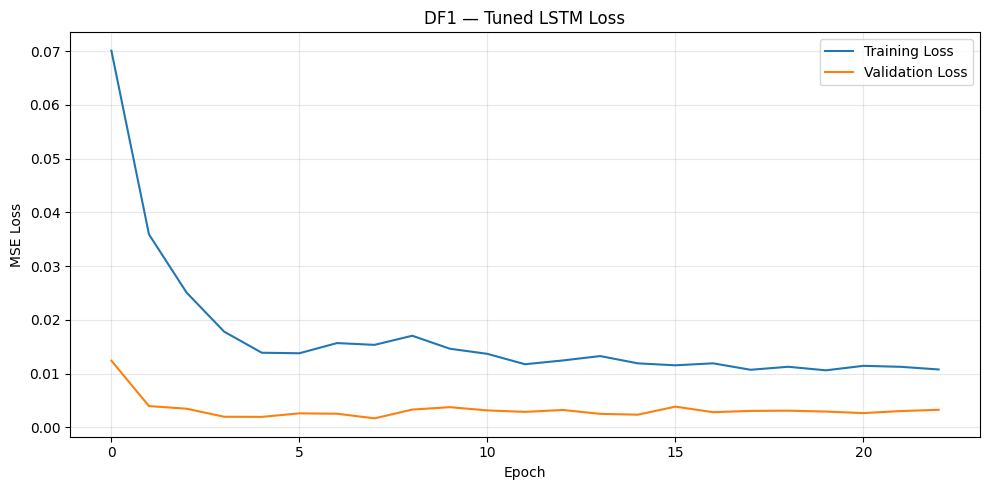



FINAL TEST RESULTS — DF1
High MAE  : 28.9749
High RMSE : 35.8795
High R²   : 0.9859
High MAPE : 0.4946%

Low MAE   : 42.0237
Low RMSE  : 48.1290
Low R²    : 0.9723
Low MAPE  : 0.7204%



##########################################################################################
STARTING DF2
##########################################################################################

DF2 observations: 2193
Train observations: 1535
Validation observations: 329
Test observations: 329

Sequence shapes:
X_train: (1510, 25, 4)
y_train: (1510, 2)
X_val: (329, 25, 4)
y_val: (329, 2)
X_test: (329, 25, 4)
y_test: (329, 2)


------------------------------------------------------------------------------------------
RUNNING 20 RANDOM SEARCH TRIALS
------------------------------------------------------------------------------------------

DF2 | Trial 1/20
Parameters: {'units_1': 64, 'units_2': 16, 'n_layers': 1, 'dropout': 0.2, 'dense_units': 32, 'learning_rate': 0.0005, 'batch_size': 16}
Validation 

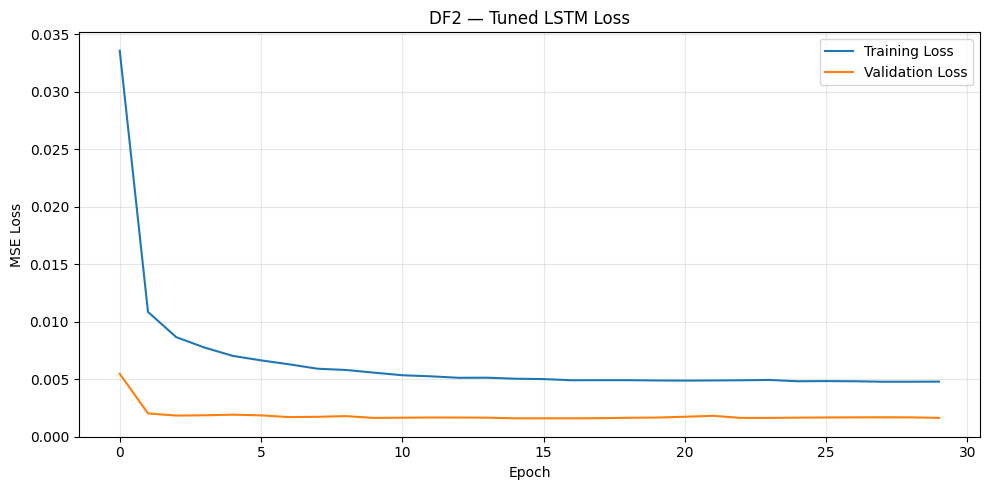



FINAL TEST RESULTS — DF2
High MAE  : 41.5604
High RMSE : 56.4930
High R²   : 0.9882
High MAPE : 0.3672%

Low MAE   : 39.5832
Low RMSE  : 65.5706
Low R²    : 0.9847
Low MAPE  : 0.3578%



##########################################################################################
STARTING DF3
##########################################################################################

DF3 observations: 498
Train observations: 348
Validation observations: 75
Test observations: 75

Sequence shapes:
X_train: (323, 25, 4)
y_train: (323, 2)
X_val: (75, 25, 4)
y_val: (75, 2)
X_test: (75, 25, 4)
y_test: (75, 2)


------------------------------------------------------------------------------------------
RUNNING 20 RANDOM SEARCH TRIALS
------------------------------------------------------------------------------------------

DF3 | Trial 1/20
Parameters: {'units_1': 64, 'units_2': 16, 'n_layers': 2, 'dropout': 0.3, 'dense_units': 32, 'learning_rate': 0.002, 'batch_size': 32}
Validation loss: 0.002

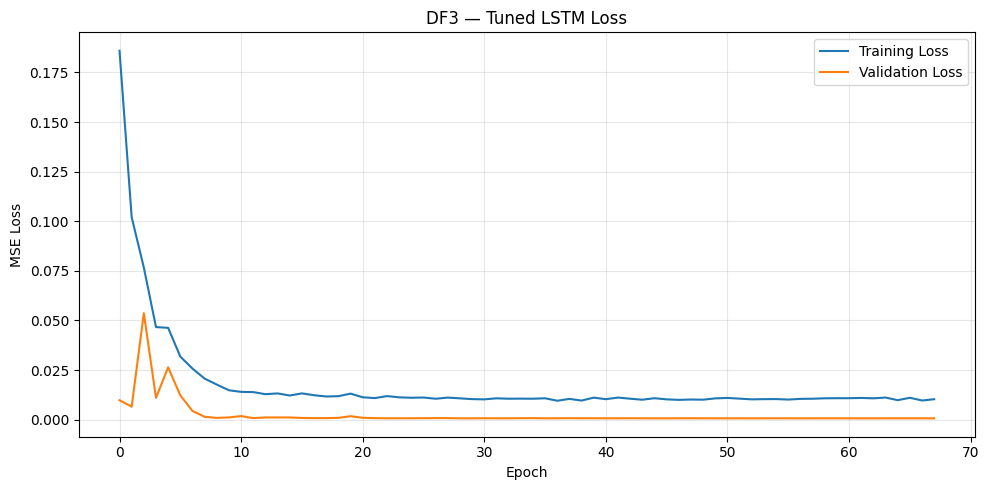



FINAL TEST RESULTS — DF3
High MAE  : 78.6024
High RMSE : 98.0218
High R²   : 0.9430
High MAPE : 0.4446%

Low MAE   : 70.6250
Low RMSE  : 95.8260
Low R²    : 0.9510
Low MAPE  : 0.4045%



##########################################################################################
STARTING DF4
##########################################################################################

DF4 observations: 962
Train observations: 673
Validation observations: 144
Test observations: 145

Sequence shapes:
X_train: (648, 25, 4)
y_train: (648, 2)
X_val: (144, 25, 4)
y_val: (144, 2)
X_test: (145, 25, 4)
y_test: (145, 2)


------------------------------------------------------------------------------------------
RUNNING 20 RANDOM SEARCH TRIALS
------------------------------------------------------------------------------------------

DF4 | Trial 1/20
Parameters: {'units_1': 32, 'units_2': 32, 'n_layers': 2, 'dropout': 0.1, 'dense_units': 16, 'learning_rate': 0.0005, 'batch_size': 32}
Validation loss

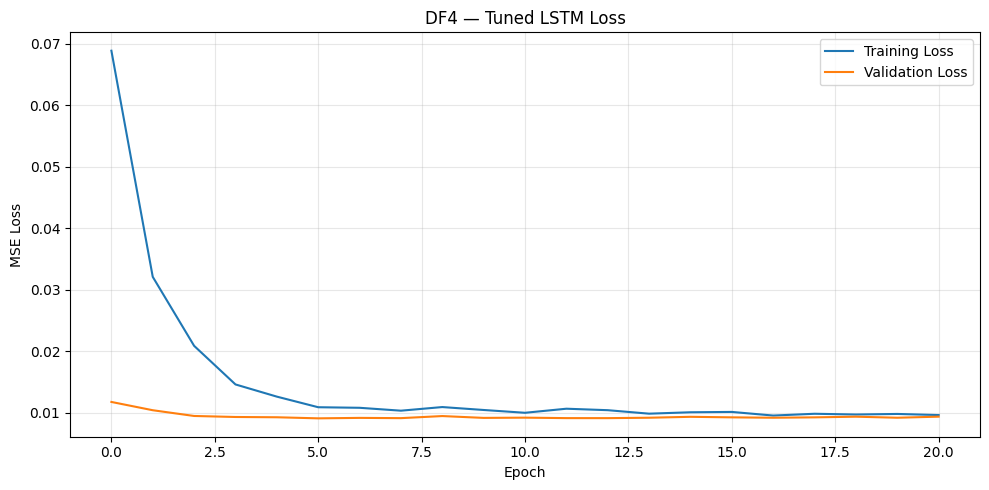



FINAL TEST RESULTS — DF4
High MAE  : 74.9275
High RMSE : 86.8924
High R²   : 0.9637
High MAPE : 0.2977%

Low MAE   : 107.5987
Low RMSE  : 123.2299
Low R²    : 0.9331
Low MAPE  : 0.4306%



####################################################################################################
FINAL TUNED LSTM RESULTS
####################################################################################################


,Regime,High_MAE,High_RMSE,High_R2,High_MAPE,Low_MAE,Low_RMSE,Low_R2,Low_MAPE,Best_Validation_Loss,...,Validation_Observations,Test_Observations,Lookback,Units_1,Units_2,N_Layers,Dropout,Dense_Units,Learning_Rate,Batch_Size
0,DF1,28.974926,35.879469,0.985893,0.494635,42.023706,48.129030,0.972269,0.720436,0.001659,...,121,122,25,128,16,2,0.1,8,0.0005,16
1,DF2,41.560390,56.492973,0.988155,0.367237,39.583159,65.570590,0.984698,0.357791,0.001585,...,329,329,25,64,64,2,0.2,32,0.0020,16
2,DF3,78.602422,98.021825,0.942962,0.444628,70.625026,95.825977,0.951045,0.404506,0.000676,...,75,75,25,128,16,1,0.2,32,0.0010,32
3,DF4,74.927465,86.892379,0.963667,0.297727,107.598680,123.229906,0.933059,0.430553,0.009068,...,144,145,25,64,64,2,0.2,32,0.0020,16





####################################################################################################
SELECTED HYPERPARAMETERS
####################################################################################################


,Regime,Best_Validation_Loss,Units_1,Units_2,N_Layers,Dropout,Dense_Units,Learning_Rate,Batch_Size
0,DF1,0.001659,128,16,2,0.1,8,0.0005,16
1,DF2,0.001585,64,64,2,0.2,32,0.0020,16
2,DF3,0.000676,128,16,1,0.2,32,0.0010,32
3,DF4,0.009068,64,64,2,0.2,32,0.0020,16




####################################################################################################
HYPERPARAMETER TUNING COMPLETED
####################################################################################################

Report:
LSTM_Hyperparameter_Tuning/LSTM_Hyperparameter_Tuning_Report.xlsx

Models:
LSTM_Hyperparameter_Tuning/models/

Predictions:
LSTM_Hyperparameter_Tuning/predictions/

Plots:
LSTM_Hyperparameter_Tuning/plots/

Final test performance:


,Regime,High_MAE,High_RMSE,High_R2,High_MAPE,Low_MAE,Low_RMSE,Low_R2,Low_MAPE
0,DF1,28.974926,35.879469,0.985893,0.494635,42.023706,48.129030,0.972269,0.720436
1,DF2,41.560390,56.492973,0.988155,0.367237,39.583159,65.570590,0.984698,0.357791
2,DF3,78.602422,98.021825,0.942962,0.444628,70.625026,95.825977,0.951045,0.404506
3,DF4,74.927465,86.892379,0.963667,0.297727,107.598680,123.229906,0.933059,0.430553


In [49]:
# ============================================================
# NIFTY 50 — REGIME-WISE LSTM HYPERPARAMETER TUNING
# ============================================================
#
# DF1 = 2007-2010
# DF2 = 2011-2019
# DF3 = 2020-2021
# DF4 = 2022-latest
#
# Input:
#   Open, High, Low, Close
#
# Target:
#   Next-Day High / Current-Day Close
#   Next-Day Low  / Current-Day Close
#
# Split:
#   70% Train
#   15% Validation
#   15% Test
#
# Hyperparameter selection:
#   Validation set ONLY
#
# Final evaluation:
#   Test set ONLY
#
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import os
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    LSTM,
    Dense,
    Dropout
)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

from tensorflow.keras.optimizers import Adam

warnings.filterwarnings("ignore")


# ============================================================
# 2. REPRODUCIBILITY
# ============================================================

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ["TF_DETERMINISTIC_OPS"] = "1"

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Seed:", SEED)


# ============================================================
# 3. SETTINGS
# ============================================================

LOOKBACK = 25

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

N_TRIALS = 20

MAX_EPOCHS = 150

FEATURES = [
    "Open",
    "High",
    "Low",
    "Close"
]

TARGETS = [
    "Target_High",
    "Target_Low"
]


# ============================================================
# 4. IMPORTANT:
#    CHECK THAT df EXISTS
# ============================================================

if "df" not in globals():

    raise NameError(
        """
        DataFrame 'df' was not found.

        Load your NIFTY 50 dataset into a dataframe called 'df'
        before running this code.
        """
    )


# ============================================================
# 5. START WITH A CLEAN COPY
# ============================================================

data = df.copy()

print("\nOriginal dataframe shape:")
print(data.shape)

print("\nOriginal columns:")
print(data.columns.tolist())


# ============================================================
# 6. FIND DATE COLUMN
# ============================================================

possible_date_columns = [
    "Date",
    "date",
    "DATE",
    "Datetime",
    "datetime"
]

date_column = None

for col in possible_date_columns:

    if col in data.columns:

        date_column = col
        break


if date_column is None:

    raise ValueError(
        """
        No Date column was found.

        Expected one of:
        Date
        date
        DATE
        Datetime
        datetime
        """
    )


# Rename to Date
if date_column != "Date":

    data = data.rename(
        columns={
            date_column: "Date"
        }
    )


# ============================================================
# 7. CHECK OHLC COLUMNS
# ============================================================

required_columns = [
    "Date",
    "Open",
    "High",
    "Low",
    "Close"
]

missing_columns = [
    col
    for col in required_columns
    if col not in data.columns
]

if missing_columns:

    raise ValueError(
        f"Missing columns: {missing_columns}"
    )


# ============================================================
# 8. DATE CONVERSION
# ============================================================

data["Date"] = pd.to_datetime(
    data["Date"],
    errors="coerce"
)

print(
    "\nInvalid dates:",
    data["Date"].isna().sum()
)


# Remove invalid dates
data = data.dropna(
    subset=["Date"]
).copy()


# ============================================================
# 9. SORT CHRONOLOGICALLY
# ============================================================

data = (
    data
    .sort_values("Date")
    .reset_index(drop=True)
)


# ============================================================
# 10. NUMERIC OHLC CONVERSION
# ============================================================

for col in [
    "Open",
    "High",
    "Low",
    "Close"
]:

    data[col] = pd.to_numeric(
        data[col],
        errors="coerce"
    )


# ============================================================
# 11. REMOVE INVALID OHLC ROWS
# ============================================================

print(
    "\nMissing OHLC values before cleaning:"
)

print(
    data[
        [
            "Open",
            "High",
            "Low",
            "Close"
        ]
    ].isna().sum()
)


data = data.dropna(
    subset=[
        "Open",
        "High",
        "Low",
        "Close"
    ]
).reset_index(
    drop=True
)


# ============================================================
# 12. SHOW ACTUAL DATE RANGE
# ============================================================

print("\n")
print("=" * 70)
print("CLEAN DATASET INFORMATION")
print("=" * 70)

print(
    "Start date:",
    data["Date"].min()
)

print(
    "End date:",
    data["Date"].max()
)

print(
    "Total observations:",
    len(data)
)


# ============================================================
# 13. CREATE REGIMES
# ============================================================

def assign_regime(date):

    year = date.year

    if 2007 <= year <= 2010:

        return "DF1"

    elif 2011 <= year <= 2019:

        return "DF2"

    elif 2020 <= year <= 2021:

        return "DF3"

    elif year >= 2022:

        return "DF4"

    else:

        return np.nan


data["Regime"] = (
    data["Date"]
    .apply(assign_regime)
)


# ============================================================
# 14. CRITICAL REGIME CHECK
# ============================================================

print("\n")
print("=" * 70)
print("REGIME DISTRIBUTION")
print("=" * 70)

regime_counts = (
    data["Regime"]
    .value_counts()
    .sort_index()
)

print(
    regime_counts
)


# Explicitly check each regime
for regime in [
    "DF1",
    "DF2",
    "DF3",
    "DF4"
]:

    count = (
        data["Regime"]
        .eq(regime)
        .sum()
    )

    print(
        f"{regime}: {count} observations"
    )


# ============================================================
# 15. STOP IF A REGIME IS EMPTY
# ============================================================

required_regimes = [
    "DF1",
    "DF2",
    "DF3",
    "DF4"
]

empty_regimes = []

for regime in required_regimes:

    if (
        data["Regime"]
        .eq(regime)
        .sum()
        == 0
    ):

        empty_regimes.append(
            regime
        )


if empty_regimes:

    raise ValueError(
        f"""
        EMPTY REGIME DETECTED: {empty_regimes}

        Your current dataframe does not contain observations
        for these regimes.

        Check the date range printed above.

        Expected:
        DF1 = 2007-2010
        DF2 = 2011-2019
        DF3 = 2020-2021
        DF4 = 2022-latest
        """
    )


# ============================================================
# 16. CREATE NORMALIZED TARGETS
# ============================================================

data["Target_High"] = (
    data["High"].shift(-1)
    /
    data["Close"]
)

data["Target_Low"] = (
    data["Low"].shift(-1)
    /
    data["Close"]
)


# ============================================================
# 17. IMPORTANT:
#    REMOVE ONLY ROWS WITH MISSING TARGET
# ============================================================

data = data.dropna(
    subset=[
        "Target_High",
        "Target_Low"
    ]
).reset_index(
    drop=True
)


# ============================================================
# 18. CHECK REGIMES AGAIN
# ============================================================

print("\n")
print("=" * 70)
print("REGIMES AFTER TARGET CREATION")
print("=" * 70)

print(
    data["Regime"]
    .value_counts()
    .sort_index()
)


# ============================================================
# 19. HYPERPARAMETER SEARCH SPACE
# ============================================================

SEARCH_SPACE = {

    "units_1": [
        32,
        64,
        128
    ],

    "units_2": [
        16,
        32,
        64
    ],

    "n_layers": [
        1,
        2
    ],

    "dropout": [
        0.10,
        0.20,
        0.30
    ],

    "dense_units": [
        8,
        16,
        32
    ],

    "learning_rate": [
        0.0005,
        0.001,
        0.002
    ],

    "batch_size": [
        16,
        32
    ]
}


# ============================================================
# 20. RANDOM PARAMETER GENERATOR
# ============================================================

def sample_hyperparameters():

    return {

        "units_1":
            random.choice(
                SEARCH_SPACE[
                    "units_1"
                ]
            ),

        "units_2":
            random.choice(
                SEARCH_SPACE[
                    "units_2"
                ]
            ),

        "n_layers":
            random.choice(
                SEARCH_SPACE[
                    "n_layers"
                ]
            ),

        "dropout":
            random.choice(
                SEARCH_SPACE[
                    "dropout"
                ]
            ),

        "dense_units":
            random.choice(
                SEARCH_SPACE[
                    "dense_units"
                ]
            ),

        "learning_rate":
            random.choice(
                SEARCH_SPACE[
                    "learning_rate"
                ]
            ),

        "batch_size":
            random.choice(
                SEARCH_SPACE[
                    "batch_size"
                ]
            )
    }


# ============================================================
# 21. MODEL BUILDER
# ============================================================

def build_lstm_model(
    input_shape,
    params
):

    model = Sequential()


    # --------------------------------------------------------
    # ONE LSTM LAYER
    # --------------------------------------------------------

    if params["n_layers"] == 1:

        model.add(
            LSTM(
                params["units_1"],
                input_shape=input_shape
            )
        )

        model.add(
            Dropout(
                params["dropout"]
            )
        )


    # --------------------------------------------------------
    # TWO LSTM LAYERS
    # --------------------------------------------------------

    else:

        model.add(
            LSTM(
                params["units_1"],
                return_sequences=True,
                input_shape=input_shape
            )
        )

        model.add(
            Dropout(
                params["dropout"]
            )
        )

        model.add(
            LSTM(
                params["units_2"]
            )
        )

        model.add(
            Dropout(
                params["dropout"]
            )
        )


    # --------------------------------------------------------
    # DENSE
    # --------------------------------------------------------

    model.add(
        Dense(
            params["dense_units"],
            activation="relu"
        )
    )


    # --------------------------------------------------------
    # TWO OUTPUTS
    # --------------------------------------------------------

    model.add(
        Dense(2)
    )


    # --------------------------------------------------------
    # OPTIMIZER
    # --------------------------------------------------------

    optimizer = Adam(
        learning_rate=
            params["learning_rate"]
    )


    model.compile(
        optimizer=optimizer,
        loss="mse"
    )


    return model


# ============================================================
# 22. TRAINING SEQUENCE FUNCTION
# ============================================================

def create_training_sequences(
    X,
    y,
    lookback
):

    X_seq = []
    y_seq = []

    for i in range(
        lookback,
        len(X)
    ):

        X_seq.append(
            X[
                i - lookback:i
            ]
        )

        y_seq.append(
            y[i]
        )

    return (
        np.array(X_seq),
        np.array(y_seq)
    )


# ============================================================
# 23. VALIDATION / TEST SEQUENCE FUNCTION
# ============================================================

def create_partition_sequences(
    history_X,
    partition_X,
    partition_y,
    lookback
):

    # history_X contains only previous observations
    # from the preceding partition.

    combined_X = np.concatenate(
        [
            history_X,
            partition_X
        ],
        axis=0
    )


    X_seq = []
    y_seq = []


    for i in range(
        len(partition_y)
    ):

        start = i

        end = (
            i + lookback
        )

        X_seq.append(
            combined_X[
                start:end
            ]
        )

        y_seq.append(
            partition_y[i]
        )


    return (
        np.asarray(X_seq),
        np.asarray(y_seq)
    )


# ============================================================
# 24. METRICS
# ============================================================

def calculate_metrics(
    actual,
    predicted
):

    mae = mean_absolute_error(
        actual,
        predicted
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )

    r2 = r2_score(
        actual,
        predicted
    )

    denominator = np.where(
        np.abs(actual) < 1e-8,
        1e-8,
        np.abs(actual)
    )

    mape = (
        np.mean(
            np.abs(
                (
                    actual
                    -
                    predicted
                )
                /
                denominator
            )
        )
        * 100
    )

    return (
        mae,
        rmse,
        r2,
        mape
    )


# ============================================================
# 25. OUTPUT DIRECTORIES
# ============================================================

BASE_DIR = (
    "LSTM_Hyperparameter_Tuning"
)

os.makedirs(
    BASE_DIR,
    exist_ok=True
)

os.makedirs(
    f"{BASE_DIR}/models",
    exist_ok=True
)

os.makedirs(
    f"{BASE_DIR}/predictions",
    exist_ok=True
)

os.makedirs(
    f"{BASE_DIR}/plots",
    exist_ok=True
)


# ============================================================
# 26. STORAGE
# ============================================================

all_trials = []

all_final_results = []

all_selected_params = []


# ============================================================
# 27. MAIN LOOP
# ============================================================

for regime in required_regimes:

    print("\n\n")
    print("#" * 90)
    print(
        f"STARTING {regime}"
    )
    print("#" * 90)


    # ========================================================
    # FILTER REGIME
    # ========================================================

    regime_data = (
        data[
            data["Regime"] == regime
        ]
        .copy()
        .sort_values("Date")
        .reset_index(drop=True)
    )


    n_obs = len(
        regime_data
    )


    print(
        f"\n{regime} observations:",
        n_obs
    )


    # ========================================================
    # SAFETY CHECK
    # ========================================================

    minimum_required = (
        LOOKBACK + 20
    )

    if n_obs < minimum_required:

        print(
            f"\nWARNING: {regime} has only "
            f"{n_obs} observations."
        )

        print(
            "Skipping this regime."
        )

        continue


    # ========================================================
    # RAW X
    # ========================================================

    X_raw = (
        regime_data[
            FEATURES
        ]
        .values
        .astype(np.float32)
    )


    # ========================================================
    # RAW Y
    # ========================================================

    y_raw = (
        regime_data[
            TARGETS
        ]
        .values
        .astype(np.float32)
    )


    # ========================================================
    # CHRONOLOGICAL SPLIT
    # ========================================================

    train_end = int(
        n_obs * TRAIN_RATIO
    )

    val_end = int(
        n_obs
        *
        (
            TRAIN_RATIO
            +
            VAL_RATIO
        )
    )


    X_train_raw = X_raw[
        :train_end
    ]

    X_val_raw = X_raw[
        train_end:val_end
    ]

    X_test_raw = X_raw[
        val_end:
    ]


    y_train_raw = y_raw[
        :train_end
    ]

    y_val_raw = y_raw[
        train_end:val_end
    ]

    y_test_raw = y_raw[
        val_end:
    ]


    print(
        f"Train observations: "
        f"{len(X_train_raw)}"
    )

    print(
        f"Validation observations: "
        f"{len(X_val_raw)}"
    )

    print(
        f"Test observations: "
        f"{len(X_test_raw)}"
    )


    # ========================================================
    # EXTRA SAFETY CHECK
    # ========================================================

    if (
        len(X_train_raw) == 0
        or
        len(X_val_raw) == 0
        or
        len(X_test_raw) == 0
    ):

        raise ValueError(
            f"""
            Empty partition detected in {regime}.

            Train = {len(X_train_raw)}
            Validation = {len(X_val_raw)}
            Test = {len(X_test_raw)}

            This indicates insufficient data in this regime.
            """
        )


    # ========================================================
    # SCALE X
    # ========================================================
    #
    # FIT ONLY ON TRAIN
    # ========================================================

    x_scaler = MinMaxScaler()

    X_train_scaled = (
        x_scaler.fit_transform(
            X_train_raw
        )
    )

    X_val_scaled = (
        x_scaler.transform(
            X_val_raw
        )
    )

    X_test_scaled = (
        x_scaler.transform(
            X_test_raw
        )
    )


    # ========================================================
    # SCALE TARGET
    # ========================================================
    #
    # FIT ONLY ON TRAIN
    # ========================================================

    y_scaler = MinMaxScaler()

    y_train_scaled = (
        y_scaler.fit_transform(
            y_train_raw
        )
    )

    y_val_scaled = (
        y_scaler.transform(
            y_val_raw
        )
    )

    y_test_scaled = (
        y_scaler.transform(
            y_test_raw
        )
    )


    # ========================================================
    # TRAIN SEQUENCES
    # ========================================================

    X_train_seq, y_train_seq = (
        create_training_sequences(
            X_train_scaled,
            y_train_scaled,
            LOOKBACK
        )
    )


    # ========================================================
    # VALIDATION SEQUENCES
    # ========================================================

    X_val_seq, y_val_seq = (
        create_partition_sequences(
            history_X=
                X_train_scaled[
                    -LOOKBACK:
                ],

            partition_X=
                X_val_scaled,

            partition_y=
                y_val_scaled,

            lookback=LOOKBACK
        )
    )


    # ========================================================
    # TEST SEQUENCES
    # ========================================================

    X_test_seq, y_test_seq = (
        create_partition_sequences(
            history_X=
                X_val_scaled[
                    -LOOKBACK:
                ],

            partition_X=
                X_test_scaled,

            partition_y=
                y_test_scaled,

            lookback=LOOKBACK
        )
    )


    # ========================================================
    # SHAPE CHECK
    # ========================================================

    print("\nSequence shapes:")

    print(
        "X_train:",
        X_train_seq.shape
    )

    print(
        "y_train:",
        y_train_seq.shape
    )

    print(
        "X_val:",
        X_val_seq.shape
    )

    print(
        "y_val:",
        y_val_seq.shape
    )

    print(
        "X_test:",
        X_test_seq.shape
    )

    print(
        "y_test:",
        y_test_seq.shape
    )


    # ========================================================
    # ASSERTIONS
    # ========================================================

    assert (
        len(X_train_seq)
        ==
        len(y_train_seq)
    )

    assert (
        len(X_val_seq)
        ==
        len(y_val_seq)
    )

    assert (
        len(X_test_seq)
        ==
        len(y_test_seq)
    )


    # ========================================================
    # HYPERPARAMETER SEARCH
    # ========================================================

    best_val_loss = np.inf

    best_params = None

    best_weights = None

    best_history = None

    regime_trials = []


    print("\n")
    print("-" * 90)

    print(
        f"RUNNING {N_TRIALS} RANDOM SEARCH TRIALS"
    )

    print("-" * 90)


    for trial in range(
        1,
        N_TRIALS + 1
    ):


        print(
            f"\n{regime} | "
            f"Trial {trial}/{N_TRIALS}"
        )


        # ====================================================
        # SAMPLE PARAMETERS
        # ====================================================

        params = (
            sample_hyperparameters()
        )


        print(
            "Parameters:",
            params
        )


        # ====================================================
        # CLEAR MODEL
        # ====================================================

        tf.keras.backend.clear_session()

        tf.random.set_seed(
            SEED + trial
        )


        # ====================================================
        # BUILD MODEL
        # ====================================================

        model = build_lstm_model(
            input_shape=(
                X_train_seq.shape[1],
                X_train_seq.shape[2]
            ),
            params=params
        )


        # ====================================================
        # CALLBACKS
        # ====================================================

        early_stopping = EarlyStopping(
            monitor="val_loss",
            patience=15,
            restore_best_weights=True,
            verbose=0
        )


        reduce_lr = ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=7,
            min_lr=1e-6,
            verbose=0
        )


        # ====================================================
        # TRAIN
        # ====================================================

        history = model.fit(

            X_train_seq,

            y_train_seq,

            validation_data=(
                X_val_seq,
                y_val_seq
            ),

            epochs=MAX_EPOCHS,

            batch_size=
                params["batch_size"],

            callbacks=[
                early_stopping,
                reduce_lr
            ],

            shuffle=False,

            verbose=0
        )


        # ====================================================
        # BEST VALIDATION LOSS
        # ====================================================

        trial_val_loss = min(
            history.history[
                "val_loss"
            ]
        )


        best_epoch = (
            np.argmin(
                history.history[
                    "val_loss"
                ]
            )
            + 1
        )


        # ====================================================
        # SAVE TRIAL
        # ====================================================

        trial_record = {

            "Regime":
                regime,

            "Trial":
                trial,

            "Validation_Loss":
                trial_val_loss,

            "Best_Epoch":
                best_epoch,

            "Units_1":
                params["units_1"],

            "Units_2":
                params["units_2"],

            "N_Layers":
                params["n_layers"],

            "Dropout":
                params["dropout"],

            "Dense_Units":
                params["dense_units"],

            "Learning_Rate":
                params["learning_rate"],

            "Batch_Size":
                params["batch_size"]
        }


        regime_trials.append(
            trial_record
        )

        all_trials.append(
            trial_record
        )


        print(
            f"Validation loss: "
            f"{trial_val_loss:.8f}"
        )


        print(
            f"Best epoch: "
            f"{best_epoch}"
        )


        # ====================================================
        # CHECK BEST MODEL
        # ====================================================

        if (
            trial_val_loss
            <
            best_val_loss
        ):

            best_val_loss = (
                trial_val_loss
            )

            best_params = (
                params.copy()
            )

            best_weights = [
                weight.copy()
                for weight
                in model.get_weights()
            ]

            best_history = (
                history.history.copy()
            )


            print(
                "*** NEW BEST MODEL ***"
            )


    # ========================================================
    # SAVE REGIME TRIALS
    # ========================================================

    regime_trials_df = (
        pd.DataFrame(
            regime_trials
        )
        .sort_values(
            "Validation_Loss"
        )
        .reset_index(
            drop=True
        )
    )


    regime_trials_df.to_csv(

        f"{BASE_DIR}/"
        f"{regime}_all_trials.csv",

        index=False
    )


    # ========================================================
    # BEST PARAMETERS
    # ========================================================

    print("\n")
    print("=" * 90)

    print(
        f"BEST PARAMETERS — {regime}"
    )

    print("=" * 90)

    print(
        best_params
    )

    print(
        f"\nBest validation loss:"
        f" {best_val_loss:.8f}"
    )


    # ========================================================
    # SAVE PARAMETERS
    # ========================================================

    selected_record = {

        "Regime":
            regime,

        "Best_Validation_Loss":
            best_val_loss,

        "Units_1":
            best_params["units_1"],

        "Units_2":
            best_params["units_2"],

        "N_Layers":
            best_params["n_layers"],

        "Dropout":
            best_params["dropout"],

        "Dense_Units":
            best_params["dense_units"],

        "Learning_Rate":
            best_params["learning_rate"],

        "Batch_Size":
            best_params["batch_size"]
    }


    all_selected_params.append(
        selected_record
    )


    # ========================================================
    # BUILD SELECTED FINAL MODEL
    # ========================================================

    tf.keras.backend.clear_session()


    final_model = build_lstm_model(

        input_shape=(
            X_train_seq.shape[1],
            X_train_seq.shape[2]
        ),

        params=best_params
    )


    # Restore weights from best validation trial
    final_model.set_weights(
        best_weights
    )


    # ========================================================
    # SAVE MODEL
    # ========================================================

    final_model.save(

        f"{BASE_DIR}/models/"
        f"{regime}_Best_LSTM.keras"
    )


    # ========================================================
    # TEST PREDICTION
    # ========================================================

    y_pred_scaled = (
        final_model.predict(
            X_test_seq,
            verbose=0
        )
    )


    # ========================================================
    # INVERSE TARGET SCALING
    # ========================================================

    y_pred_ratio = (
        y_scaler.inverse_transform(
            y_pred_scaled
        )
    )

    y_true_ratio = (
        y_scaler.inverse_transform(
            y_test_seq
        )
    )


    # ========================================================
    # CURRENT CLOSE
    # ========================================================

    current_close = (
        X_test_raw[:, 3]
    )


    # ========================================================
    # RECONSTRUCT ABSOLUTE PRICE
    # ========================================================

    predicted_high = (
        y_pred_ratio[:, 0]
        *
        current_close
    )

    predicted_low = (
        y_pred_ratio[:, 1]
        *
        current_close
    )


    # Actual next-day High/Low
    actual_high = (
        regime_data[
            "High"
        ]
        .iloc[
            val_end:
        ]
        .values
    )

    actual_low = (
        regime_data[
            "Low"
        ]
        .iloc[
            val_end:
        ]
        .values
    )


    # ========================================================
    # METRICS
    # ========================================================

    (
        high_mae,
        high_rmse,
        high_r2,
        high_mape
    ) = calculate_metrics(

        actual_high,

        predicted_high
    )


    (
        low_mae,
        low_rmse,
        low_r2,
        low_mape
    ) = calculate_metrics(

        actual_low,

        predicted_low
    )


    # ========================================================
    # FINAL RESULT
    # ========================================================

    final_record = {

        "Regime":
            regime,

        "High_MAE":
            high_mae,

        "High_RMSE":
            high_rmse,

        "High_R2":
            high_r2,

        "High_MAPE":
            high_mape,

        "Low_MAE":
            low_mae,

        "Low_RMSE":
            low_rmse,

        "Low_R2":
            low_r2,

        "Low_MAPE":
            low_mape,

        "Best_Validation_Loss":
            best_val_loss,

        "Train_Observations":
            len(X_train_raw),

        "Validation_Observations":
            len(X_val_raw),

        "Test_Observations":
            len(X_test_raw),

        "Lookback":
            LOOKBACK,

        "Units_1":
            best_params["units_1"],

        "Units_2":
            best_params["units_2"],

        "N_Layers":
            best_params["n_layers"],

        "Dropout":
            best_params["dropout"],

        "Dense_Units":
            best_params["dense_units"],

        "Learning_Rate":
            best_params["learning_rate"],

        "Batch_Size":
            best_params["batch_size"]
    }


    all_final_results.append(
        final_record
    )


    # ========================================================
    # PREDICTION DATAFRAME
    # ========================================================

    test_dates = (
        regime_data[
            "Date"
        ]
        .iloc[
            val_end:
        ]
        .values
    )


    predictions_df = pd.DataFrame({

        "Date":
            test_dates,

        "Current_Close":
            current_close,

        "Actual_High":
            actual_high,

        "Predicted_High":
            predicted_high,

        "Actual_Low":
            actual_low,

        "Predicted_Low":
            predicted_low,

        "High_Error":
            actual_high
            -
            predicted_high,

        "Low_Error":
            actual_low
            -
            predicted_low
    })


    predictions_df.to_csv(

        f"{BASE_DIR}/predictions/"
        f"{regime}_predictions.csv",

        index=False
    )


    # ========================================================
    # LOSS CURVE
    # ========================================================

    plt.figure(
        figsize=(10, 5)
    )

    plt.plot(
        best_history["loss"],
        label="Training Loss"
    )

    plt.plot(
        best_history["val_loss"],
        label="Validation Loss"
    )

    plt.title(
        f"{regime} — Tuned LSTM Loss"
    )

    plt.xlabel(
        "Epoch"
    )

    plt.ylabel(
        "MSE Loss"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.savefig(

        f"{BASE_DIR}/plots/"
        f"{regime}_loss_curve.png",

        dpi=300
    )

    plt.show()


    # ========================================================
    # PRINT RESULTS
    # ========================================================

    print("\n")
    print("=" * 90)

    print(
        f"FINAL TEST RESULTS — {regime}"
    )

    print("=" * 90)

    print(
        f"High MAE  : {high_mae:.4f}"
    )

    print(
        f"High RMSE : {high_rmse:.4f}"
    )

    print(
        f"High R²   : {high_r2:.4f}"
    )

    print(
        f"High MAPE : {high_mape:.4f}%"
    )

    print()

    print(
        f"Low MAE   : {low_mae:.4f}"
    )

    print(
        f"Low RMSE  : {low_rmse:.4f}"
    )

    print(
        f"Low R²    : {low_r2:.4f}"
    )

    print(
        f"Low MAPE  : {low_mape:.4f}%"
    )


# ============================================================
# 28. FINAL TABLES
# ============================================================

final_results_df = pd.DataFrame(
    all_final_results
)

selected_params_df = pd.DataFrame(
    all_selected_params
)

all_trials_df = (
    pd.DataFrame(
        all_trials
    )
    .sort_values(
        [
            "Regime",
            "Validation_Loss"
        ]
    )
    .reset_index(
        drop=True
    )
)


# ============================================================
# 29. DISPLAY FINAL RESULTS
# ============================================================

print("\n\n")
print("#" * 100)
print("FINAL TUNED LSTM RESULTS")
print("#" * 100)

display(
    final_results_df
)


print("\n\n")
print("#" * 100)
print("SELECTED HYPERPARAMETERS")
print("#" * 100)

display(
    selected_params_df
)


# ============================================================
# 30. SAVE EXCEL
# ============================================================

excel_path = (
    f"{BASE_DIR}/"
    "LSTM_Hyperparameter_Tuning_Report.xlsx"
)


with pd.ExcelWriter(
    excel_path,
    engine="openpyxl"
) as writer:

    final_results_df.to_excel(
        writer,
        sheet_name="Final Results",
        index=False
    )

    selected_params_df.to_excel(
        writer,
        sheet_name="Selected Parameters",
        index=False
    )

    all_trials_df.to_excel(
        writer,
        sheet_name="All Trials",
        index=False
    )


# ============================================================
# 31. SAVE CSV
# ============================================================

final_results_df.to_csv(

    f"{BASE_DIR}/"
    "Final_LSTM_Results.csv",

    index=False
)


selected_params_df.to_csv(

    f"{BASE_DIR}/"
    "Selected_LSTM_Parameters.csv",

    index=False
)


all_trials_df.to_csv(

    f"{BASE_DIR}/"
    "All_LSTM_Trials.csv",

    index=False
)


# ============================================================
# 32. FINAL SUMMARY
# ============================================================

print("\n")
print("#" * 100)
print("HYPERPARAMETER TUNING COMPLETED")
print("#" * 100)

print(
    "\nReport:"
)

print(
    excel_path
)

print(
    "\nModels:"
)

print(
    f"{BASE_DIR}/models/"
)

print(
    "\nPredictions:"
)

print(
    f"{BASE_DIR}/predictions/"
)

print(
    "\nPlots:"
)

print(
    f"{BASE_DIR}/plots/"
)


print("\nFinal test performance:")

display(
    final_results_df[
        [
            "Regime",
            "High_MAE",
            "High_RMSE",
            "High_R2",
            "High_MAPE",
            "Low_MAE",
            "Low_RMSE",
            "Low_R2",
            "Low_MAPE"
        ]
    ]
)

In [47]:
df=pd.read_csv('nifty50_2007_to_now.csv')



TRAINING TCN — DF1
Total observations: 808
Train observations: 565
Validation observations: 121
Test observations: 122

Sequence shapes:
X_train: (540, 25, 4)
y_train: (540, 2)
X_val: (121, 25, 4)
y_val: (121, 2)
X_test: (122, 25, 4)
y_test: (122, 2)

Model architecture:


Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 25, 4)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 25, 64)    │        832 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 25, 64)    │          0 │ conv1d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 25, 64)    │     12,352 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 25, 64)    │          0 │ conv1d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 25, 64)    │        320 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 25, 64)    │          0 │ dropout_3[0][0],  │
│                     │                   │            │ conv1d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 25, 64)    │          0 │ add[0][0]         │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 25, 64)    │     12,352 │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 25, 64)    │          0 │ conv1d_3[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 25, 64)    │     12,352 │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 25, 64)    │          0 │ conv1d_4[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 25, 64)    │          0 │ dropout_5[0][0],  │
│                     │                   │            │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 25, 64)    │          0 │ add_1[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 25, 64)    │     12,352 │ activation_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 25, 64)    │          0 │ conv1d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_6 (Conv1D)   │ (None, 25, 64)    │     12,352 │ dropout_6[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_7 (Dropout) │ (None, 25, 64)    │          0 │ conv1d_6[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 25, 64)    │          0 │ dropout_7[0][0],  │
│                     │                   │            │ activation_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 25, 64)    │          0 │ add_2[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_7 (Conv1D)   │ (None, 25, 64)    │     12,352 │ activation_2[0][… │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 88,690 (346.45 KB)

 Trainable params: 88,690 (346.45 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 9s 76ms/step - loss: 0.1017 - mae: 0.2381 - val_loss: 0.0061 - val_mae: 0.0627 - learning_rate: 0.0010
Epoch 2/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0983 - mae: 0.2389 - val_loss: 0.0618 - val_mae: 0.1942 - learning_rate: 0.0010
Epoch 3/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0445 - mae: 0.1629 - val_loss: 0.0311 - val_mae: 0.1624 - learning_rate: 0.0010
Epoch 4/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0585 - mae: 0.1848 - val_loss: 0.0316 - val_mae: 0.1363 - learning_rate: 0.0010
Epoch 5/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0145 - mae: 0.0894 - val_loss: 0.0046 - val_mae: 0.0536 - learning_rate: 0.0010
Epoch 6/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0222 - mae: 0.1113 - val_loss: 0.0032 - val_mae: 0.0466 - learning_rate: 0.0010
Epoch 7/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0210 - mae: 0.1059 - val_loss: 0.0073 - val_mae: 0.0724 - learning_rate: 0.0010
Epoch 

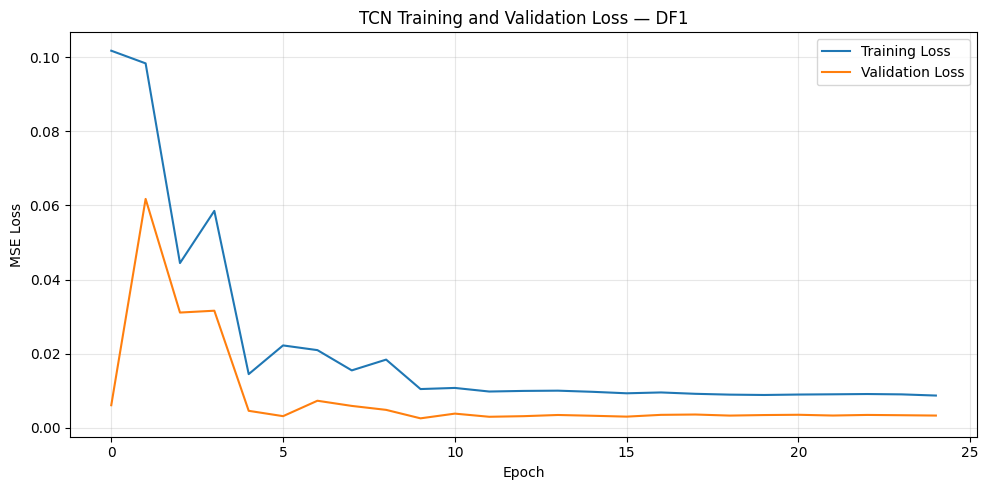

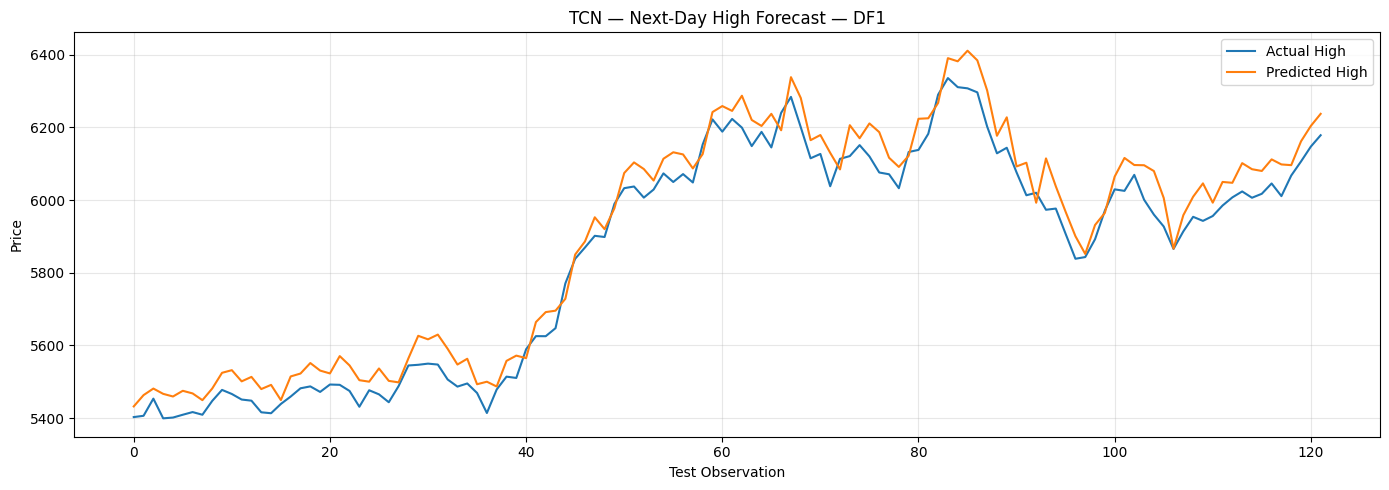

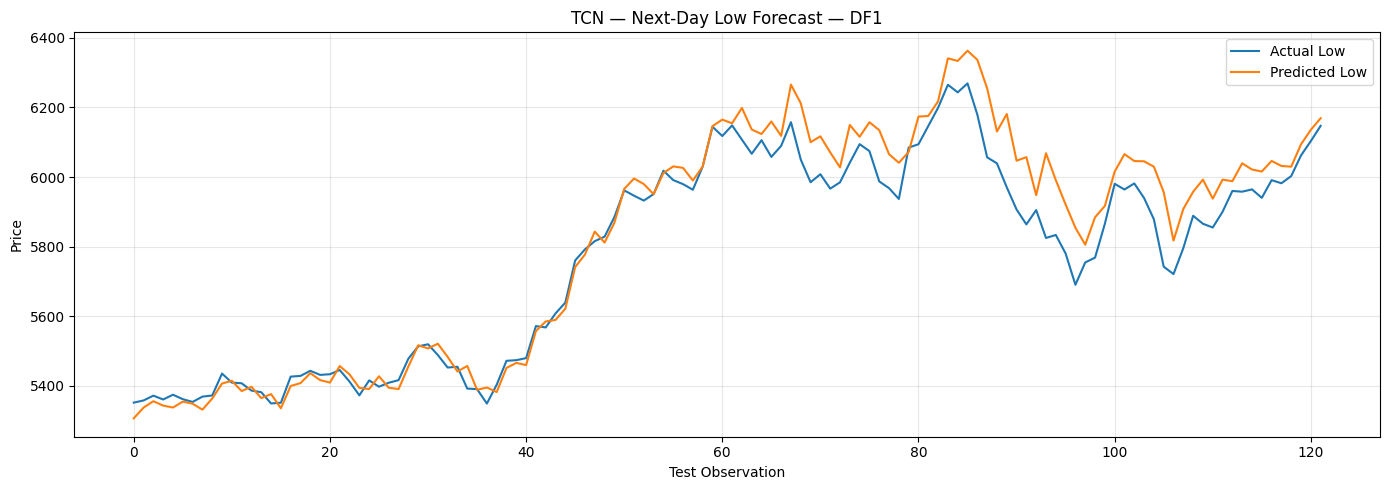



TRAINING TCN — DF2
Total observations: 2193
Train observations: 1535
Validation observations: 329
Test observations: 329

Sequence shapes:
X_train: (1510, 25, 4)
y_train: (1510, 2)
X_val: (329, 25, 4)
y_val: (329, 2)
X_test: (329, 25, 4)
y_test: (329, 2)

Model architecture:


Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 25, 4)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_9 (Conv1D)   │ (None, 25, 64)    │        832 │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_10          │ (None, 25, 64)    │          0 │ conv1d_9[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_10 (Conv1D)  │ (None, 25, 64)    │     12,352 │ dropout_10[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_11          │ (None, 25, 64)    │          0 │ conv1d_10[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_11 (Conv1D)  │ (None, 25, 64)    │        320 │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_4 (Add)         │ (None, 25, 64)    │          0 │ dropout_11[0][0], │
│                     │                   │            │ conv1d_11[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 25, 64)    │          0 │ add_4[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_12 (Conv1D)  │ (None, 25, 64)    │     12,352 │ activation_4[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_12          │ (None, 25, 64)    │          0 │ conv1d_12[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_13 (Conv1D)  │ (None, 25, 64)    │     12,352 │ dropout_12[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_13          │ (None, 25, 64)    │          0 │ conv1d_13[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_5 (Add)         │ (None, 25, 64)    │          0 │ dropout_13[0][0], │
│                     │                   │            │ activation_4[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_5        │ (None, 25, 64)    │          0 │ add_5[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_14 (Conv1D)  │ (None, 25, 64)    │     12,352 │ activation_5[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_14          │ (None, 25, 64)    │          0 │ conv1d_14[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_15 (Conv1D)  │ (None, 25, 64)    │     12,352 │ dropout_14[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_15          │ (None, 25, 64)    │          0 │ conv1d_15[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_6 (Add)         │ (None, 25, 64)    │          0 │ dropout_15[0][0], │
│                     │                   │            │ activation_5[0][

 Total params: 88,690 (346.45 KB)

 Trainable params: 88,690 (346.45 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/150
48/48 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - loss: 0.0705 - mae: 0.2018 - val_loss: 0.0652 - val_mae: 0.2224 - learning_rate: 0.0010
Epoch 2/150
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0702 - mae: 0.2160 - val_loss: 0.0301 - val_mae: 0.1522 - learning_rate: 0.0010
Epoch 3/150
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0427 - mae: 0.1550 - val_loss: 0.0251 - val_mae: 0.1307 - learning_rate: 0.0010
Epoch 4/150
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0447 - mae: 0.1722 - val_loss: 0.0034 - val_mae: 0.0465 - learning_rate: 0.0010
Epoch 5/150
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0265 - mae: 0.1291 - val_loss: 0.0052 - val_mae: 0.0588 - learning_rate: 0.0010
Epoch 6/150
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0174 - mae: 0.1035 - val_loss: 0.0035 - val_mae: 0.0476 - learning_rate: 0.0010
Epoch 7/150
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0082 - mae: 0.0648 - val_loss: 0.0062 - val_mae: 0.0663 - learning_rate: 0.0010
Epoch 

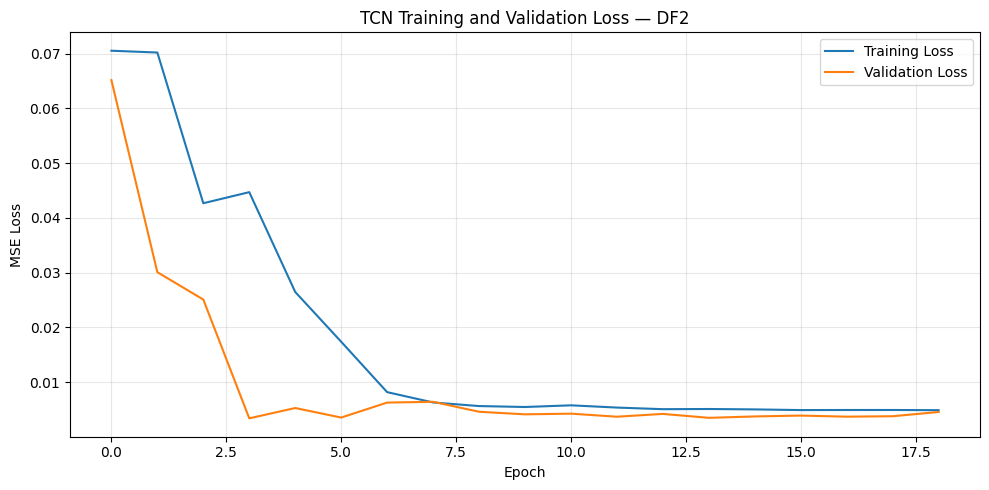

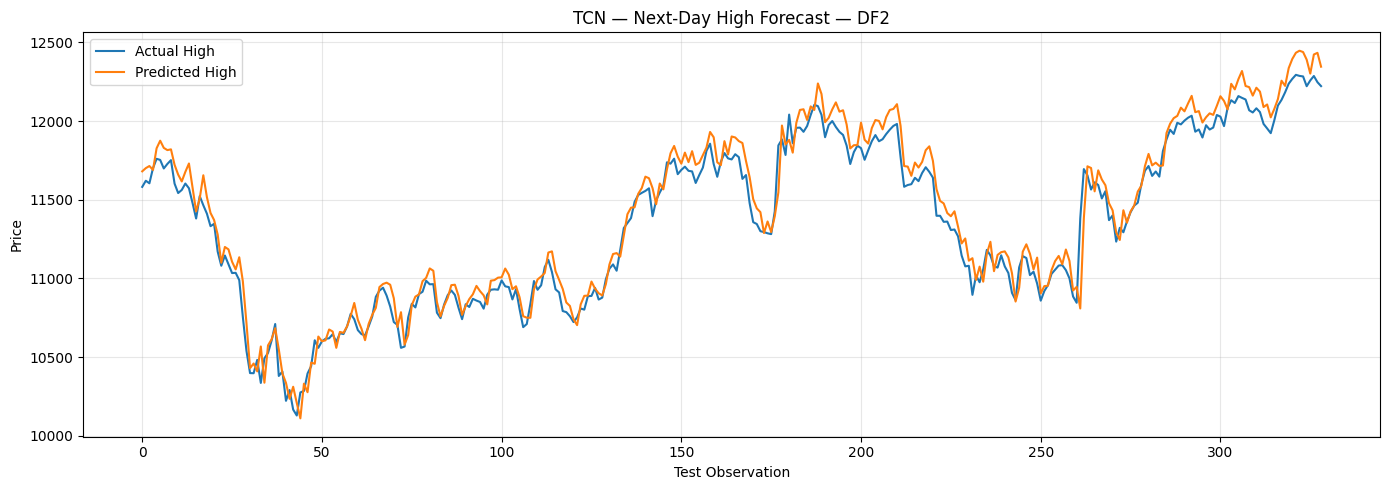

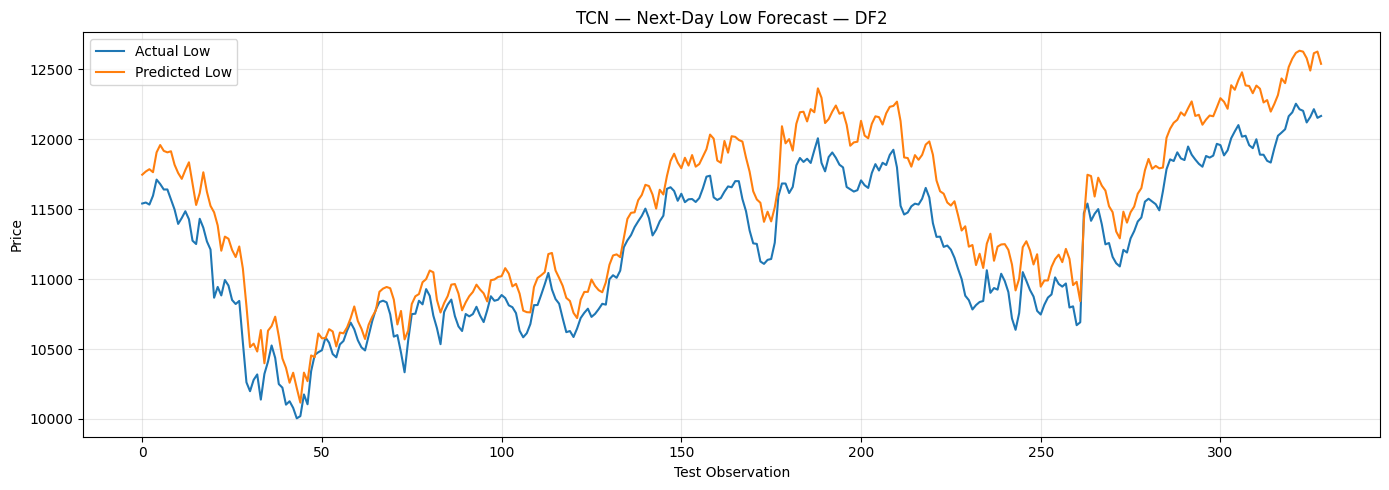



TRAINING TCN — DF3
Total observations: 498
Train observations: 348
Validation observations: 75
Test observations: 75

Sequence shapes:
X_train: (323, 25, 4)
y_train: (323, 2)
X_val: (75, 25, 4)
y_val: (75, 2)
X_test: (75, 25, 4)
y_test: (75, 2)

Model architecture:


Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 25, 4)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_18 (Conv1D)  │ (None, 25, 64)    │        832 │ input_layer_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_18          │ (None, 25, 64)    │          0 │ conv1d_18[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_19 (Conv1D)  │ (None, 25, 64)    │     12,352 │ dropout_18[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_19          │ (None, 25, 64)    │          0 │ conv1d_19[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_20 (Conv1D)  │ (None, 25, 64)    │        320 │ input_layer_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_8 (Add)         │ (None, 25, 64)    │          0 │ dropout_19[0][0], │
│                     │                   │            │ conv1d_20[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_8        │ (None, 25, 64)    │          0 │ add_8[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_21 (Conv1D)  │ (None, 25, 64)    │     12,352 │ activation_8[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_20          │ (None, 25, 64)    │          0 │ conv1d_21[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_22 (Conv1D)  │ (None, 25, 64)    │     12,352 │ dropout_20[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_21          │ (None, 25, 64)    │          0 │ conv1d_22[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_9 (Add)         │ (None, 25, 64)    │          0 │ dropout_21[0][0], │
│                     │                   │            │ activation_8[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_9        │ (None, 25, 64)    │          0 │ add_9[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_23 (Conv1D)  │ (None, 25, 64)    │     12,352 │ activation_9[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_22          │ (None, 25, 64)    │          0 │ conv1d_23[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_24 (Conv1D)  │ (None, 25, 64)    │     12,352 │ dropout_22[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_23          │ (None, 25, 64)    │          0 │ conv1d_24[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_10 (Add)        │ (None, 25, 64)    │          0 │ dropout_23[0][0], │
│                     │                   │            │ activation_9[0][

 Total params: 88,690 (346.45 KB)

 Trainable params: 88,690 (346.45 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 73ms/step - loss: 0.4799 - mae: 0.6531 - val_loss: 0.2481 - val_mae: 0.4829 - learning_rate: 0.0010
Epoch 2/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.2951 - mae: 0.4920 - val_loss: 0.2317 - val_mae: 0.3708 - learning_rate: 0.0010
Epoch 3/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.2593 - mae: 0.4874 - val_loss: 0.2000 - val_mae: 0.4104 - learning_rate: 0.0010
Epoch 4/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.2403 - mae: 0.4438 - val_loss: 0.1986 - val_mae: 0.3348 - learning_rate: 0.0010
Epoch 5/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.2130 - mae: 0.4126 - val_loss: 0.1707 - val_mae: 0.3070 - learning_rate: 0.0010
Epoch 6/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.1952 - mae: 0.3965 - val_loss: 0.1504 - val_mae: 0.2888 - learning_rate: 0.0010
Epoch 7/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.1785 - mae: 0.3784 - val_loss: 0.1364 - val_mae: 0.2792 - learning_rate: 0.0010
Epoch 

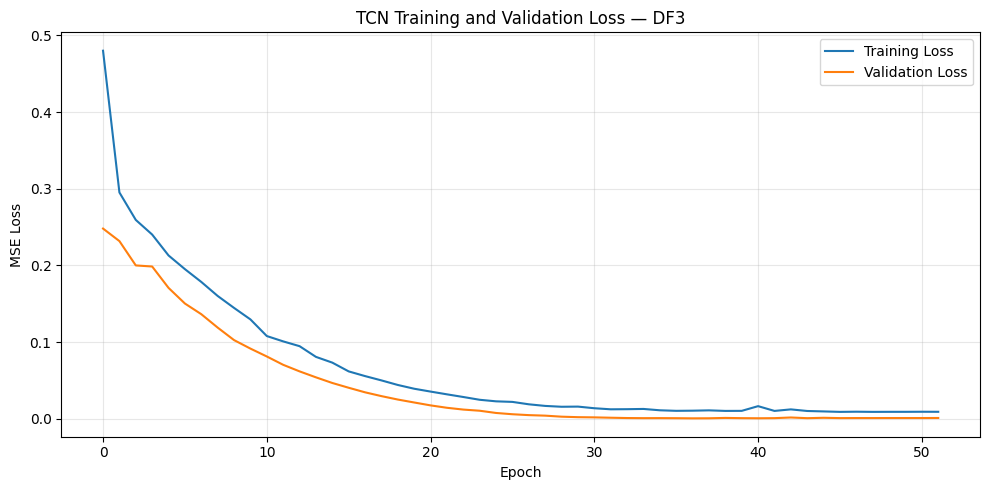

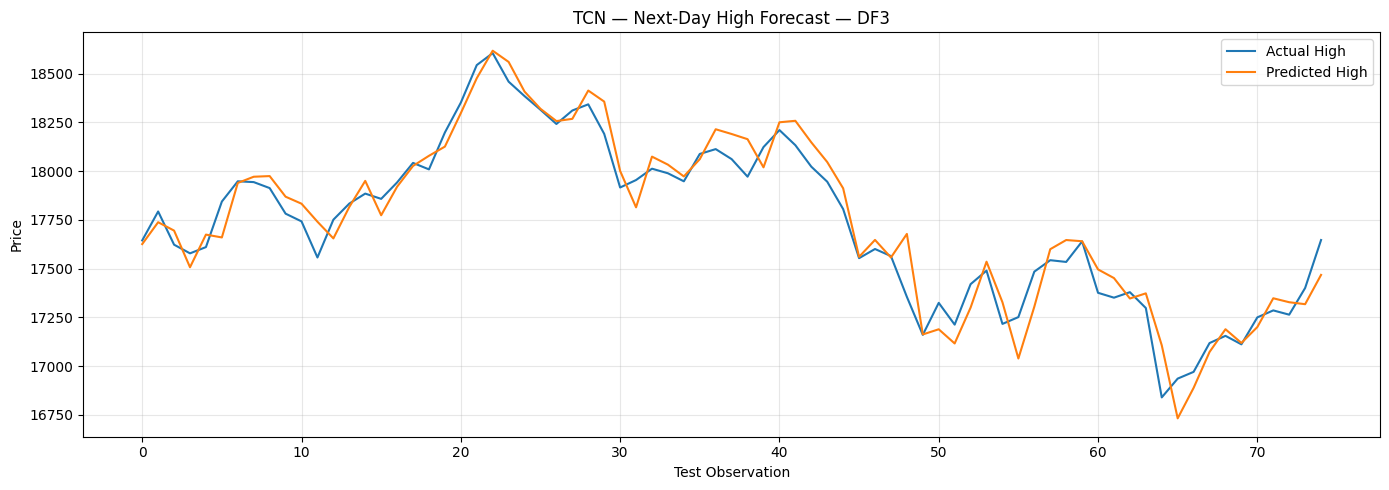

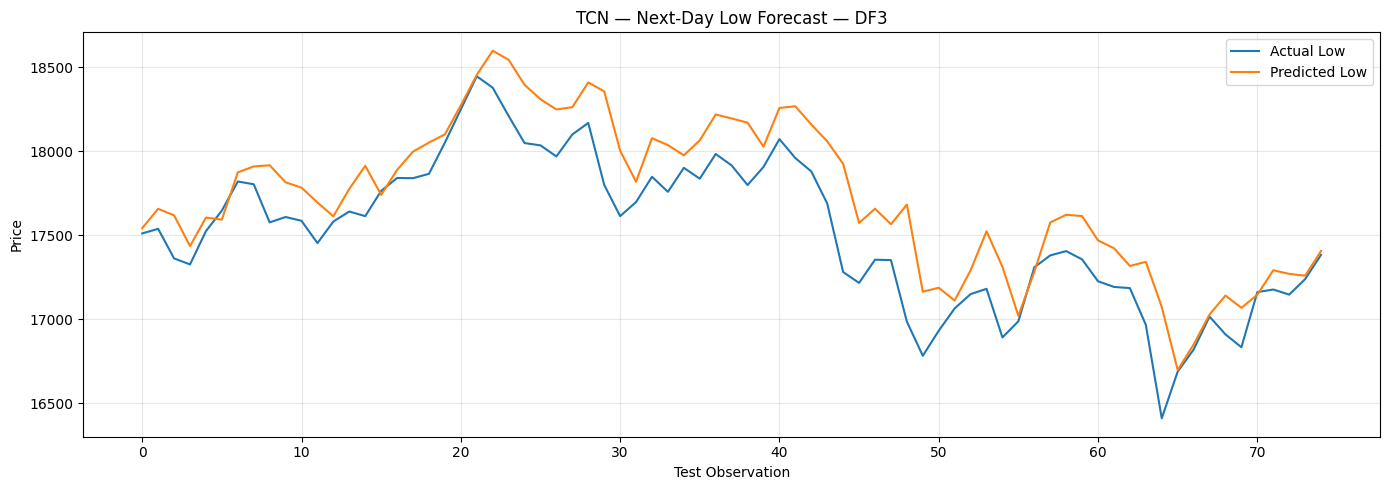



TRAINING TCN — DF4
Total observations: 962
Train observations: 673
Validation observations: 144
Test observations: 145

Sequence shapes:
X_train: (648, 25, 4)
y_train: (648, 2)
X_val: (144, 25, 4)
y_val: (144, 2)
X_test: (145, 25, 4)
y_test: (145, 2)

Model architecture:


Model: "functional_9"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 25, 4)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_27 (Conv1D)  │ (None, 25, 64)    │        832 │ input_layer_4[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_26          │ (None, 25, 64)    │          0 │ conv1d_27[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_28 (Conv1D)  │ (None, 25, 64)    │     12,352 │ dropout_26[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_27          │ (None, 25, 64)    │          0 │ conv1d_28[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_29 (Conv1D)  │ (None, 25, 64)    │        320 │ input_layer_4[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_12 (Add)        │ (None, 25, 64)    │          0 │ dropout_27[0][0], │
│                     │                   │            │ conv1d_29[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_12       │ (None, 25, 64)    │          0 │ add_12[0][0]      │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_30 (Conv1D)  │ (None, 25, 64)    │     12,352 │ activation_12[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_28          │ (None, 25, 64)    │          0 │ conv1d_30[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_31 (Conv1D)  │ (None, 25, 64)    │     12,352 │ dropout_28[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_29          │ (None, 25, 64)    │          0 │ conv1d_31[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_13 (Add)        │ (None, 25, 64)    │          0 │ dropout_29[0][0], │
│                     │                   │            │ activation_12[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_13       │ (None, 25, 64)    │          0 │ add_13[0][0]      │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_32 (Conv1D)  │ (None, 25, 64)    │     12,352 │ activation_13[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_30          │ (None, 25, 64)    │          0 │ conv1d_32[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_33 (Conv1D)  │ (None, 25, 64)    │     12,352 │ dropout_30[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_31          │ (None, 25, 64)    │          0 │ conv1d_33[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_14 (Add)        │ (None, 25, 64)    │          0 │ dropout_31[0][0], │
│                     │                   │            │ activation_13[0]

 Total params: 88,690 (346.45 KB)

 Trainable params: 88,690 (346.45 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 5s 45ms/step - loss: 0.0740 - mae: 0.1968 - val_loss: 0.0218 - val_mae: 0.1179 - learning_rate: 0.0010
Epoch 2/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.1265 - mae: 0.3094 - val_loss: 0.0129 - val_mae: 0.0820 - learning_rate: 0.0010
Epoch 3/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.1030 - mae: 0.2836 - val_loss: 0.0279 - val_mae: 0.1447 - learning_rate: 0.0010
Epoch 4/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0219 - mae: 0.1176 - val_loss: 0.0102 - val_mae: 0.0711 - learning_rate: 0.0010
Epoch 5/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - loss: 0.0225 - mae: 0.1201 - val_loss: 0.0098 - val_mae: 0.0667 - learning_rate: 0.0010
Epoch 6/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0119 - mae: 0.0806 - val_loss: 0.0131 - val_mae: 0.0885 - learning_rate: 0.0010
Epoch 7/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0141 - mae: 0.0846 - val_loss: 0.0118 - val_mae: 0.0806 - learning_rate: 0.0010
Epoch 

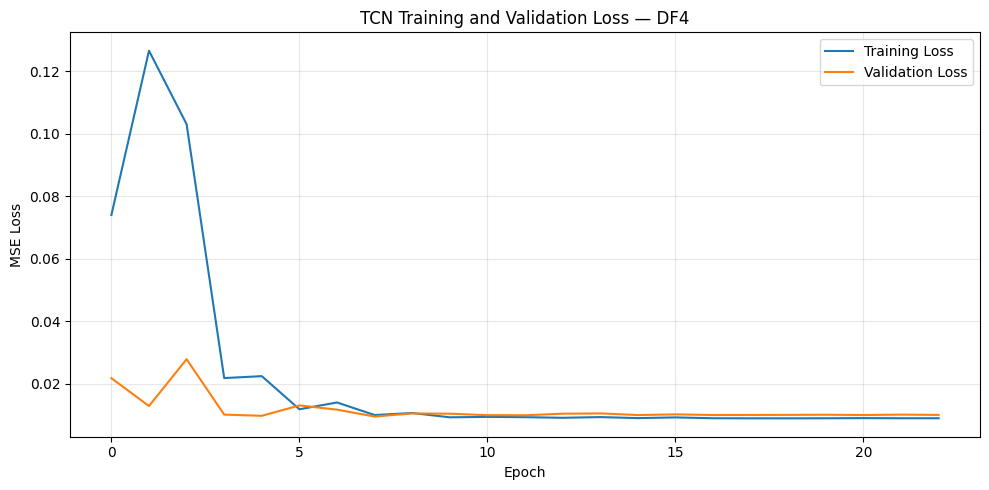

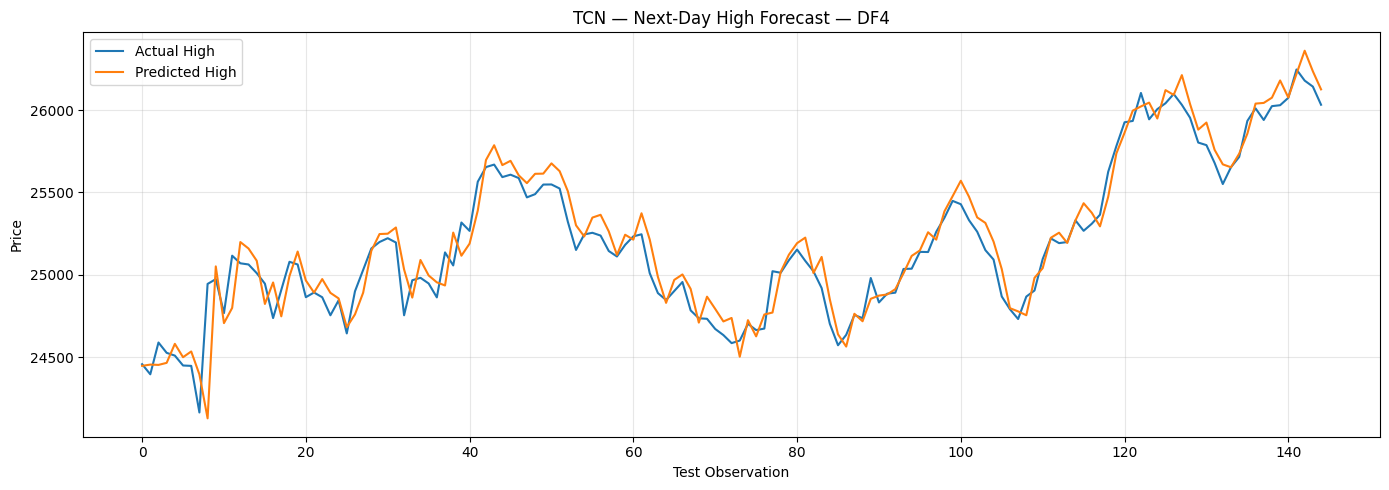

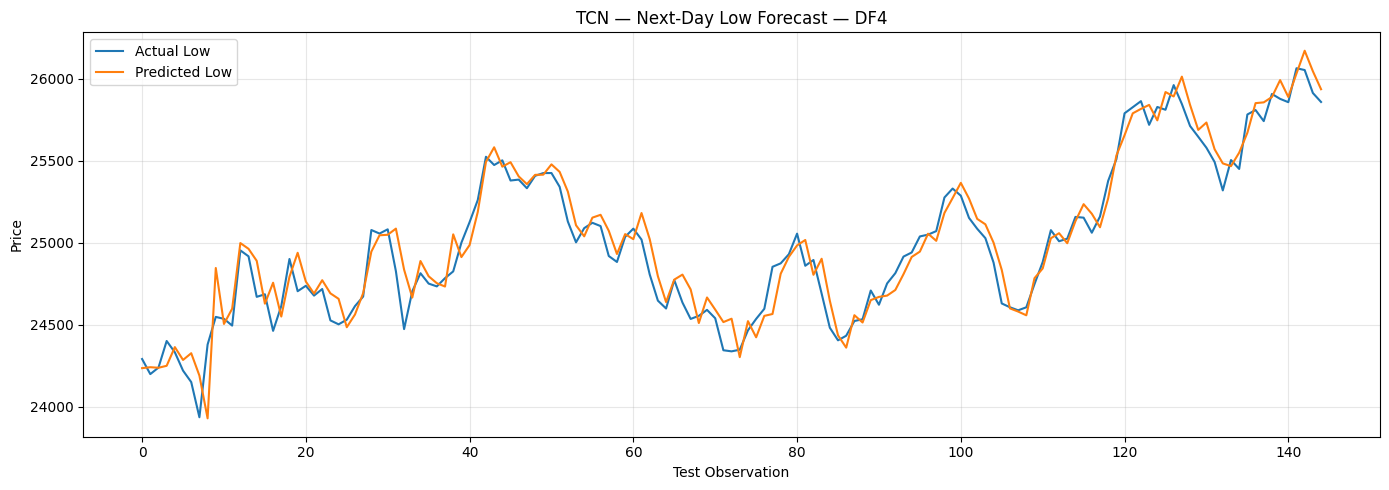



FINAL TCN RESULTS


,Regime,High_MAE,High_RMSE,High_R2,High_MAPE,Low_MAE,Low_RMSE,Low_R2,Low_MAPE,Best_Epoch
0,DF1,54.951187,61.365141,0.958238,0.938981,56.406770,77.651450,0.927210,0.960485,25
1,DF2,82.430995,101.707520,0.961918,0.723046,257.990638,282.580926,0.718303,2.282147,19
2,DF3,82.497266,104.038670,0.935575,0.467536,208.359360,259.461590,0.641125,1.193113,52
3,DF4,93.271016,126.990986,0.922499,0.370866,91.701819,118.813093,0.937595,0.368195,23



Results saved as: TCN_baseline_results.csv
Predictions saved as: TCN_baseline_predictions.xlsx


In [48]:
# ============================================================
# TCN BASELINE — NIFTY 50 REGIME-WISE FORECASTING
# Target: Next-Day High and Low
# Protocol: 70% Train / 15% Validation / 15% Test
# ============================================================

import os
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    Dropout,
    Dense,
    Add,
    Activation,
    GlobalAveragePooling1D
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")


# ============================================================
# 1. REPRODUCIBILITY
# ============================================================

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except:
    pass


# ============================================================
# 2. FIXED TCN HYPERPARAMETERS
# ============================================================

LOOKBACK = 25

TCN_FILTERS = 64
KERNEL_SIZE = 3
DILATIONS = [1, 2, 4, 8]

DROPOUT = 0.20
DENSE_UNITS = 16

LEARNING_RATE = 0.001
BATCH_SIZE = 32
EPOCHS = 150

EARLY_STOPPING_PATIENCE = 15
LR_PATIENCE = 7
LR_FACTOR = 0.5


# ============================================================
# 3. FEATURES
# ============================================================

FEATURES = [
    "Open",
    "High",
    "Low",
    "Close"
]


# ============================================================
# 4. CHECK DATA
# ============================================================

required_columns = FEATURES + ["Date"]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )


# ============================================================
# 5. DATA PREPARATION
# ============================================================

data = df.copy()

data["Date"] = pd.to_datetime(data["Date"])

data = (
    data
    .sort_values("Date")
    .reset_index(drop=True)
)

# Ensure numeric OHLC
for col in FEATURES:
    data[col] = pd.to_numeric(
        data[col],
        errors="coerce"
    )

data = data.dropna(
    subset=FEATURES
).reset_index(drop=True)


# ============================================================
# 6. DEFINE MARKET REGIMES
# ============================================================

REGIMES = {
    "DF1": ("2007-01-01", "2010-12-31"),
    "DF2": ("2011-01-01", "2019-12-31"),
    "DF3": ("2020-01-01", "2021-12-31"),
    "DF4": ("2022-01-01", None)
}


# ============================================================
# 7. TARGET CREATION
# ============================================================
#
# Predict:
#
#   Next-Day High / Current Close
#   Next-Day Low  / Current Close
#
# Absolute prediction is reconstructed later:
#
#   Predicted High = Predicted Ratio × Current Close
#   Predicted Low  = Predicted Ratio × Current Close
#
# ============================================================

data["Target_High_Ratio"] = (
    data["High"].shift(-1) /
    data["Close"]
)

data["Target_Low_Ratio"] = (
    data["Low"].shift(-1) /
    data["Close"]
)

data = data.dropna(
    subset=[
        "Target_High_Ratio",
        "Target_Low_Ratio"
    ]
).reset_index(drop=True)


# ============================================================
# 8. SEQUENCE CREATION FUNCTION
# ============================================================

def create_train_sequences(
    X,
    y,
    lookback
):
    """
    Creates sequences for the training partition.

    X[i-lookback:i] -> y[i]
    """

    X_seq = []
    y_seq = []

    for i in range(
        lookback,
        len(X)
    ):

        X_seq.append(
            X[i-lookback:i]
        )

        y_seq.append(
            y[i]
        )

    return (
        np.array(X_seq),
        np.array(y_seq)
    )


# ============================================================
# 9. VALIDATION / TEST SEQUENCE FUNCTION
# ============================================================

def create_partition_sequences(
    history_X,
    partition_X,
    partition_y,
    lookback
):
    """
    Creates validation/test sequences while allowing
    the first observations to use historical information.

    This avoids losing the first LOOKBACK observations
    of validation/test.
    """

    X_combined = np.concatenate(
        [
            history_X,
            partition_X
        ],
        axis=0
    )

    X_seq = []
    y_seq = []

    for i in range(
        len(partition_y)
    ):

        X_seq.append(
            X_combined[i:i + lookback]
        )

        y_seq.append(
            partition_y[i]
        )

    return (
        np.array(X_seq),
        np.array(y_seq)
    )


# ============================================================
# 10. TCN RESIDUAL BLOCK
# ============================================================

def tcn_residual_block(
    x,
    filters,
    kernel_size,
    dilation_rate,
    dropout_rate
):

    residual = x

    # First causal dilated convolution
    x = Conv1D(
        filters=filters,
        kernel_size=kernel_size,
        padding="causal",
        dilation_rate=dilation_rate,
        activation="relu"
    )(x)

    x = Dropout(
        dropout_rate
    )(x)

    # Second causal dilated convolution
    x = Conv1D(
        filters=filters,
        kernel_size=kernel_size,
        padding="causal",
        dilation_rate=dilation_rate,
        activation=None
    )(x)

    x = Dropout(
        dropout_rate
    )(x)

    # Match residual dimensions if necessary
    if residual.shape[-1] != filters:

        residual = Conv1D(
            filters=filters,
            kernel_size=1,
            padding="same"
        )(residual)

    # Residual connection
    x = Add()(
        [
            x,
            residual
        ]
    )

    x = Activation(
        "relu"
    )(x)

    return x


# ============================================================
# 11. BUILD TCN MODEL
# ============================================================

def build_tcn_model(
    input_shape
):

    inputs = Input(
        shape=input_shape
    )

    x = inputs

    # --------------------------------------------
    # Dilated TCN blocks
    # --------------------------------------------

    for dilation in DILATIONS:

        x = tcn_residual_block(
            x=x,
            filters=TCN_FILTERS,
            kernel_size=KERNEL_SIZE,
            dilation_rate=dilation,
            dropout_rate=DROPOUT
        )

    # --------------------------------------------
    # Sequence → fixed representation
    # --------------------------------------------

    x = GlobalAveragePooling1D()(x)

    # --------------------------------------------
    # Dense forecasting head
    # --------------------------------------------

    x = Dense(
        DENSE_UNITS,
        activation="relu"
    )(x)

    outputs = Dense(
        2,
        activation="linear"
    )(x)

    model = Model(
        inputs=inputs,
        outputs=outputs
    )

    optimizer = Adam(
        learning_rate=LEARNING_RATE
    )

    model.compile(
        optimizer=optimizer,
        loss="mse",
        metrics=["mae"]
    )

    return model


# ============================================================
# 12. METRIC FUNCTION
# ============================================================

def calculate_metrics(
    y_true,
    y_pred
):

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    # Avoid division by zero
    denominator = np.where(
        np.abs(y_true) < 1e-8,
        1e-8,
        np.abs(y_true)
    )

    mape = np.mean(
        np.abs(
            (y_true - y_pred) /
            denominator
        )
    ) * 100

    return mae, rmse, r2, mape


# ============================================================
# 13. STORAGE
# ============================================================

all_results = []
all_predictions = {}
all_histories = {}
all_models = {}


# ============================================================
# 14. REGIME-WISE TRAINING
# ============================================================

for regime_name, (
    start_date,
    end_date
) in REGIMES.items():

    print("\n")
    print("=" * 70)
    print(f"TRAINING TCN — {regime_name}")
    print("=" * 70)

    # --------------------------------------------------------
    # Filter regime
    # --------------------------------------------------------

    regime_data = data[
        data["Date"] >= pd.Timestamp(start_date)
    ].copy()

    if end_date is not None:

        regime_data = regime_data[
            regime_data["Date"] <=
            pd.Timestamp(end_date)
        ]

    regime_data = (
        regime_data
        .sort_values("Date")
        .reset_index(drop=True)
    )

    print(
        f"Total observations: "
        f"{len(regime_data)}"
    )

    if len(regime_data) <= LOOKBACK + 20:

        print(
            f"Skipping {regime_name}: "
            f"insufficient observations."
        )

        continue


    # --------------------------------------------------------
    # Extract features and targets
    # --------------------------------------------------------

    X_raw = regime_data[
        FEATURES
    ].values

    y_raw = regime_data[
        [
            "Target_High_Ratio",
            "Target_Low_Ratio"
        ]
    ].values


    # --------------------------------------------------------
    # 70 / 15 / 15 chronological split
    # --------------------------------------------------------

    n = len(regime_data)

    train_end = int(
        n * 0.70
    )

    val_end = int(
        n * 0.85
    )

    X_train_raw = X_raw[
        :train_end
    ]

    X_val_raw = X_raw[
        train_end:val_end
    ]

    X_test_raw = X_raw[
        val_end:
    ]

    y_train = y_raw[
        :train_end
    ]

    y_val = y_raw[
        train_end:val_end
    ]

    y_test = y_raw[
        val_end:
    ]

    print(
        f"Train observations: "
        f"{len(X_train_raw)}"
    )

    print(
        f"Validation observations: "
        f"{len(X_val_raw)}"
    )

    print(
        f"Test observations: "
        f"{len(X_test_raw)}"
    )


    # ========================================================
    # 15. TRAIN-ONLY SCALING
    # ========================================================

    X_scaler = MinMaxScaler()

    X_scaler.fit(
        X_train_raw
    )

    X_train_scaled = X_scaler.transform(
        X_train_raw
    )

    X_val_scaled = X_scaler.transform(
        X_val_raw
    )

    X_test_scaled = X_scaler.transform(
        X_test_raw
    )


    # ========================================================
    # 16. SCALE TARGETS USING TRAIN ONLY
    # ========================================================

    y_scaler = MinMaxScaler()

    y_scaler.fit(
        y_train
    )

    y_train_scaled = y_scaler.transform(
        y_train
    )

    y_val_scaled = y_scaler.transform(
        y_val
    )

    y_test_scaled = y_scaler.transform(
        y_test
    )


    # ========================================================
    # 17. CREATE TRAIN SEQUENCES
    # ========================================================

    X_train, y_train_seq = create_train_sequences(
        X_train_scaled,
        y_train_scaled,
        LOOKBACK
    )


    # ========================================================
    # 18. CREATE VALIDATION SEQUENCES
    # ========================================================

    X_val, y_val_seq = create_partition_sequences(
        history_X=X_train_scaled[-LOOKBACK:],
        partition_X=X_val_scaled,
        partition_y=y_val_scaled,
        lookback=LOOKBACK
    )


    # ========================================================
    # 19. CREATE TEST SEQUENCES
    # ========================================================

    X_test, y_test_seq = create_partition_sequences(
        history_X=X_val_scaled[-LOOKBACK:],
        partition_X=X_test_scaled,
        partition_y=y_test_scaled,
        lookback=LOOKBACK
    )


    print(
        "\nSequence shapes:"
    )

    print(
        "X_train:",
        X_train.shape
    )

    print(
        "y_train:",
        y_train_seq.shape
    )

    print(
        "X_val:",
        X_val.shape
    )

    print(
        "y_val:",
        y_val_seq.shape
    )

    print(
        "X_test:",
        X_test.shape
    )

    print(
        "y_test:",
        y_test_seq.shape
    )


    # ========================================================
    # 20. BUILD MODEL
    # ========================================================

    model = build_tcn_model(
        input_shape=(
            LOOKBACK,
            len(FEATURES)
        )
    )

    print("\nModel architecture:")

    model.summary()


    # ========================================================
    # 21. CALLBACKS
    # ========================================================

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=EARLY_STOPPING_PATIENCE,
        restore_best_weights=True,
        verbose=1
    )

    reduce_lr = ReduceLROnPlateau(
        monitor="val_loss",
        factor=LR_FACTOR,
        patience=LR_PATIENCE,
        min_lr=1e-6,
        verbose=1
    )


    # ========================================================
    # 22. TRAIN
    # ========================================================

    history = model.fit(
        X_train,
        y_train_seq,

        validation_data=(
            X_val,
            y_val_seq
        ),

        epochs=EPOCHS,
        batch_size=BATCH_SIZE,

        callbacks=[
            early_stopping,
            reduce_lr
        ],

        shuffle=False,
        verbose=1
    )


    # ========================================================
    # 23. PREDICT TEST SET
    # ========================================================

    y_pred_scaled = model.predict(
        X_test,
        verbose=0
    )


    # ========================================================
    # 24. INVERSE TRANSFORM TARGET RATIOS
    # ========================================================

    y_pred_ratio = y_scaler.inverse_transform(
        y_pred_scaled
    )

    y_test_ratio = y_scaler.inverse_transform(
        y_test_seq
    )


    # ========================================================
    # 25. CURRENT CLOSE FOR EACH TEST TARGET
    # ========================================================
    #
    # Since validation/test sequences preserve the
    # partition ordering, the target-day current close
    # corresponds to X_test_raw / X_val_raw etc.
    #
    # Target is:
    #
    # High(t+1) / Close(t)
    #
    # Therefore use Close(t) to reconstruct.
    # ========================================================

    current_close_test = X_test_raw[
        :, FEATURES.index("Close")
    ]


    # ========================================================
    # 26. RECONSTRUCT ABSOLUTE PRICES
    # ========================================================

    actual_high = (
        y_test_ratio[:, 0] *
        current_close_test
    )

    actual_low = (
        y_test_ratio[:, 1] *
        current_close_test
    )

    predicted_high = (
        y_pred_ratio[:, 0] *
        current_close_test
    )

    predicted_low = (
        y_pred_ratio[:, 1] *
        current_close_test
    )


    # ========================================================
    # 27. CALCULATE METRICS — HIGH
    # ========================================================

    high_mae, high_rmse, high_r2, high_mape = (
        calculate_metrics(
            actual_high,
            predicted_high
        )
    )


    # ========================================================
    # 28. CALCULATE METRICS — LOW
    # ========================================================

    low_mae, low_rmse, low_r2, low_mape = (
        calculate_metrics(
            actual_low,
            predicted_low
        )
    )


    # ========================================================
    # 29. PRINT RESULTS
    # ========================================================

    print("\n")
    print("=" * 70)
    print(f"TCN RESULTS — {regime_name}")
    print("=" * 70)

    print("\nNEXT-DAY HIGH")
    print(
        f"MAE  : {high_mae:.6f}"
    )
    print(
        f"RMSE : {high_rmse:.6f}"
    )
    print(
        f"R²   : {high_r2:.6f}"
    )
    print(
        f"MAPE : {high_mape:.6f}%"
    )

    print("\nNEXT-DAY LOW")
    print(
        f"MAE  : {low_mae:.6f}"
    )
    print(
        f"RMSE : {low_rmse:.6f}"
    )
    print(
        f"R²   : {low_r2:.6f}"
    )
    print(
        f"MAPE : {low_mape:.6f}%"
    )


    # ========================================================
    # 30. SAVE RESULTS
    # ========================================================

    all_results.append({

        "Regime": regime_name,

        "High_MAE": high_mae,
        "High_RMSE": high_rmse,
        "High_R2": high_r2,
        "High_MAPE": high_mape,

        "Low_MAE": low_mae,
        "Low_RMSE": low_rmse,
        "Low_R2": low_r2,
        "Low_MAPE": low_mape,

        "Best_Epoch":
            len(history.history["loss"])

    })


    # ========================================================
    # 31. SAVE PREDICTIONS
    # ========================================================

    test_dates = regime_data[
        "Date"
    ].iloc[
        val_end:
    ].values

    prediction_df = pd.DataFrame({

        "Date": test_dates,

        "Actual_High":
            actual_high,

        "Predicted_High":
            predicted_high,

        "Actual_Low":
            actual_low,

        "Predicted_Low":
            predicted_low,

        "Current_Close":
            current_close_test

    })

    all_predictions[
        regime_name
    ] = prediction_df

    all_histories[
        regime_name
    ] = history.history

    all_models[
        regime_name
    ] = model


    # ========================================================
    # 32. PLOT TRAINING / VALIDATION LOSS
    # ========================================================

    plt.figure(
        figsize=(10, 5)
    )

    plt.plot(
        history.history["loss"],
        label="Training Loss"
    )

    plt.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.title(
        f"TCN Training and Validation Loss — {regime_name}"
    )

    plt.xlabel(
        "Epoch"
    )

    plt.ylabel(
        "MSE Loss"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


    # ========================================================
    # 33. PLOT HIGH PREDICTIONS
    # ========================================================

    plt.figure(
        figsize=(14, 5)
    )

    plt.plot(
        actual_high,
        label="Actual High"
    )

    plt.plot(
        predicted_high,
        label="Predicted High"
    )

    plt.title(
        f"TCN — Next-Day High Forecast — {regime_name}"
    )

    plt.xlabel(
        "Test Observation"
    )

    plt.ylabel(
        "Price"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


    # ========================================================
    # 34. PLOT LOW PREDICTIONS
    # ========================================================

    plt.figure(
        figsize=(14, 5)
    )

    plt.plot(
        actual_low,
        label="Actual Low"
    )

    plt.plot(
        predicted_low,
        label="Predicted Low"
    )

    plt.title(
        f"TCN — Next-Day Low Forecast — {regime_name}"
    )

    plt.xlabel(
        "Test Observation"
    )

    plt.ylabel(
        "Price"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


# ============================================================
# 35. FINAL RESULTS TABLE
# ============================================================

results_df = pd.DataFrame(
    all_results
)

print("\n")
print("=" * 90)
print("FINAL TCN RESULTS")
print("=" * 90)

display(
    results_df.round(6)
)


# ============================================================
# 36. SAVE RESULTS
# ============================================================

results_df.to_csv(
    "TCN_baseline_results.csv",
    index=False
)

print(
    "\nResults saved as:"
    " TCN_baseline_results.csv"
)


# ============================================================
# 37. SAVE ALL PREDICTIONS
# ============================================================

with pd.ExcelWriter(
    "TCN_baseline_predictions.xlsx",
    engine="openpyxl"
) as writer:

    results_df.to_excel(
        writer,
        sheet_name="Results",
        index=False
    )

    for regime_name, prediction_df in all_predictions.items():

        prediction_df.to_excel(
            writer,
            sheet_name=regime_name,
            index=False
        )

print(
    "Predictions saved as:"
    " TCN_baseline_predictions.xlsx"
)



Conv1D-LSTM TRAINING — DF1
Total observations: 808
Train: 565
Validation: 121
Test: 122

Sequence shapes:
X_train: (540, 25, 4)
y_train: (540, 2)
X_val: (121, 25, 4)
y_val: (121, 2)
X_test: (122, 25, 4)
y_test: (122, 2)

Model architecture:


Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 25, 4)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 25, 64)         │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 25, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 25, 64)         │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 59,698 (233.20 KB)

 Trainable params: 59,442 (232.20 KB)

 Non-trainable params: 256 (1.00 KB)

Epoch 1/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 12s 103ms/step - loss: 0.0414 - mae: 0.1465 - val_loss: 0.1434 - val_mae: 0.2808 - learning_rate: 0.0010
Epoch 2/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - loss: 0.0299 - mae: 0.1242 - val_loss: 0.1403 - val_mae: 0.2790 - learning_rate: 0.0010
Epoch 3/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - loss: 0.0215 - mae: 0.1052 - val_loss: 0.1235 - val_mae: 0.2618 - learning_rate: 0.0010
Epoch 4/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - loss: 0.0136 - mae: 0.0834 - val_loss: 0.0777 - val_mae: 0.2085 - learning_rate: 0.0010
Epoch 5/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 0.0148 - mae: 0.0856 - val_loss: 0.0678 - val_mae: 0.1955 - learning_rate: 0.0010
Epoch 6/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - loss: 0.0136 - mae: 0.0836 - val_loss: 0.0617 - val_mae: 0.1867 - learning_rate: 0.0010
Epoch 7/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - loss: 0.0134 - mae: 0.0810 - val_loss: 0.0566 - val_mae: 0.1797 - learning_rate: 0.0010
Epoc

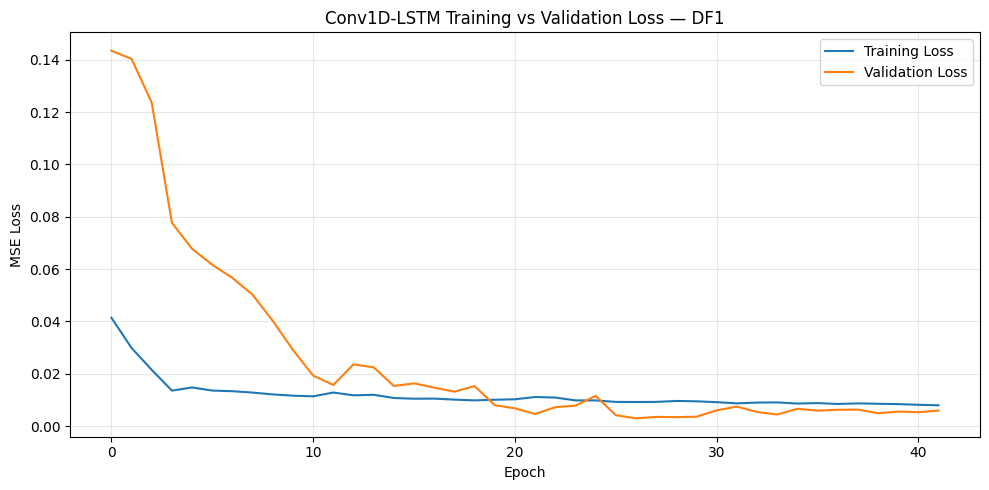

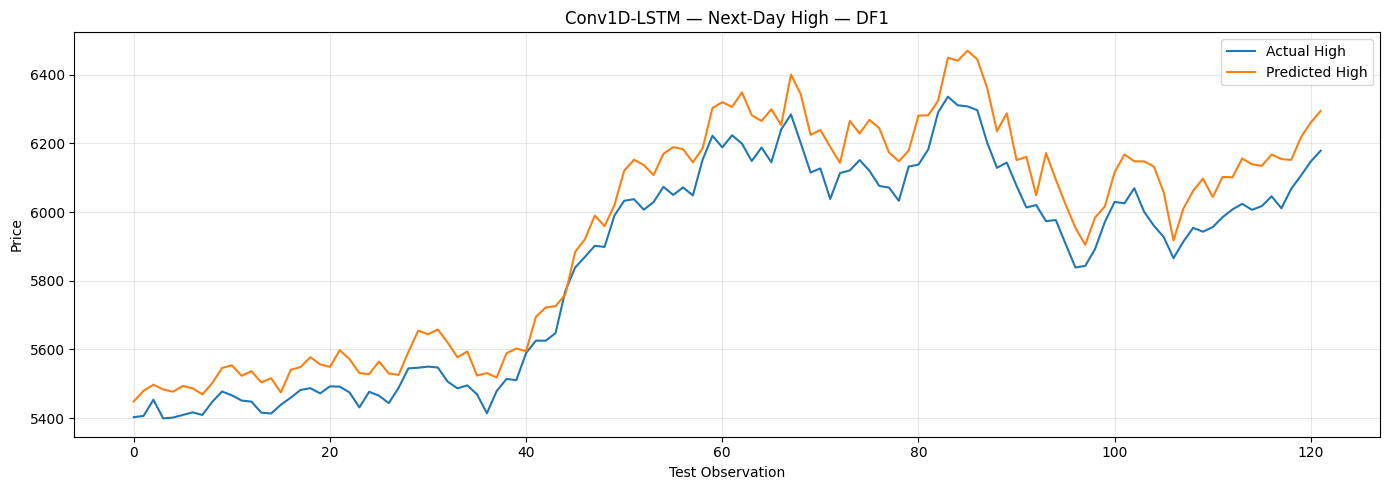

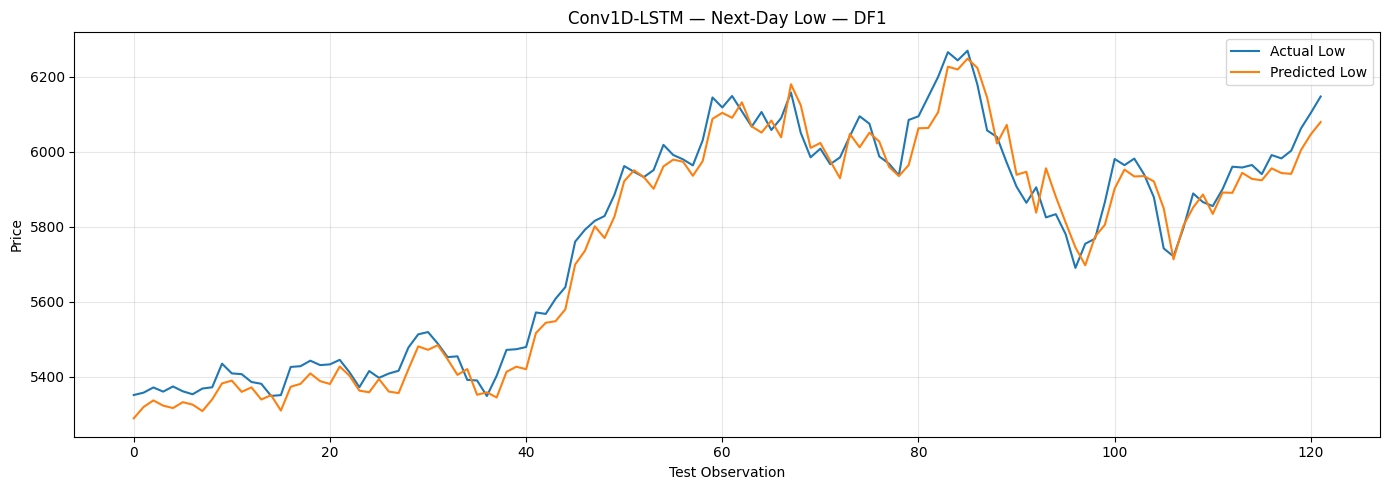



Conv1D-LSTM TRAINING — DF2
Total observations: 2193
Train: 1535
Validation: 329
Test: 329

Sequence shapes:
X_train: (1510, 25, 4)
y_train: (1510, 2)
X_val: (329, 25, 4)
y_val: (329, 2)
X_test: (329, 25, 4)
y_test: (329, 2)

Model architecture:


Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 25, 4)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 25, 64)         │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 25, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ (None, 25, 64)         │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 59,698 (233.20 KB)

 Trainable params: 59,442 (232.20 KB)

 Non-trainable params: 256 (1.00 KB)

Epoch 1/150
48/48 ━━━━━━━━━━━━━━━━━━━━ 9s 47ms/step - loss: 0.0539 - mae: 0.1645 - val_loss: 0.0741 - val_mae: 0.2546 - learning_rate: 0.0010
Epoch 2/150
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0146 - mae: 0.0941 - val_loss: 0.0498 - val_mae: 0.2125 - learning_rate: 0.0010
Epoch 3/150
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0126 - mae: 0.0866 - val_loss: 0.0106 - val_mae: 0.0896 - learning_rate: 0.0010
Epoch 4/150
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0109 - mae: 0.0803 - val_loss: 0.0080 - val_mae: 0.0796 - learning_rate: 0.0010
Epoch 5/150
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0100 - mae: 0.0772 - val_loss: 0.0061 - val_mae: 0.0689 - learning_rate: 0.0010
Epoch 6/150
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0088 - mae: 0.0709 - val_loss: 0.0020 - val_mae: 0.0359 - learning_rate: 0.0010
Epoch 7/150
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0089 - mae: 0.0718 - val_loss: 0.0021 - val_mae: 0.0377 - learning_rate: 0.0010
Epoch 

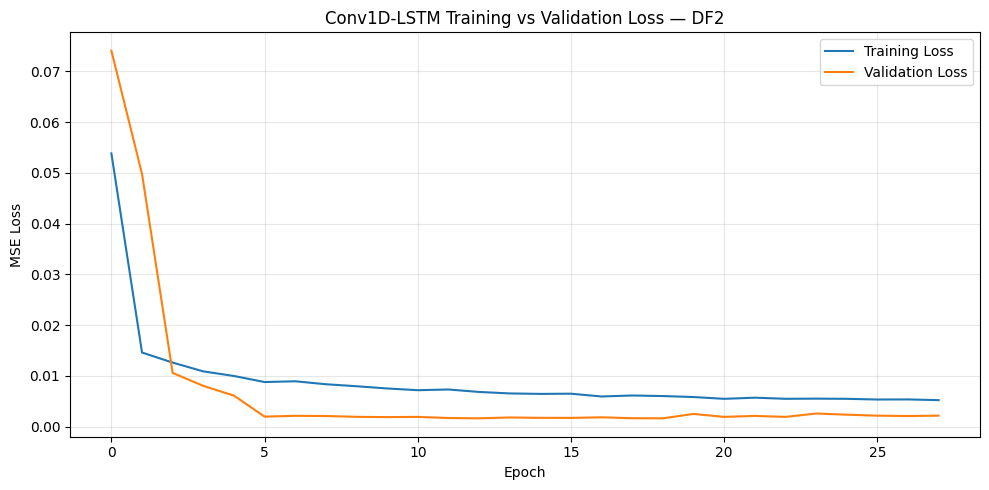

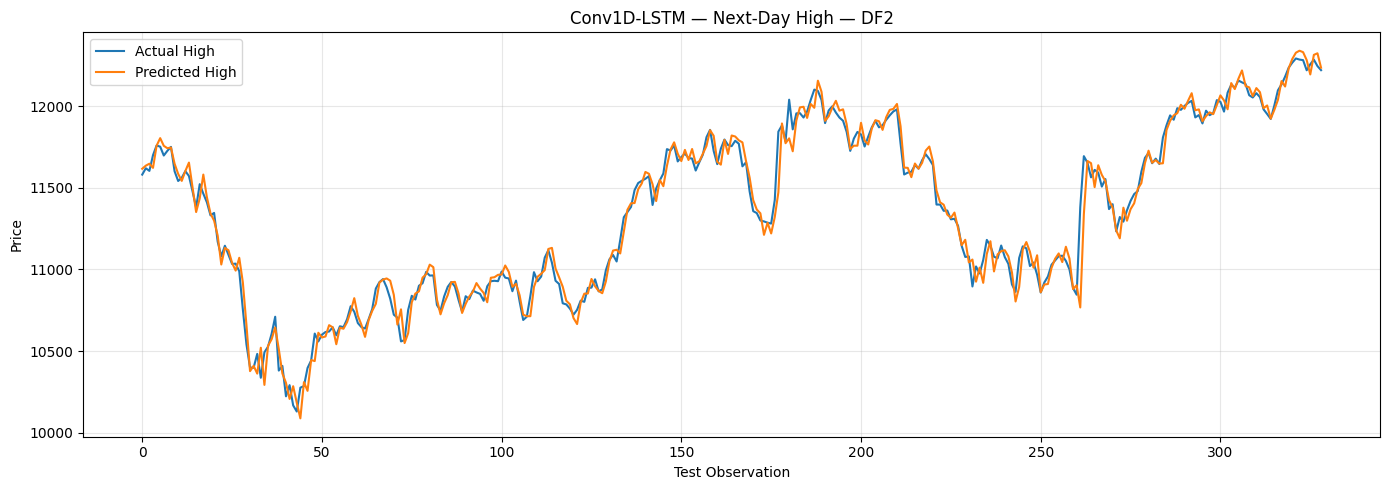

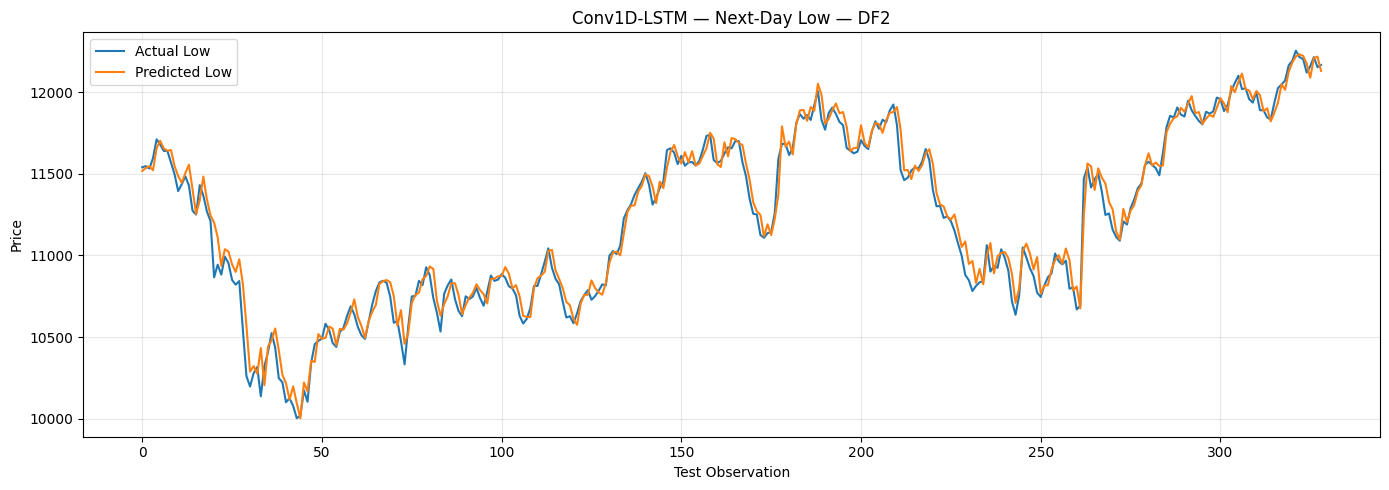



Conv1D-LSTM TRAINING — DF3
Total observations: 498
Train: 348
Validation: 75
Test: 75

Sequence shapes:
X_train: (323, 25, 4)
y_train: (323, 2)
X_val: (75, 25, 4)
y_val: (75, 2)
X_test: (75, 25, 4)
y_test: (75, 2)

Model architecture:


Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 25, 4)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (None, 25, 64)         │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_5 (Conv1D)               │ (None, 25, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_6 (LSTM)                   │ (None, 25, 64)         │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_7 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 59,698 (233.20 KB)

 Trainable params: 59,442 (232.20 KB)

 Non-trainable params: 256 (1.00 KB)

Epoch 1/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 8s 101ms/step - loss: 0.1104 - mae: 0.2510 - val_loss: 0.0220 - val_mae: 0.1442 - learning_rate: 0.0010
Epoch 2/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 0.0321 - mae: 0.1363 - val_loss: 0.0393 - val_mae: 0.1734 - learning_rate: 0.0010
Epoch 3/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0218 - mae: 0.1139 - val_loss: 0.0314 - val_mae: 0.1667 - learning_rate: 0.0010
Epoch 4/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0202 - mae: 0.1077 - val_loss: 0.0376 - val_mae: 0.1849 - learning_rate: 0.0010
Epoch 5/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0172 - mae: 0.1007 - val_loss: 0.0275 - val_mae: 0.1550 - learning_rate: 0.0010
Epoch 6/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.0166 - mae: 0.0961 - val_loss: 0.0177 - val_mae: 0.1215 - learning_rate: 0.0010
Epoch 7/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - loss: 0.0157 - mae: 0.0937 - val_loss: 0.0137 - val_mae: 0.1063 - learning_rate: 0.0010
Epoch

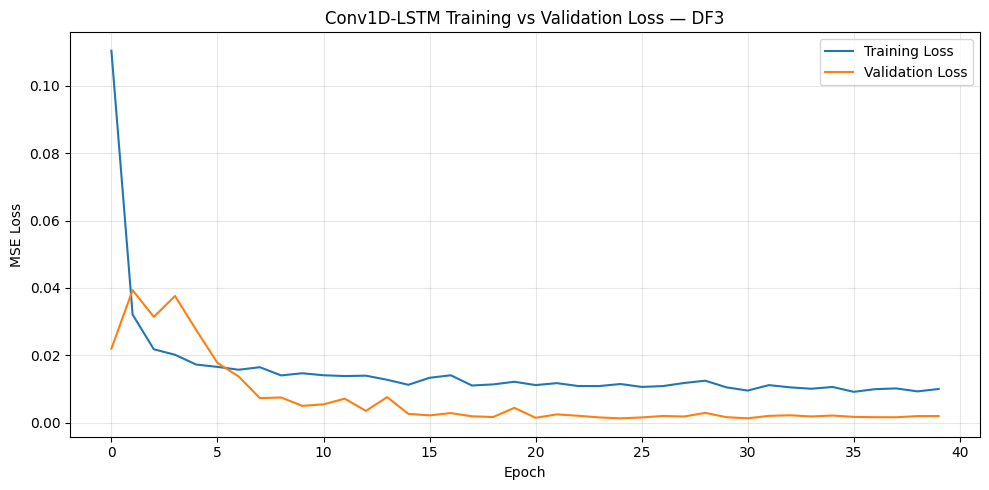

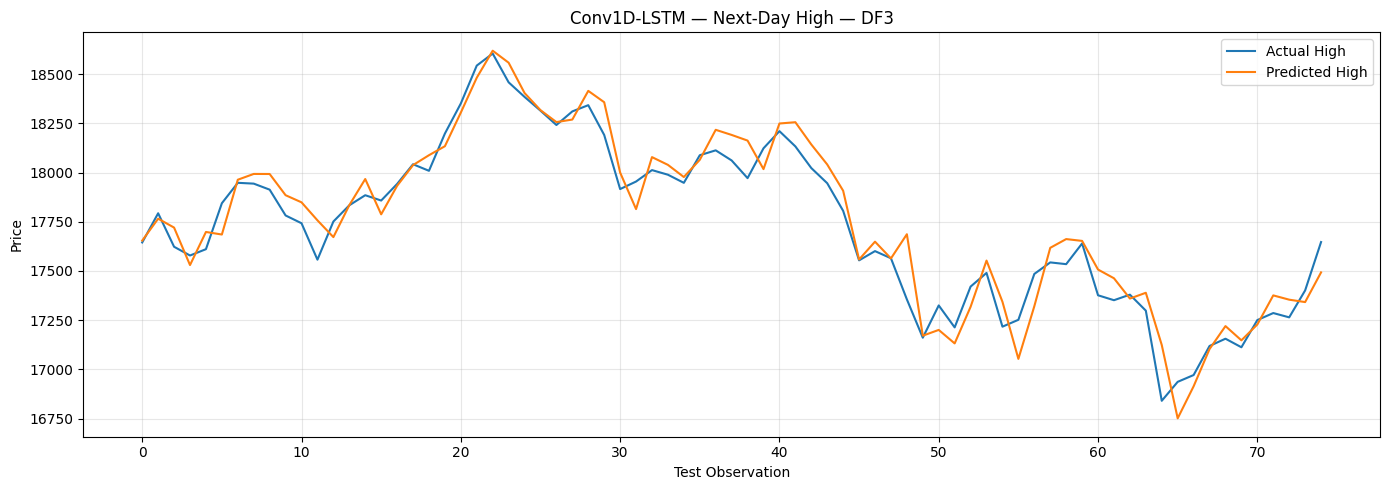

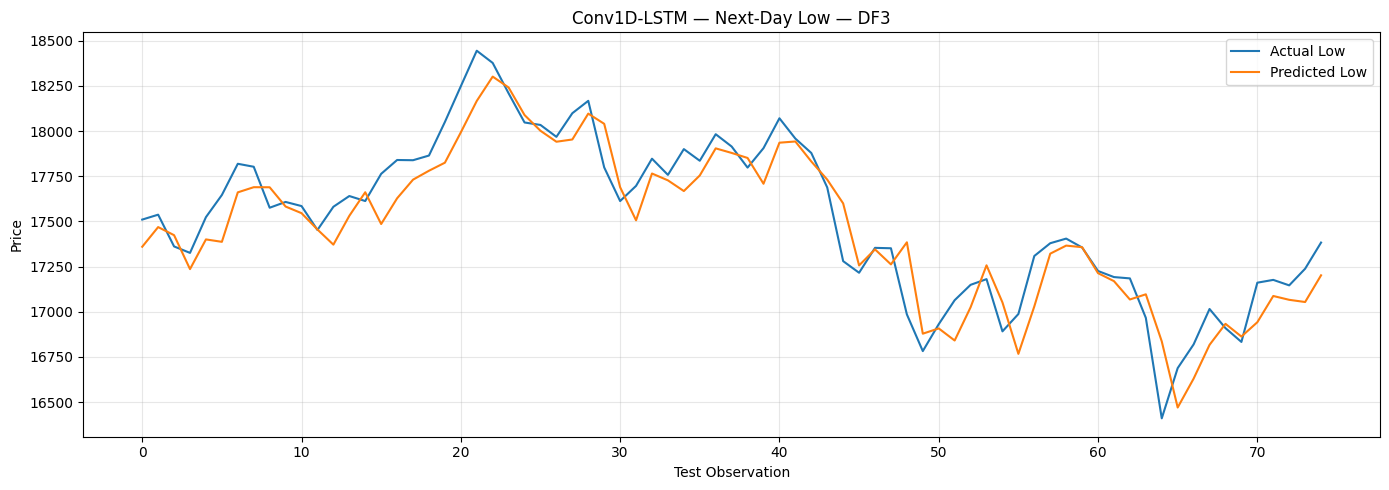



Conv1D-LSTM TRAINING — DF4
Total observations: 962
Train: 673
Validation: 144
Test: 145

Sequence shapes:
X_train: (648, 25, 4)
y_train: (648, 2)
X_val: (144, 25, 4)
y_val: (144, 2)
X_test: (145, 25, 4)
y_test: (145, 2)

Model architecture:


Model: "functional_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 25, 4)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_6 (Conv1D)               │ (None, 25, 64)         │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_7 (Conv1D)               │ (None, 25, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_8 (LSTM)                   │ (None, 25, 64)         │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_9 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 59,698 (233.20 KB)

 Trainable params: 59,442 (232.20 KB)

 Non-trainable params: 256 (1.00 KB)

Epoch 1/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 8s 64ms/step - loss: 0.1386 - mae: 0.2836 - val_loss: 0.0580 - val_mae: 0.2236 - learning_rate: 0.0010
Epoch 2/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 0.0266 - mae: 0.1268 - val_loss: 0.0198 - val_mae: 0.1122 - learning_rate: 0.0010
Epoch 3/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 0.0198 - mae: 0.1068 - val_loss: 0.0172 - val_mae: 0.1020 - learning_rate: 0.0010
Epoch 4/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 0.0176 - mae: 0.1010 - val_loss: 0.0160 - val_mae: 0.0971 - learning_rate: 0.0010
Epoch 5/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 0.0168 - mae: 0.0972 - val_loss: 0.0128 - val_mae: 0.0826 - learning_rate: 0.0010
Epoch 6/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 0.0164 - mae: 0.0958 - val_loss: 0.0114 - val_mae: 0.0756 - learning_rate: 0.0010
Epoch 7/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 0.0162 - mae: 0.0949 - val_loss: 0.0097 - val_mae: 0.0668 - learning_rate: 0.0010
Epoch 

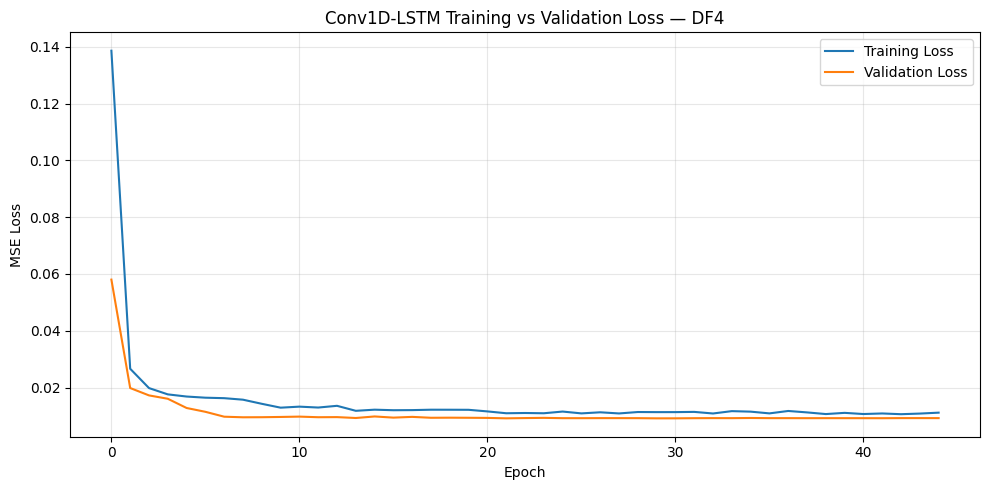

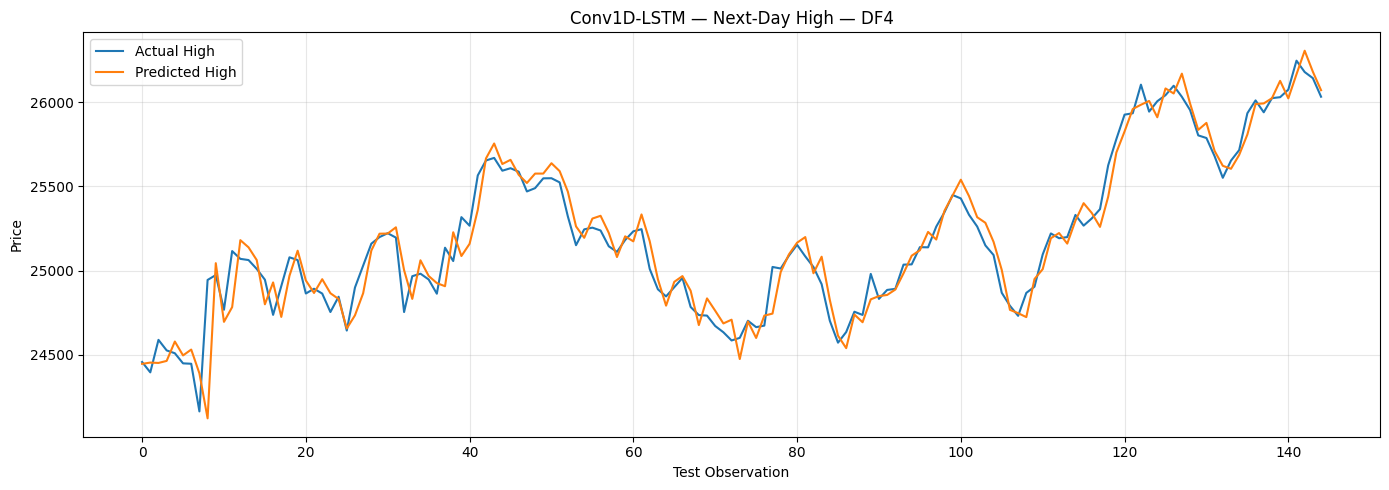

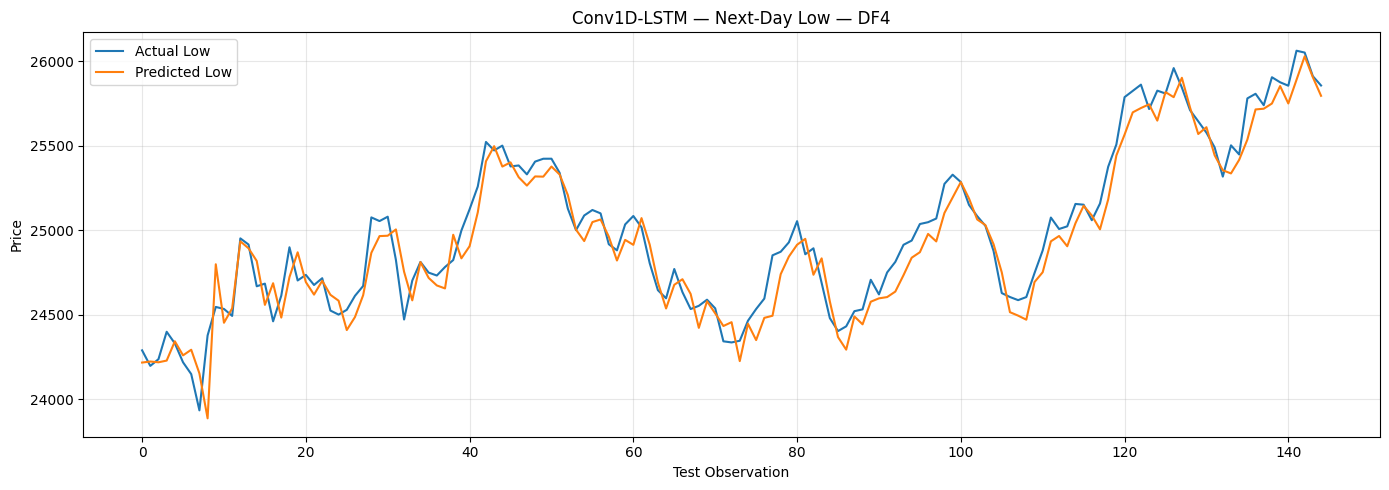



FINAL Conv1D-LSTM BASELINE RESULTS


,Regime,High_MAE,High_RMSE,High_R2,High_MAPE,Low_MAE,Low_RMSE,Low_R2,Low_MAPE,Best_Epoch
0,DF1,95.178376,102.511898,0.883458,1.617245,40.613861,48.309703,0.971827,0.702881,42
1,DF2,50.992310,76.433209,0.978493,0.452955,57.508182,78.553789,0.978231,0.519040,28
2,DF3,82.565634,104.268630,0.935290,0.468030,123.451086,155.737860,0.870704,0.707227,40
3,DF4,84.194803,120.181931,0.930587,0.335011,100.329891,124.362766,0.931629,0.402231,45



Results saved as: Conv1D_LSTM_baseline_results.csv
Predictions saved as: Conv1D_LSTM_baseline_predictions.xlsx


In [50]:
# ============================================================
# Conv1D-LSTM BASELINE — NIFTY 50 REGIME-WISE FORECASTING
# Target: Next-Day High and Low
# Protocol: 70% Train / 15% Validation / 15% Test
# ============================================================

import os
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    BatchNormalization,
    Activation,
    Dropout,
    LSTM,
    Dense
)

from tensorflow.keras.optimizers import Adam

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")


# ============================================================
# 1. REPRODUCIBILITY
# ============================================================

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except:
    pass


# ============================================================
# 2. FIXED BASELINE HYPERPARAMETERS
# ============================================================

LOOKBACK = 25

# CNN
CONV_FILTERS = 64
KERNEL_SIZE = 3

# Regularization
DROPOUT = 0.20

# LSTM
LSTM_UNITS_1 = 64
LSTM_UNITS_2 = 32

# Dense
DENSE_UNITS = 16

# Training
LEARNING_RATE = 0.001
BATCH_SIZE = 32
EPOCHS = 150

# Callbacks
EARLY_STOPPING_PATIENCE = 15

LR_PATIENCE = 7
LR_FACTOR = 0.5


# ============================================================
# 3. INPUT FEATURES
# ============================================================

FEATURES = [
    "Open",
    "High",
    "Low",
    "Close"
]


# ============================================================
# 4. CHECK REQUIRED COLUMNS
# ============================================================

required_columns = FEATURES + ["Date"]

missing_columns = [
    col
    for col in required_columns
    if col not in df.columns
]

if missing_columns:

    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )


# ============================================================
# 5. PREPARE DATA
# ============================================================

data = df.copy()

data["Date"] = pd.to_datetime(
    data["Date"]
)

data = (
    data
    .sort_values("Date")
    .reset_index(drop=True)
)

# Ensure OHLC are numeric
for col in FEATURES:

    data[col] = pd.to_numeric(
        data[col],
        errors="coerce"
    )

data = data.dropna(
    subset=FEATURES
).reset_index(drop=True)


# ============================================================
# 6. DEFINE MARKET REGIMES
# ============================================================

REGIMES = {

    "DF1": (
        "2007-01-01",
        "2010-12-31"
    ),

    "DF2": (
        "2011-01-01",
        "2019-12-31"
    ),

    "DF3": (
        "2020-01-01",
        "2021-12-31"
    ),

    "DF4": (
        "2022-01-01",
        None
    )
}


# ============================================================
# 7. CREATE NORMALIZED TARGETS
# ============================================================
#
# Predict:
#
#     High(t+1) / Close(t)
#     Low(t+1)  / Close(t)
#
# Then reconstruct:
#
#     Predicted High =
#         Predicted Ratio × Close(t)
#
#     Predicted Low =
#         Predicted Ratio × Close(t)
#
# ============================================================

data["Target_High_Ratio"] = (
    data["High"].shift(-1)
    / data["Close"]
)

data["Target_Low_Ratio"] = (
    data["Low"].shift(-1)
    / data["Close"]
)

data = data.dropna(
    subset=[
        "Target_High_Ratio",
        "Target_Low_Ratio"
    ]
).reset_index(drop=True)


# ============================================================
# 8. TRAIN SEQUENCE CREATION
# ============================================================

def create_train_sequences(
    X,
    y,
    lookback
):

    X_seq = []
    y_seq = []

    for i in range(
        lookback,
        len(X)
    ):

        X_seq.append(
            X[i-lookback:i]
        )

        y_seq.append(
            y[i]
        )

    return (
        np.array(X_seq),
        np.array(y_seq)
    )


# ============================================================
# 9. VALIDATION / TEST SEQUENCE CREATION
# ============================================================

def create_partition_sequences(
    history_X,
    partition_X,
    partition_y,
    lookback
):

    X_combined = np.concatenate(
        [
            history_X,
            partition_X
        ],
        axis=0
    )

    X_seq = []
    y_seq = []

    for i in range(
        len(partition_y)
    ):

        X_seq.append(
            X_combined[
                i:i + lookback
            ]
        )

        y_seq.append(
            partition_y[i]
        )

    return (
        np.array(X_seq),
        np.array(y_seq)
    )


# ============================================================
# 10. BUILD IMPROVED Conv1D-LSTM MODEL
# ============================================================

def build_conv1d_lstm_model(
    input_shape
):

    inputs = Input(
        shape=input_shape
    )

    # ========================================================
    # CNN FEATURE EXTRACTION
    # ========================================================

    x = Conv1D(
        filters=CONV_FILTERS,
        kernel_size=KERNEL_SIZE,
        padding="same"
    )(inputs)

    x = BatchNormalization()(x)

    x = Activation(
        "relu"
    )(x)

    x = Dropout(
        DROPOUT
    )(x)


    # ========================================================
    # SECOND CNN LAYER
    # ========================================================

    x = Conv1D(
        filters=CONV_FILTERS,
        kernel_size=KERNEL_SIZE,
        padding="same"
    )(x)

    x = BatchNormalization()(x)

    x = Activation(
        "relu"
    )(x)

    x = Dropout(
        DROPOUT
    )(x)


    # ========================================================
    # LSTM TEMPORAL MODELING
    # ========================================================

    x = LSTM(
        LSTM_UNITS_1,
        return_sequences=True
    )(x)

    x = Dropout(
        DROPOUT
    )(x)


    # ========================================================
    # SECOND LSTM
    # ========================================================

    x = LSTM(
        LSTM_UNITS_2,
        return_sequences=False
    )(x)

    x = Dropout(
        DROPOUT
    )(x)


    # ========================================================
    # DENSE FORECASTING HEAD
    # ========================================================

    x = Dense(
        DENSE_UNITS,
        activation="relu"
    )(x)

    outputs = Dense(
        2,
        activation="linear"
    )(x)


    # ========================================================
    # CREATE MODEL
    # ========================================================

    model = Model(
        inputs=inputs,
        outputs=outputs
    )


    # ========================================================
    # COMPILE
    # ========================================================

    optimizer = Adam(
        learning_rate=LEARNING_RATE
    )

    model.compile(
        optimizer=optimizer,
        loss="mse",
        metrics=["mae"]
    )

    return model


# ============================================================
# 11. METRIC FUNCTION
# ============================================================

def calculate_metrics(
    y_true,
    y_pred
):

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    denominator = np.where(
        np.abs(y_true) < 1e-8,
        1e-8,
        np.abs(y_true)
    )

    mape = np.mean(
        np.abs(
            (y_true - y_pred)
            / denominator
        )
    ) * 100

    return (
        mae,
        rmse,
        r2,
        mape
    )


# ============================================================
# 12. STORAGE
# ============================================================

all_results = []

all_predictions = {}

all_histories = {}

all_models = {}


# ============================================================
# 13. TRAIN EACH MARKET REGIME
# ============================================================

for regime_name, (
    start_date,
    end_date
) in REGIMES.items():

    print("\n")
    print("=" * 75)
    print(
        f"Conv1D-LSTM TRAINING — {regime_name}"
    )
    print("=" * 75)


    # ========================================================
    # FILTER REGIME
    # ========================================================

    regime_data = data[
        data["Date"] >=
        pd.Timestamp(start_date)
    ].copy()

    if end_date is not None:

        regime_data = regime_data[
            regime_data["Date"] <=
            pd.Timestamp(end_date)
        ]

    regime_data = (
        regime_data
        .sort_values("Date")
        .reset_index(drop=True)
    )


    print(
        f"Total observations: "
        f"{len(regime_data)}"
    )


    if len(regime_data) <= LOOKBACK + 20:

        print(
            f"Skipping {regime_name}: "
            "insufficient observations."
        )

        continue


    # ========================================================
    # FEATURES / TARGETS
    # ========================================================

    X_raw = regime_data[
        FEATURES
    ].values

    y_raw = regime_data[
        [
            "Target_High_Ratio",
            "Target_Low_Ratio"
        ]
    ].values


    # ========================================================
    # CHRONOLOGICAL 70 / 15 / 15 SPLIT
    # ========================================================

    n = len(regime_data)

    train_end = int(
        n * 0.70
    )

    val_end = int(
        n * 0.85
    )


    X_train_raw = X_raw[
        :train_end
    ]

    X_val_raw = X_raw[
        train_end:val_end
    ]

    X_test_raw = X_raw[
        val_end:
    ]


    y_train = y_raw[
        :train_end
    ]

    y_val = y_raw[
        train_end:val_end
    ]

    y_test = y_raw[
        val_end:
    ]


    print(
        f"Train: "
        f"{len(X_train_raw)}"
    )

    print(
        f"Validation: "
        f"{len(X_val_raw)}"
    )

    print(
        f"Test: "
        f"{len(X_test_raw)}"
    )


    # ========================================================
    # 14. SCALE INPUTS — TRAIN ONLY
    # ========================================================

    X_scaler = MinMaxScaler()

    X_scaler.fit(
        X_train_raw
    )

    X_train_scaled = X_scaler.transform(
        X_train_raw
    )

    X_val_scaled = X_scaler.transform(
        X_val_raw
    )

    X_test_scaled = X_scaler.transform(
        X_test_raw
    )


    # ========================================================
    # 15. SCALE TARGETS — TRAIN ONLY
    # ========================================================

    y_scaler = MinMaxScaler()

    y_scaler.fit(
        y_train
    )

    y_train_scaled = y_scaler.transform(
        y_train
    )

    y_val_scaled = y_scaler.transform(
        y_val
    )

    y_test_scaled = y_scaler.transform(
        y_test
    )


    # ========================================================
    # 16. TRAIN SEQUENCES
    # ========================================================

    X_train, y_train_seq = (
        create_train_sequences(
            X_train_scaled,
            y_train_scaled,
            LOOKBACK
        )
    )


    # ========================================================
    # 17. VALIDATION SEQUENCES
    # ========================================================

    X_val, y_val_seq = (
        create_partition_sequences(
            history_X=
                X_train_scaled[-LOOKBACK:],

            partition_X=
                X_val_scaled,

            partition_y=
                y_val_scaled,

            lookback=
                LOOKBACK
        )
    )


    # ========================================================
    # 18. TEST SEQUENCES
    # ========================================================

    X_test, y_test_seq = (
        create_partition_sequences(
            history_X=
                X_val_scaled[-LOOKBACK:],

            partition_X=
                X_test_scaled,

            partition_y=
                y_test_scaled,

            lookback=
                LOOKBACK
        )
    )


    print("\nSequence shapes:")

    print(
        "X_train:",
        X_train.shape
    )

    print(
        "y_train:",
        y_train_seq.shape
    )

    print(
        "X_val:",
        X_val.shape
    )

    print(
        "y_val:",
        y_val_seq.shape
    )

    print(
        "X_test:",
        X_test.shape
    )

    print(
        "y_test:",
        y_test_seq.shape
    )


    # ========================================================
    # 19. BUILD MODEL
    # ========================================================

    model = build_conv1d_lstm_model(
        input_shape=(
            LOOKBACK,
            len(FEATURES)
        )
    )

    print("\nModel architecture:")

    model.summary()


    # ========================================================
    # 20. CALLBACKS
    # ========================================================

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=EARLY_STOPPING_PATIENCE,
        restore_best_weights=True,
        verbose=1
    )

    reduce_lr = ReduceLROnPlateau(
        monitor="val_loss",
        factor=LR_FACTOR,
        patience=LR_PATIENCE,
        min_lr=1e-6,
        verbose=1
    )


    # ========================================================
    # 21. TRAIN
    # ========================================================

    history = model.fit(

        X_train,
        y_train_seq,

        validation_data=(
            X_val,
            y_val_seq
        ),

        epochs=EPOCHS,

        batch_size=BATCH_SIZE,

        callbacks=[
            early_stopping,
            reduce_lr
        ],

        shuffle=False,

        verbose=1
    )


    # ========================================================
    # 22. PREDICT TEST SET
    # ========================================================

    y_pred_scaled = model.predict(
        X_test,
        verbose=0
    )


    # ========================================================
    # 23. INVERSE TARGET SCALING
    # ========================================================

    y_pred_ratio = (
        y_scaler.inverse_transform(
            y_pred_scaled
        )
    )

    y_test_ratio = (
        y_scaler.inverse_transform(
            y_test_seq
        )
    )


    # ========================================================
    # 24. CURRENT CLOSE
    # ========================================================

    close_index = FEATURES.index(
        "Close"
    )

    current_close_test = X_test_raw[
        :,
        close_index
    ]


    # ========================================================
    # 25. RECONSTRUCT ABSOLUTE PRICES
    # ========================================================

    actual_high = (
        y_test_ratio[:, 0]
        * current_close_test
    )

    predicted_high = (
        y_pred_ratio[:, 0]
        * current_close_test
    )

    actual_low = (
        y_test_ratio[:, 1]
        * current_close_test
    )

    predicted_low = (
        y_pred_ratio[:, 1]
        * current_close_test
    )


    # ========================================================
    # 26. HIGH METRICS
    # ========================================================

    (
        high_mae,
        high_rmse,
        high_r2,
        high_mape
    ) = calculate_metrics(
        actual_high,
        predicted_high
    )


    # ========================================================
    # 27. LOW METRICS
    # ========================================================

    (
        low_mae,
        low_rmse,
        low_r2,
        low_mape
    ) = calculate_metrics(
        actual_low,
        predicted_low
    )


    # ========================================================
    # 28. PRINT RESULTS
    # ========================================================

    print("\n")
    print("=" * 75)
    print(
        f"Conv1D-LSTM RESULTS — {regime_name}"
    )
    print("=" * 75)


    print("\nNEXT-DAY HIGH")

    print(
        f"MAE  : {high_mae:.6f}"
    )

    print(
        f"RMSE : {high_rmse:.6f}"
    )

    print(
        f"R²   : {high_r2:.6f}"
    )

    print(
        f"MAPE : {high_mape:.6f}%"
    )


    print("\nNEXT-DAY LOW")

    print(
        f"MAE  : {low_mae:.6f}"
    )

    print(
        f"RMSE : {low_rmse:.6f}"
    )

    print(
        f"R²   : {low_r2:.6f}"
    )

    print(
        f"MAPE : {low_mape:.6f}%"
    )


    # ========================================================
    # 29. STORE RESULTS
    # ========================================================

    all_results.append({

        "Regime":
            regime_name,

        "High_MAE":
            high_mae,

        "High_RMSE":
            high_rmse,

        "High_R2":
            high_r2,

        "High_MAPE":
            high_mape,

        "Low_MAE":
            low_mae,

        "Low_RMSE":
            low_rmse,

        "Low_R2":
            low_r2,

        "Low_MAPE":
            low_mape,

        "Best_Epoch":
            len(
                history.history["loss"]
            )
    })


    # ========================================================
    # 30. STORE PREDICTIONS
    # ========================================================

    test_dates = regime_data[
        "Date"
    ].iloc[
        val_end:
    ].values


    prediction_df = pd.DataFrame({

        "Date":
            test_dates,

        "Current_Close":
            current_close_test,

        "Actual_High":
            actual_high,

        "Predicted_High":
            predicted_high,

        "Actual_Low":
            actual_low,

        "Predicted_Low":
            predicted_low

    })


    all_predictions[
        regime_name
    ] = prediction_df


    all_histories[
        regime_name
    ] = history.history


    all_models[
        regime_name
    ] = model


    # ========================================================
    # 31. TRAINING / VALIDATION LOSS
    # ========================================================

    plt.figure(
        figsize=(10, 5)
    )

    plt.plot(
        history.history["loss"],
        label="Training Loss"
    )

    plt.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.title(
        f"Conv1D-LSTM Training vs Validation Loss — {regime_name}"
    )

    plt.xlabel(
        "Epoch"
    )

    plt.ylabel(
        "MSE Loss"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


    # ========================================================
    # 32. HIGH PREDICTION PLOT
    # ========================================================

    plt.figure(
        figsize=(14, 5)
    )

    plt.plot(
        actual_high,
        label="Actual High"
    )

    plt.plot(
        predicted_high,
        label="Predicted High"
    )

    plt.title(
        f"Conv1D-LSTM — Next-Day High — {regime_name}"
    )

    plt.xlabel(
        "Test Observation"
    )

    plt.ylabel(
        "Price"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


    # ========================================================
    # 33. LOW PREDICTION PLOT
    # ========================================================

    plt.figure(
        figsize=(14, 5)
    )

    plt.plot(
        actual_low,
        label="Actual Low"
    )

    plt.plot(
        predicted_low,
        label="Predicted Low"
    )

    plt.title(
        f"Conv1D-LSTM — Next-Day Low — {regime_name}"
    )

    plt.xlabel(
        "Test Observation"
    )

    plt.ylabel(
        "Price"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


# ============================================================
# 34. FINAL RESULTS TABLE
# ============================================================

results_df = pd.DataFrame(
    all_results
)

print("\n")
print("=" * 95)
print("FINAL Conv1D-LSTM BASELINE RESULTS")
print("=" * 95)

display(
    results_df.round(6)
)


# ============================================================
# 35. SAVE RESULTS
# ============================================================

results_df.to_csv(
    "Conv1D_LSTM_baseline_results.csv",
    index=False
)

print(
    "\nResults saved as:"
    " Conv1D_LSTM_baseline_results.csv"
)


# ============================================================
# 36. SAVE PREDICTIONS
# ============================================================

with pd.ExcelWriter(
    "Conv1D_LSTM_baseline_predictions.xlsx",
    engine="openpyxl"
) as writer:

    results_df.to_excel(
        writer,
        sheet_name="Results",
        index=False
    )

    for regime_name, prediction_df in (
        all_predictions.items()
    ):

        prediction_df.to_excel(
            writer,
            sheet_name=regime_name,
            index=False
        )


print(
    "Predictions saved as:"
    " Conv1D_LSTM_baseline_predictions.xlsx"
)



ConvLSTM-STYLE TRAINING — DF1
Total observations: 808
Train: 565
Validation: 121
Test: 122

Sequence shapes:
X_train: (540, 25, 4)
X_val: (121, 25, 4)
X_test: (122, 25, 4)

Model architecture:


Model: "functional_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 25, 4)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_8 (Conv1D)               │ (None, 25, 64)         │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_9 (Conv1D)               │ (None, 25, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_9 (Activation)       │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_10 (LSTM)                  │ (None, 25, 64)         │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_19 (Dropout)            │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_11 (LSTM)                  │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 59,698 (233.20 KB)

 Trainable params: 59,442 (232.20 KB)

 Non-trainable params: 256 (1.00 KB)

Epoch 1/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 8s 89ms/step - loss: 0.0617 - mae: 0.1772 - val_loss: 0.1677 - val_mae: 0.3211 - learning_rate: 0.0010
Epoch 2/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 0.0211 - mae: 0.1083 - val_loss: 0.1443 - val_mae: 0.2955 - learning_rate: 0.0010
Epoch 3/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.0167 - mae: 0.0964 - val_loss: 0.1499 - val_mae: 0.3009 - learning_rate: 0.0010
Epoch 4/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 0.0143 - mae: 0.0854 - val_loss: 0.1296 - val_mae: 0.2694 - learning_rate: 0.0010
Epoch 5/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 0.0132 - mae: 0.0841 - val_loss: 0.1139 - val_mae: 0.2512 - learning_rate: 0.0010
Epoch 6/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 0.0137 - mae: 0.0868 - val_loss: 0.1013 - val_mae: 0.2379 - learning_rate: 0.0010
Epoch 7/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.0120 - mae: 0.0790 - val_loss: 0.0834 - val_mae: 0.2159 - learning_rate: 0.0010
Epoch 

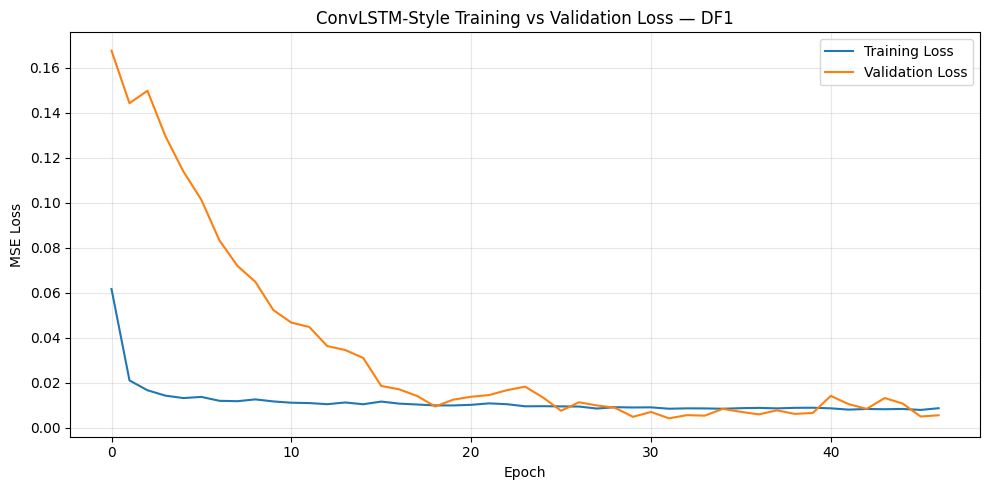

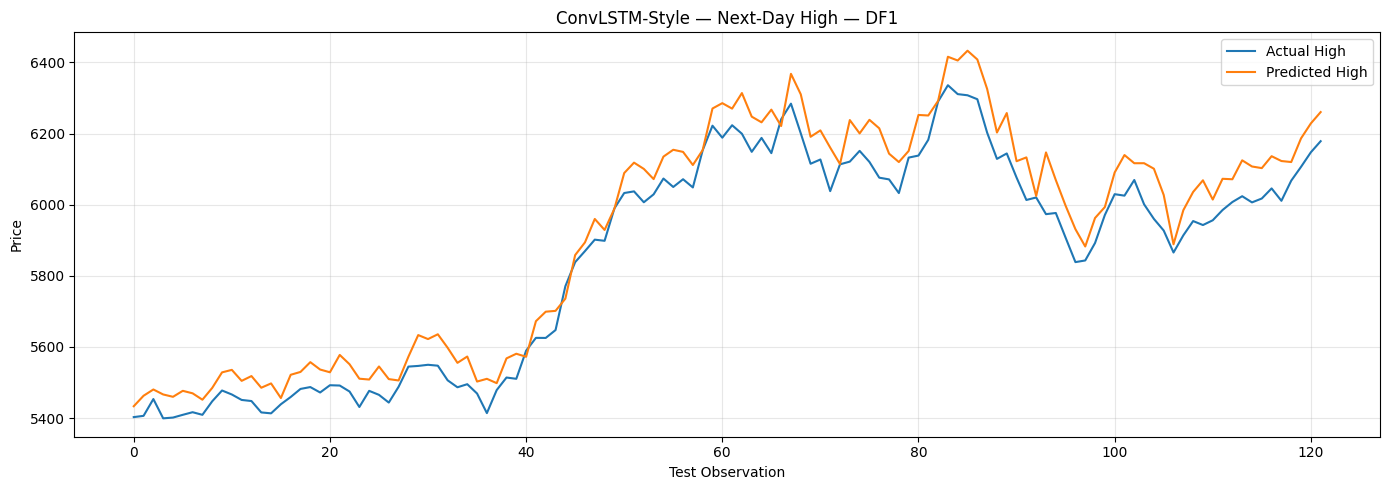

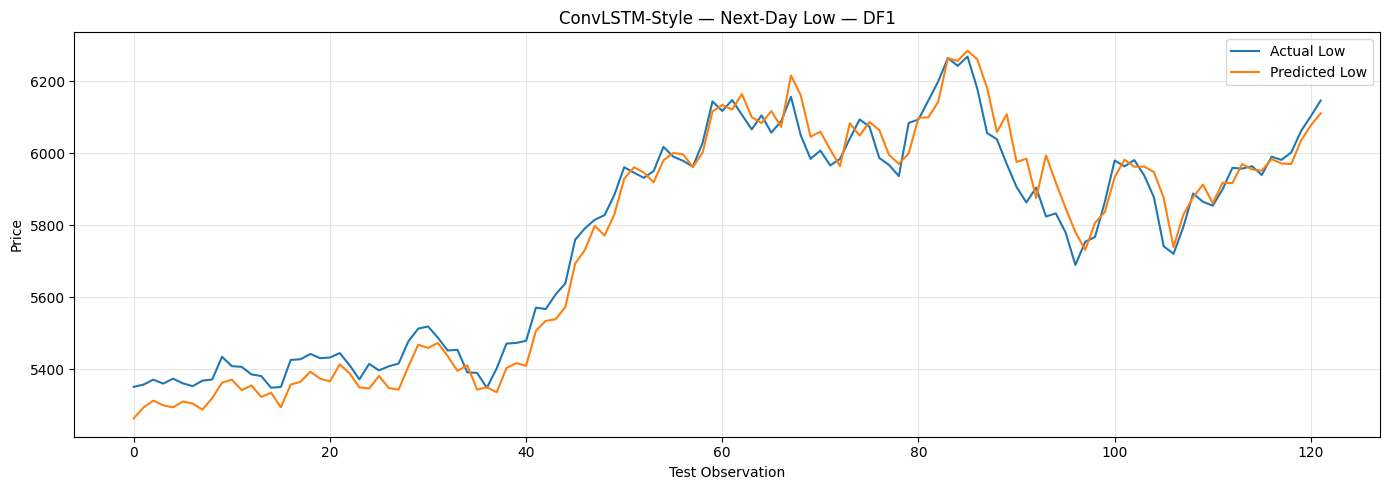



ConvLSTM-STYLE TRAINING — DF2
Total observations: 2193
Train: 1535
Validation: 329
Test: 329

Sequence shapes:
X_train: (1510, 25, 4)
X_val: (329, 25, 4)
X_test: (329, 25, 4)

Model architecture:


Model: "functional_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 25, 4)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_10 (Conv1D)              │ (None, 25, 64)         │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_10 (Activation)      │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_21 (Dropout)            │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_11 (Conv1D)              │ (None, 25, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_11 (Activation)      │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_12 (LSTM)                  │ (None, 25, 64)         │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_22 (Dropout)            │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_13 (LSTM)                  │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_23 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 59,698 (233.20 KB)

 Trainable params: 59,442 (232.20 KB)

 Non-trainable params: 256 (1.00 KB)

Epoch 1/150
48/48 ━━━━━━━━━━━━━━━━━━━━ 8s 49ms/step - loss: 0.0345 - mae: 0.1381 - val_loss: 0.0381 - val_mae: 0.1708 - learning_rate: 0.0010
Epoch 2/150
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0133 - mae: 0.0896 - val_loss: 0.0173 - val_mae: 0.1081 - learning_rate: 0.0010
Epoch 3/150
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0109 - mae: 0.0810 - val_loss: 0.0073 - val_mae: 0.0733 - learning_rate: 0.0010
Epoch 4/150
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0100 - mae: 0.0770 - val_loss: 0.0036 - val_mae: 0.0513 - learning_rate: 0.0010
Epoch 5/150
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0100 - mae: 0.0755 - val_loss: 0.0059 - val_mae: 0.0652 - learning_rate: 0.0010
Epoch 6/150
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0082 - mae: 0.0686 - val_loss: 0.0026 - val_mae: 0.0428 - learning_rate: 0.0010
Epoch 7/150
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0082 - mae: 0.0670 - val_loss: 0.0026 - val_mae: 0.0432 - learning_rate: 0.0010
Epoch 

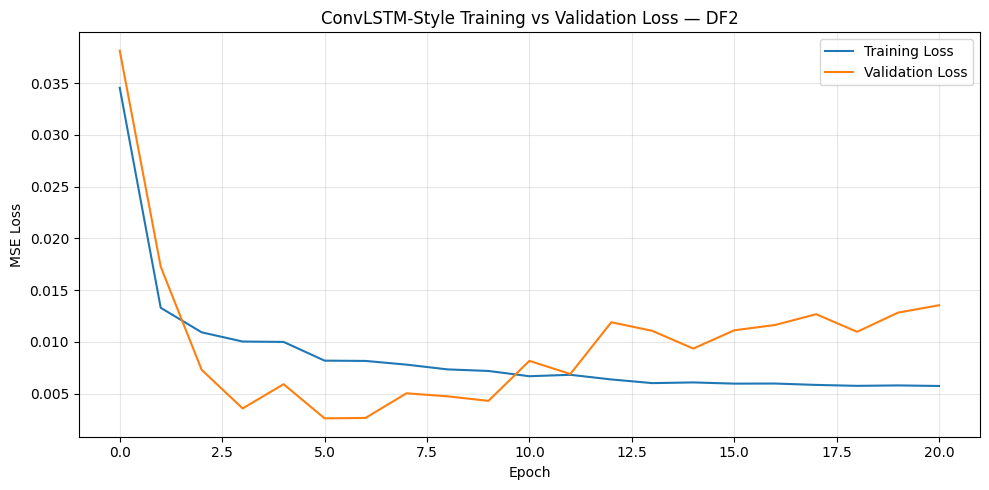

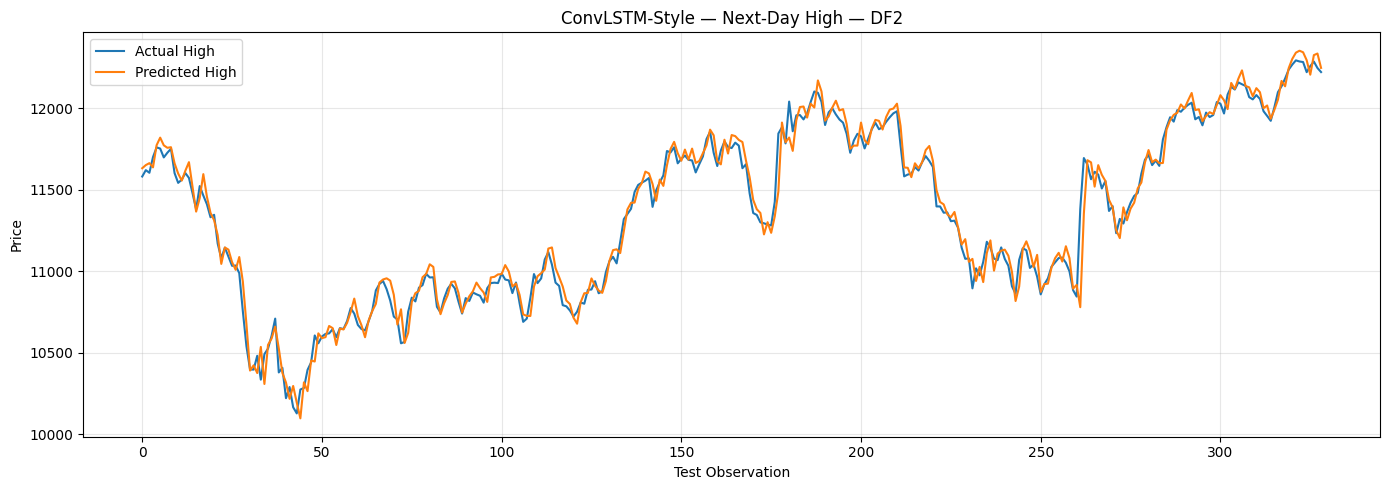

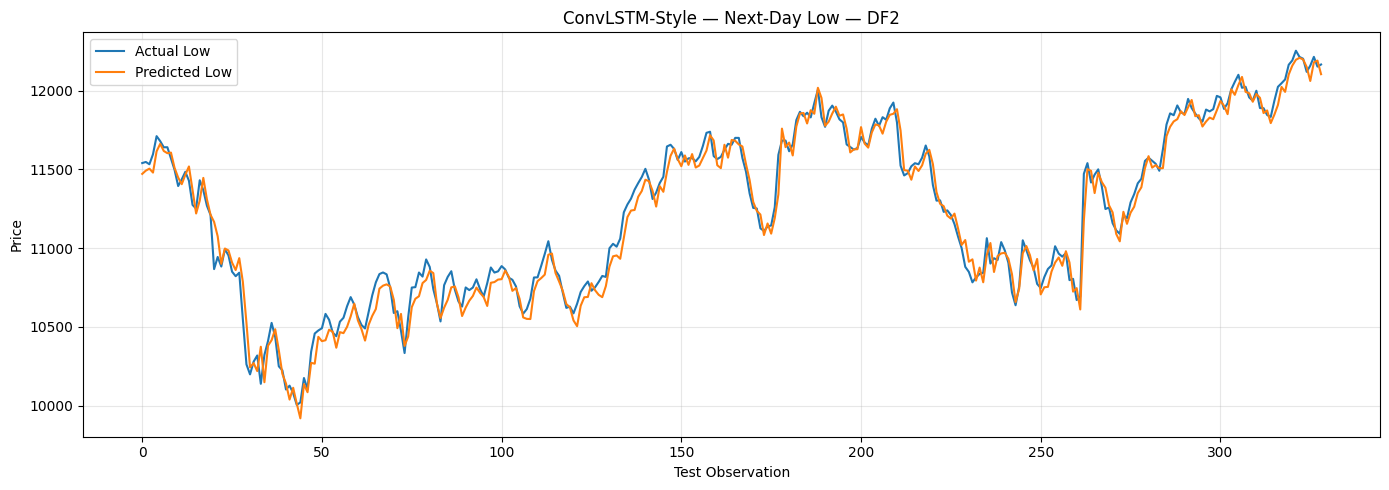



ConvLSTM-STYLE TRAINING — DF3
Total observations: 498
Train: 348
Validation: 75
Test: 75

Sequence shapes:
X_train: (323, 25, 4)
X_val: (75, 25, 4)
X_test: (75, 25, 4)

Model architecture:


Model: "functional_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 25, 4)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_12 (Conv1D)              │ (None, 25, 64)         │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_12 (Activation)      │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_24 (Dropout)            │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_13 (Conv1D)              │ (None, 25, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_13 (Activation)      │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_14 (LSTM)                  │ (None, 25, 64)         │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_25 (Dropout)            │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_15 (LSTM)                  │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_26 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 59,698 (233.20 KB)

 Trainable params: 59,442 (232.20 KB)

 Non-trainable params: 256 (1.00 KB)

Epoch 1/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 7s 95ms/step - loss: 0.0857 - mae: 0.2239 - val_loss: 0.1135 - val_mae: 0.3215 - learning_rate: 0.0010
Epoch 2/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0353 - mae: 0.1408 - val_loss: 0.0593 - val_mae: 0.2183 - learning_rate: 0.0010
Epoch 3/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.0286 - mae: 0.1281 - val_loss: 0.0732 - val_mae: 0.2591 - learning_rate: 0.0010
Epoch 4/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.0186 - mae: 0.1015 - val_loss: 0.0590 - val_mae: 0.2292 - learning_rate: 0.0010
Epoch 5/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0193 - mae: 0.1042 - val_loss: 0.0402 - val_mae: 0.1867 - learning_rate: 0.0010
Epoch 6/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.0186 - mae: 0.0982 - val_loss: 0.0447 - val_mae: 0.1968 - learning_rate: 0.0010
Epoch 7/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.0152 - mae: 0.0931 - val_loss: 0.0317 - val_mae: 0.1641 - learning_rate: 0.0010
Epoch 

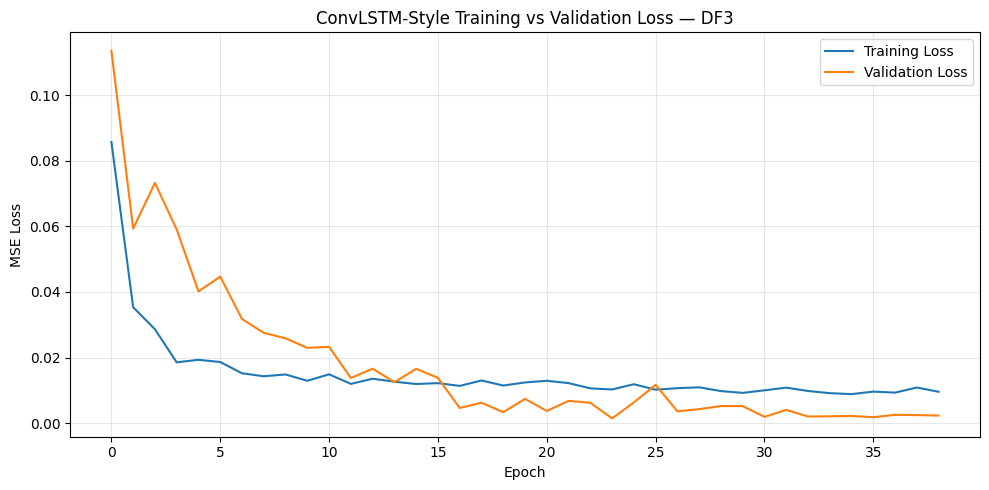

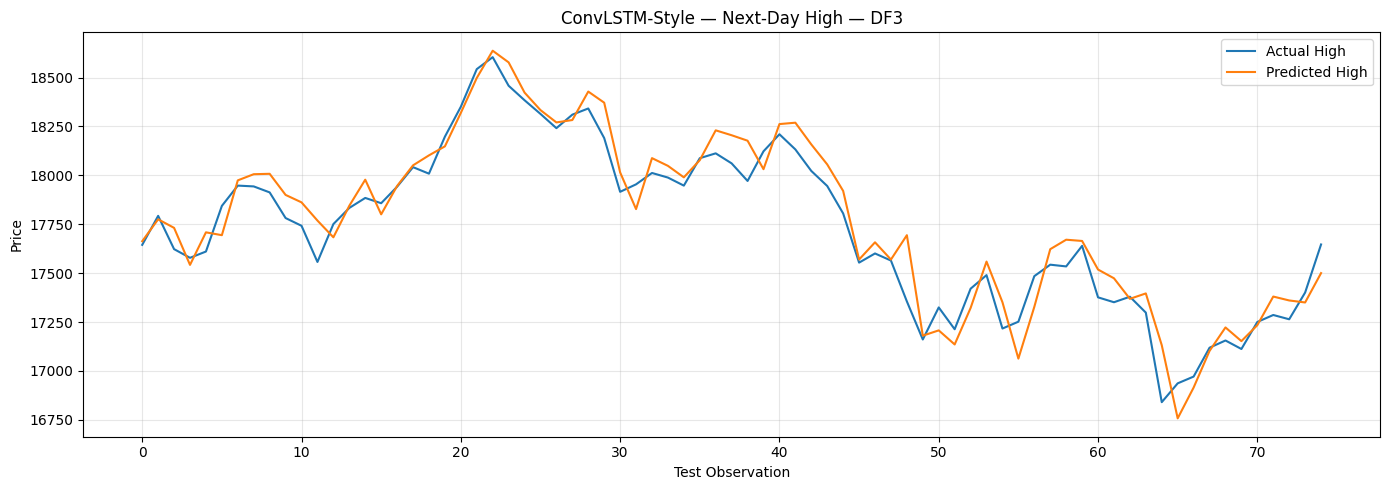

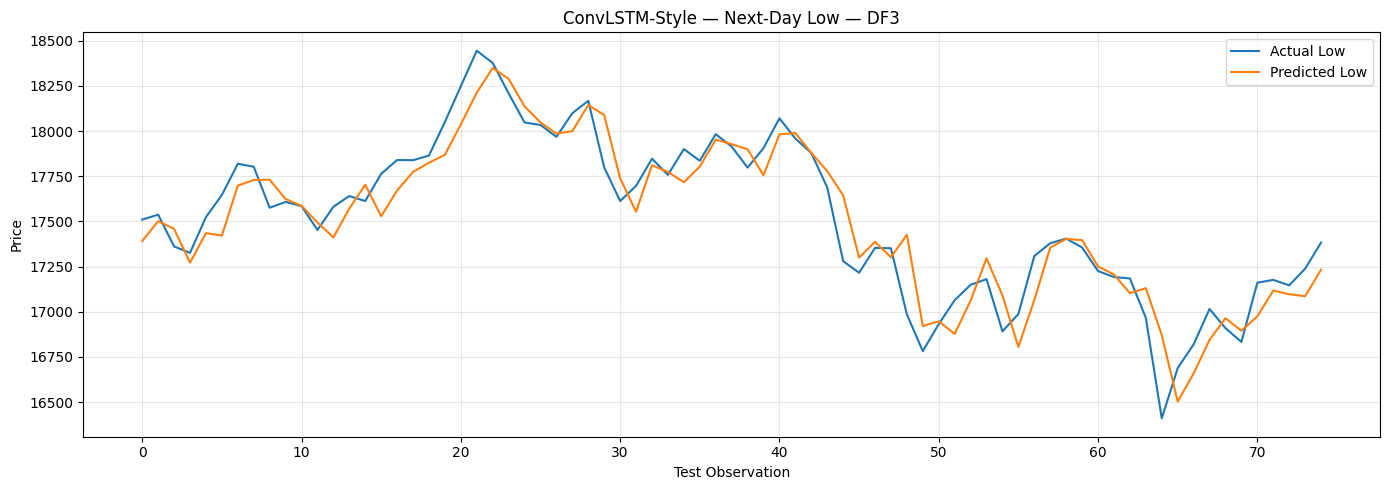



ConvLSTM-STYLE TRAINING — DF4
Total observations: 962
Train: 673
Validation: 144
Test: 145

Sequence shapes:
X_train: (648, 25, 4)
X_val: (144, 25, 4)
X_test: (145, 25, 4)

Model architecture:


Model: "functional_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 25, 4)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_14 (Conv1D)              │ (None, 25, 64)         │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_14 (Activation)      │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_27 (Dropout)            │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_15 (Conv1D)              │ (None, 25, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_15 (Activation)      │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_16 (LSTM)                  │ (None, 25, 64)         │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_28 (Dropout)            │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_17 (LSTM)                  │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_29 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 59,698 (233.20 KB)

 Trainable params: 59,442 (232.20 KB)

 Non-trainable params: 256 (1.00 KB)

Epoch 1/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 7s 57ms/step - loss: 0.0869 - mae: 0.2150 - val_loss: 0.0772 - val_mae: 0.2618 - learning_rate: 0.0010
Epoch 2/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0208 - mae: 0.1102 - val_loss: 0.0560 - val_mae: 0.2187 - learning_rate: 0.0010
Epoch 3/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0198 - mae: 0.1076 - val_loss: 0.0359 - val_mae: 0.1671 - learning_rate: 0.0010
Epoch 4/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0164 - mae: 0.0976 - val_loss: 0.0234 - val_mae: 0.1263 - learning_rate: 0.0010
Epoch 5/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0160 - mae: 0.0939 - val_loss: 0.0204 - val_mae: 0.1142 - learning_rate: 0.0010
Epoch 6/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0154 - mae: 0.0925 - val_loss: 0.0193 - val_mae: 0.1102 - learning_rate: 0.0010
Epoch 7/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0139 - mae: 0.0874 - val_loss: 0.0180 - val_mae: 0.1052 - learning_rate: 0.0010
Epoch 

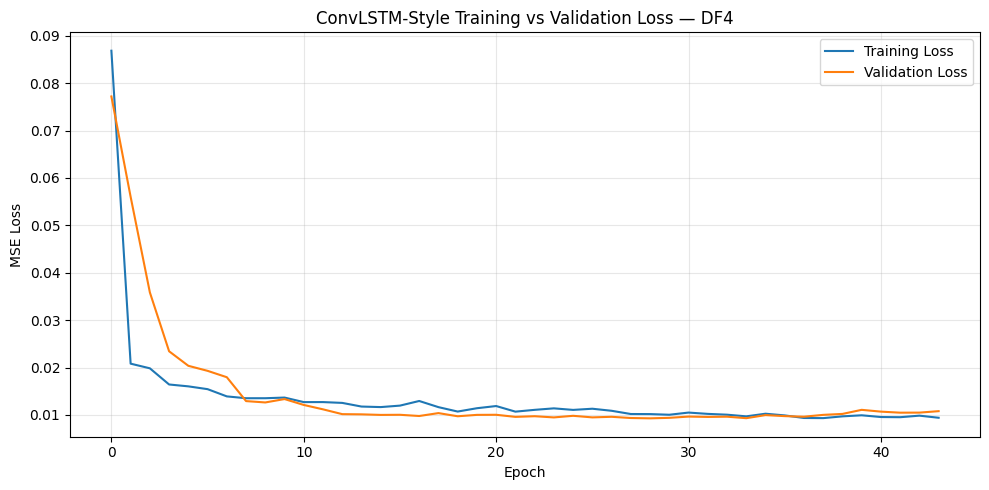

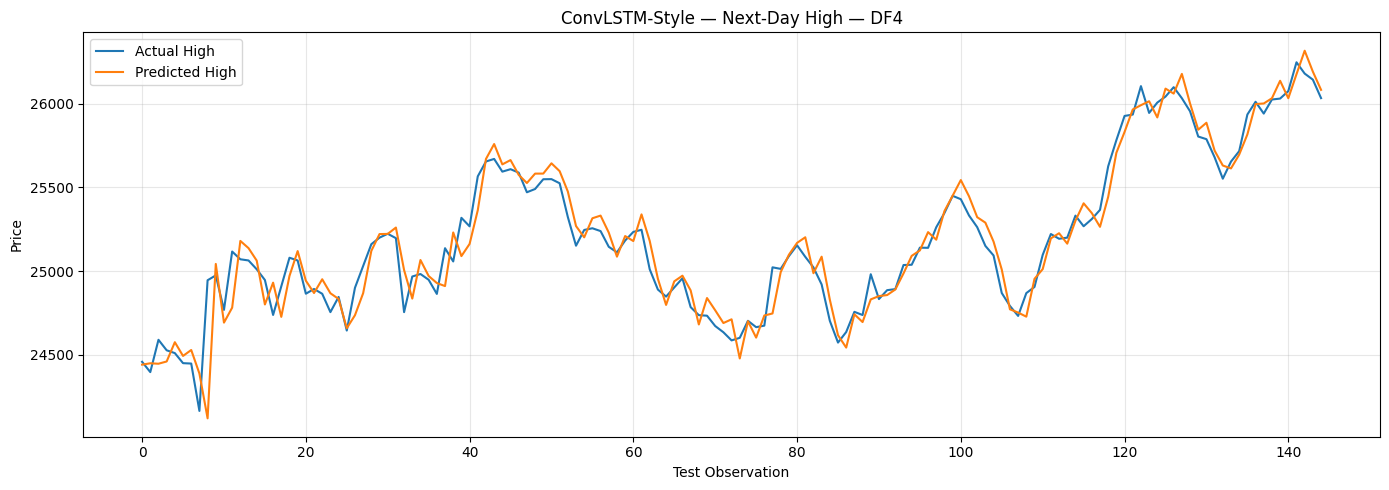

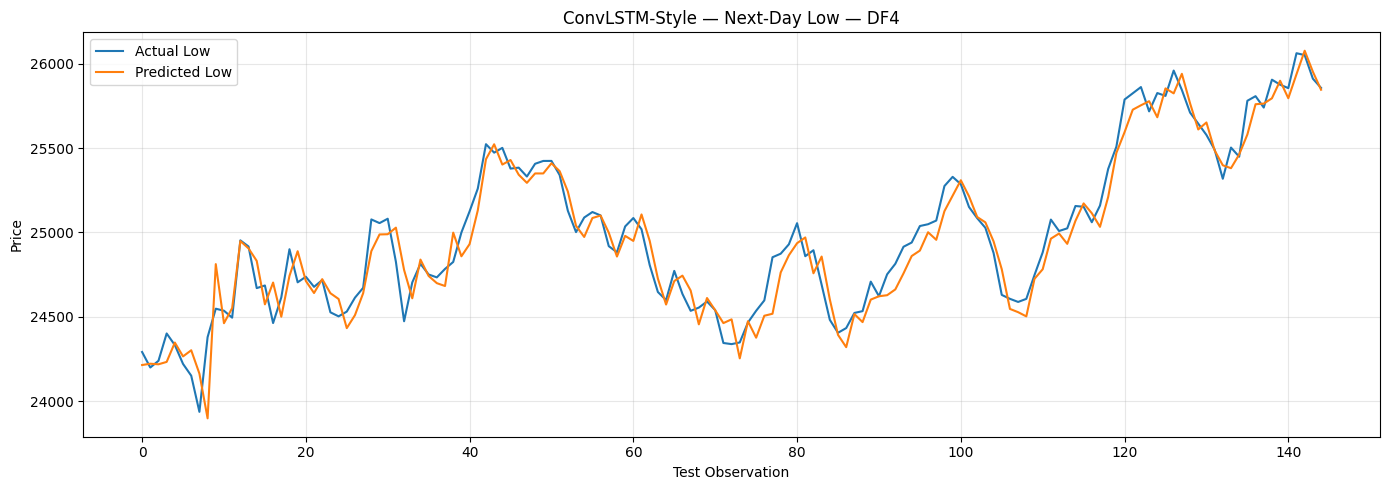



FINAL ConvLSTM-STYLE BASELINE RESULTS


,Regime,High_MAE,High_RMSE,High_R2,High_MAPE,Low_MAE,Low_RMSE,Low_R2,Low_MAPE,Best_Epoch
0,DF1,69.689021,77.545284,0.933312,1.185511,45.863902,55.125307,0.963316,0.801492,47
1,DF2,54.009704,77.555964,0.977856,0.479212,63.319656,80.482275,0.977149,0.570088,21
2,DF3,87.093020,108.398858,0.930061,0.493333,111.459518,146.292902,0.885911,0.640366,39
3,DF4,85.135419,120.948458,0.929699,0.338709,91.415870,115.663134,0.940860,0.366880,44



Results saved: ConvLSTM_style_baseline_results.csv
Predictions saved: ConvLSTM_style_baseline_predictions.xlsx


In [51]:
# ============================================================
# ConvLSTM-STYLE 1D BASELINE
# NIFTY 50 REGIME-WISE FORECASTING
#
# Target:
#   Next-Day High
#   Next-Day Low
#
# Protocol:
#   70% Train
#   15% Validation
#   15% Test
#
# Input:
#   Previous 25 trading days
#   Open, High, Low, Close
#
# IMPORTANT:
#   Baseline experiment only.
#   NO hyperparameter tuning yet.
# ============================================================


# ============================================================
# 1. IMPORTS
# ============================================================

import os
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    LSTM,
    Dropout,
    Dense,
    BatchNormalization,
    Activation,
    LayerNormalization
)

from tensorflow.keras.optimizers import Adam

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")


# ============================================================
# 2. REPRODUCIBILITY
# ============================================================

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)

tf.random.set_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except:
    pass


# ============================================================
# 3. BASELINE HYPERPARAMETERS
# ============================================================

LOOKBACK = 25

# Convolution
CONV_FILTERS = 64
KERNEL_SIZE = 3

# Recurrent layers
LSTM_UNITS_1 = 64
LSTM_UNITS_2 = 32

# Regularization
DROPOUT = 0.20

# Dense
DENSE_UNITS = 16

# Optimizer
LEARNING_RATE = 0.001

# Training
BATCH_SIZE = 32
EPOCHS = 150

# Callbacks
EARLY_STOPPING_PATIENCE = 15

LR_PATIENCE = 7
LR_FACTOR = 0.5


# ============================================================
# 4. FEATURES
# ============================================================

FEATURES = [
    "Open",
    "High",
    "Low",
    "Close"
]


# ============================================================
# 5. VERIFY DATA
# ============================================================

required_columns = FEATURES + ["Date"]

missing_columns = [
    col
    for col in required_columns
    if col not in df.columns
]

if missing_columns:

    raise ValueError(
        f"Missing columns: {missing_columns}"
    )


# ============================================================
# 6. PREPARE DATA
# ============================================================

data = df.copy()

data["Date"] = pd.to_datetime(
    data["Date"]
)

data = (
    data
    .sort_values("Date")
    .reset_index(drop=True)
)

for col in FEATURES:

    data[col] = pd.to_numeric(
        data[col],
        errors="coerce"
    )

data = data.dropna(
    subset=FEATURES
).reset_index(drop=True)


# ============================================================
# 7. MARKET REGIMES
# ============================================================

REGIMES = {

    "DF1": (
        "2007-01-01",
        "2010-12-31"
    ),

    "DF2": (
        "2011-01-01",
        "2019-12-31"
    ),

    "DF3": (
        "2020-01-01",
        "2021-12-31"
    ),

    "DF4": (
        "2022-01-01",
        None
    )
}


# ============================================================
# 8. NORMALIZED NEXT-DAY TARGETS
# ============================================================

# High(t+1) / Close(t)
data["Target_High_Ratio"] = (
    data["High"].shift(-1)
    / data["Close"]
)

# Low(t+1) / Close(t)
data["Target_Low_Ratio"] = (
    data["Low"].shift(-1)
    / data["Close"]
)

data = data.dropna(
    subset=[
        "Target_High_Ratio",
        "Target_Low_Ratio"
    ]
).reset_index(drop=True)


# ============================================================
# 9. TRAIN SEQUENCE CREATION
# ============================================================

def create_train_sequences(
    X,
    y,
    lookback
):

    X_seq = []
    y_seq = []

    for i in range(
        lookback,
        len(X)
    ):

        X_seq.append(
            X[
                i - lookback:i
            ]
        )

        y_seq.append(
            y[i]
        )

    return (
        np.array(X_seq),
        np.array(y_seq)
    )


# ============================================================
# 10. VALIDATION / TEST SEQUENCES
# ============================================================

def create_partition_sequences(
    history_X,
    partition_X,
    partition_y,
    lookback
):

    X_combined = np.concatenate(
        [
            history_X,
            partition_X
        ],
        axis=0
    )

    X_seq = []
    y_seq = []

    for i in range(
        len(partition_y)
    ):

        X_seq.append(
            X_combined[
                i:i + lookback
            ]
        )

        y_seq.append(
            partition_y[i]
        )

    return (
        np.array(X_seq),
        np.array(y_seq)
    )


# ============================================================
# 11. CUSTOM CONVOLUTION-RECURRENT BLOCK
# ============================================================
#
# The idea is:
#
#   Convolution
#       ↓
#   Short-term feature extraction
#       ↓
#   LSTM
#       ↓
#   Temporal memory
#
# This gives the model convolutional processing before
# recurrent temporal modeling.
#
# ============================================================

def build_convlstm_style_model(
    input_shape
):

    inputs = Input(
        shape=input_shape
    )


    # ========================================================
    # LOCAL TEMPORAL FEATURE EXTRACTION
    # ========================================================

    x = Conv1D(
        filters=CONV_FILTERS,
        kernel_size=KERNEL_SIZE,
        padding="same",
        activation=None
    )(inputs)

    x = BatchNormalization()(x)

    x = Activation(
        "relu"
    )(x)

    x = Dropout(
        DROPOUT
    )(x)


    # ========================================================
    # SECOND CONVOLUTION
    # ========================================================

    x = Conv1D(
        filters=CONV_FILTERS,
        kernel_size=KERNEL_SIZE,
        padding="same",
        activation=None
    )(x)

    x = BatchNormalization()(x)

    x = Activation(
        "relu"
    )(x)


    # ========================================================
    # TEMPORAL RECURRENT MEMORY
    # ========================================================

    x = LSTM(
        LSTM_UNITS_1,
        return_sequences=True
    )(x)

    x = Dropout(
        DROPOUT
    )(x)


    # ========================================================
    # SECOND RECURRENT LAYER
    # ========================================================

    x = LSTM(
        LSTM_UNITS_2,
        return_sequences=False
    )(x)

    x = Dropout(
        DROPOUT
    )(x)


    # ========================================================
    # FORECASTING HEAD
    # ========================================================

    x = Dense(
        DENSE_UNITS,
        activation="relu"
    )(x)

    outputs = Dense(
        2,
        activation="linear"
    )(x)


    # ========================================================
    # MODEL
    # ========================================================

    model = Model(
        inputs=inputs,
        outputs=outputs
    )


    # ========================================================
    # COMPILE
    # ========================================================

    optimizer = Adam(
        learning_rate=LEARNING_RATE
    )

    model.compile(
        optimizer=optimizer,
        loss="mse",
        metrics=["mae"]
    )

    return model


# ============================================================
# 12. METRICS
# ============================================================

def calculate_metrics(
    y_true,
    y_pred
):

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    denominator = np.where(
        np.abs(y_true) < 1e-8,
        1e-8,
        np.abs(y_true)
    )

    mape = np.mean(
        np.abs(
            (y_true - y_pred)
            / denominator
        )
    ) * 100

    return (
        mae,
        rmse,
        r2,
        mape
    )


# ============================================================
# 13. STORAGE
# ============================================================

all_results = []

all_predictions = {}

all_histories = {}

all_models = {}


# ============================================================
# 14. REGIME LOOP
# ============================================================

for regime_name, (
    start_date,
    end_date
) in REGIMES.items():

    print("\n")
    print("=" * 80)
    print(
        f"ConvLSTM-STYLE TRAINING — {regime_name}"
    )
    print("=" * 80)


    # ========================================================
    # FILTER REGIME
    # ========================================================

    regime_data = data[
        data["Date"] >=
        pd.Timestamp(start_date)
    ].copy()

    if end_date is not None:

        regime_data = regime_data[
            regime_data["Date"] <=
            pd.Timestamp(end_date)
        ]

    regime_data = (
        regime_data
        .sort_values("Date")
        .reset_index(drop=True)
    )


    print(
        f"Total observations: "
        f"{len(regime_data)}"
    )


    if len(regime_data) <= LOOKBACK + 20:

        print(
            f"Skipping {regime_name}: "
            "insufficient observations."
        )

        continue


    # ========================================================
    # X / Y
    # ========================================================

    X_raw = regime_data[
        FEATURES
    ].values

    y_raw = regime_data[
        [
            "Target_High_Ratio",
            "Target_Low_Ratio"
        ]
    ].values


    # ========================================================
    # 70 / 15 / 15 CHRONOLOGICAL SPLIT
    # ========================================================

    n = len(regime_data)

    train_end = int(
        n * 0.70
    )

    val_end = int(
        n * 0.85
    )


    X_train_raw = X_raw[
        :train_end
    ]

    X_val_raw = X_raw[
        train_end:val_end
    ]

    X_test_raw = X_raw[
        val_end:
    ]


    y_train = y_raw[
        :train_end
    ]

    y_val = y_raw[
        train_end:val_end
    ]

    y_test = y_raw[
        val_end:
    ]


    print(
        f"Train: {len(X_train_raw)}"
    )

    print(
        f"Validation: {len(X_val_raw)}"
    )

    print(
        f"Test: {len(X_test_raw)}"
    )


    # ========================================================
    # 15. TRAIN-ONLY INPUT SCALING
    # ========================================================

    X_scaler = MinMaxScaler()

    X_scaler.fit(
        X_train_raw
    )

    X_train_scaled = X_scaler.transform(
        X_train_raw
    )

    X_val_scaled = X_scaler.transform(
        X_val_raw
    )

    X_test_scaled = X_scaler.transform(
        X_test_raw
    )


    # ========================================================
    # 16. TRAIN-ONLY TARGET SCALING
    # ========================================================

    y_scaler = MinMaxScaler()

    y_scaler.fit(
        y_train
    )

    y_train_scaled = y_scaler.transform(
        y_train
    )

    y_val_scaled = y_scaler.transform(
        y_val
    )

    y_test_scaled = y_scaler.transform(
        y_test
    )


    # ========================================================
    # 17. TRAIN SEQUENCES
    # ========================================================

    X_train, y_train_seq = (
        create_train_sequences(
            X_train_scaled,
            y_train_scaled,
            LOOKBACK
        )
    )


    # ========================================================
    # 18. VALIDATION SEQUENCES
    # ========================================================

    X_val, y_val_seq = (
        create_partition_sequences(
            history_X=
                X_train_scaled[-LOOKBACK:],

            partition_X=
                X_val_scaled,

            partition_y=
                y_val_scaled,

            lookback=
                LOOKBACK
        )
    )


    # ========================================================
    # 19. TEST SEQUENCES
    # ========================================================

    X_test, y_test_seq = (
        create_partition_sequences(
            history_X=
                X_val_scaled[-LOOKBACK:],

            partition_X=
                X_test_scaled,

            partition_y=
                y_test_scaled,

            lookback=
                LOOKBACK
        )
    )


    print("\nSequence shapes:")

    print(
        "X_train:",
        X_train.shape
    )

    print(
        "X_val:",
        X_val.shape
    )

    print(
        "X_test:",
        X_test.shape
    )


    # ========================================================
    # 20. BUILD MODEL
    # ========================================================

    model = build_convlstm_style_model(
        input_shape=(
            LOOKBACK,
            len(FEATURES)
        )
    )


    print("\nModel architecture:")

    model.summary()


    # ========================================================
    # 21. CALLBACKS
    # ========================================================

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=EARLY_STOPPING_PATIENCE,
        restore_best_weights=True,
        verbose=1
    )

    reduce_lr = ReduceLROnPlateau(
        monitor="val_loss",
        factor=LR_FACTOR,
        patience=LR_PATIENCE,
        min_lr=1e-6,
        verbose=1
    )


    # ========================================================
    # 22. TRAIN
    # ========================================================

    history = model.fit(

        X_train,

        y_train_seq,

        validation_data=(
            X_val,
            y_val_seq
        ),

        epochs=EPOCHS,

        batch_size=BATCH_SIZE,

        callbacks=[
            early_stopping,
            reduce_lr
        ],

        shuffle=False,

        verbose=1
    )


    # ========================================================
    # 23. TEST PREDICTION
    # ========================================================

    y_pred_scaled = model.predict(
        X_test,
        verbose=0
    )


    # ========================================================
    # 24. INVERSE TARGET SCALING
    # ========================================================

    y_pred_ratio = (
        y_scaler.inverse_transform(
            y_pred_scaled
        )
    )

    y_test_ratio = (
        y_scaler.inverse_transform(
            y_test_seq
        )
    )


    # ========================================================
    # 25. CURRENT CLOSE
    # ========================================================

    close_index = FEATURES.index(
        "Close"
    )

    current_close_test = X_test_raw[
        :,
        close_index
    ]


    # ========================================================
    # 26. RECONSTRUCT ABSOLUTE HIGH / LOW
    # ========================================================

    actual_high = (
        y_test_ratio[:, 0]
        * current_close_test
    )

    predicted_high = (
        y_pred_ratio[:, 0]
        * current_close_test
    )

    actual_low = (
        y_test_ratio[:, 1]
        * current_close_test
    )

    predicted_low = (
        y_pred_ratio[:, 1]
        * current_close_test
    )


    # ========================================================
    # 27. METRICS — HIGH
    # ========================================================

    (
        high_mae,
        high_rmse,
        high_r2,
        high_mape
    ) = calculate_metrics(
        actual_high,
        predicted_high
    )


    # ========================================================
    # 28. METRICS — LOW
    # ========================================================

    (
        low_mae,
        low_rmse,
        low_r2,
        low_mape
    ) = calculate_metrics(
        actual_low,
        predicted_low
    )


    # ========================================================
    # 29. RESULTS
    # ========================================================

    print("\n")
    print("=" * 80)
    print(
        f"ConvLSTM-STYLE RESULTS — {regime_name}"
    )
    print("=" * 80)


    print("\nNEXT-DAY HIGH")

    print(
        f"MAE  : {high_mae:.6f}"
    )

    print(
        f"RMSE : {high_rmse:.6f}"
    )

    print(
        f"R²   : {high_r2:.6f}"
    )

    print(
        f"MAPE : {high_mape:.6f}%"
    )


    print("\nNEXT-DAY LOW")

    print(
        f"MAE  : {low_mae:.6f}"
    )

    print(
        f"RMSE : {low_rmse:.6f}"
    )

    print(
        f"R²   : {low_r2:.6f}"
    )

    print(
        f"MAPE : {low_mape:.6f}%"
    )


    # ========================================================
    # 30. SAVE RESULTS
    # ========================================================

    all_results.append({

        "Regime":
            regime_name,

        "High_MAE":
            high_mae,

        "High_RMSE":
            high_rmse,

        "High_R2":
            high_r2,

        "High_MAPE":
            high_mape,

        "Low_MAE":
            low_mae,

        "Low_RMSE":
            low_rmse,

        "Low_R2":
            low_r2,

        "Low_MAPE":
            low_mape,

        "Best_Epoch":
            len(
                history.history["loss"]
            )

    })


    # ========================================================
    # 31. SAVE PREDICTIONS
    # ========================================================

    test_dates = regime_data[
        "Date"
    ].iloc[
        val_end:
    ].values


    prediction_df = pd.DataFrame({

        "Date":
            test_dates,

        "Current_Close":
            current_close_test,

        "Actual_High":
            actual_high,

        "Predicted_High":
            predicted_high,

        "Actual_Low":
            actual_low,

        "Predicted_Low":
            predicted_low

    })


    all_predictions[
        regime_name
    ] = prediction_df


    all_histories[
        regime_name
    ] = history.history


    all_models[
        regime_name
    ] = model


    # ========================================================
    # 32. LOSS CURVE
    # ========================================================

    plt.figure(
        figsize=(10, 5)
    )

    plt.plot(
        history.history["loss"],
        label="Training Loss"
    )

    plt.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.title(
        f"ConvLSTM-Style Training vs Validation Loss — {regime_name}"
    )

    plt.xlabel(
        "Epoch"
    )

    plt.ylabel(
        "MSE Loss"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


    # ========================================================
    # 33. HIGH PREDICTION
    # ========================================================

    plt.figure(
        figsize=(14, 5)
    )

    plt.plot(
        actual_high,
        label="Actual High"
    )

    plt.plot(
        predicted_high,
        label="Predicted High"
    )

    plt.title(
        f"ConvLSTM-Style — Next-Day High — {regime_name}"
    )

    plt.xlabel(
        "Test Observation"
    )

    plt.ylabel(
        "Price"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


    # ========================================================
    # 34. LOW PREDICTION
    # ========================================================

    plt.figure(
        figsize=(14, 5)
    )

    plt.plot(
        actual_low,
        label="Actual Low"
    )

    plt.plot(
        predicted_low,
        label="Predicted Low"
    )

    plt.title(
        f"ConvLSTM-Style — Next-Day Low — {regime_name}"
    )

    plt.xlabel(
        "Test Observation"
    )

    plt.ylabel(
        "Price"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


# ============================================================
# 35. FINAL RESULTS
# ============================================================

results_df = pd.DataFrame(
    all_results
)

print("\n")
print("=" * 100)
print("FINAL ConvLSTM-STYLE BASELINE RESULTS")
print("=" * 100)

display(
    results_df.round(6)
)


# ============================================================
# 36. SAVE RESULTS
# ============================================================

results_df.to_csv(
    "ConvLSTM_style_baseline_results.csv",
    index=False
)

print(
    "\nResults saved:"
    " ConvLSTM_style_baseline_results.csv"
)


# ============================================================
# 37. SAVE PREDICTIONS
# ============================================================

with pd.ExcelWriter(
    "ConvLSTM_style_baseline_predictions.xlsx",
    engine="openpyxl"
) as writer:

    results_df.to_excel(
        writer,
        sheet_name="Results",
        index=False
    )

    for regime_name, prediction_df in (
        all_predictions.items()
    ):

        prediction_df.to_excel(
            writer,
            sheet_name=regime_name,
            index=False
        )

print(
    "Predictions saved:"
    " ConvLSTM_style_baseline_predictions.xlsx"
)



OPTUNA TUNING — DF1


  0%|          | 0/30 [00:00<?, ?it/s]




BEST DF1 VALIDATION MAPE:
0.595021%

BEST PARAMETERS:
conv_filters: 128
kernel_size: 3
lstm_units_1: 32
lstm_units_2: 64
dropout: 0.2
dense_units: 16
learning_rate: 0.0026386701706265342
batch_size: 16


OPTUNA TUNING — DF2


  0%|          | 0/30 [00:00<?, ?it/s]



BEST DF2 VALIDATION MAPE:
0.363819%

BEST PARAMETERS:
conv_filters: 64
kernel_size: 2
lstm_units_1: 64
lstm_units_2: 64
dropout: 0.25
dense_units: 32
learning_rate: 0.002339325501538466
batch_size: 16


OPTUNA TUNING — DF3


  0%|          | 0/30 [00:00<?, ?it/s]



BEST DF3 VALIDATION MAPE:
0.325043%

BEST PARAMETERS:
conv_filters: 128
kernel_size: 5
lstm_units_1: 32
lstm_units_2: 32
dropout: 0.4
dense_units: 32
learning_rate: 0.0005344795457549437
batch_size: 64


OPTUNA TUNING — DF4


  0%|          | 0/30 [00:00<?, ?it/s]



BEST DF4 VALIDATION MAPE:
0.490131%

BEST PARAMETERS:
conv_filters: 128
kernel_size: 2
lstm_units_1: 32
lstm_units_2: 64
dropout: 0.4
dense_units: 8
learning_rate: 0.0013039185552022106
batch_size: 16


BEST HYPERPARAMETERS BY MARKET REGIME


DF1
--------------------------------------------------
conv_filters        : 128
kernel_size         : 3
lstm_units_1        : 32
lstm_units_2        : 64
dropout             : 0.2
dense_units         : 16
learning_rate       : 0.0026386701706265342
batch_size          : 16


DF2
--------------------------------------------------
conv_filters        : 64
kernel_size         : 2
lstm_units_1        : 64
lstm_units_2        : 64
dropout             : 0.25
dense_units         : 32
learning_rate       : 0.002339325501538466
batch_size          : 16


DF3
--------------------------------------------------
conv_filters        : 128
kernel_size         : 5
lstm_units_1        : 32
lstm_units_2        : 32
dropout             : 0.4
dense_units         :

,Regime,conv_filters,kernel_size,lstm_units_1,lstm_units_2,dropout,dense_units,learning_rate,batch_size,Best_Validation_MAPE
0,DF1,128,3,32,64,0.20,16,0.002639,16,0.595021
1,DF2,64,2,64,64,0.25,32,0.002339,16,0.363819
2,DF3,128,5,32,32,0.40,32,0.000534,64,0.325043
3,DF4,128,2,32,64,0.40,8,0.001304,16,0.490131




FINAL OPTIMIZED MODEL — DF1
Epoch 1/150
36/36 ━━━━━━━━━━━━━━━━━━━━ 9s 83ms/step - loss: 0.0556 - mae: 0.1721 - val_loss: 0.0089 - val_mae: 0.0751
Epoch 2/150
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 57ms/step - loss: 0.0147 - mae: 0.0886 - val_loss: 0.0018 - val_mae: 0.0355
Epoch 3/150
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 57ms/step - loss: 0.0122 - mae: 0.0804 - val_loss: 0.0018 - val_mae: 0.0354
Epoch 4/150
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 58ms/step - loss: 0.0122 - mae: 0.0801 - val_loss: 0.0016 - val_mae: 0.0312
Epoch 5/150
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 57ms/step - loss: 0.0121 - mae: 0.0795 - val_loss: 0.0015 - val_mae: 0.0319
Epoch 6/150
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 60ms/step - loss: 0.0108 - mae: 0.0750 - val_loss: 0.0016 - val_mae: 0.0323
Epoch 7/150
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 64ms/step - loss: 0.0109 - mae: 0.0744 - val_loss: 0.0017 - val_mae: 0.0321
Epoch 8/150
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 58ms/step - loss: 0.0108 - mae: 0.0736 - val_loss: 0.0015 - val_mae: 0.0317
Epoch 9/150
36/36 ━━━━━━━━

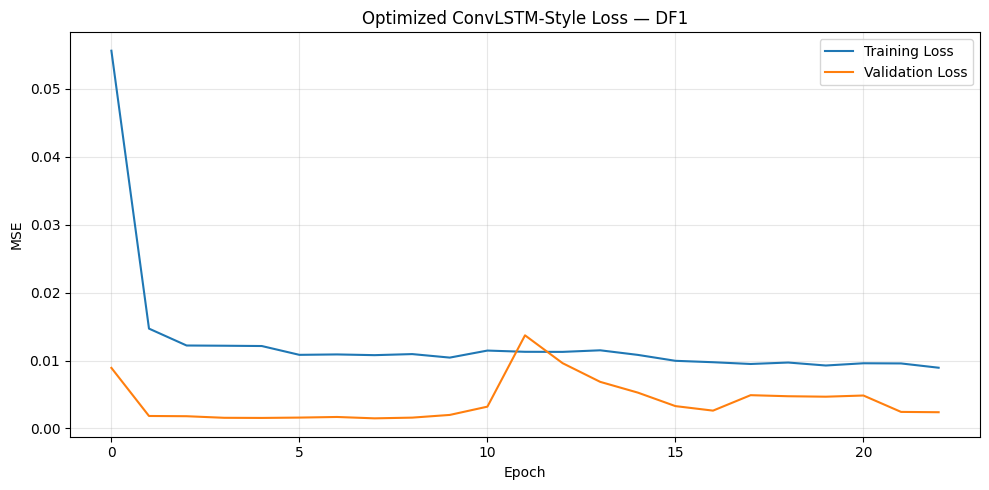



FINAL OPTIMIZED MODEL — DF2
Epoch 1/150
98/98 ━━━━━━━━━━━━━━━━━━━━ 12s 69ms/step - loss: 0.0193 - mae: 0.0970 - val_loss: 0.0023 - val_mae: 0.0375
Epoch 2/150
98/98 ━━━━━━━━━━━━━━━━━━━━ 6s 61ms/step - loss: 0.0081 - mae: 0.0672 - val_loss: 0.0021 - val_mae: 0.0351
Epoch 3/150
98/98 ━━━━━━━━━━━━━━━━━━━━ 6s 64ms/step - loss: 0.0072 - mae: 0.0634 - val_loss: 0.0027 - val_mae: 0.0429
Epoch 4/150
98/98 ━━━━━━━━━━━━━━━━━━━━ 6s 63ms/step - loss: 0.0066 - mae: 0.0605 - val_loss: 0.0018 - val_mae: 0.0308
Epoch 5/150
98/98 ━━━━━━━━━━━━━━━━━━━━ 6s 61ms/step - loss: 0.0064 - mae: 0.0589 - val_loss: 0.0025 - val_mae: 0.0404
Epoch 6/150
98/98 ━━━━━━━━━━━━━━━━━━━━ 6s 61ms/step - loss: 0.0061 - mae: 0.0571 - val_loss: 0.0025 - val_mae: 0.0402
Epoch 7/150
98/98 ━━━━━━━━━━━━━━━━━━━━ 6s 62ms/step - loss: 0.0057 - mae: 0.0543 - val_loss: 0.0033 - val_mae: 0.0479
Epoch 8/150
98/98 ━━━━━━━━━━━━━━━━━━━━ 6s 61ms/step - loss: 0.0055 - mae: 0.0534 - val_loss: 0.0038 - val_mae: 0.0523
Epoch 9/150
98/98 ━━━━━━━

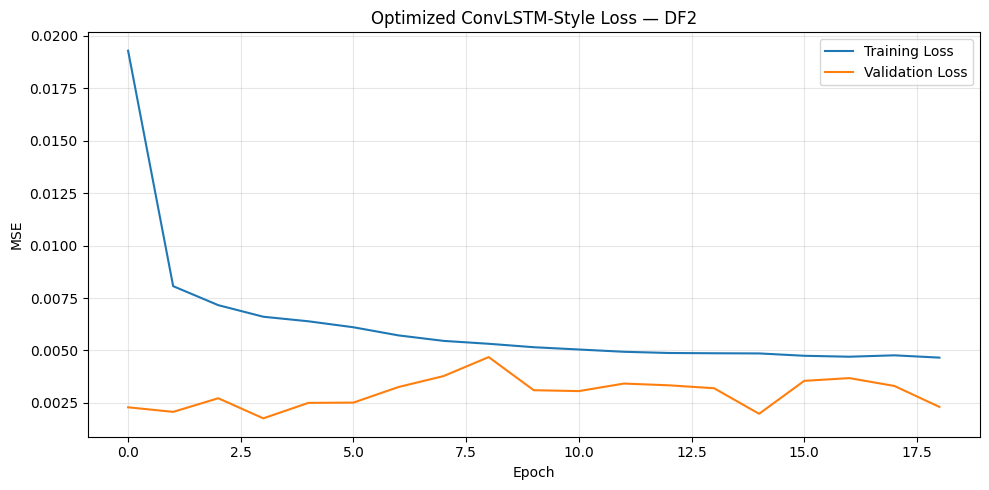



FINAL OPTIMIZED MODEL — DF3
Epoch 1/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 8s 228ms/step - loss: 0.3883 - mae: 0.5763 - val_loss: 0.3415 - val_mae: 0.5665
Epoch 2/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 102ms/step - loss: 0.2170 - mae: 0.4110 - val_loss: 0.2497 - val_mae: 0.4894
Epoch 3/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 109ms/step - loss: 0.1160 - mae: 0.2825 - val_loss: 0.1672 - val_mae: 0.4055
Epoch 4/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 112ms/step - loss: 0.0651 - mae: 0.2087 - val_loss: 0.0984 - val_mae: 0.3125
Epoch 5/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 102ms/step - loss: 0.0491 - mae: 0.1802 - val_loss: 0.0597 - val_mae: 0.2427
Epoch 6/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 104ms/step - loss: 0.0501 - mae: 0.1781 - val_loss: 0.0522 - val_mae: 0.2269
Epoch 7/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 100ms/step - loss: 0.0508 - mae: 0.1774 - val_loss: 0.0555 - val_mae: 0.2341
Epoch 8/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 98ms/step - loss: 0.0479 - mae: 0.1709 - val_loss: 0.0550 - val_mae: 0.2331
Epoch 9/150
6/6 ━━━━━━━━━━━━━━━━━━━

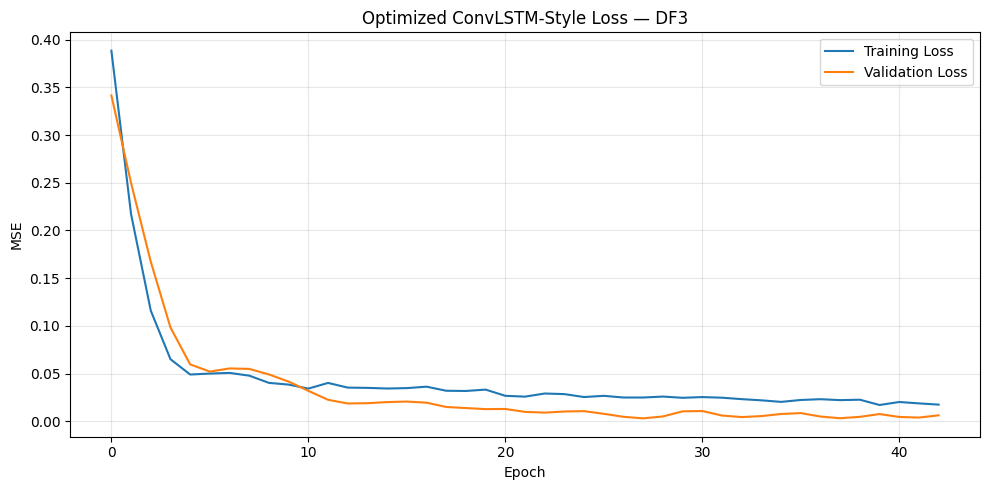



FINAL OPTIMIZED MODEL — DF4
Epoch 1/150
43/43 ━━━━━━━━━━━━━━━━━━━━ 9s 73ms/step - loss: 0.0625 - mae: 0.1805 - val_loss: 0.0249 - val_mae: 0.1316
Epoch 2/150
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 54ms/step - loss: 0.0178 - mae: 0.1044 - val_loss: 0.0145 - val_mae: 0.0937
Epoch 3/150
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 55ms/step - loss: 0.0172 - mae: 0.0997 - val_loss: 0.0112 - val_mae: 0.0782
Epoch 4/150
43/43 ━━━━━━━━━━━━━━━━━━━━ 3s 59ms/step - loss: 0.0150 - mae: 0.0923 - val_loss: 0.0097 - val_mae: 0.0705
Epoch 5/150
43/43 ━━━━━━━━━━━━━━━━━━━━ 3s 59ms/step - loss: 0.0131 - mae: 0.0867 - val_loss: 0.0088 - val_mae: 0.0639
Epoch 6/150
43/43 ━━━━━━━━━━━━━━━━━━━━ 3s 61ms/step - loss: 0.0135 - mae: 0.0899 - val_loss: 0.0098 - val_mae: 0.0710
Epoch 7/150
43/43 ━━━━━━━━━━━━━━━━━━━━ 3s 58ms/step - loss: 0.0144 - mae: 0.0903 - val_loss: 0.0090 - val_mae: 0.0658
Epoch 8/150
43/43 ━━━━━━━━━━━━━━━━━━━━ 3s 59ms/step - loss: 0.0113 - mae: 0.0812 - val_loss: 0.0093 - val_mae: 0.0676
Epoch 9/150
43/43 ━━━━━━━━

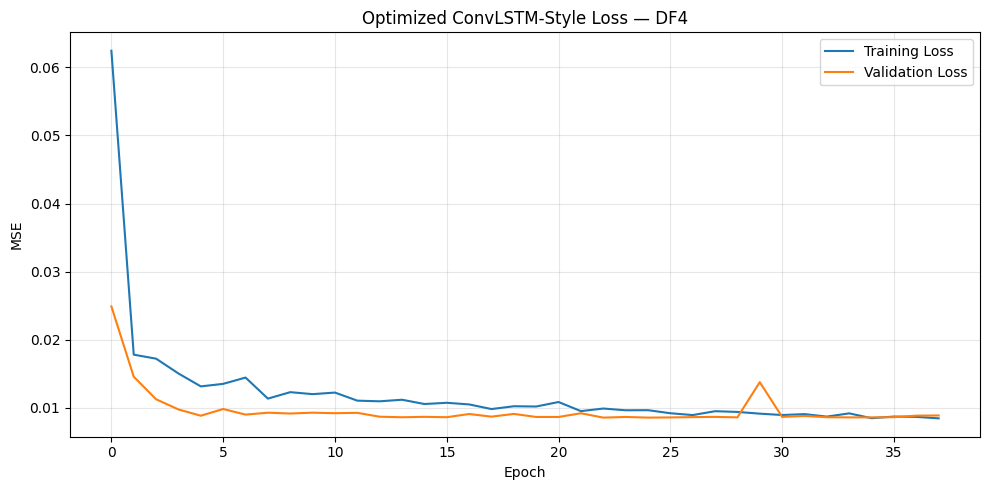



FINAL OPTIMIZED ConvLSTM RESULTS


,Regime,High_MAE,High_RMSE,High_R2,High_MAPE,Low_MAE,Low_RMSE,Low_R2,Low_MAPE,Best_Validation_MAPE,Best_Epochs
0,DF1,29.693109,35.997856,0.985629,0.505322,34.211745,43.005065,0.977674,0.589533,0.595021,23
1,DF2,50.862230,78.197017,0.977489,0.452177,60.494880,82.715617,0.975864,0.546692,0.363819,19
2,DF3,149.727150,173.364666,0.821109,0.846800,113.830819,148.747932,0.882050,0.654174,0.325043,43
3,DF4,83.395573,120.104197,0.930677,0.331833,105.248593,129.205420,0.926201,0.421714,0.490131,38



Saved:
ConvLSTM_OPTUNA_FINAL_RESULTS.xlsx


In [10]:
# Research review: Tuning/regime variants can differ from final.1. Record exact years, validation metric, trial budget and whether validation targets or test data influenced final fitting. The independent baseline is not a rerun of this model.
# ============================================================
# ConvLSTM-STYLE HYPERPARAMETER OPTIMIZATION
# OPTUNA + TPE BAYESIAN OPTIMIZATION
#
# NIFTY 50 REGIME-WISE FORECASTING
#
# Target:
#   Next-Day High
#   Next-Day Low
#
# Protocol:
#   70% TRAIN
#   15% VALIDATION
#   15% TEST
#
# IMPORTANT:
#   TEST SET IS NEVER USED DURING OPTIMIZATION
#
# Optimization:
#   Optuna TPE Sampler
#   30 trials / regime
# ============================================================


# ============================================================
# 1. IMPORTS
# ============================================================

import os
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
import optuna

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    LSTM,
    Dropout,
    Dense,
    BatchNormalization,
    Activation
)

from tensorflow.keras.optimizers import Adam

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")


# ============================================================
# 2. REPRODUCIBILITY
# ============================================================

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)

tf.random.set_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except:
    pass


# ============================================================
# 3. OPTUNA SETTINGS
# ============================================================

N_TRIALS = 30

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)


# ============================================================
# 4. FIXED PARAMETERS
# ============================================================

LOOKBACK = 25

EPOCHS = 150

EARLY_STOPPING_PATIENCE = 15

LR_PATIENCE = 7

LR_FACTOR = 0.5


# ============================================================
# 5. FEATURES
# ============================================================

FEATURES = [
    "Open",
    "High",
    "Low",
    "Close"
]


# ============================================================
# 6. CHECK DATA
# ============================================================

required_columns = FEATURES + ["Date"]

missing_columns = [
    col
    for col in required_columns
    if col not in df.columns
]

if missing_columns:

    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )


# ============================================================
# 7. PREPARE DATA
# ============================================================

data = df.copy()

data["Date"] = pd.to_datetime(
    data["Date"]
)

data = (
    data
    .sort_values("Date")
    .reset_index(drop=True)
)

for col in FEATURES:

    data[col] = pd.to_numeric(
        data[col],
        errors="coerce"
    )

data = data.dropna(
    subset=FEATURES
).reset_index(drop=True)


# ============================================================
# 8. TARGET CREATION
# ============================================================

data["Target_High_Ratio"] = (
    data["High"].shift(-1)
    / data["Close"]
)

data["Target_Low_Ratio"] = (
    data["Low"].shift(-1)
    / data["Close"]
)

data = data.dropna(
    subset=[
        "Target_High_Ratio",
        "Target_Low_Ratio"
    ]
).reset_index(drop=True)


# ============================================================
# 9. MARKET REGIMES
# ============================================================

REGIMES = {

    "DF1": (
        "2007-01-01",
        "2010-12-31"
    ),

    "DF2": (
        "2011-01-01",
        "2019-12-31"
    ),

    "DF3": (
        "2020-01-01",
        "2021-12-31"
    ),

    "DF4": (
        "2022-01-01",
        None
    )
}


# ============================================================
# 10. SEQUENCE FUNCTIONS
# ============================================================

def create_train_sequences(
    X,
    y,
    lookback
):

    X_seq = []
    y_seq = []

    for i in range(
        lookback,
        len(X)
    ):

        X_seq.append(
            X[
                i-lookback:i
            ]
        )

        y_seq.append(
            y[i]
        )

    return (
        np.array(X_seq),
        np.array(y_seq)
    )


def create_partition_sequences(
    history_X,
    partition_X,
    partition_y,
    lookback
):

    X_combined = np.concatenate(
        [
            history_X,
            partition_X
        ],
        axis=0
    )

    X_seq = []
    y_seq = []

    for i in range(
        len(partition_y)
    ):

        X_seq.append(
            X_combined[
                i:i+lookback
            ]
        )

        y_seq.append(
            partition_y[i]
        )

    return (
        np.array(X_seq),
        np.array(y_seq)
    )


# ============================================================
# 11. PREPARE ONE REGIME
# ============================================================

def prepare_regime(
    regime_name
):

    start_date, end_date = (
        REGIMES[regime_name]
    )

    regime_data = data[
        data["Date"] >=
        pd.Timestamp(start_date)
    ].copy()

    if end_date is not None:

        regime_data = regime_data[
            regime_data["Date"] <=
            pd.Timestamp(end_date)
        ]

    regime_data = (
        regime_data
        .sort_values("Date")
        .reset_index(drop=True)
    )


    X_raw = regime_data[
        FEATURES
    ].values

    y_raw = regime_data[
        [
            "Target_High_Ratio",
            "Target_Low_Ratio"
        ]
    ].values


    # --------------------------------------------------------
    # Chronological 70 / 15 / 15
    # --------------------------------------------------------

    n = len(regime_data)

    train_end = int(
        n * 0.70
    )

    val_end = int(
        n * 0.85
    )


    X_train_raw = X_raw[
        :train_end
    ]

    X_val_raw = X_raw[
        train_end:val_end
    ]

    X_test_raw = X_raw[
        val_end:
    ]


    y_train = y_raw[
        :train_end
    ]

    y_val = y_raw[
        train_end:val_end
    ]

    y_test = y_raw[
        val_end:
    ]


    # --------------------------------------------------------
    # INPUT SCALER — TRAIN ONLY
    # --------------------------------------------------------

    X_scaler = MinMaxScaler()

    X_scaler.fit(
        X_train_raw
    )

    X_train_scaled = (
        X_scaler.transform(
            X_train_raw
        )
    )

    X_val_scaled = (
        X_scaler.transform(
            X_val_raw
        )
    )

    X_test_scaled = (
        X_scaler.transform(
            X_test_raw
        )
    )


    # --------------------------------------------------------
    # TARGET SCALER — TRAIN ONLY
    # --------------------------------------------------------

    y_scaler = MinMaxScaler()

    y_scaler.fit(
        y_train
    )

    y_train_scaled = (
        y_scaler.transform(
            y_train
        )
    )

    y_val_scaled = (
        y_scaler.transform(
            y_val
        )
    )

    y_test_scaled = (
        y_scaler.transform(
            y_test
        )
    )


    # --------------------------------------------------------
    # TRAIN SEQUENCES
    # --------------------------------------------------------

    X_train, y_train_seq = (
        create_train_sequences(
            X_train_scaled,
            y_train_scaled,
            LOOKBACK
        )
    )


    # --------------------------------------------------------
    # VALIDATION SEQUENCES
    # --------------------------------------------------------

    X_val, y_val_seq = (
        create_partition_sequences(
            X_train_scaled[-LOOKBACK:],
            X_val_scaled,
            y_val_scaled,
            LOOKBACK
        )
    )


    # --------------------------------------------------------
    # TEST SEQUENCES
    # --------------------------------------------------------

    X_test, y_test_seq = (
        create_partition_sequences(
            X_val_scaled[-LOOKBACK:],
            X_test_scaled,
            y_test_scaled,
            LOOKBACK
        )
    )


    return {
        "regime_data": regime_data,

        "X_train": X_train,
        "y_train": y_train_seq,

        "X_val": X_val,
        "y_val": y_val_seq,

        "X_test": X_test,
        "y_test": y_test_seq,

        "X_test_raw": X_test_raw,

        "y_scaler": y_scaler,

        "train_end": train_end,
        "val_end": val_end
    }


# ============================================================
# 12. HYPERPARAMETERIZED MODEL
# ============================================================

def build_model(
    input_shape,
    params
):

    inputs = Input(
        shape=input_shape
    )


    # ========================================================
    # CNN BLOCK
    # ========================================================

    x = Conv1D(
        filters=params["conv_filters"],
        kernel_size=params["kernel_size"],
        padding="same"
    )(inputs)

    x = BatchNormalization()(x)

    x = Activation(
        "relu"
    )(x)

    x = Dropout(
        params["dropout"]
    )(x)


    # ========================================================
    # SECOND CNN
    # ========================================================

    x = Conv1D(
        filters=params["conv_filters"],
        kernel_size=params["kernel_size"],
        padding="same"
    )(x)

    x = BatchNormalization()(x)

    x = Activation(
        "relu"
    )(x)


    # ========================================================
    # LSTM 1
    # ========================================================

    x = LSTM(
        params["lstm_units_1"],
        return_sequences=True
    )(x)

    x = Dropout(
        params["dropout"]
    )(x)


    # ========================================================
    # LSTM 2
    # ========================================================

    x = LSTM(
        params["lstm_units_2"],
        return_sequences=False
    )(x)

    x = Dropout(
        params["dropout"]
    )(x)


    # ========================================================
    # DENSE
    # ========================================================

    x = Dense(
        params["dense_units"],
        activation="relu"
    )(x)


    # ========================================================
    # OUTPUT
    # ========================================================

    outputs = Dense(
        2,
        activation="linear"
    )(x)


    model = Model(
        inputs=inputs,
        outputs=outputs
    )


    optimizer = Adam(
        learning_rate=params["learning_rate"]
    )


    model.compile(
        optimizer=optimizer,
        loss="mse",
        metrics=["mae"]
    )


    return model


# ============================================================
# 13. VALIDATION METRIC
# ============================================================
#
# We optimize VALIDATION MAPE on reconstructed prices.
#
# This is preferable to optimizing the test score because
# the test set must remain untouched.
#
# ============================================================

def validation_mape(
    model,
    X_val,
    y_val_scaled,
    y_scaler,
    X_val_raw
):

    pred_scaled = model.predict(
        X_val,
        verbose=0
    )


    # Inverse target scaling
    pred_ratio = (
        y_scaler.inverse_transform(
            pred_scaled
        )
    )

    true_ratio = (
        y_scaler.inverse_transform(
            y_val_scaled
        )
    )


    # Current Close
    close_index = FEATURES.index(
        "Close"
    )

    current_close = X_val_raw[
        :,
        close_index
    ]


    # Reconstruct absolute prices
    actual_high = (
        true_ratio[:, 0]
        * current_close
    )

    predicted_high = (
        pred_ratio[:, 0]
        * current_close
    )

    actual_low = (
        true_ratio[:, 1]
        * current_close
    )

    predicted_low = (
        pred_ratio[:, 1]
        * current_close
    )


    # MAPE High
    high_mape = np.mean(
        np.abs(
            (
                actual_high -
                predicted_high
            )
            /
            np.maximum(
                np.abs(actual_high),
                1e-8
            )
        )
    ) * 100


    # MAPE Low
    low_mape = np.mean(
        np.abs(
            (
                actual_low -
                predicted_low
            )
            /
            np.maximum(
                np.abs(actual_low),
                1e-8
            )
        )
    ) * 100


    # Equal weighting of High and Low
    combined_mape = (
        high_mape +
        low_mape
    ) / 2


    return combined_mape


# ============================================================
# 14. OPTUNA OBJECTIVE
# ============================================================

def create_objective(
    regime_data_dict
):

    def objective(trial):

        # ----------------------------------------------------
        # SEARCH SPACE
        # ----------------------------------------------------

        params = {

            # CNN
            "conv_filters":
                trial.suggest_categorical(
                    "conv_filters",
                    [32, 64, 128]
                ),

            "kernel_size":
                trial.suggest_categorical(
                    "kernel_size",
                    [2, 3, 5]
                ),


            # LSTM
            "lstm_units_1":
                trial.suggest_categorical(
                    "lstm_units_1",
                    [32, 64, 128]
                ),

            "lstm_units_2":
                trial.suggest_categorical(
                    "lstm_units_2",
                    [16, 32, 64]
                ),


            # Regularization
            "dropout":
                trial.suggest_float(
                    "dropout",
                    0.10,
                    0.40,
                    step=0.05
                ),


            # Dense
            "dense_units":
                trial.suggest_categorical(
                    "dense_units",
                    [8, 16, 32]
                ),


            # Learning rate
            "learning_rate":
                trial.suggest_float(
                    "learning_rate",
                    1e-4,
                    3e-3,
                    log=True
                ),


            # Batch size
            "batch_size":
                trial.suggest_categorical(
                    "batch_size",
                    [16, 32, 64]
                )
        }


        # ----------------------------------------------------
        # GET DATA
        # ----------------------------------------------------

        X_train = regime_data_dict[
            "X_train"
        ]

        y_train = regime_data_dict[
            "y_train"
        ]

        X_val = regime_data_dict[
            "X_val"
        ]

        y_val = regime_data_dict[
            "y_val"
        ]

        X_val_raw = regime_data_dict[
            "X_val_raw"
        ]

        y_scaler = regime_data_dict[
            "y_scaler"
        ]


        # ----------------------------------------------------
        # BUILD MODEL
        # ----------------------------------------------------

        tf.keras.backend.clear_session()

        model = build_model(
            input_shape=(
                LOOKBACK,
                len(FEATURES)
            ),
            params=params
        )


        # ----------------------------------------------------
        # CALLBACKS
        # ----------------------------------------------------

        early_stopping = EarlyStopping(
            monitor="val_loss",
            patience=12,
            restore_best_weights=True,
            verbose=0
        )

        reduce_lr = ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=5,
            min_lr=1e-6,
            verbose=0
        )


        # ----------------------------------------------------
        # TRAIN
        # ----------------------------------------------------

        model.fit(

            X_train,
            y_train,

            validation_data=(
                X_val,
                y_val
            ),

            epochs=EPOCHS,

            batch_size=params[
                "batch_size"
            ],

            shuffle=False,

            callbacks=[
                early_stopping,
                reduce_lr
            ],

            verbose=0
        )


        # ----------------------------------------------------
        # VALIDATION SCORE
        # ----------------------------------------------------

        score = validation_mape(

            model,

            X_val,

            y_val,

            y_scaler,

            X_val_raw
        )


        # ----------------------------------------------------
        # REPORT SCORE TO OPTUNA
        # ----------------------------------------------------

        trial.set_user_attr(
            "validation_mape",
            float(score)
        )

        trial.set_user_attr(
            "epochs_used",
            len(
                model.history.history[
                    "loss"
                ]
            )
        )


        # ----------------------------------------------------
        # CLEAN MEMORY
        # ----------------------------------------------------

        del model

        tf.keras.backend.clear_session()


        return score


    return objective


# ============================================================
# 15. RUN OPTUNA FOR EACH REGIME
# ============================================================

best_params_all = {}

optimization_results = {}

prepared_data = {}


for regime_name in REGIMES.keys():

    print("\n")
    print("=" * 90)
    print(
        f"OPTUNA TUNING — {regime_name}"
    )
    print("=" * 90)


    # --------------------------------------------------------
    # Prepare regime
    # --------------------------------------------------------

    regime_dict = prepare_regime(
        regime_name
    )


    # --------------------------------------------------------
    # IMPORTANT:
    # Keep raw validation data separately
    # --------------------------------------------------------

    start_date, end_date = (
        REGIMES[regime_name]
    )

    regime_data = data[
        data["Date"] >=
        pd.Timestamp(start_date)
    ].copy()

    if end_date is not None:

        regime_data = regime_data[
            regime_data["Date"] <=
            pd.Timestamp(end_date)
        ]

    regime_data = (
        regime_data
        .sort_values("Date")
        .reset_index(drop=True)
    )


    n = len(regime_data)

    train_end = int(
        n * 0.70
    )

    val_end = int(
        n * 0.85
    )


    X_raw = regime_data[
        FEATURES
    ].values


    regime_dict["X_val_raw"] = X_raw[
        train_end:val_end
    ]


    prepared_data[
        regime_name
    ] = regime_dict


    # --------------------------------------------------------
    # TPE SAMPLER
    # --------------------------------------------------------

    sampler = optuna.samplers.TPESampler(
        seed=SEED,
        multivariate=True
    )


    # --------------------------------------------------------
    # STUDY
    # --------------------------------------------------------

    study = optuna.create_study(

        direction="minimize",

        sampler=sampler,

        study_name=
            f"ConvLSTM_{regime_name}"
    )


    # --------------------------------------------------------
    # OPTIMIZATION
    # --------------------------------------------------------

    study.optimize(

        create_objective(
            regime_dict
        ),

        n_trials=N_TRIALS,

        show_progress_bar=True
    )


    # --------------------------------------------------------
    # BEST PARAMETERS
    # --------------------------------------------------------

    best_params = (
        study.best_params
    )

    best_score = (
        study.best_value
    )


    best_params_all[
        regime_name
    ] = best_params


    optimization_results[
        regime_name
    ] = study


    # --------------------------------------------------------
    # PRINT
    # --------------------------------------------------------

    print("\n")
    print(
        f"BEST {regime_name} VALIDATION MAPE:"
    )

    print(
        f"{best_score:.6f}%"
    )


    print("\nBEST PARAMETERS:")

    for key, value in (
        best_params.items()
    ):

        print(
            f"{key}: {value}"
        )


# ============================================================
# 16. DISPLAY ALL BEST PARAMETERS
# ============================================================

print("\n")
print("=" * 100)
print("BEST HYPERPARAMETERS BY MARKET REGIME")
print("=" * 100)


for regime_name, params in (
    best_params_all.items()
):

    print("\n")
    print(
        f"{regime_name}"
    )

    print("-" * 50)

    for key, value in (
        params.items()
    ):

        print(
            f"{key:<20}: {value}"
        )


# ============================================================
# 17. SAVE OPTUNA RESULTS
# ============================================================

all_trials = []

for regime_name, study in (
    optimization_results.items()
):

    trials_df = (
        study.trials_dataframe()
    )

    trials_df[
        "Regime"
    ] = regime_name

    all_trials.append(
        trials_df
    )


all_trials_df = pd.concat(
    all_trials,
    ignore_index=True
)


all_trials_df.to_csv(
    "ConvLSTM_Optuna_all_trials.csv",
    index=False
)


print(
    "\nAll Optuna trials saved:"
    " ConvLSTM_Optuna_all_trials.csv"
)


# ============================================================
# 18. SAVE BEST PARAMETERS
# ============================================================

best_params_rows = []

for regime_name, params in (
    best_params_all.items()
):

    row = {
        "Regime":
            regime_name
    }

    row.update(
        params
    )

    row[
        "Best_Validation_MAPE"
    ] = (
        optimization_results[
            regime_name
        ].best_value
    )

    best_params_rows.append(
        row
    )


best_params_df = pd.DataFrame(
    best_params_rows
)


best_params_df.to_csv(
    "ConvLSTM_best_hyperparameters.csv",
    index=False
)


display(
    best_params_df.round(6)
)


# ============================================================
# 19. FINAL MODEL TRAINING
# ============================================================
#
# IMPORTANT:
#
# The TEST SET is used ONLY NOW.
#
# We take the best hyperparameters from Optuna,
# retrain on TRAIN + VALIDATION,
# and finally evaluate on TEST.
#
# ============================================================


final_results = []

final_predictions = {}

final_models = {}

final_histories = {}


for regime_name in REGIMES.keys():

    print("\n")
    print("=" * 90)
    print(
        f"FINAL OPTIMIZED MODEL — {regime_name}"
    )
    print("=" * 90)


    regime_dict = prepared_data[
        regime_name
    ]


    best_params = best_params_all[
        regime_name
    ]


    regime_data = regime_dict[
        "regime_data"
    ]


    # --------------------------------------------------------
    # Get original arrays
    # --------------------------------------------------------

    X_raw = regime_data[
        FEATURES
    ].values

    y_raw = regime_data[
        [
            "Target_High_Ratio",
            "Target_Low_Ratio"
        ]
    ].values


    n = len(regime_data)

    train_end = int(
        n * 0.70
    )

    val_end = int(
        n * 0.85
    )


    # --------------------------------------------------------
    # TRAIN + VALIDATION = DEVELOPMENT DATA
    # --------------------------------------------------------

    X_dev_raw = X_raw[
        :val_end
    ]

    y_dev = y_raw[
        :val_end
    ]


    X_test_raw = X_raw[
        val_end:
    ]

    y_test = y_raw[
        val_end:
    ]


    # --------------------------------------------------------
    # FIT SCALERS ON DEVELOPMENT DATA
    # --------------------------------------------------------
    #
    # This is appropriate AFTER hyperparameter selection:
    # validation has already served its purpose.
    #
    # --------------------------------------------------------

    X_scaler_final = MinMaxScaler()

    X_scaler_final.fit(
        X_dev_raw
    )


    X_dev_scaled = (
        X_scaler_final.transform(
            X_dev_raw
        )
    )

    X_test_scaled = (
        X_scaler_final.transform(
            X_test_raw
        )
    )


    # --------------------------------------------------------
    # TARGET SCALER
    # --------------------------------------------------------

    y_scaler_final = MinMaxScaler()

    y_scaler_final.fit(
        y_dev
    )


    y_dev_scaled = (
        y_scaler_final.transform(
            y_dev
        )
    )

    y_test_scaled = (
        y_scaler_final.transform(
            y_test
        )
    )


    # --------------------------------------------------------
    # DEVELOPMENT SEQUENCES
    # --------------------------------------------------------

    X_dev, y_dev_seq = (
        create_train_sequences(
            X_dev_scaled,
            y_dev_scaled,
            LOOKBACK
        )
    )


    # --------------------------------------------------------
    # TEST SEQUENCES
    # --------------------------------------------------------

    X_test, y_test_seq = (
        create_partition_sequences(
            X_dev_scaled[-LOOKBACK:],
            X_test_scaled,
            y_test_scaled,
            LOOKBACK
        )
    )


    # --------------------------------------------------------
    # BUILD BEST MODEL
    # --------------------------------------------------------

    tf.keras.backend.clear_session()

    model = build_model(

        input_shape=(
            LOOKBACK,
            len(FEATURES)
        ),

        params=best_params
    )


    # --------------------------------------------------------
    # FINAL CALLBACKS
    # --------------------------------------------------------

    early_stopping = EarlyStopping(

        monitor="val_loss",

        patience=15,

        restore_best_weights=True,

        verbose=1
    )


    # --------------------------------------------------------
    # FINAL TRAINING
    # --------------------------------------------------------
    #
    # We no longer have an independent validation set here.
    # Therefore we use validation_split only from the
    # DEVELOPMENT data for early stopping.
    #
    # shuffle=False preserves chronology.
    #
    # --------------------------------------------------------

    history = model.fit(

        X_dev,

        y_dev_seq,

        validation_split=0.15,

        epochs=EPOCHS,

        batch_size=best_params[
            "batch_size"
        ],

        shuffle=False,

        callbacks=[
            early_stopping
        ],

        verbose=1
    )


    # ========================================================
    # FINAL TEST PREDICTION
    # ========================================================

    y_pred_scaled = model.predict(
        X_test,
        verbose=0
    )


    y_pred_ratio = (
        y_scaler_final.inverse_transform(
            y_pred_scaled
        )
    )

    y_test_ratio = (
        y_scaler_final.inverse_transform(
            y_test_seq
        )
    )


    # ========================================================
    # RECONSTRUCT PRICE
    # ========================================================

    close_index = FEATURES.index(
        "Close"
    )

    current_close = X_test_raw[
        :,
        close_index
    ]


    actual_high = (
        y_test_ratio[:, 0]
        * current_close
    )

    predicted_high = (
        y_pred_ratio[:, 0]
        * current_close
    )

    actual_low = (
        y_test_ratio[:, 1]
        * current_close
    )

    predicted_low = (
        y_pred_ratio[:, 1]
        * current_close
    )


    # ========================================================
    # METRICS
    # ========================================================

    def get_metrics(
        actual,
        predicted
    ):

        mae = mean_absolute_error(
            actual,
            predicted
        )

        rmse = np.sqrt(
            mean_squared_error(
                actual,
                predicted
            )
        )

        r2 = r2_score(
            actual,
            predicted
        )

        mape = np.mean(
            np.abs(
                (
                    actual -
                    predicted
                )
                /
                np.maximum(
                    np.abs(actual),
                    1e-8
                )
            )
        ) * 100

        return (
            mae,
            rmse,
            r2,
            mape
        )


    high_metrics = get_metrics(
        actual_high,
        predicted_high
    )

    low_metrics = get_metrics(
        actual_low,
        predicted_low
    )


    # ========================================================
    # PRINT
    # ========================================================

    print("\n")
    print(
        f"FINAL OPTIMIZED RESULTS — {regime_name}"
    )

    print("\nHIGH")

    print(
        f"MAE  : {high_metrics[0]:.6f}"
    )

    print(
        f"RMSE : {high_metrics[1]:.6f}"
    )

    print(
        f"R²   : {high_metrics[2]:.6f}"
    )

    print(
        f"MAPE : {high_metrics[3]:.6f}%"
    )


    print("\nLOW")

    print(
        f"MAE  : {low_metrics[0]:.6f}"
    )

    print(
        f"RMSE : {low_metrics[1]:.6f}"
    )

    print(
        f"R²   : {low_metrics[2]:.6f}"
    )

    print(
        f"MAPE : {low_metrics[3]:.6f}%"
    )


    # ========================================================
    # STORE RESULTS
    # ========================================================

    final_results.append({

        "Regime":
            regime_name,

        "High_MAE":
            high_metrics[0],

        "High_RMSE":
            high_metrics[1],

        "High_R2":
            high_metrics[2],

        "High_MAPE":
            high_metrics[3],

        "Low_MAE":
            low_metrics[0],

        "Low_RMSE":
            low_metrics[1],

        "Low_R2":
            low_metrics[2],

        "Low_MAPE":
            low_metrics[3],

        "Best_Validation_MAPE":
            optimization_results[
                regime_name
            ].best_value,

        "Best_Epochs":
            len(
                history.history[
                    "loss"
                ]
            )

    })


    # ========================================================
    # PREDICTION TABLE
    # ========================================================

    test_dates = regime_data[
        "Date"
    ].iloc[
        val_end:
    ].values


    prediction_df = pd.DataFrame({

        "Date":
            test_dates,

        "Current_Close":
            current_close,

        "Actual_High":
            actual_high,

        "Predicted_High":
            predicted_high,

        "Actual_Low":
            actual_low,

        "Predicted_Low":
            predicted_low

    })


    final_predictions[
        regime_name
    ] = prediction_df


    final_models[
        regime_name
    ] = model


    final_histories[
        regime_name
    ] = history.history


    # ========================================================
    # LOSS CURVE
    # ========================================================

    plt.figure(
        figsize=(10, 5)
    )

    plt.plot(
        history.history["loss"],
        label="Training Loss"
    )

    plt.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.title(
        f"Optimized ConvLSTM-Style Loss — {regime_name}"
    )

    plt.xlabel(
        "Epoch"
    )

    plt.ylabel(
        "MSE"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


# ============================================================
# 20. FINAL RESULTS TABLE
# ============================================================

final_results_df = pd.DataFrame(
    final_results
)


print("\n")
print("=" * 110)
print(
    "FINAL OPTIMIZED ConvLSTM RESULTS"
)
print("=" * 110)


display(
    final_results_df.round(6)
)


# ============================================================
# 21. SAVE FINAL RESULTS
# ============================================================

final_results_df.to_csv(
    "ConvLSTM_OPTIMIZED_FINAL_RESULTS.csv",
    index=False
)


# ============================================================
# 22. SAVE EVERYTHING TO EXCEL
# ============================================================

with pd.ExcelWriter(
    "ConvLSTM_OPTUNA_FINAL_RESULTS.xlsx",
    engine="openpyxl"
) as writer:

    final_results_df.to_excel(
        writer,
        sheet_name="Final Results",
        index=False
    )

    best_params_df.to_excel(
        writer,
        sheet_name="Best Parameters",
        index=False
    )

    all_trials_df.to_excel(
        writer,
        sheet_name="All Optuna Trials",
        index=False
    )

    for regime_name, prediction_df in (
        final_predictions.items()
    ):

        prediction_df.to_excel(
            writer,
            sheet_name=regime_name,
            index=False
        )


print(
    "\nSaved:"
)

print(
    "ConvLSTM_OPTUNA_FINAL_RESULTS.xlsx"
)